# SITE analysis: ERK signaling, cell state and death dynamics (OS17, lung)

**Paper:** *Spatially coordinated RTK-ERK signaling dynamics shape osteosarcoma single-cell drug response in the lung microenvironment. Rawan Makkawi, Carol Halsey, Vaibhav Murthy, Elise C. Manalo, Hugo Cros, Xin Yi, Jessie May Cartier, Matthew Chang, Mark Flory, Kelly Guptell, Amy Gross, Ryan D. Roberts, Jeremy Copperman, Alexander E. Davies. bioRxiv 2026.09.30.755770; doi: https://doi.org/10.64898/2026.09.30.755770 

This notebook contains the analysis code that accompanies the paper. It starts from segmented, tracked, feature-extracted 3-D live-cell imaging data (one `.h5` file per field of view, called a *model* below) and ends with a Markov model of cell state, ERK signaling and cell death under drug treatment.

## What the analysis does

Live imaging reports, for every cancer cell and frame, an ERK activity reporter (cytoplasm/nucleus ratio), a Fra-1 reporter, 3-D cell shape, the contact of each cell with cancer cells, primary lung cells and matrix, and manually validated death calls. The analysis asks how ERK activity, the cell's neighborhood (including proximity to dying cells) and morphology determine whether a cell dies or persists, and builds a kinetic model of that.

| # | Section | Main output |
|---|---|---|
| 1 | Setup | imports, output folder, run switches |
| 2 | Datasets, platemap and model loading | `modelSet`, `indgood_models`, `tmSet` |
| 3 | Cell trajectories | unique cell trajectories (`all_trajSet`) |
| 4 | Quality control: cell numbers | relative cell number vs. time, cell-number table |
| 5 | Single-cell features | morphology, motility, ERK/Fra-1, time, surface contacts |
| 6 | Initial vs. persistor cells | feature comparisons |
| 7 | Neighborhood-deaths (Nd) analysis | `Nd`, death-centered ERK correlation and a randomized null |
| 8 | ERK switching vs. neighborhood deaths | 8-state Markov model |
| 9 | Spatial clusters of ERK-high cells | cluster-size distributions |
| 10 | Trajectory embedding | autocorrelation, embedding `x`, transition pairs |
| 11 | Microstates, Markov state model and kinetic states | 150 microstates, 3 kinetic states (A, B, C) |
| 12 | Characterization of the kinetic states | occupancy, feature and death-time distributions |
| 13 | Death and ERK dynamics over time | death-rate and ERK time courses with bootstrap bands |
| 14 | Markov model with death and in-silico ERK inhibition | 24-state model, simulation, bootstrap rates |
| A | Appendix | 3-D tissue maps, 3-D export, track curation (optimal-transport cost), manual death validation |

## Requirements and data

* Python environment `celltraj_env` with the lab packages `trajectory`, `imageprep`, `utilities`, `features`, `model` (the `celltraj` package), plus NumPy, SciPy, scikit-image, scikit-learn, PyEMMA, UMAP, csaps, bayesian_bootstrap, pandas, seaborn and h5py. The appendix export cells also need `cmapfile`.
* Input data are the per-field-of-view `.h5` files listed through the platemap (Section 2). **Edit `modelNames`, `datapaths` and `treatment_file` in Section 2 to point to your copy of the data.**
* All figures and intermediate files are written to a folder named `date` (Section 2) next to the notebook.
* With `get_clusters=False` / `get_kstates=False` (the defaults), the microstates and kinetic states are read from `manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj`, so that folder must be next to the notebook.

## How to run

Run the sections in order. Sections 7-8 use a small 2-D (Nd, ERK) embedding; Section 10 then rebuilds the embedding (`x`, `x0set`, `x1set`, ...) from the full morphology feature matrix under the same variable names, so those sections should not be interleaved. Switches for slow or interactive steps: `get_clusters` (Section 11, k-means; `False` loads the manuscript microstates), `get_kstates` (Section 11, kinetic states; `False` loads the manuscript states) and `RUN_MANUAL_DEATH_VALIDATION` (Section 1, used in Appendix A.4; interactive, off by default).

The current platemap has a single treatment (Mcl1i, index 0) imaged on two days (imaging sets 0 and 1). Several figure and model cells are written for treatment 0 only (`tms=[0]`, `i_tm=0`, `indstm_show=[0]`); change those lists to analyze other treatments.

## Key parameters

| Parameter | Value | Where | Meaning |
|---|---|---|---|
| `lowcut`, `highcut`, `midcut` | 0.85, 1.15, 1.0 | Section 7 | ERK c/n ratio thresholds for "low", "high" and the on/off boundary |
| `ot_cut` | 4.0 | Appendix A.3 | optimal-transport cost above which a track is broken |
| `contact_radius` | 1.4 µm | Section 5 | boundary points closer than this to a surface count as in contact |
| `trajl` | 1 | Section 7/10 | trajectory segment length (frames) for the embeddings |
| `n_clusters` | 150 | Section 11 | number of microstates |
| `nstates_final` | 3 | Section 11 | number of kinetic states |
| `Ndlow`, `Ndhigh` (Nd = neighborhood deaths) | `Nd_clusters[0]`, `Nd_clusters[1]` (0 and 1 nearby deaths) | Section 14 | Nd levels of the 24-state model (the manuscript used `Nd_clusters[1]`, `Nd_clusters[3]`) |
| `death_boost` | 3.15 | Section 14 | hand-tuned scale factor on the empirical death probabilities |

## 1. Setup

Imports and run switches. The output folder (`date`) is set at the start of Section 2.

**Imports.** All imports are collected here. The `celltraj` modules (`trajectory`, `imageprep`, `utilities`, `features`, `model`) come from the authors' analysis package. The `np.float` / `np.int` lines are compatibility shims for older libraries running on a newer NumPy.

In [1]:
# Imports for the whole notebook.
# trajectory / imageprep / utilities / features / model are the celltraj analysis modules.
# The environment to use here is: celltraj_env
#%%capture
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sys
# celltraj analysis package
import trajectory
import imageprep as imprep
import utilities
import features
import model
import h5py
import pickle
import os
import subprocess
import time
#import bootstrap
# embedding and Markov-model tools
import umap
import pyemma.coordinates as coor
import scipy
import csaps
import skimage
from IPython.display import clear_output
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
# compatibility shims: np.float / np.int were removed from newer NumPy but are still used by older libraries
np.float=np.dtype(float)
np.int=int
import pandas as pd
import itertools
from itertools import chain
import sklearn
import json
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import bayesian_bootstrap
from scipy.stats import ttest_ind
import sklearn.cluster
import string
from matplotlib.colors import ListedColormap, BoundaryNorm
import seaborn as sns
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec
# plotting helpers used only in some figure cells
from adjustText import adjust_text
import cmap
from cmap import Colormap
import sklearn.manifold
import scipy.ndimage
import skimage.filters

Solver suite is petsc
{'python': '3.9.19 | packaged by conda-forge | (main, Mar 20 2024, 12:50:21) | [GCC 12.3.0]', 'fipy': '3.4.4', 'numpy': '1.26.4', 'pysparse': 'not installed', 'scipy': '1.13.0', 'matplotlib': '3.8.4', 'mpi4py': '3.1.6', 'petsc4py': '3.21.1', 'pyamgx': 'not installed', 'PyTrilinos': 'not installed', 'mayavi': '4.8.2.dev0', 'gmsh': 'not installed', 'solver': 'petsc'}


**Console symbols.** Green check / red cross strings used in the load-status messages below.

In [2]:
# Colored check mark / cross used in the status messages printed while loading models
green_check = "\033[92m\u2714\033[0m"
red_x = "\033[91m\u274C\033[0m"

In [3]:
# Run switches
RUN_MANUAL_DEATH_VALIDATION=False   # True: run the interactive death-call validation (Appendix A.4); interactive, needs only the .h5 files

## 2. Datasets, platemap and model loading

Defines the imaging sets and the platemap that maps each field of view to a treatment, finds the corresponding model files, loads them, and decides which models are usable (`indgood_models`). A model is *good* if it contains ERK features, tracking data, a boundary library, multipole shape features, and the feature counts agree.

**Output folder.** `date` names the folder that receives all figures and intermediate files (created next to the notebook). Several cells also load intermediates saved there, so set it to the run you want to reuse.

In [14]:
# Name of the output folder (created next to the notebook); all figures and intermediates are saved here
date = '30oct26'
#All files will be saved in a folder with this date. Note: This folder will be made in the folder from
#which the jupyter notebook was launched.
# create the folder if it does not exist yet
os.system(f'mkdir -p {date}') 

0

**Dataset definitions.** The two imaging sets (file-name prefixes, one per imaging day) and their data folders (here both sets are in the same folder). `datapaths_to_file_dict` maps prefix to imaging-set index 0/1, which is used everywhere as the "replicate".

In [5]:
# Make sure the model names are correct since these are what the file names have been called. If you want to rename
# the files, use script 'file_rename'
# File-name prefixes of the imaging sets (one per imaging day). The position in this list is the imaging-set (replicate) index.
modelNames = [f'20240629_OS17lungInh_RM',f'20240703_OS17lungInh_RM']

# Folder with the .h5 files of each imaging set, in the same order as modelNames
datapaths=['dataset','dataset']

# prefix -> imaging-set index (0, 1)
datapaths_to_file_dict = {model: i for i, model in enumerate(modelNames)}


**Treatment platemap.** Reads `Combined_platemaps.xlsx` (XY position, treatment, file) and builds `tmSet` (unique treatments, in order of appearance), `nf` (number of treatments) and `inds_tmSet` (treatment index per platemap row). Everything keyed by treatment depends on this ordering.

In [6]:
# Platemap: one row per XY position with its treatment and the file prefix it belongs to
treatment_file = 'dataset/Combined_platemaps.xlsx'  # Update with the actual file path
treatment_df = pd.read_excel(treatment_file, header=None)

# Set the column names
treatment_df.columns = [ 'XY Position', 'Treatment','File']

# unique treatments in order of first appearance; nf = number of treatments
tmSet = treatment_df['Treatment'].drop_duplicates().tolist()
nf=len(tmSet)

# treatment name -> treatment index
treatment_to_index = {treatment: index for index, treatment in enumerate(tmSet)}

# Map the 'Treatment' column in the DataFrame to the corresponding indices
inds_tmSet = treatment_df['Treatment'].map(treatment_to_index)
inds_tmSet=inds_tmSet.tolist()

print("tmSet (from treatment_df):", tmSet)
print("Mapped indices:", inds_tmSet)
print(treatment_to_index)

tmSet (from treatment_df): ['Mcl1i']
Mapped indices: [0, 0, 0]
{'Mcl1i': 0}


**Plot colors.** One color per treatment, indexed by treatment index.

In [7]:
# One plot color per treatment (cycled if there are more treatments than colors)
_colors=['blue','orangered','green','purple','gray','brown','teal','gold']
colorSet=[_colors[i%len(_colors)] for i in range(max(nf,1))]   # one color per treatment (treatment 0 is blue)

**Find the model files.** For each platemap row, globs `{file}_xy{N}_roi*.h5` and records, per found file (a "model" = one field of view/ROI): its path (`modelList`), imaging set (`inds_imagingSet_models`) and treatment (`inds_tmSet_models`). `nmodels` = number of files found.

In [8]:
# Find the .h5 file(s) of every platemap row and record each file's imaging set and treatment
modelList = []
inds_imagingSet = []
inds_imagingSet_models = []
inds_tmSet_models = []
indexedtreatment = []

# Iterate over the range of the number of rows in treatment_df
for iwell in range(len(treatment_df)):
    # platemap XY positions are 1-based, file names are 0-based
    ixy = treatment_df.iloc[iwell]['XY Position'] - 1  # Use .iloc for row access by position
    modelname = treatment_df.iloc[iwell]['File']
    idatapath = datapaths_to_file_dict[modelname]
    # one XY position can have several ROIs, i.e. several model files
    mlist = imprep.list_images(f'{datapaths[idatapath]}/{modelname}_xy{ixy}_roi*.h5')

    for mstring in mlist:
        modelList.append(mstring)
        inds_imagingSet_models.append(idatapath)
        inds_tmSet_models.append(inds_tmSet[iwell])
        indexedtreatment.append(tmSet[inds_tmSet[iwell]])
        print(f'{green_check} found model {mstring} cond: {tmSet[inds_tmSet[iwell]]}')

# Convert lists to NumPy arrays
inds_imagingSet_models = np.array(inds_imagingSet_models)

inds_tmSet_models = np.array(inds_tmSet_models)
nmodels = len(modelList)
print(f'{nmodels} models found')

✔ found model dataset/20240629_OS17lungInh_RM_xy8_roi0.h5 cond: Mcl1i
✔ found model dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 cond: Mcl1i
✔ found model dataset/20240703_OS17lungInh_RM_xy9_roi0.h5 cond: Mcl1i
3 models found


**Load models and decide which are "good".** Loads each h5 into a `Trajectory`, resolves channel indices by name (cyto mask, DAPI, YFP=ERK reporter, CFP=Fra-1), and keeps a model in `indgood_models` only if it has ERK features, tracking, a boundary library and multipole (`mm_`) features whose cell counts all agree. Failures are printed and skipped, so scan the output for red X's. Produces `modelSet`, `indgood_models`, and the channel-index variables (and `mskchannel`) used by later cells.

In [9]:
# Load every model file and keep only the 'good' ones: all required features present, with matching cell counts
#%%capture
nmodels=len(modelList)
modelSet=[None]*nmodels
indgood_models=np.array([]).astype(int)
for i in range(nmodels): #now go back through and try to load data
    try:
        # load the cell data stored under /cell_data_m0/
        modelSet[i]=trajectory.Trajectory(h5filename=modelList[i])
        sctm=modelSet[i]
        status=modelSet[i].load_from_h5('/cell_data_m0/')
        if hasattr(sctm,'fmsks_cancer'):
            del modelSet[i].fmsks_cancer; del modelSet[i].fmsks_primary #delete off these for memory conservation
        modelSet[i].get_image_shape()#some missing info, add in to metadata in future

        # channel indices by name (YFP = ERK reporter, CFP = Fra-1, DAPI = nucleus)
        cyto_msk_channel=np.where(sctm.mask_channels==np.array(['cyto']).astype('S32'))[0][0]
        nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]
        rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        fra1_img_channel=np.where(sctm.channels==np.array(['CFP']).astype('S32'))[0][0]
        foreground_fmskchannel=np.where(sctm.fmask_channels==np.array(['foreground']).astype('S32'))[0][0]
        nuc_fmsk_channel=np.where(sctm.fmask_channels==np.array(['nuc']).astype('S32'))[0][0]
        mskchannel=cyto_msk_channel
        if status:
            ncells=sctm.cells_indSet.size
            print(f'loaded {sctm.h5filename} with {sctm.mask_channels} mask channels, {sctm.channels} image channels, cell index on {mskchannel} with {ncells} cells')
        else:
            print(f'cell info on {mskchannel} not found')
        if status:
            # check 1: ERK cytoplasm/nucleus ratio
            attr_name=f'img{erk_img_channel}_m{mskchannel}m{nuc_fmsk_channel}_ratio'
            if hasattr(sctm,attr_name):
                erkcn=getattr(sctm,attr_name)
                nerkcn=erkcn.size
                print(f'{green_check} ERK features, size {nerkcn}')
                # check 2: tracking (lineage) data
                if hasattr(sctm,'linSet'):
                    print(f'{green_check} tracking data')
                    # check 3: boundary library (points sampled on every cell surface)
                    attr_name=f'boundary_library'
                    if hasattr(sctm,attr_name):
                        blib=getattr(sctm,attr_name)
                        maxid=np.max(blib['global_index'])
                        nblib=maxid+1
                        print(f'{green_check} boundary library, nindex {nblib}')
                        # check 4: multipole shape features
                        if hasattr(sctm,f'mm_properties'):
                            print(f'{green_check} boundary multipole features')
                            print(f'mm_properties shape: {sctm.mm_properties.shape}')
                            n_mm=sctm.mm_properties.shape[0]
                            # all feature arrays must describe the same number of cells
                            nlist=[nerkcn,nblib,n_mm]
                            if all(x==nlist[0] for x in nlist):
                                indgood_models=np.append(indgood_models,i)
                                print(f'{green_check} n_erk: {nerkcn}, n_blib: {nblib}, n_mm: {n_mm}')
                            else:
                                print(f'{red_x} missing features or index mismatch n_erk: {nerkcn}, n_blib: {nblib}, n_mm: {n_mm}')
    # a failed load is printed and the model is skipped
    except Exception as e:
        print(e)
        pass

loading dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
interpreting image as zxyc
interpreting mask as zxyc
loading dataset/20240629_OS17lungInh_RM_xy8_roi0.h5:/cell_data_m0/
interpreting image as zxyc
interpreting mask as zxyc
loaded dataset/20240629_OS17lungInh_RM_xy8_roi0.h5 with [b'cyto'] mask channels, [b'CFP' b'DAPI' b'TRITC' b'Cy5' b'YFP' b'BF'] image channels, cell index on 0 with 1048 cells
✔ ERK features, size 1048
✔ tracking data
✔ boundary library, nindex 1048
✔ boundary multipole features
mm_properties shape: (1048, 22)
✔ n_erk: 1048, n_blib: 1048, n_mm: 1048
loading dataset/20240703_OS17lungInh_RM_xy8_roi0.h5
interpreting image as zxyc
interpreting mask as zxyc
loading dataset/20240703_OS17lungInh_RM_xy8_roi0.h5:/cell_data_m0/
interpreting image as zxyc
interpreting mask as zxyc
loaded dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 with [b'cyto'] mask channels, [b'CFP' b'DAPI' b'TRITC' b'Cy5' b'YFP' b'BF'] image channels, cell index on 0 with 1234 cells
✔ ERK features, size 123

**Minimum-cell filter.** Counts the cells in the first `nframes` frames of each loaded model and keeps only models with at least one cell per frame on average. Defines the final list `indgood_models`.

In [10]:
# Drop models that have on average fewer than one cell per frame in the first nframes frames
nframes=4   # the first nframes frames are used to estimate the mean number of cells per model
meancellSet=np.zeros(nmodels)
for i in indgood_models:
    ncells=np.array([np.sum(modelSet[i].cells_frameSet==iS) for iS in range(nframes)])
    print(f'model {i} mean cellnumber {np.nanmean(ncells)}')
    meancellSet[i]=np.nanmean(ncells)

ind_enoughcells=np.where(meancellSet>=1.)[0]
indgood_models=np.intersect1d(indgood_models,ind_enoughcells)

model 0 mean cellnumber 55.75
model 1 mean cellnumber 50.5
model 2 mean cellnumber 82.75


## 3. Cell trajectories

Builds the unique cell trajectories from the tracks stored in the `.h5` files. Track curation with the optimal-transport cost (breaking links above `ot_cut`) is now in Appendix A.3; run those cells before this one to analyze curated tracks.

**Cell trajectories.** Rebuilds the unique trajectories from the curated tracks (`all_trajSet`). The later embedding sections reset each model's `trajectories` from this list.

In [11]:
# Rebuild the unique cell trajectories from the curated links. all_trajSet keeps a copy per model
# (the embedding sections reset modelSet[i].trajectories from it).
#Map all trajectories
all_trajSet=[None]*nmodels
for i in indgood_models:
    print(f'tracing trajectories for {modelSet[i].h5filename}')
    modelSet[i].get_unique_trajectories()
    all_trajSet[i]=modelSet[i].trajectories.copy()

tracing trajectories for dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
tracked cell 225, 1 tracks, 100 left
tracked cell 2, 1 tracks, 0 left
tracing trajectories for dataset/20240703_OS17lungInh_RM_xy8_roi0.h5
tracked cell 405, 1 tracks, 200 left
tracked cell 6, 1 tracks, 0 left
tracing trajectories for dataset/20240703_OS17lungInh_RM_xy9_roi0.h5
tracked cell 286, 4 tracks, 100 left
tracked cell 7, 1 tracks, 0 left


## 4. Quality control: cell numbers

Cell counts per model and treatment, used to check segmentation stability and to report cell numbers in the methods.

**Time windows per imaging set.** Hard-coded timestep (0.5 h/frame) and the first/last analysis frame per imaging set (frames 0-40, i.e. 0-20 h, for every set; the lists have a third entry that is not used with two imaging sets). Expanded to per-model lists `initial_frames_model`, `final_frames_model`, `timestep_model`.

In [12]:
# Analysis time window per imaging set: 0.5 h per frame, frames 0-40 (0-20 h) for every set.
# One entry per imaging set; only the first two are used with the current modelNames.
timestep_imagingSet=[.5,.5,.5]
initialframe_imagingSet=[0,0,0]
finalframe_imagingSet=[40,40,40]
initial_frames_model=[None]*nmodels
final_frames_model=[None]*nmodels
timestep_model=[None]*nmodels
# expand the per-imaging-set values into per-model lists
for imodel in range(nmodels):
    i_imagingSet=inds_imagingSet_models[imodel]
    initial_frames_model[imodel]=initialframe_imagingSet[i_imagingSet]
    final_frames_model[imodel]=finalframe_imagingSet[i_imagingSet]
    timestep_model[imodel]=timestep_imagingSet[i_imagingSet]

**Relative cell number vs. time.** Counts cells per frame inside each model's analysis window (`initial_frames_model` to `final_frames_model`), normalizes to the first 3 analysis frames, and interpolates onto a common time axis in hours since the start of each model's window, so imaging sets with different start frames or time steps are aligned. Frames beyond the end of a model's data are treated as missing (NaN), not zero. Averages per treatment with a 3-point moving window, then draws a smoothing spline with a 95% credible band from a Bayesian bootstrap over the models available at each time. Also sets `meancellSet` (mean cells per frame in the window) and `cellnumber_stdSet`. Saves `{treatment}_cellnumber.svg`.

model 0 mean cellnumber 24.170731707317074
model 1 mean cellnumber 27.365853658536587
model 2 mean cellnumber 29.853658536585368


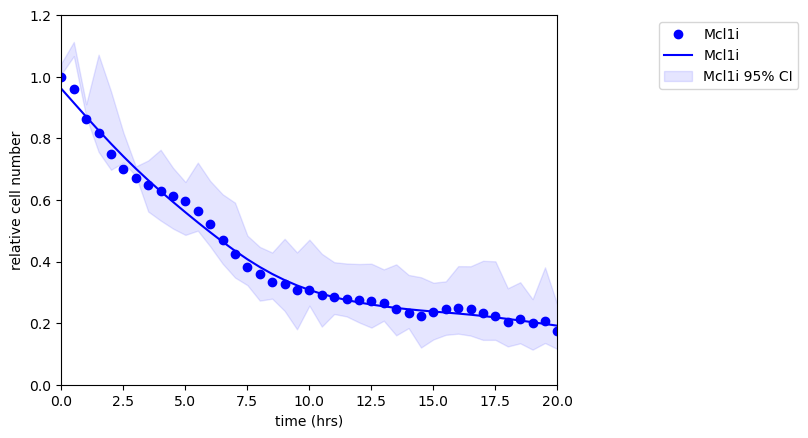

In [15]:
# Relative cell number vs time per treatment (see the markdown above for details)
# Time grid (hours since each model's first analysis frame, see "Time windows per imaging set")
dt_grid=float(np.min([timestep_model[i] for i in indgood_models]))
tmax=20.
tgrid=np.arange(0,tmax+dt_grid/2,dt_grid)
fw=3                      # moving-window width (grid points) used to smooth the treatment mean
cellnumber_std_cut=.05
nmodels_all=len(modelSet)
cellnumber_stdSet=np.ones(nmodels_all)*np.inf
meancellSet=np.zeros(nmodels_all)
cellnumber_set_norm=np.full((nmodels_all,tgrid.size),np.nan)   # relative cell number on the common time grid
for i in indgood_models:
    f0=initial_frames_model[i]; f1=final_frames_model[i]; dt=timestep_model[i]
    frames=np.arange(f0,f1+1)
    t=(frames-f0)*dt
    ncells=np.array([np.sum(modelSet[i].cells_frameSet==f) for f in frames]).astype(float)
    ncells[frames>np.max(modelSet[i].cells_frameSet)]=np.nan   # frames beyond the end of the data are missing, not zero
    meancellSet[i]=np.nanmean(ncells)
    print(f'model {i} mean cellnumber {meancellSet[i]}')
    rel=ncells/np.nanmean(ncells[0:3])                          # relative to the first 3 analysis frames
    ok=np.isfinite(rel)
    # QC: scatter of the second half of the time course around a smoothing spline
    splfov=csaps.CubicSmoothingSpline(t[ok],rel[ok],smooth=5.e-2)
    half=ok&(t>=0.5*t[ok].max())
    cellnumber_stdSet[i]=np.std(rel[half]-splfov(t[half]))/np.mean(rel[half])
    cellnumber_set_norm[i,:]=np.interp(tgrid,t[ok],rel[ok],left=np.nan,right=np.nan)   # NaN outside this model's range

cellnumber_set_norm[np.isinf(cellnumber_set_norm)]=np.nan
# --- per-treatment mean, smoothing, 95% band and plot ---
cellnumber_tmSet=np.full((nf,tgrid.size),np.nan)
cellnumber_bounds=np.full((nf,tgrid.size,2),np.nan)
for i_tm in range(nf):
    plt.figure()
    ax=plt.gca()
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    if indmodels.size==0:
        continue
    # mean relative cell number over the models of this treatment
    cellnumber_tmSet[i_tm,:]=np.nanmean(cellnumber_set_norm[indmodels,:],axis=0)
    mean_raw=cellnumber_tmSet[i_tm,:].copy()
    # forward moving average over fw grid points
    for it in range(tgrid.size):
        cellnumber_tmSet[i_tm,it]=np.nanmean(mean_raw[it:min(it+fw,tgrid.size)])
    # Bayesian-bootstrap 95% interval over the models that have data at this time
    for it in range(tgrid.size):
        cns=cellnumber_set_norm[indmodels,it]
        cns=cns[np.isfinite(cns)]
        if cns.size==0:
            continue
        cns_boots=bayesian_bootstrap.mean(cns, n_replications=10000)
        cellnumber_bounds[i_tm,it,:]=bayesian_bootstrap.central_credible_interval(cns_boots, alpha=0.05)
    okt=np.isfinite(cellnumber_tmSet[i_tm,:])
    ax.plot(tgrid[okt],cellnumber_tmSet[i_tm,okt],'o',color=colorSet[i_tm],label=tmSet[i_tm])
    spl=csaps.CubicSmoothingSpline(tgrid[okt],cellnumber_tmSet[i_tm,okt],smooth=5.e-2)
    ax.plot(tgrid[okt],spl(tgrid[okt]),'-',color=colorSet[i_tm],label=tmSet[i_tm])
    ax.fill_between(tgrid,cellnumber_bounds[i_tm,:,0],cellnumber_bounds[i_tm,:,1],color=colorSet[i_tm],alpha=.1,label=f'{tmSet[i_tm]} 95% CI')
    plt.ylabel('relative cell number')
    plt.xlabel('time (hrs)')
    plt.ylim(0.0,1.2)
    plt.xlim(0,tmax)
    plt.legend(bbox_to_anchor=(1.5, 1.0))
    plt.savefig(f'{date}/{tmSet[i_tm]}_cellnumber.svg')


**Cell-count table.** Writes `SITE_methods_cellnumbers.csv` (treatment, ROI label, mean cells per frame) for the methods section.

In [16]:
# Cell numbers per ROI for the methods section (mean cells per frame in the analysis window, from the previous cell)
data_columns=['treatment','roi_label','ncells']
n_tm=len(tmSet)
data_array=[]
for i_tm in range(n_tm):
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    for imodel in indmodels:
        sctm=modelSet[imodel]
        print(f'{tmSet[inds_tmSet_models[imodel]]} {sctm.figid.decode()} with {int(meancellSet[imodel]):d} cells')
        data_array.append(np.array([tmSet[inds_tmSet_models[imodel]],sctm.figid.decode(),int(meancellSet[imodel])],dtype=object))

data_array=np.array(data_array)
df=pd.DataFrame(data_array,columns=data_columns)
df.to_csv(f'{date}/SITE_methods_cellnumbers.csv')

Mcl1i 20240629_OS17lungInh_RM_xy8_roi0 with 24 cells
Mcl1i 20240703_OS17lungInh_RM_xy8_roi0 with 27 cells
Mcl1i 20240703_OS17lungInh_RM_xy9_roi0 with 29 cells


## 5. Single-cell features

Per-cell features used throughout: 3-D shape (multipole) features, motility, ERK activity (cytoplasm/nucleus ratio), Fra-1 intensity, time since the start of imaging, and the contact of each cell with cancer cells, primary lung cells and matrix. Features that are normalized are normalized within each model.

**Choose morphology features.** Walks the multipole property names and drops anything with `dx`, `curvatures`, `shapes`, `radius`, `matrix` or `l=2` in its name. Result: `indkeep_features`.

In [17]:
# Choose the multipole shape features for the morphology embedding (drop names containing dx, curvatures, shapes, radius, matrix or l=2)
#choose features to keep
sctm=modelSet[indgood_models[0]]
indkeep_features=[]
for ifeat in range(sctm.mm_property_names.size):
    pname=sctm.mm_property_names[ifeat].decode()
    if 'dx' in pname or 'curvatures' in pname or 'shapes' in pname or 'radius' in pname or 'matrix' in pname or 'l=2' in pname:
        print(f'excluding {pname}')
    else:
        indkeep_features.append(ifeat)

print('\n')
indkeep_features=np.array(indkeep_features).astype(int)
for ifeat in indkeep_features:
    print(f'keeping {sctm.mm_property_names[ifeat].decode()}')

excluding l=2 rep cell inv dist to rep cel
excluding l=2 rep cell inv dist to primary
excluding l=0 rep cell inv dist to matrix
excluding l=1 rep cell inv dist to matrix
excluding l=2 rep cell inv dist to matrix
excluding l=0 rep cell dx prevs
excluding l=1 rep cell dx prevs
excluding l=2 rep cell dx prevs
excluding l=0 rep cell dx nexts
excluding l=1 rep cell dx nexts
excluding l=2 rep cell dx nexts
excluding l=0 rep cell curvatures
excluding l=1 rep cell curvatures
excluding l=2 rep cell curvatures
excluding l=0 rep cell shapes
excluding l=1 rep cell shapes
excluding l=2 rep cell shapes
excluding sphere radius


keeping l=0 rep cell inv dist to rep cel
keeping l=1 rep cell inv dist to rep cel
keeping l=0 rep cell inv dist to primary
keeping l=1 rep cell inv dist to primary


**Build the morphology feature matrix.** For each good model, takes the kept `mm_properties`, z-normalizes each feature *within the model*, and stacks all models into `Xf`. Also builds the parallel index arrays (`indtreatment`, `indcells_models`, `indframes_models`, ...) that tell you which model/frame each row of `Xf` belongs to.

In [18]:
# Pooled morphology feature matrix Xf (one row per cell of every good model), each feature z-normalized within its model,
# plus index arrays giving the treatment, model, cell index and frame of every row.
#extract features
Xf_feature_list=np.array(modelSet[indgood_models[0]].mm_property_names)[indkeep_features]
nfeat=indkeep_features.size
Xf=np.zeros((0,nfeat))
indtreatment=np.array([]).astype(int)
indcellSet=np.array([]).astype(int)
indcells_models=np.array([]).astype(int)
indframes_models=np.array([]).astype(int)
for i in indgood_models:
    sctm=modelSet[i]
    Xf_model=sctm.mm_properties[:,indkeep_features].copy()
    for ifeat in range(Xf_model.shape[1]):
        Xf_model[:,ifeat]=imprep.znorm(Xf_model[:,ifeat])
    sctm.Xf=Xf_model
    maxl=np.max(sctm.boundary_library['global_index'])
    print(f'model {i}, libindex: {maxl+1}, mm: {modelSet[i].mm_properties.shape[0]}, ncells {sctm.cells_indSet.size}')
    Xf=np.append(Xf,Xf_model,axis=0)
    indtreatment=np.append(indtreatment,inds_tmSet_models[i]*np.ones(modelSet[i].cells_indSet.size).astype(int))
    indcellSet=np.append(indcellSet,modelSet[i].cells_indSet)
    indcells_models=np.append(indcells_models,i*np.ones(modelSet[i].cells_indSet.size).astype(int))
    indframes_models=np.append(indframes_models,modelSet[i].cells_frameSet)

model 0, libindex: 1048, mm: 1048, ncells 1048
model 1, libindex: 1234, mm: 1234, ncells 1234
model 2, libindex: 1300, mm: 1300, ncells 1300


**Cell motility.** Per cell, `dx` is the displacement from `get_dx` scaled to microns (z scaled by `zscale`) and `dxv` the raw vector. Used later as "motility".

In [19]:
# Motility: displacement per frame in microns (dx; z scaled by zscale) and the raw displacement vector (dxv)
#run this for centroid mobility
for i in indgood_models:
    modelSet[i].dx=np.zeros(modelSet[i].cells_indSet.size)
    modelSet[i].dxv=np.zeros((modelSet[i].cells_indSet.size,modelSet[i].ndim))
    for icell in range(modelSet[i].cells_indSet.size):
        # zscale / micron_per_pixel are taken from `sctm` (last model of the previous cell); this assumes all models share the imaging settings
        modelSet[i].dx[icell]=np.linalg.norm(modelSet[i].get_dx(icell)*[sctm.zscale,1.,1.])*sctm.micron_per_pixel
        modelSet[i].dxv[icell,:]=modelSet[i].get_dx(icell)

**ERK activity.** Collects the cytoplasm/nucleus ratio of the YFP (ERK) reporter per cell into `cratio_erk` (all models concatenated) and stores each model's own values as `x_signal`. The z-normalization is commented out, so these are raw ratios (hence the thresholds near 1 later).

In [20]:
# ERK activity = cytoplasm/nucleus ratio of the YFP reporter. cratio_erk pools all models;
# each model keeps its own values as x_signal (raw ratios, not z-scored).
#%%capture
#signaling features
cratio_erk=np.array([]).astype(float)
for i in indgood_models:
    sctm=modelSet[i]
    nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]
    rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
    erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
    attr_str=f'img{erk_img_channel}_m{cyto_msk_channel}m{nuc_fmsk_channel}_ratio'
    cc=getattr(sctm,attr_str)
    cratio_erk=np.append(cratio_erk,cc)
    if cc.size != sctm.cells_indSet.size:
        print(f'{sctm.h5filename} c/n erk: {cc.size}, feat: {sctm.cells_indSet.size}')

# pooled mean / std (only needed if the z-normalization below is switched back on)
cratio_erk_std=np.nanstd(cratio_erk);cratio_erk_mean=np.nanmean(cratio_erk);

for i in indgood_models:
    sctm=modelSet[i]
    nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]
    rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
    erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
    attr_str=f'img{erk_img_channel}_m{cyto_msk_channel}m{nuc_fmsk_channel}_ratio'
    cc=getattr(sctm,attr_str)
    # raw ratio is used; the z-score version is left in the comment
    cratio_z_model=cc #(cc.T-cratio_erk_mean)/cratio_erk_std
    modelSet[i].x_signal=cratio_z_model.copy()

**Time per cell.** Converts frame index to hours relative to each model's first analysis frame (`times_models`) and stores it on each model as `cells_timeSet`.

In [21]:
# Hours since each model's first analysis frame for every cell (pooled: times_models; per model: cells_timeSet)
times_models=np.zeros(indframes_models.size)
rep_models=np.zeros(indframes_models.size)
for imodel in indgood_models:
    start_frame=initial_frames_model[imodel]
    timestep=timestep_model[imodel]
    indmodel=np.where(indcells_models==imodel)[0]
    times_model=timestep*(indframes_models[indmodel]-start_frame)
    times_models[indmodel]=times_model
    rep_models[indmodel]=inds_imagingSet_models[imodel]
    sctm=modelSet[imodel]
    sctm.cells_timeSet=times_model.copy()
    print(f'rep {inds_imagingSet_models[imodel]} model {imodel} nframes {np.max(sctm.cells_frameSet)} start {start_frame} {sctm.figid.decode()}')

rep 0 model 0 nframes 48 start 0 20240629_OS17lungInh_RM_xy8_roi0
rep 1 model 1 nframes 48 start 0 20240703_OS17lungInh_RM_xy8_roi0
rep 1 model 2 nframes 48 start 0 20240703_OS17lungInh_RM_xy9_roi0


**Fra-1 as z-score vs early cells.** Normalizes nuclear Fra-1 to cells in the 0-1 h window of each model and stores it as `x_signal_fra1`. The first loop (global mean/std) is overwritten by the second (per model).

In [22]:
# Fra-1: nuclear intensity z-scored against the cells of the same model in the 0-1 h window (stored as x_signal_fra1).
# The first loop computes pooled statistics that are not used afterwards; the second loop does the per-model normalization.
#%%capture
#signaling features
fra1_nuc=np.array([]).astype(float)
for i in indgood_models:
    sctm=modelSet[i]
    attr_str=f'nucintensity_fra1'
    cc=getattr(sctm,attr_str)
    fra1_nuc=np.append(fra1_nuc,cc)

indstw=np.where(np.logical_and(times_models>=0.,times_models<=1.))[0]
fra1_nuc_std=np.nanstd(fra1_nuc[indstw]);fra1_nuc_mean=np.nanmean(fra1_nuc[indstw]);

fra1_nuc=np.array([]).astype(float)
for i in indgood_models:
    print(i)
    sctm=modelSet[i]
    attr_str=f'nucintensity_fra1'
    cc=getattr(sctm,attr_str)
    indstw=np.where(np.logical_and(sctm.cells_timeSet>0.,sctm.cells_timeSet<1.))[0]
    fra1_nuc_std=np.nanstd(cc[indstw])
    fra1_nuc_mean=np.nanmean(cc[indstw]);
    fra1_nuc_z_model=(cc.T-fra1_nuc_mean)/fra1_nuc_std
    fra1_nuc=np.append(fra1_nuc,fra1_nuc_z_model)
    modelSet[i].x_signal_fra1=fra1_nuc_z_model.copy()

0
1
2


**Cell-surface contact features.** From each model's boundary library (points sampled on every cell surface, each with its nearest point on the cancer, primary-cell and matrix surfaces) computes, for every cell and surface type, the *contact fraction* (share of boundary points within `contact_radius` of that surface) and the *mean distance*. Results are stored on the model and written to the `.h5` file as `{surface}_contact_fraction` / `{surface}_mean_distance`. Boundary points are grouped by cell once, so the cost scales with the number of points rather than cells x points.

In [23]:
# Contact fraction and mean distance of every cell to each surface type (see the markdown above); saved back into the .h5 files
surface_names={'cancer':1, 'primary':3, 'matrix':4}   # index of each surface type in boundary_library['nn_pts_states']
contact_radius=1.4      # microns; boundary points closer than this to a surface are in contact
border_resolution=1.0   # microns; distances are divided by this resolution
for imodel in indgood_models:
    sctm=modelSet[imodel]
    print(f'calculating contact features for {sctm.figid.decode()}')
    ncells=sctm.cells_indSet.size
    boundary_library=sctm.boundary_library
    # group the boundary points by cell once, instead of scanning the whole library for every cell
    gi=boundary_library['global_index']
    order=np.argsort(gi,kind='stable')
    gi_sorted=gi[order]
    starts=np.searchsorted(gi_sorted,np.arange(ncells),side='left')
    ends=np.searchsorted(gi_sorted,np.arange(ncells),side='right')
    for surfname in ['cancer','primary','matrix']:
        contact_fraction=np.full(ncells,np.nan)
        mean_distance=np.full(ncells,np.nan)
        for ic in range(ncells):
            b_inds=order[starts[ic]:ends[ic]]
            if b_inds.size==0:
                continue
            bpts=boundary_library['nn_pts_states'][b_inds,surface_names[surfname],:]
            pts=boundary_library['pts'][b_inds,:]
            dists=np.linalg.norm(bpts-pts,axis=1)/border_resolution
            dists=dists[np.isfinite(dists)]
            if dists.size==0:
                continue
            contact_fraction[ic]=np.sum(dists<contact_radius)/dists.size
            mean_distance[ic]=np.mean(dists)
        setattr(sctm,f'{surfname}_contact_fraction',contact_fraction)
        setattr(sctm,f'{surfname}_mean_distance',mean_distance)
        sctm.save_to_h5(f'/cell_data_m{mskchannel}/',[f'{surfname}_contact_fraction',f'{surfname}_mean_distance'],overwrite=True)

calculating contact features for 20240629_OS17lungInh_RM_xy8_roi0
saving attributes ['cancer_contact_fraction', 'cancer_mean_distance'] to /cell_data_m0/ in dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
overwrote existing and saved cancer_contact_fraction to dataset/20240629_OS17lungInh_RM_xy8_roi0.h5//cell_data_m0/
overwrote existing and saved cancer_mean_distance to dataset/20240629_OS17lungInh_RM_xy8_roi0.h5//cell_data_m0/
saving attributes ['primary_contact_fraction', 'primary_mean_distance'] to /cell_data_m0/ in dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
overwrote existing and saved primary_contact_fraction to dataset/20240629_OS17lungInh_RM_xy8_roi0.h5//cell_data_m0/
overwrote existing and saved primary_mean_distance to dataset/20240629_OS17lungInh_RM_xy8_roi0.h5//cell_data_m0/
saving attributes ['matrix_contact_fraction', 'matrix_mean_distance'] to /cell_data_m0/ in dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
overwrote existing and saved matrix_contact_fraction to dataset/2024062

**Sanity check.** Scatter of ERK c/n ratio vs Fra-1; the comment says they should correlate. Saves `ERK_ratio_fra1_comp`.

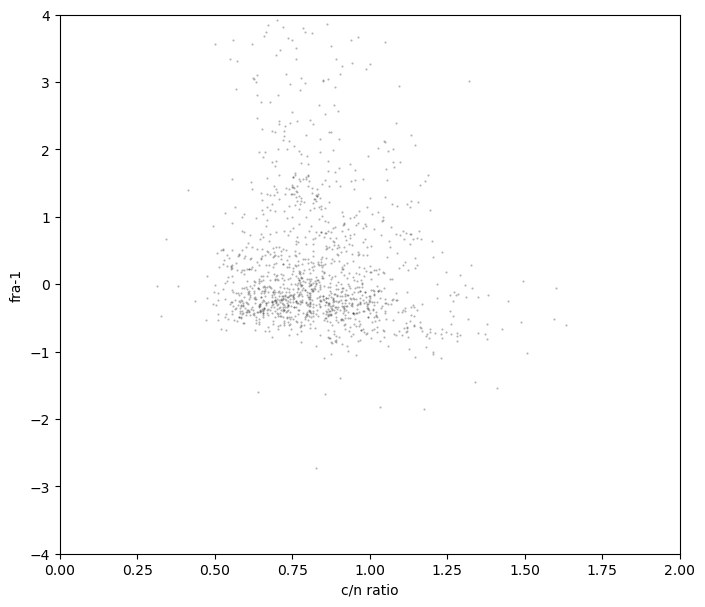

In [24]:
# Quality check: ERK c/n ratio vs Fra-1 z-score for every cell
plt.figure(figsize=(8,7))
plt.scatter(cratio_erk,fra1_nuc,s=1,c='black',marker='.',alpha=.3)
plt.xlabel('c/n ratio')
plt.ylabel('fra-1')
plt.xlim(0.,2.)
plt.ylim(-4,4)

plt.savefig(os.path.join(date, f'ERK_ratio_fra1_comp.png'))
plt.savefig(os.path.join(date, f'ERK_ratio_fra1_comp.svg'), format='svg')

## 6. Initial vs. persistor cells

Compares the properties of cells at the start of imaging with cells that persist to the end of the experiment (and cells that die).

**Helper `generate_xcoords_violin`.** Returns random x positions inside each violin's outline, so that individual data points can be overlaid on violin plots.

In [25]:
# Helper: random x positions inside a violin's outline, used to overlay single data points on violin plots
def generate_xcoords_violin(violinplot, sample_data):
    """
    Generate random x-coordinates within the width of each violin plot at the corresponding y-values.

    Args:
        violinplot: The matplotlib Violin plot object returned by ax.violinplot().
        sample_data: List or array of sample data used to create the violin plot.

    Returns:
        A list of (x, y) coordinates representing random points within the violin's width.
    """
    x_coords = []
    y_coords = []

    # Extract the collection of paths for each violin
    for i, body in enumerate(violinplot["bodies"]):
        # The violin's outline consists of a collection of paths
        path = body.get_paths()[0]
        vertices = path.vertices
        x, y = vertices[:, 0], vertices[:, 1]

        # For each y-value in the sample data, find the width of the violin
        y_sample = sample_data[i]
        for y_val in y_sample:
            # Find the x-coordinates where the violin intersects the y_val
            y_diff = np.abs(y - y_val)
            close_indices = np.where(y_diff == np.min(y_diff))[0]

            # Ensure we get the leftmost and rightmost bounds at this y-value
            x_bounds = x[close_indices]
            x_left = np.min(x_bounds)
            x_right = np.max(x_bounds)

            # Generate random x-coordinates within the bounds
            random_x = np.random.uniform(x_left, x_right, size=1)

            x_coords.append(random_x[0])
            y_coords.append(y_val)

    return x_coords

**Initial vs persistor comparison, per treatment.** For each treatment, collects per-cell values for three groups: dying cells, "persistors" (cells present in each model's final frame) and initial cells (first frame). It then draws violins with replicate means for: 1/distance to cancer cells, ERK activity, 1/distance to lung cells and Fra-1, adds a Welch t-test star annotation, and saves png/svg/pdf. The `*_death` lists are collected but the plots shown compare initial vs persistors. Defines `add_stat_annotation` and `color_reps`.



Mcl1i with 3 models and 199 cells




/tmp/ipykernel_33583/1580847516.py:145: RuntimeWarning: Mean of empty slice
  plt.scatter(0.1,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
/tmp/ipykernel_33583/1580847516.py:146: RuntimeWarning: Mean of empty slice
  mean_initial = np.nanmean(np.array(setv)[np.array(rep_initial) == rep])
/tmp/ipykernel_33583/1580847516.py:162: RuntimeWarning: Mean of empty slice
  plt.scatter(0.9,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
/tmp/ipykernel_33583/1580847516.py:163: RuntimeWarning: Mean of empty slice
  mean_persist = np.nanmean(np.array(setv)[np.array(rep_persist) == rep])
/tmp/ipykernel_33583/1580847516.py:201: RuntimeWarning: Mean of empty slice
  plt.scatter(0.1,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
/tmp/ipykernel_33583/1580847516.py:202: RuntimeWarning: Mean of empty slice
  mean_initial = np.nanmean(np.array(setv)[np.array(rep_initial) == rep])
/tmp/ipykernel_33583/1580847516.py:217: RuntimeWarning: Mean of empty slice
  p

6.774292543230422e-31


/tmp/ipykernel_33583/1580847516.py:332: RuntimeWarning: Mean of empty slice
  ax.scatter(xpos,np.nanmean(setv[fin][ind]),s=50,c=color_reps[r],marker='p')
/tmp/ipykernel_33583/1580847516.py:333: RuntimeWarning: Mean of empty slice
  (means_initial if xpos==0.1 else means_persist).append(np.nanmean(setv[fin][ind]))


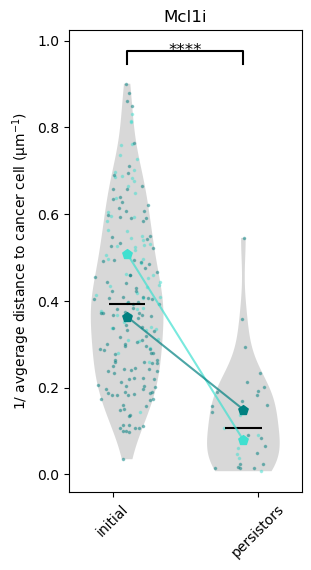

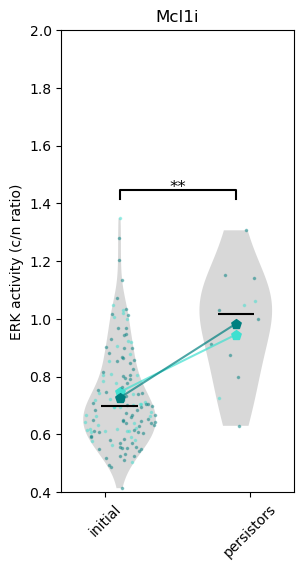

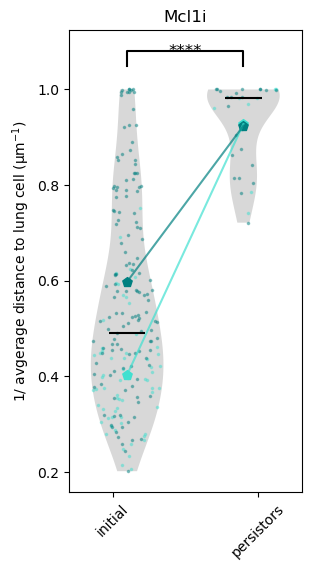

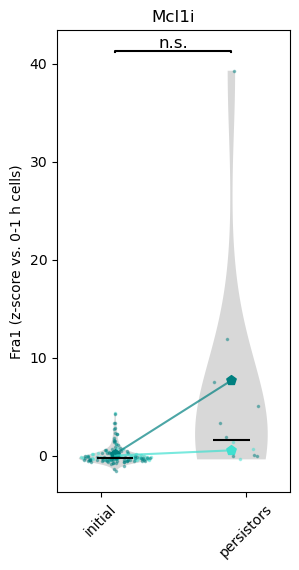

In [26]:
# For each treatment, collect per-cell values for dying cells, persistors (cells in the final analysis frame) and initial cells
# (first analysis frame), then plot initial vs persistors for: 1/distance to cancer cells, ERK, 1/distance to lung cells and Fra-1.
# Small dots = cells colored by imaging set; pentagons = imaging-set means, joined by lines; stars = Welch t-test.
# colors per imaging set (replicate); nreps sets how many are looped over
color_reps=['turquoise','teal','skyblue','dodgerblue']
color_reps_death=['chocolate','sandybrown','peru','grey']
nreps=len(color_reps)
# (not used below)
timecut_early=10 #hours

# Welch t-test between two groups, drawn as a bracket with significance stars
def add_stat_annotation(ax, data1, data2, pos1=0, pos2=1, y_offset=1.05, h=0.2):
    data1 = np.array(data1)[np.isfinite(data1)]
    data2 = np.array(data2)[np.isfinite(data2)]

    if len(data1) == 0 or len(data2) == 0:
        return

    stat, pval = ttest_ind(data1, data2, equal_var=False)  # Welch's t-test

    if pval < 0.0001:
        stars = '****'
    elif pval < 0.001:
        stars = '***'
    elif pval < 0.01:
        stars = '**'
    elif pval < 0.05:
        stars = '*'
    else:
        stars = 'n.s.'

    ymax = max(np.nanmax(data1), np.nanmax(data2)) * y_offset
    ax.plot([pos1, pos1, pos2, pos2], [ymax, ymax+h, ymax+h, ymax], lw=1.5, c='k')
    ax.text((pos1 + pos2) * 0.5, ymax + h*0.5, stars, ha='center', va='bottom', fontsize=12)

# ---- loop over treatments ----
for i_tm in range(nf):
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    ncells=0
    for imodel in indmodels:
        ncells=ncells+np.sum(modelSet[imodel].cells_frameSet==0)
    print('\n');print(f'{tmSet[i_tm]} with {indmodels.size} models and {ncells} cells');print('\n')
    if ncells>0:
        # --- dying cells (death calls inside the analysis window) ---
        times_death=[]
        erk_death=[]
        fra1_death=[]
        lungf_death=[]
        cc_death=[]
        rep_death=[]
        for imodel in indmodels:
            sctm=modelSet[imodel]
            if hasattr(sctm,'nucintensity_fra1'):
                initial_frame=initial_frames_model[imodel]
                final_frame=final_frames_model[imodel]
                timestep=timestep_model[imodel]
                rep=inds_imagingSet_models[imodel]
                for ideath in range(sctm.inds_death.size):
                    ic=sctm.inds_death[ideath]
                    if sctm.cells_frameSet[ic]<=final_frame:
                        times_death.append(timestep*(sctm.cells_frameSet[ic]-initial_frame))
                        rep_death.append(rep)
                        erk_death.append(sctm.x_signal[ic])
                        fra1_death.append(sctm.x_signal_fra1[ic])
                        # mean distance from this cell's surface points to the nearest cancer-cell (index 1) and lung-cell (index 3) surface
                        indboundary=np.where(sctm.boundary_library['global_index']==ic)[0]
                        rdx_cc=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,1,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                        rdx_lung=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,3,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                        lungf_death.append(np.nanmean(rdx_lung))
                        cc_death.append(np.nanmean(rdx_cc))

        # --- persistors: cells present in each model's final analysis frame ---
        times_persist=[]
        erk_persist=[]
        fra1_persist=[]
        lungf_persist=[]
        cc_persist=[]
        rep_persist=[]
        for imodel in indmodels:
            sctm=modelSet[imodel]
            if hasattr(sctm,'nucintensity_fra1'):
                initial_frame=initial_frames_model[imodel]
                final_frame=final_frames_model[imodel]
                timestep=timestep_model[imodel]
                inds_persistors=np.where(sctm.cells_frameSet==final_frame)[0]
                rep=inds_imagingSet_models[imodel]
                for ipersist in range(inds_persistors.size):
                    ic=inds_persistors[ipersist]
                    times_persist.append(timestep*(sctm.cells_frameSet[ic]-initial_frame))
                    rep_persist.append(rep)
                    erk_persist.append(sctm.x_signal[ic])
                    fra1_persist.append(sctm.x_signal_fra1[ic])
                    indboundary=np.where(sctm.boundary_library['global_index']==ic)[0]
                    rdx_cc=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,1,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                    rdx_lung=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,3,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                    lungf_persist.append(np.nanmean(rdx_lung))
                    cc_persist.append(np.nanmean(rdx_cc))

        # --- initial cells: cells in each model's first analysis frame ---
        times_initial=[]
        erk_initial=[]
        fra1_initial=[]
        lungf_initial=[]
        cc_initial=[]
        rep_initial=[]
        for imodel in indmodels:
            sctm=modelSet[imodel]
            if hasattr(sctm,'nucintensity_fra1'):
                initial_frame=initial_frames_model[imodel]
                final_frame=final_frames_model[imodel]
                timestep=timestep_model[imodel]
                inds_initial=np.where(sctm.cells_frameSet==initial_frame)[0]
                rep=inds_imagingSet_models[imodel]
                for icell in range(inds_initial.size):
                    ic=inds_initial[icell]
                    times_initial.append(timestep*(sctm.cells_frameSet[ic]-initial_frame))
                    rep_initial.append(rep)
                    erk_initial.append(sctm.x_signal[ic])
                    fra1_initial.append(sctm.x_signal_fra1[ic])
                    indboundary=np.where(sctm.boundary_library['global_index']==ic)[0]
                    rdx_cc=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,1,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                    rdx_lung=np.linalg.norm(sctm.boundary_library['nn_pts_states'][indboundary,3,:]-sctm.boundary_library['pts'][indboundary,:],axis=1)
                    lungf_initial.append(np.nanmean(rdx_lung))
                    cc_initial.append(np.nanmean(rdx_cc))

        #cc contact
        # Panel 1: closeness to cancer cells (1 / mean distance)
        fig=plt.figure(figsize=(3,6))
        ax=plt.gca()
        setv=1/np.array(cc_initial)/sctm.boundary_library['border_resolution']
        setv_initial=setv
        means_initial = []
        means_persist = []
        if setv[np.isfinite(setv)].size>0:
            vplot=ax.violinplot(setv[np.isfinite(setv)],positions=[0.1],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[np.isfinite(setv)]])
            indf=np.where(np.isfinite(setv))[0]
            for rep in range(nreps):
                ind=np.where(np.array(rep_initial)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.1,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_initial = np.nanmean(np.array(setv)[np.array(rep_initial) == rep])
                means_initial.append(mean_initial)

        # persistor violin; lines join each imaging set's initial and persistor means
        setv=1/np.array(cc_persist)/sctm.boundary_library['border_resolution']
        setv_persist=setv
        if setv[np.isfinite(setv)].size>0:
            vplot=ax.violinplot(setv[np.isfinite(setv)],positions=[0.9],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[np.isfinite(setv)]])
            indf=np.where(np.isfinite(setv))[0]
            for rep in range(nreps):
                ind=np.where(np.array(rep_persist)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.9,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_persist = np.nanmean(np.array(setv)[np.array(rep_persist) == rep])
                means_persist.append(mean_persist)
                ax.plot([0.1, 0.9], [means_initial[rep], means_persist[rep]], color=color_reps[rep], linestyle='-', alpha=0.7)

        # Add significance annotation
        add_stat_annotation(
            ax,
            setv_initial, setv_persist,
            pos1=0.1, pos2=0.9, y_offset=1.05, h=0.03
        )

        ax.set_xlim(-.3,1.3)
        ax.set_xticks(range(0,1+1))
        ax.set_xticklabels(['initial','persistors'],rotation=45)
        ax.set_ylabel('1/ avgerage distance to cancer cell (μm$^{-1}$)')
        plt.title(f'{tmSet[i_tm]}')
        plt.savefig(f'{date}/{tmSet[i_tm]}_cancer_contact_earlylate.png')
        plt.savefig(f'{date}/{tmSet[i_tm]}_cancer_contact_earlylate.svg')
        plt.savefig(f'{date}/{tmSet[i_tm]}_cancer_contact_earlylate.pdf')

        #erk
        # Panel 2: ERK activity
        fig=plt.figure(figsize=(3,6))
        ax=plt.gca()
        setv=np.array(erk_initial)
        setv_initial=setv
        means_initial = []
        means_persist = []
        if setv[np.isfinite(setv)].size>0:
            vplot=ax.violinplot(setv[np.isfinite(setv)],positions=[0.1],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[np.isfinite(setv)]])
            indf=np.where(np.isfinite(setv))[0]
            for rep in range(nreps):
                ind=np.where(np.array(rep_initial)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.1,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_initial = np.nanmean(np.array(setv)[np.array(rep_initial) == rep])
                means_initial.append(mean_initial)

        setv=np.array(erk_persist)
        setv_persist=setv
        if setv[np.isfinite(setv)].size>0:
            vplot=ax.violinplot(setv[np.isfinite(setv)],positions=[0.9],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[np.isfinite(setv)]])
            indf=np.where(np.isfinite(setv))[0]
            for rep in range(nreps):
                ind=np.where(np.array(rep_persist)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.9,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_persist = np.nanmean(np.array(setv)[np.array(rep_persist) == rep])
                means_persist.append(mean_persist)
                ax.plot([0.1, 0.9], [means_initial[rep], means_persist[rep]], color=color_reps[rep], linestyle='-', alpha=0.7)
        # Add significance annotation
        add_stat_annotation(
            ax,
            setv_initial, setv_persist,
            pos1=0.1, pos2=0.9, y_offset=1.05, h=0.03
        )
        ax.set_xlim(-.3,1.3)
        ax.set_ylim(.4,2.0)
        ax.set_xticks(range(0,1+1))
        ax.set_xticklabels(['initial','persistors'],rotation=45)
        ax.set_ylabel('ERK activity (c/n ratio)')
        plt.title(f'{tmSet[i_tm]}')
        plt.savefig(f'{date}/{tmSet[i_tm]}_erk_activity_earlylate.png')
        plt.savefig(f'{date}/{tmSet[i_tm]}_erk_activity_earlylate.svg')
        plt.savefig(f'{date}/{tmSet[i_tm]}_erk_activity_earlylate.pdf')

#lung contacts
        # Panel 3: closeness to lung cells; values above 40 (cells essentially touching) are dropped
        fig=plt.figure(figsize=(3,6))
        ax=plt.gca()

        # build working arrays and mask out >40µm immediately
        raw  = 1/np.array(lungf_initial)/sctm.boundary_library['border_resolution']
        rep  = np.array(rep_initial)
        mask = (np.isfinite(raw) & (raw <= 40))
        # NOTE: rep_initial / rep_persist are replaced by their masked versions here, so the Fra-1 panel below
        # uses replicate labels that no longer line up with fra1_initial / fra1_persist if any cell was masked out
        setv, rep_initial = (raw[mask]), rep[mask]
        indf = np.arange(setv.size)    # now every setv[indf] is ≤40
        setv_initial=raw[mask]

        means_initial = []
        means_persist = []

        if setv[indf].size>0:
            vplot=ax.violinplot(setv[indf],positions=[0.1],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[indf]])
            for rep in range(nreps):
                ind=np.where(np.array(rep_initial)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.1,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_initial = np.nanmean(np.array(setv)[np.array(rep_initial) == rep])
                means_initial.append(mean_initial)

        raw  = 1/np.array(lungf_persist)/sctm.boundary_library['border_resolution']
        rep  = np.array(rep_persist)
        mask = (np.isfinite(raw) & (raw <= 40))

        setv, rep_persist = (raw[mask]), rep[mask]
        indf = np.arange(setv.size)
        setv_persist=raw[mask]

        if setv[np.isfinite(setv)].size>0:
            vplot=ax.violinplot(setv[np.isfinite(setv)],positions=[0.9],showmedians=True,showextrema=False) #,quantiles=[.05,.95])
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=generate_xcoords_violin(vplot,[setv[np.isfinite(setv)]])
            for rep in range(nreps):
                ind=np.where(np.array(rep_persist)[indf]==rep)[0]
                plt.scatter(np.array(xpoints)[ind],setv[indf[ind]],s=10,c=color_reps[rep],marker='.',alpha=.4)
                plt.scatter(0.9,np.nanmean(setv[indf[ind]]),s=50,c=color_reps[rep],marker='p')
                mean_persist = np.nanmean(np.array(setv)[np.array(rep_persist) == rep])
                means_persist.append(mean_persist)
                ax.plot([0.1, 0.9], [means_initial[rep], means_persist[rep]], color=color_reps[rep], linestyle='-', alpha=0.7)

        # Add significance annotation
        add_stat_annotation(
            ax,
            setv_initial, setv_persist,
            pos1=0.1, pos2=0.9, y_offset=1.05, h=0.03
        )

        stat, pval = ttest_ind(setv_initial, setv_persist, equal_var=False)
        print(pval)

        ax.set_xlim(-.3,1.3)
        ax.set_xticks(range(0,1+1))
        ax.set_xticklabels(['initial','persistors'],rotation=45)
        ax.set_ylabel('1/ avgerage distance to lung cell (μm$^{-1}$)')
        plt.title(f'{tmSet[i_tm]}')
        plt.savefig(f'{date}/{tmSet[i_tm]}_lung_contact_earlylate.png')
        plt.savefig(f'{date}/{tmSet[i_tm]}_lung_contact_earlylate.svg')
        plt.savefig(f'{date}/{tmSet[i_tm]}_lung_contact_earlylate.pdf')

#fra1
        # Panel 4: Fra-1 (z-score vs 0-1 h cells)
        fig=plt.figure(figsize=(3,6))
        ax=plt.gca()
        setv_initial=np.array(fra1_initial)
        setv_persist=np.array(fra1_persist)
        rep_i=np.array(rep_initial)
        rep_p=np.array(rep_persist)
        means_initial=[]
        means_persist=[]

        for setv,reps,xpos in [(setv_initial,rep_i,0.1),(setv_persist,rep_p,0.9)]:
            fin=np.isfinite(setv)
            if fin.sum()==0:
                continue
            vplot=ax.violinplot(setv[fin],positions=[xpos],showmedians=True,showextrema=False)
            vplot['cmedians'].set_color('black')
            for pc in vplot['bodies']:
                pc.set_facecolor('gray')
            xpoints=np.array(generate_xcoords_violin(vplot,[setv[fin]]))
            for r in range(nreps):
                ind=np.where(reps[fin]==r)[0]
                ax.scatter(xpoints[ind],setv[fin][ind],s=10,c=color_reps[r],marker='.',alpha=.4)
                ax.scatter(xpos,np.nanmean(setv[fin][ind]),s=50,c=color_reps[r],marker='p')
                (means_initial if xpos==0.1 else means_persist).append(np.nanmean(setv[fin][ind]))

        # lines connecting each replicate's mean
        if len(means_initial)==nreps and len(means_persist)==nreps:
            for r in range(nreps):
                ax.plot([0.1,0.9],[means_initial[r],means_persist[r]],color=color_reps[r],linestyle='-',alpha=0.7)

        add_stat_annotation(ax,setv_initial,setv_persist,pos1=0.1,pos2=0.9,y_offset=1.05,h=0.03)

        ax.set_xlim(-.3,1.3)
        ax.set_xticks(range(0,1+1))
        ax.set_xticklabels(['initial','persistors'],rotation=45)
        ax.set_ylabel('Fra1 (z-score vs. 0-1 h cells)')
        plt.title(f'{tmSet[i_tm]}')
        plt.savefig(f'{date}/{tmSet[i_tm]}_fra1_earlylate.png')
        plt.savefig(f'{date}/{tmSet[i_tm]}_fra1_earlylate.svg')
        plt.savefig(f'{date}/{tmSet[i_tm]}_fra1_earlylate.pdf')

## 7. Neighborhood-deaths (Nd) analysis

Defines the ERK-low/ERK-high threshold and a *neighborhood-deaths* feature `Nd` for every cell: the number of deaths within a fixed radius of the cell, summed over a range of earlier time lags. It then builds a small 2-D (Nd, ERK) embedding with Markov transition pairs, and computes a death-centered correlation: the probability that cells at a given distance and time lag from a death are ERK-active, compared with a null model.

**ERK-low / ERK-high thresholds.** `lowcut=0.85`, `highcut=1.15`, `midcut` = their mean (1.0). `midcut` defines "ERK on" everywhere; `lowcut`/`highcut` are the representative ERK values for the low/high Markov states.

In [27]:
# ERK c/n ratio thresholds: lowcut / highcut are the representative ERK-low / ERK-high values of the Markov states;
# midcut (= 1.0) is the on/off boundary used everywhere else.
#set cutoff between ERK-low and ERK-high
lowcut=0.85
highcut=1.15
midcut=.5*highcut+.5*lowcut
print(midcut)

1.0


**Binary ERK state.** `sigState = x_signal > midcut` per cell and per model. NaN signals compare as False (counted as OFF), so filter with `isfinite` where that matters.

In [28]:
# Binary ERK state per cell (True = ERK on, x_signal > midcut). NaN ratios compare as False, so they count as off.
#signal environment feature
scut=midcut
sigState=np.array([]).astype(int)
for i in indgood_models:
    sigState=np.append(sigState,modelSet[i].x_signal>scut)
    modelSet[i].sigState=modelSet[i].x_signal>scut

**Function `get_death_signal_contributions`.** For each cell, counts the death events within `rmax` of the cell at each of several earlier time lags and sums the counts over the lags. This is the neighborhood-deaths feature (Nd; stored on each model as `Nd` and `Nd_death`). (The docstring in the cell is from an older 1/d-weighted version.)

In [29]:
# Neighborhood-deaths feature Nd. NOTE: the docstring below is from an older version. What the function does now:
# for every cell and every time lag, count the death events within rmax of the cell `time_lag` frames earlier,
# then sum the counts over all lags.
def get_death_signal_contributions(self,inds_death,time_lags=None,x_pos=None,rmax=1000.,zscale=None,rescale_z=False):
    """
    New version 9oct26: returns COUNT of cells that died in lagged timeframe in window of Rmax
    Computes the spatial contributions of signaling between cells over a specified time lag. This method
    averages signals from nearby cells, weighted inversely by their distances, to assess local signaling interactions.

    Parameters
    ----------
    S : ndarray
        A binary array indicating the signaling status of cells (1 for active, 0 for inactive).
    time_lag : int, optional
        The time lag over which to assess signal contributions, defaulting to 0 for immediate interactions.
    x_pos : ndarray, optional
        Positions of cells. If None, the positions are taken from the instance's `x` attribute.
    rmax : float, optional
        The maximum radius within which to consider signal contributions from neighboring cells, default is 5.
    R : float, optional
        Normalization radius, typically set to the average cell diameter; defaults to the instance’s `cellpose_diam`.
    zscale : float, optional
        The scaling factor for the z-dimension, used if `rescale_z` is True.
    rescale_z : bool, optional
        If True, scales the z-coordinates of positions by `zscale`.

    Returns
    -------
    Nd : ndarray
        An array where each element is the averaged spatial signal contribution received by each cell, normalized
        by distance and weighted by the signaling status of neighboring cells.

    Examples
    --------
    >>> traj = Trajectory('path/to/data.h5')
    >>> S = np.random.randint(0, 2, size=traj.cells_indSet.size)
    >>> signal_contributions = traj.get_signal_contributions(S, time_lag=1, rmax=10, R=15)
    # This computes the signal contributions for each cell, considering interactions within a radius of 10 units.

    Notes
    -----
    - This method is useful for understanding the influence of cell-cell interactions within a defined spatial range
    and can be particularly insightful in dynamic cellular environments where signaling is a key factor.
    - The distances are normalized by the cell radius `R` to provide a relative measure of proximity, and the contributions
    are weighted by the inverse of these normalized distances.

    Raises
    ------
    ValueError
        If necessary parameters are missing or incorrectly formatted.
    """
    #S needs to be indexed so S[cell_inds] gives the correct binary signal, same with x_pos
    cellinds=np.arange(self.cells_indSet.size).astype(int)
    # S marks the cells that are (validated) death events
    S=np.isin(cellinds,self.inds_death)
    if x_pos is None:
        x_pos=self.x.copy()
        if rescale_z:
            x_pos=np.multiply(x_pos,np.array([self.zscale,1.,1.]))
    if time_lags is None:
        time_lags=np.arange(self.nt).astype(int)
    nlags=time_lags.size
    Nd=np.ones((S.size,nlags))*np.nan #this will be the average spatial signal (S/r)
    # for each lag, pair every cell with the cell `time_lag` frames earlier on the same track
    for ilag in range(nlags):
        time_lag=time_lags[ilag]
        traj_pairSet=self.get_traj_segments(time_lag+1)
        # lag 0: pair each cell with itself
        if time_lag==0:
            traj_pairSet=np.concatenate((traj_pairSet,traj_pairSet),axis=1)
        else:
            traj_pairSet=np.concatenate((traj_pairSet[:,[0]],traj_pairSet[:,[-1]]),axis=1)
        # loop over the images (frames) of the later time point
        indimgs=np.unique(self.cells_indimgSet[traj_pairSet[:,1]])
        for im in indimgs:
            cell_inds_img1=np.where(self.cells_indimgSet[traj_pairSet[:,1]]==im)[0]
            indcomm_ctraj1=traj_pairSet[cell_inds_img1,0]
            indcomm_ctraj2=traj_pairSet[cell_inds_img1,1]
            x_pos1=x_pos[indcomm_ctraj1,:]
            x_pos2=x_pos[indcomm_ctraj2,:]
            S1=S[indcomm_ctraj1] #signaling status at pair timepoints
            S2=S[indcomm_ctraj2]
            # distances between the earlier and the later positions
            dmatr=utilities.get_dmat(x_pos1,x_pos2) #/R #distance at time-lag
            for j in range(indcomm_ctraj2.size): #1.size): #focus on lag
                d_r=dmatr[j,:]
                # deaths within rmax (d>0 excludes the cell itself)
                inds=np.where(np.logical_and(d_r>0.,d_r<rmax))[0]
                Nd[indcomm_ctraj2[j],ilag]=np.sum(S1[inds]) 
    # sum over lags -> one neighborhood-deaths value per cell
    Nd=np.nansum(Nd,axis=1)
    return Nd

**Compute Nd for every model.** Lags of 6-23 frames (3-11.5 h earlier), z rescaled, `rmax=360` (units of the cell positions); stores `Nd` and an identical copy `Nd_death` on each model and builds the pooled `Nd_death`.

In [30]:
# Nd for every model: deaths within rmax=360 (units of the cell positions, z rescaled), counted over lags of 6-23 frames (3-11.5 h earlier).
# Stored on each model as Nd and Nd_death (identical copies); the pooled Nd_death concatenates all models.
Nd_death=[]
for i in indgood_models:
    sctm=modelSet[i]
    Nd=get_death_signal_contributions(sctm,sctm.inds_death,time_lags=np.arange(6,24).astype(int),x_pos=None,rmax=360.,zscale=None,rescale_z=True)
    sctm.Nd_death=Nd.copy()
    sctm.Nd=Nd.copy()
    Nd_death.append(Nd)

Nd_death=np.concatenate(Nd_death)

**Two-feature vector per cell.** `Xpca = [Nd, ERK]` for each model (neighborhood deaths and ERK activity). This (Nd, ERK) space is used for the ERK-switching model in Section 8. Section 10 later reuses the name `Xpca` for the morphology features.

In [31]:
# Two-feature vector per cell for Sections 7-8: [Nd, ERK c/n ratio]. (indsf is not used.)
for i in indgood_models:
   indsf=np.where(indtreatment==i)[0]
   modelSet[i].Xpca=np.concatenate((modelSet[i].Nd[:,np.newaxis],modelSet[i].x_signal[:,np.newaxis]),axis=1)

**Trajectory dataset for the (Nd, ERK) embedding.** Builds `Xpcat` (one row per cell-trajectory segment of length `trajl=1`, NaN rows dropped) and the parallel arrays: model index (`indtreatment_traj`, actually a *model* index), frames, first/last cell index, motility, Nd.

In [32]:
# Trajectory segments of length trajl=1 in (Nd, ERK) space; segments with NaN are dropped.
# indtreatment_traj holds the MODEL index of each row (not the treatment).
trajl=1
ndim=modelSet[indgood_models[0]].Xpca.shape[1]
Xpcat=np.zeros((0,ndim*trajl))
indtreatment_traj=np.array([]).astype(int)
indstack_traj=np.array([]).astype(int)
indframes_traj=np.array([]).astype(int)
cellinds0_traj=np.array([]).astype(int)
cellinds1_traj=np.array([]).astype(int)
corrc_traj=np.array([]).astype(float)
z_traj=np.array([]).astype(float)
corrc_full_traj=np.zeros((0,trajl))
cancer_cf_full_traj=np.zeros((0,trajl))
primary_cf_full_traj=np.zeros((0,trajl))
dx_full_traj=np.zeros((0,trajl))
dx_traj=np.array([])
Nd_full_traj=np.zeros((0,trajl))
Nd_traj=np.array([])
for i in indgood_models:
    print('building trajectory data for model {}...'.format(i))
    modelSet[i].trajectories=all_trajSet[i].copy()
    modelSet[i].trajl=trajl
    modelSet[i].traj=modelSet[i].get_traj_segments(trajl)
    # features of each segment, flattened to one row per segment
    data=modelSet[i].Xpca[modelSet[i].traj,:]
    data=data.reshape(modelSet[i].traj.shape[0],modelSet[i].Xpca.shape[1]*trajl)
    # drop segments with any NaN feature
    indgood=np.where(np.sum(np.isnan(data),axis=1)==0)[0]
    data=data[indgood,:]
    modelSet[i].traj=modelSet[i].traj[indgood,:]
    Xpcat=np.append(Xpcat,data,axis=0)
    indtreatment_traj=np.append(indtreatment_traj,i*np.ones(data.shape[0]).astype(int))
    indstacks=modelSet[i].cells_imgfileSet[modelSet[i].traj[:,0]]
    indstack_traj=np.append(indstack_traj,indstacks)
    indframes=modelSet[i].cells_frameSet[modelSet[i].traj[:,0]]
    indframes_traj=np.append(indframes_traj,indframes)
    cellinds0=modelSet[i].traj[:,0]
    cellinds0_traj=np.append(cellinds0_traj,cellinds0)
    cellinds1=modelSet[i].traj[:,-1]
    cellinds1_traj=np.append(cellinds1_traj,cellinds1)
    # extra per-segment values: mean z position, motility and Nd at the segment's last cell
    z_traj=np.append(z_traj,np.mean(modelSet[i].cellblocks[:,0],axis=1)[cellinds1])
    dx_traj=np.append(dx_traj,modelSet[i].dx[cellinds1])
    dx_full_traj=np.append(dx_full_traj,modelSet[i].dx[modelSet[i].traj],axis=0)
    Nd_traj=np.append(Nd_traj,modelSet[i].Nd[:,np.newaxis][cellinds1,0])
    Nd_full_traj=np.append(Nd_full_traj,modelSet[i].Nd[:,np.newaxis][modelSet[i].traj,0],axis=0)

cellinds0_traj=cellinds0_traj.astype(int)
cellinds1_traj=cellinds1_traj.astype(int)

building trajectory data for model 0...
building trajectory data for model 1...
building trajectory data for model 2...


**Markov transition pairs for the (Nd, ERK) embedding.** Sets `x=Xpcat`, groups trajectory rows per treatment (`inds_conditions`, computed twice by accident), and collects consecutive-step pairs `(x0set, x1set)` per model plus bookkeeping (`inds_trajsteps_models`, `inds_trajsteps`).

In [33]:
# Transition pairs (x0 -> x1, one frame apart) in (Nd, ERK) space, used by the 8-state model in Section 8
x=Xpcat #x=np.matmul(Xpcat,np.real(M)) #x=np.concatenate((np.real(np.matmul(Xpcat,M)),np.imag(np.matmul(Xpcat,M))),axis=1) #x=np.concatenate((np.real(phi_X[:,indmodes_M1]),np.imag(phi_X[:,indmodes_M1])),axis=1)
for i in indgood_models:
    modelSet[i].trajectories=all_trajSet[i].copy()

# rows of x belonging to each treatment
neigen=x.shape[1]
inds_conditions=[None]*nf
for imf in range(nf):
    indmodels=np.intersect1d(indgood_models,np.where(inds_tmSet_models==imf)[0])
    indstm=np.array([])
    for imodel in indmodels:
        indtm=np.where(indtreatment_traj==imodel)
        indstm=np.append(indstm,indtm)
    inds_conditions[imf]=indstm.astype(int).copy()

# (same block repeated; harmless)
neigen=x.shape[1]
inds_conditions=[None]*nf
for imf in range(nf):
    indmodels=np.intersect1d(indgood_models,np.where(inds_tmSet_models==imf)[0])
    indstm=np.array([])
    for imodel in indmodels:
        indtm=np.where(indtreatment_traj==imodel)
        indstm=np.append(indstm,indtm)
    inds_conditions[imf]=indstm.astype(int).copy()

#get transitions in the trajectory embedding space
x0set=np.zeros((0,neigen))
x1set=np.zeros((0,neigen))
inds_trajsteps_models=np.array([]).astype(int)
inds_trajsteps=np.zeros((0,2)).astype(int)
for i in indgood_models:
    print('getting flows from model: '+str(i))
    indstm=np.where(indtreatment_traj==i)[0]
    if indstm.size>0:
        modelSet[i].Xtraj=x[indstm,0:neigen]
        indstm_model=indstm-np.min(indstm) #index in model
        # consecutive steps along each track: Xtraj0 -> Xtraj1 and their cell indices (inds_trajp1)
        modelSet[i].get_trajectory_steps(inds=None,get_trajectories=False,traj=modelSet[i].traj[indstm_model,:],Xtraj=modelSet[i].Xtraj[indstm_model,:])
        x0=modelSet[i].Xtraj0
        x1=modelSet[i].Xtraj1
        x0set=np.append(x0set,x0,axis=0)
        x1set=np.append(x1set,x1,axis=0)
        inds_trajsteps_models=np.append(inds_trajsteps_models,np.ones(x0.shape[0]).astype(int)*i)
        inds_trajsteps=np.append(inds_trajsteps,modelSet[i].inds_trajp1,axis=0)

getting flows from model: 0
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
getting flows from model: 1
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
matching up trajectory 900
getting flows from model: 2
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
matching up trajectory 900


**Function `get_signal_death_rdf`.** A death-centered radial distribution: for each frame it takes the dying cells and, at a time lag, computes the fraction of cells in distance shells that are signal-on. Output is `(rbins, paircorr)`. `S1` is forced to 1 so only the lagged cell's signal matters.

In [34]:
# Death-centered correlation: at time lag `time_lag`, the fraction of ERK-on cells in each distance shell around cells that died.
# S: 1 = ERK on, 0 = off, -1 = no ERK value (excluded). Returns (outer radius of each shell, ERK-on fraction per shell).
def get_signal_death_rdf(self,S,inds_death=None,fl=None,fu=None,time_lag=0,x_pos=None,cell_inds=None,rbins=None,nr=8,rmax=100,zscale=None,rescale_z=False):
    #S needs to be indexed so S[cell_inds] gives the correct binary signal, same with x_pos
    inds_disallowed=np.where(S<0)[0]
    if inds_death is None:
        inds_death=self.inds_death
    if cell_inds is None:
        cell_inds=np.arange(self.cells_indSet.size).astype(int)
    if x_pos is None:
        x_pos=self.x
    if rescale_z:
        x_pos=np.multiply(x_pos,np.array([self.zscale,1.,1.]))
    if rbins is None:
        rbins=np.linspace(0.,rmax,nr)
    nr=rbins.size
    traj_pairSet=self.get_traj_segments(time_lag+1)
    if time_lag==0:
        traj_pairSet=np.concatenate((traj_pairSet,traj_pairSet),axis=1)
    else:
        traj_pairSet=np.concatenate((traj_pairSet[:,[0]],traj_pairSet[:,[-1]]),axis=1)
    paircorr=np.zeros(nr)
    norm=np.zeros(nr)
    indimgs=np.unique(self.cells_indimgSet[traj_pairSet[:,0]])
    if fl is not None:
        frames=np.arange(fl,fu+1).astype(int)
        indimgs=np.intersect1d(frames,indimgs)
    for im in indimgs:
        cell_inds_img1=np.where(self.cells_indimgSet[traj_pairSet[:,0]]==im)[0]
        indcomm_ctraj1=traj_pairSet[cell_inds_img1,0]
        indcomm_ctraj2=traj_pairSet[cell_inds_img1,1]
        inds_allowed=np.where(np.logical_not(np.isin(indcomm_ctraj2,inds_disallowed)))[0]
        indcomm_ctraj1=indcomm_ctraj1[inds_allowed]
        indcomm_ctraj2=indcomm_ctraj2[inds_allowed]
        inds_on1=np.where(np.isin(indcomm_ctraj1,inds_death))[0] #indexing mismatch change 9oct26 #cells marked as about to die
        x_pos1=x_pos[indcomm_ctraj1[inds_on1],:] #only look at cells which are "on" #indexing mismatch change 9oct26
        x_pos2=x_pos[indcomm_ctraj2,:] #any cell, lagged timepoint
        S1=S[indcomm_ctraj1[inds_on1]] #signaling at first timepoint #indexing mismatch change 9oct26
        S1=np.ones_like(S1) #here, don't care about signaling for cell that died
        S2=S[indcomm_ctraj2] #signaling timelagged
        # matrix of the lagged cells' ERK states, one row per death
        Smat=np.matmul(S1[:,np.newaxis],np.transpose(S2[:,np.newaxis]))
        dmatr=utilities.get_dmat(x_pos1,x_pos2) #distance at time 0
        # shell index of each death-cell pair; accumulate the per-frame ERK-on fraction in each shell
        indr=np.digitize(dmatr,rbins)
        for ir in range(1,nr):
            indcells_dr=np.where(indr==ir)
            if indcells_dr[0].size>0:
                paircorr[ir]=paircorr[ir]+np.sum(Smat[indcells_dr])/indcells_dr[0].size
                norm[ir]=norm[ir]+1
    rbins=rbins[1:]
    paircorr=paircorr[1:]
    norm=norm[1:]
    # average over frames
    for ir in range(nr-1):
        paircorr[ir]=paircorr[ir]/norm[ir]
    return rbins,paircorr

**Run the death RDF for all models and lags.** 11 bin edges (10 distance shells) out to 120 µm and 32 time lags (0-15.5 h), for every good model. Fills `scorr[model, lag, r]` and the baseline ERK-on fraction `scorr_mean_dt`, then averages over models into `scorr_av`. Slow, with per-lag printouts. Defines `nr`, `rmax`, `nt`.

In [35]:
# Death-centered ERK-on probability for every good model and time lag (slow).
# scorr[model, lag, shell] = ERK-on fraction at a distance from a death; scorr_mean_dt = overall ERK-on fraction (baseline).
# nr=11 bin edges -> 10 distance shells out to 120 µm (converted to pixels); nt=32 lags (0-15.5 h)
nr=11;rmax=120.0/sctm.micron_per_pixel #5.6*sctm.cellpose_diam;
nt=32
scorr=np.zeros((nmodels,nt,nr-1))
scorr_mean_dt=np.zeros((nmodels,nt))
for i in indgood_models:
    print(f'calculation model {i}')
    for itt in range(nt):
        print(f' tlag {itt}')
        try:
            fl=initial_frames_model[i]
            fu=final_frames_model[i]
            sctm=modelSet[i]
            # ERK state per cell: 1 on, 0 off, -1 missing
            S=np.zeros_like(sctm.x_signal).astype(int)
            S[sctm.x_signal>midcut]=1
            S[np.isnan(sctm.x_signal)]=-1
            rbins,scorr[i,itt,:]=get_signal_death_rdf(sctm,S,fl=fl,fu=fu,time_lag=itt,nr=nr,rmax=rmax,zscale=sctm.zscale,rescale_z=True)
            # baseline: ERK-on fraction of the cells in the window after the lag
            inds_window=np.where(np.logical_and(sctm.cells_frameSet>fl+itt,sctm.cells_frameSet<fu))[0]
            scorr_mean_dt[i,itt]=np.nanmean(sctm.sigState[inds_window])
        # a failure is reported and that (model, lag) entry stays 0
        except:
            print(f'fail at m{i}')

scorr_av=np.nanmean(scorr,axis=0)

calculation model 0
 tlag 0
 tlag 1
 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11
 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31
calculation model 1
 tlag 0
 tlag 1


/tmp/ipykernel_33583/138577887.py:56: RuntimeWarning: invalid value encountered in scalar divide
  paircorr[ir]=paircorr[ir]/norm[ir]


 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11
 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31
calculation model 2
 tlag 0
 tlag 1
 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11
 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31


/tmp/ipykernel_33583/791761471.py:28: RuntimeWarning: Mean of empty slice
  scorr_av=np.nanmean(scorr,axis=0)


**Analysis ID.** `figid` labels the output files of Sections 7-8 (it is redefined in Section 11).

In [36]:
# Label used in the file names of Sections 7-8 (redefined in Section 11)
figid='SITE_OS17'

**ERK-on probability near deaths vs distance, per time bin.** For each treatment and each 4-frame time bin, averages `scorr` over models/lags in each distance shell (requires at least `min_m=8` values), adds a 95% credible interval and a smoothing spline, and saves `scERK_death_...png/svg`. The spline needs at least two shells with enough values; with few models (as in the saved run) the cell can stop with "'xdata' must contain at least 2 data points" — lower `min_m` in that case.

Mcl1i





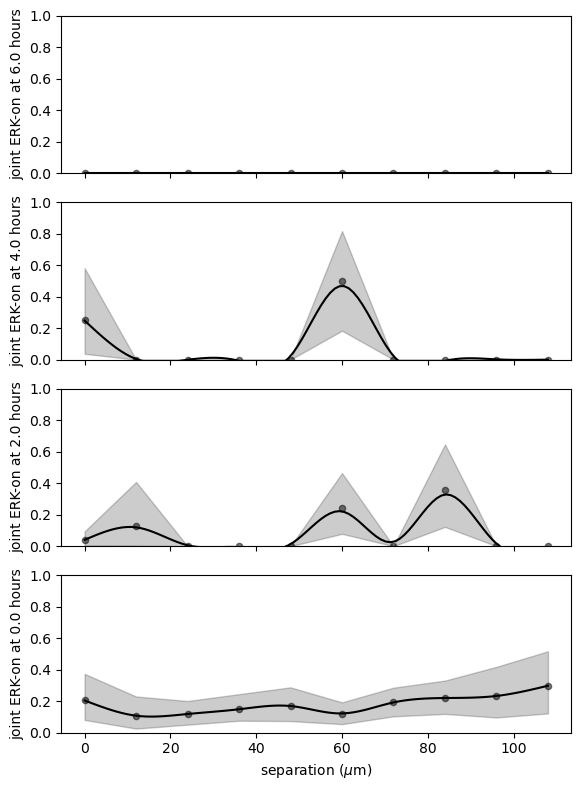

In [37]:
# Per treatment: ERK-on probability vs distance from a death in 4-frame (2 h) bins of time lag, averaged over models and lags,
# with a Bayesian-bootstrap 95% interval (only for shells with >= min_m values) and a smoothing spline.
# The spline needs at least two shells with enough values; otherwise csaps raises "'xdata' must contain at least 2 data points".
min_m=8 #was 15
framebins=np.array([0,4,8,12,16]).astype(int) #,20]).astype(int)
# shell radii in microns (inner edge 0 prepended)
rbins_mu=sctm.micron_per_pixel*np.insert(rbins[0:-1],0,0.)
rbins_mu_smth=np.linspace(np.min(rbins_mu),np.max(rbins_mu),101)
for i_tm in range(nf):
    print(tmSet[i_tm]+'\n\n\n')
    fig,axs=plt.subplots(framebins.size-1,1,sharex=True,figsize=(6,2*(framebins.size-1)))
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    axs=axs.flatten()
    # earliest time bin at the bottom
    axs=np.flip(axs)
    sigState=[]
    for imodel in indmodels:
        sctm=modelSet[imodel]
        sigState.append(sctm.sigState[np.isfinite(sctm.x_signal)])
    sigState=np.concatenate(sigState)
    # overall ERK-on fraction of this treatment (not drawn)
    meanS=np.nanmean(sigState)
    for ibin in range(0,framebins.size-1):
        sc_bin=np.zeros((nr-1,3))
        ax=axs[ibin]
        iframe=framebins[ibin]
        lf=iframe
        uf=framebins[ibin+1]
        scr=scorr[indmodels,lf:uf,:]
        for ir in range(nr-1):
            # values of this shell from all models and lags in the bin
            sc=scr[...,ir]
            sc=sc[np.isfinite(sc)]
            sc_boots = bayesian_bootstrap.mean(sc, n_replications=10000)
            if sc.size>=min_m:
                sc_bin[ir,0]=np.nanmean(sc)
                sc_bin[ir,1:]=bayesian_bootstrap.central_credible_interval(sc_boots, alpha=0.05) #bootstrap.get_CI(sc,1000)
        ind=np.isfinite(sc_bin[:,0])
        spl=csaps.CubicSmoothingSpline(rbins_mu[ind], sc_bin[ind,0], smooth=10.e-2)
        sc_bin_smooth=spl(rbins_mu_smth)
        ax.plot(rbins_mu_smth,sc_bin_smooth,'k-')
        ax.scatter(rbins_mu,sc_bin[:,0],s=20,c='black',alpha=.5)
        ax.fill_between(rbins_mu,sc_bin[:,1],sc_bin[:,2],color='black',alpha=.2)
        ax.set_ylim(0,1)
        ax.set_ylabel(f'joint ERK-on at {iframe*.5:.1f} hours')
        if ibin==0:
            ax.set_xlabel(r'separation ($\mu$m)')
    plt.tight_layout()
    plt.savefig(f'{date}/scERK_death_{figid}_{tmSet[i_tm]}.png')
    plt.savefig(f'{date}/scERK_death_{figid}_{tmSet[i_tm]}.svg')
    plt.show()

**Spatiotemporal heatmaps of the death-centered ERK-on probability.** For treatment `i_tm=0`: ERK-on probability as a function of distance from a death (x) and time lag (y), Gaussian-smoothed. Raises an error if the treatment has no good models. Saves `erk_on_death_spatiotemporal`.

/tmp/ipykernel_33583/1055876352.py:10: RuntimeWarning: Mean of empty slice
  scorr_av = np.nanmean(scorr[indmodels, ...], axis=0)


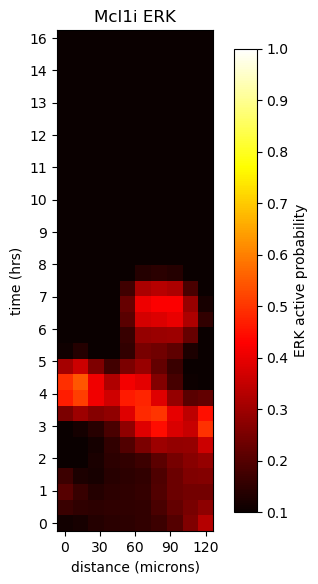

In [38]:
# Heatmap of the death-centered ERK-on probability (x: distance from the death, y: time lag) for treatment i_tm=0, Gaussian-smoothed
i_tm = 0
timestep = .5

indmodels = np.where(inds_tmSet_models == i_tm)[0]
indmodels = np.intersect1d(indmodels, indgood_models)
if indmodels.size == 0:
    raise ValueError(f'i_tm={i_tm}: no good models')

scorr_av = np.nanmean(scorr[indmodels, ...], axis=0)
scorr_av[~np.isfinite(scorr_av)] = 0.
scorr_av_smth = scipy.ndimage.gaussian_filter(scorr_av, 1., mode='reflect')

fig, ax = plt.subplots(figsize=(6.5, 6.5))
im = ax.imshow(scorr_av_smth, origin='lower', cmap=plt.cm.hot, clim=(0.1, 1.))
ax.set(xticks=np.linspace(0, nr-2, int(nr/2)),
       xticklabels=["%0d" % x for x in (np.round(.1*np.linspace(0, rmax*sctm.micron_per_pixel, int(nr/2)))*10).astype(int)],
       yticks=np.linspace(0, nt-1, int(nt/2)),
       yticklabels=["%.0f" % x for x in timestep*np.linspace(0, nt-1, int(nt/2))])
ax.set_xlabel('distance (microns)')
ax.set_ylabel('time (hrs)')
ax.set_title(f'{tmSet[i_tm]} ERK')

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('ERK active probability')

plt.savefig(f'{date}/erk_on_death_spatiotemporal.png')
plt.savefig(f'{date}/erk_on_death_spatiotemporal.svg')
plt.show()

**Null model for the death-centered correlation.** Recomputes `scorr` with randomly chosen cells in place of the death locations, giving a baseline (`scorr_null2`) against which the observed ERK-on probability near deaths is compared.

In [39]:
# Null model: the same calculation with the death locations replaced by randomly chosen cells and the ERK states shuffled,
# averaged over nrand=20 randomizations (scorr_null2).
scorr_null2=np.ones((nmodels,nt,nr-1))*np.nan
nrand=20
for i in indgood_models:
    print(f'calculation model {i}')
    fl=initial_frames_model[i]
    fu=final_frames_model[i]
    for itt in range(nt):
        print(f' tlag {itt}')
        if True: #try:
            sctm=modelSet[i]
            #x_pos=sctm.x.copy()
            inds_death_orig=sctm.inds_death.copy()
            if np.isscalar(inds_death_orig):
                inds_death_orig=np.array([inds_death_orig]).astype(int)
            sc=np.ones((nrand,nr-1))*np.nan
            for irand in range(nrand):
                # random 'death' cells, as many as the real deaths
                inds_death=np.zeros_like(inds_death_orig)
                for ideath in range(inds_death_orig.size):
                    inds=np.arange(sctm.cells_frameSet.size).astype(int)
                    inds_death[ideath]=np.random.choice(inds)
                S_null=np.zeros_like(sctm.x_signal).astype(int)
                S_null[sctm.x_signal>midcut]=1
                S_null[np.isnan(sctm.x_signal)]=-1
                # shuffle the ERK states across cells
                np.random.shuffle(S_null)
                rbins,sc[irand,:]=get_signal_death_rdf(sctm,S_null,inds_death=inds_death,x_pos=None,fl=fl,fu=fu,time_lag=itt,nr=nr,rmax=rmax,zscale=sctm.zscale,rescale_z=True)
            scorr_null2[i,itt,:]=np.nanmean(sc,axis=0)

calculation model 0
 tlag 0
 tlag 1


/tmp/ipykernel_33583/138577887.py:56: RuntimeWarning: invalid value encountered in scalar divide
  paircorr[ir]=paircorr[ir]/norm[ir]


 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11


/tmp/ipykernel_33583/3937251692.py:30: RuntimeWarning: Mean of empty slice
  scorr_null2[i,itt,:]=np.nanmean(sc,axis=0)


 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31
calculation model 1
 tlag 0
 tlag 1
 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11
 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31
calculation model 2
 tlag 0
 tlag 1
 tlag 2
 tlag 3
 tlag 4
 tlag 5
 tlag 6
 tlag 7
 tlag 8
 tlag 9
 tlag 10
 tlag 11
 tlag 12
 tlag 13
 tlag 14
 tlag 15
 tlag 16
 tlag 17
 tlag 18
 tlag 19
 tlag 20
 tlag 21
 tlag 22
 tlag 23
 tlag 24
 tlag 25
 tlag 26
 tlag 27
 tlag 28
 tlag 29
 tlag 30
 tlag 31


**Heatmaps of the null model.** The same layout for the randomized-death null `scorr_null2` (treatment 0). Saves `..._null2`.

/tmp/ipykernel_33583/457069333.py:11: RuntimeWarning: Mean of empty slice
  scorr_av=np.nanmean(scorr_null2[indmodels,...],axis=0)


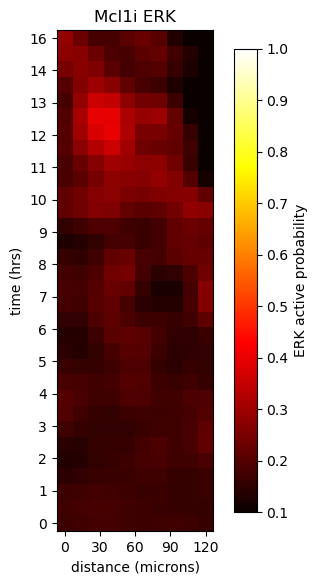

In [41]:
# Heatmap of the null model for treatment 0 (same layout as the observed heatmap)
n_tm=len(tmSet)
timestep=.5
tms=[0]
fig,axs=plt.subplots(1,len(tms),figsize=(6.5*len(tms),6.5),squeeze=False)
axs=axs.flatten()
for iplot in range(len(tms)):
    i_tm=tms[iplot]
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    scorr_av=np.nanmean(scorr_null2[indmodels,...],axis=0)
    scorr_av[np.logical_not(np.isfinite(scorr_av))]=0.
    scorr_av_smth=scipy.ndimage.gaussian_filter(scorr_av,1.,mode='reflect')
    ax=axs[iplot]
    ax.imshow(scorr_av_smth,origin='lower',cmap=plt.cm.hot,clim=(0.1,1.))
    ax.set(xticks=np.linspace(0, nr-2, int(nr/2)), xticklabels=["%0d" % x for x in (np.round(.1*np.linspace(0, rmax*sctm.micron_per_pixel, int(nr/2)))*10).astype(int)], yticks=np.linspace(0,nt-1,int(nt/2)), yticklabels=["%.0f" % x for x in timestep*np.linspace(0,nt-1,int(nt/2))]);
    ax.set_xlabel('distance (microns)')
    ax.set_ylabel('time (hrs)')
    ax.set_title(f'{tmSet[i_tm]} ERK')

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('ERK active probability')

plt.savefig(f'{date}/erk_on_death_spatiotemporal_all_null2.png')
plt.savefig(f'{date}/erk_on_death_spatiotemporal_all_null2.svg')
plt.show()

## 8. ERK switching as a function of neighborhood deaths

A small Markov model on eight fixed states (four Nd levels x ERK low/high) estimates how the probabilities of switching ERK on and off depend on neighborhood deaths. Uncertainty comes from a leave-one-imaging-set-out bootstrap.

**Eight fixed cluster centers in (Nd, ERK).** Four Nd levels (`Nd_clusters` = 0, 1, 2, 3 nearby deaths, now that Nd is a count) crossed with two ERK levels (`lowcut`, `highcut`) define eight centers; a PyEMMA `AssignCenters` object assigns every point to the nearest center. The cell plots the (Nd, ERK) point cloud with numbered centers and saves `Nd_clusters.npy`. `Nd_clusters` is used again in Section 14.

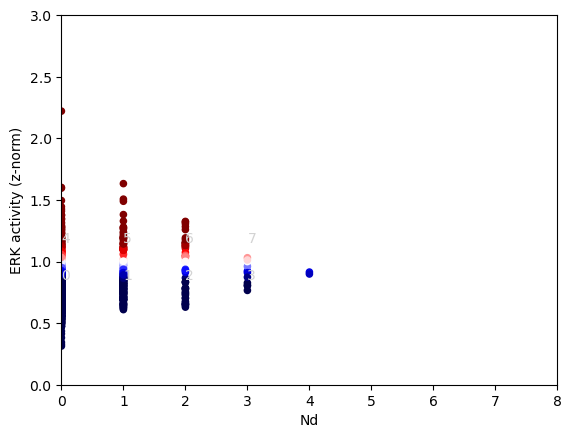

In [42]:
# Eight fixed states in (Nd, ERK) space: Nd = 0, 1, 2, 3 nearby deaths crossed with ERK low (lowcut) / high (highcut).
# States 0-3 are ERK-low, 4-7 ERK-high; every point is assigned to the nearest center.
#modeling with Nd
n_Nd=4
Ndmax=8.
Slow=lowcut
Shigh=highcut
Nd_clusters=np.array([0.,1., 2., 3.])
clustercenters0=np.concatenate((Nd_clusters[:,np.newaxis],Slow*np.ones_like(Nd_clusters)[:,np.newaxis]),axis=1)
clustercenters1=np.concatenate((Nd_clusters[:,np.newaxis],Shigh*np.ones_like(Nd_clusters)[:,np.newaxis]),axis=1)
clustercenters=np.append(clustercenters0,clustercenters1,axis=0)
n_clusters=clustercenters.shape[0]
clusters=coor.clustering.AssignCenters(clustercenters, metric='euclidean')

#plot umap of the embedding space
# all (Nd, ERK) points colored by ERK, with the state numbers
plt.figure()
plt.scatter(x[:,0],x[:,1],s=20,c=x[:,1],cmap=plt.cm.seismic,clim=(Slow,Shigh))
plt.ylim(0.,3)
ind_clusters=clusters.assign(x)
x_clusters=np.zeros((n_clusters,2))

for iclust in range(n_clusters):
    plt.text(clustercenters[iclust,0],clustercenters[iclust,1],str(iclust),color='lightgray')

plt.xlabel('Nd')
plt.xlim(0,Ndmax)
# (label says z-norm, but x_signal holds the raw c/n ratio)
plt.ylabel('ERK activity (z-norm)')
plt.savefig(f'{date}/clusters_Nd_ERK.png')
np.save(f'{date}/Nd_clusters.npy',Nd_clusters)

**Markov model of ERK switching vs. neighborhood deaths.** For treatment 0 and transitions in the 0-8 h window, in a leave-one-imaging-set-out bootstrap, builds the 8-state transition matrix and extracts `P_ons` (ERK low to high) and `P_offs` (high to low) for each Nd level. Averages over replicates and plots 95% credible bands. Saves `jointP_Nd_bootstrap_*`.

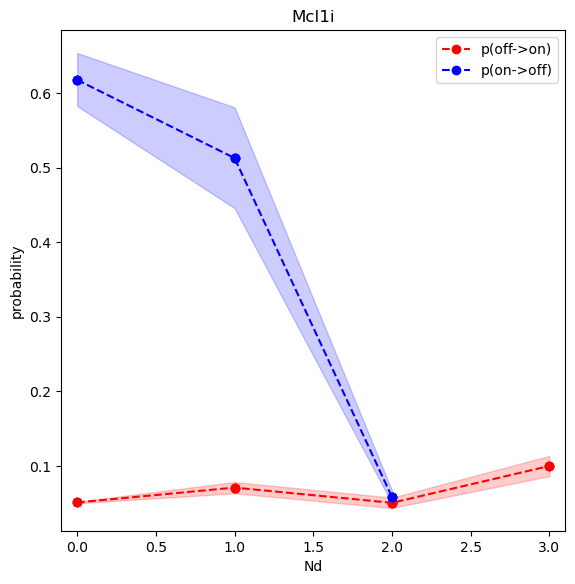

In [43]:
# ERK switching vs neighborhood deaths for treatment 0, from transitions in the 0-8 h window (tl, tu).
# Leave one imaging set out, bootstrap the remaining models nboots times, build the 8-state transition matrix and read
# P(off->on) and P(on->off) for every Nd level. Bands: Bayesian-bootstrap 95% intervals.
#Markov state model, with errorbars of mean over fovs
tms=[0]
fig,axs=plt.subplots(1,len(tms),figsize=(6.5*len(tms),6.5),squeeze=False)
axs=axs.flatten()
MtSet=[None]*nf
Nd_clusters_smth=np.linspace(np.min(Nd_clusters),np.max(Nd_clusters),51)
nboots=100
tl=0
tu=8
for iplot in range(len(tms)):
    i_tm=tms[iplot]
    centers_minima=clusters.clustercenters.copy()
    clusters_minima=coor.clustering.AssignCenters(centers_minima, metric='euclidean')
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    P_ons_set=[]
    P_offs_set=[]
    P_ons_CR=np.zeros((n_Nd,3))
    P_offs_CR=np.zeros((n_Nd,3))
    imagingSets=np.unique(inds_imagingSet_models[indmodels])
    for iSet in imagingSets:
        indmodels_imagingSets=np.where(inds_imagingSet_models==iSet)[0]
        indmodels_Set=np.setdiff1d(indmodels,indmodels_imagingSets)
        indmodels_Set=np.intersect1d(indmodels_Set,indgood_models)
        for iboot in range(nboots):
            x0=[]
            x1=[]
            indmodels_boots= np.random.choice(indmodels_Set, size=indmodels_Set.size, replace=True)
            for imodel in indmodels_boots:
                sctm=modelSet[imodel]
                inds_model=np.where(inds_trajsteps_models==imodel)[0]
                # keep transitions whose end point lies in the tl-tu window (hours)
                indstw=np.where(np.logical_and(sctm.cells_timeSet[inds_trajsteps[inds_model,1]]<tu,sctm.cells_timeSet[inds_trajsteps[inds_model,1]]>tl))[0]
                x0.append(x0set[inds_model[indstw],:])
                x1.append(x1set[inds_model[indstw],:])
            x0=np.concatenate(x0)
            x1=np.concatenate(x1)
            # row-normalized 8x8 transition matrix
            P=model.get_transition_matrix(x0,x1,clusters=clusters_minima)
            P_ons=np.zeros(n_Nd)
            P_offs=np.zeros(n_Nd)
            P_stayons=np.zeros(n_Nd)
            P_stayoffs=np.zeros(n_Nd)
            ind0=np.where(centers_minima[:,1]==Slow)[0]
            ind1=np.where(centers_minima[:,1]==Shigh)[0]
            # state i = (Nd level i, ERK low); state i+n_Nd = (Nd level i, ERK high)
            for i in range(n_Nd):
                P_ons[i]=np.sum(P[i,ind1])
                P_offs[i]=np.sum(P[i+n_Nd,ind0])
                P_stayons[i]=np.sum(P[i+n_Nd,ind1])
                P_stayoffs[i]=np.sum(P[i,ind0])
            if np.sum(P_ons>0.):
                P_ons_set.append(P_ons)
            if np.sum(P_offs>0.):
                P_offs_set.append(P_offs)
    P_ons_set=np.array(P_ons_set)
    P_offs_set=np.array(P_offs_set)
    P_ons_CR[:,0]=np.nanmean(P_ons_set,axis=0)
    P_offs_CR[:,0]=np.nanmean(P_offs_set,axis=0)
    for i in range(n_Nd):
        P_ons_boots=bayesian_bootstrap.mean(P_ons_set[:,i],n_replications=10000)
        P_ons_CR[i,1:]=bayesian_bootstrap.central_credible_interval(P_ons_boots,alpha=.05) #bootstrap.get_CI(P_ons_set[:,i],1000)
        P_offs_boots=bayesian_bootstrap.mean(P_offs_set[:,i],n_replications=10000)
        P_offs_CR[i,1:]=bayesian_bootstrap.central_credible_interval(P_offs_boots,alpha=.05) #bootstrap.get_CI(P_offs_set[:,i],1000)
    # smoothing splines (computed but not drawn)
    spl_on=csaps.CubicSmoothingSpline(Nd_clusters, P_ons_CR[:,0], smooth=.999)
    P_ons_smth=spl_on(Nd_clusters_smth)
    spl_off=csaps.CubicSmoothingSpline(Nd_clusters, P_offs_CR[:,0], smooth=.999)
    P_offs_smth=spl_off(Nd_clusters_smth)
    indcalc_on=np.where(P_ons_CR>0.)[0]
    indcalc_off=np.where(P_offs_CR>0.)[0]
    ax=axs[iplot]
    ax.fill_between(Nd_clusters[indcalc_on],P_ons_CR[indcalc_on,1],P_ons_CR[indcalc_on,2],color='red',alpha=.2)
    ax.fill_between(Nd_clusters[indcalc_off],P_offs_CR[indcalc_off,1],P_offs_CR[indcalc_off,2],color='blue',alpha=.2)
    ax.plot(Nd_clusters[indcalc_on],P_ons_CR[indcalc_on,0],'ro--',label='p(off->on)',alpha=1)
    ax.plot(Nd_clusters[indcalc_off],P_offs_CR[indcalc_off,0],'bo--',label='p(on->off)',alpha=1)
    ax.set_xlim(-.1,Nd_clusters[-1]+.1)
    ax.set_xlabel('Nd')
    ax.set_ylabel('probability')
    ax.legend(loc='upper right')
    ax.set_title(tmSet[i_tm])

plt.savefig(f'{date}/jointP_Nd_bootstrap_{figid}_{tmSet[i_tm]}.png')
plt.savefig(f'{date}/jointP_Nd_bootstrap_{figid}_{tmSet[i_tm]}.svg')
plt.show()

## 9. Spatial clusters of ERK-high cells

Finds spatially connected clusters of ERK-high cells in each frame and compares the size distribution of clusters across treatments and replicates.

**Function `get_clusterids`.** Finds spatial clusters of ERK-high cells per frame: smooths the YFP image, thresholds at z>2, labels connected regions, and assigns each tracked cell the id and size of its cluster. Saves `cluster_ids`/`cluster_sizes` into the h5 file. The `@ray.remote` decorator is commented out.

In [44]:
# Spatial clusters of ERK-high cells, frame by frame: smooth the YFP image (sigma = half a cell diameter), threshold at z > 2,
# label connected regions and give each tracked cell inside a region that cluster's id and size. Saves cluster_ids / cluster_sizes
# to the .h5 file. Re-loads the model from disk and uses cyto_msk_channel from the global scope.
#@ray.remote(num_cpus=2)
def get_clusterids(h5filename,rsmooth=None):
    print(f'calc {h5filename}')
    sctm=trajectory.Trajectory(h5filename=h5filename)
    status=sctm.load_from_h5('/cell_data_m0/')
    try:
        del sctm.fmsks_cancer; del sctm.fmsks_primary; del sctm.boundary_library #delete off these for memory conservation
    except:
        pass
    print(sctm.h5filename)
    rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
    if rsmooth is None:
        rsmooth=sctm.cellpose_diam/2.
    zcut=2.0
    cluster_ids=np.zeros(sctm.cells_indSet.size).astype(int)
    cluster_sizes=np.zeros(sctm.cells_indSet.size).astype(int)
    clusterid=1
    for iframe in range(sctm.nt):
        print(f'extracting cluster data for model {sctm.figid.decode()}, frame {iframe}')
        msk=sctm.get_mask_data(iframe);
        msk_cyto=msk[...,cyto_msk_channel];
        img_rep=sctm.get_image_data(iframe)[...,rep_img_channel];
        img_rep_smth=skimage.filters.gaussian(img_rep,sigma=[rsmooth/sctm.zscale,rsmooth,rsmooth],mode='mirror')
        fmsk=imprep.znorm(img_rep_smth)>zcut
        indframe=np.where(sctm.cells_frameSet==iframe)[0]
        labelids_frame=sctm.cells_labelidSet[indframe]
        msk_clusters=imprep.get_labeled_mask(fmsk,fill_holes=False)
        titlestr=f''
        # cells (mask label ids) that overlap each ERK-high region
        for icluster in np.unique(msk_clusters)[1:]:
            labelids_cluster=np.unique(msk_cyto[msk_clusters==icluster])
            labelids_cluster=labelids_cluster[labelids_cluster>0] #indices one less than labeled mask, ignore 0
            labelids_common,inds_common_frame,inds_common_cluster=np.intersect1d(labelids_frame,labelids_cluster,return_indices=True)
            global_inds=indframe[inds_common_frame]
            print(f'frame {iframe} cluster {clusterid} size {global_inds.size} ids {global_inds} meansig {np.nanmean(sctm.x_signal[global_inds]):.2f})')
            if global_inds.size>0:
                cluster_ids[global_inds]=clusterid
                cluster_sizes[global_inds]=global_inds.size
                clusterid=clusterid+1
    sctm.cluster_ids=cluster_ids
    sctm.cluster_sizes=cluster_sizes
    sctm.save_to_h5('/cell_data_m0/',['cluster_ids','cluster_sizes'],overwrite=True)
    return cluster_ids

**Cluster all models.** Runs `get_clusterids` for every good model and attaches the result to the model as `cluster_ids`.

In [45]:
# Cluster every good model (re-reads each .h5 file; slow)
for imodel in indgood_models:
    modelSet[imodel].cluster_ids=get_clusterids(modelList[imodel])

calc dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
loading dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
interpreting image as zxyc
interpreting mask as zxyc
loading dataset/20240629_OS17lungInh_RM_xy8_roi0.h5:/cell_data_m0/
dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
extracting cluster data for model 20240629_OS17lungInh_RM_xy8_roi0, frame 0
frame 0 cluster 1 size 63 ids [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62] meansig 0.75)
extracting cluster data for model 20240629_OS17lungInh_RM_xy8_roi0, frame 1
frame 1 cluster 2 size 65 ids [ 63  64  65  66  67  68  69  70  71  72  73  74  75  76  77  78  79  80
  81  82  83  84  85  86  87  88  89  90  91  92  93  94  95  96  97  98
  99 100 101 102 103 104 105 106 107 108 109 110 111 112 113 114 115 116
 117 118 119 120 121 122 123 124 125 126 127] meansig 0.74)
extracting cluster data for model 202

/tmp/ipykernel_33583/3057911403.py:38: RuntimeWarning: Mean of empty slice
  print(f'frame {iframe} cluster {clusterid} size {global_inds.size} ids {global_inds} meansig {np.nanmean(sctm.x_signal[global_inds]):.2f})')


frame 2 cluster 3 size 0 ids [] meansig nan)
frame 2 cluster 3 size 52 ids [128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145
 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161 162 163
 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179] meansig 0.76)
extracting cluster data for model 20240629_OS17lungInh_RM_xy8_roi0, frame 3
frame 3 cluster 4 size 43 ids [180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222] meansig 0.75)
extracting cluster data for model 20240629_OS17lungInh_RM_xy8_roi0, frame 4
frame 4 cluster 5 size 42 ids [223 224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 239 240
 241 242 243 244 245 246 247 248 249 250 251 252 253 254 255 256 257 258
 259 260 261 262 263 264] meansig 0.73)
extracting cluster data for model 20240629_OS17lungInh_RM_xy8_roi0, frame 5
frame 5 cluster 6 size 0 ids [] mea

**Cluster-size statistics at the first frame.** For each treatment, bins ERK-cluster sizes (1, 2, 4, ... cells) and records the fraction ERK-on (`Smean`) and the replicate for each bin. Fills `csize_set`, `Smean_csize_set`, `rep_set`.

In [47]:
# Per treatment: ERK-high clusters bucketed by size (1, 2, 4, ..., 64+ cells); for the cells of the first frame (fl=0, fu=1)
# record each size bin's ERK-on fraction (Smean) and imaging set.
#get initial frame cluster sizes by replicate
#fraction on version
Smean_csize_set=[None]*nf
csize_set=[None]*nf
rep_set=[None]*nf
clusterbins=np.array([0,1,2,4,8,16,32,64,1000])
fl=0
fu=1
for i_tm in range(nf):
    csize=[]
    Smean_csize=[]
    rep=[]
    inds_csize_models=np.array([]).astype(int)
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    for imodel in indmodels:
        try:
            sctm=modelSet[imodel]
            print(f'{sctm.figid.decode()}')
            inds_frames=np.where(np.logical_and(sctm.cells_frameSet>=fl,sctm.cells_frameSet<fu))[0]
            ind_clusters,cluster_sizes=np.unique(sctm.cluster_ids,return_counts=True)
            if np.isin(0,ind_clusters):
                ind_clusters=ind_clusters[1:]
                cluster_sizes=cluster_sizes[1:]
            ind_clusterbins=np.digitize(cluster_sizes,clusterbins)-1
            for iclusterbin in np.unique(ind_clusterbins):
                inds_bin=np.where(ind_clusterbins==iclusterbin)[0]
                clusterids=ind_clusters[inds_bin]
                global_ids=np.where(np.isin(sctm.cluster_ids,clusterids))[0]
                global_ids=np.intersect1d(global_ids,inds_frames)
                indgood=np.where(np.isfinite(sctm.x_signal[global_ids]))[0]
                Smean=np.nanmean(sctm.x_signal[global_ids[indgood]]>midcut)
                csize.append(clusterbins[iclusterbin])
                Smean_csize.append(Smean)
                rep.append(inds_imagingSet_models[imodel])
            inds_csize_models=np.append(inds_csize_models,np.ones_like(csize)*imodel)
        except Exception as e:
            print(e)
    csize=np.array(csize)
    Smean_csize=np.array(Smean_csize)
    rep=np.array(rep)
    Smean_csize_set[i_tm]=Smean_csize.copy()
    csize_set[i_tm]=csize.copy()
    rep_set[i_tm]=rep.copy()

20240629_OS17lungInh_RM_xy8_roi0
20240703_OS17lungInh_RM_xy8_roi0
20240703_OS17lungInh_RM_xy9_roi0


**Cluster-size histogram.** Stacked bars of the number of clusters per size bin, colored by replicate. Saves `clustersizes.svg`.

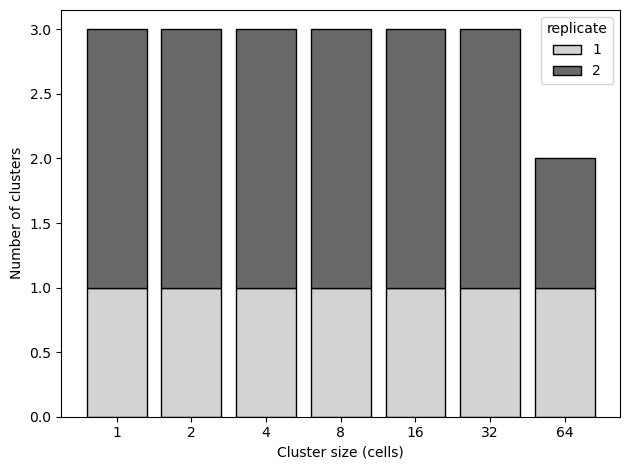

In [48]:
# Stacked bars of cluster-size bins, colored by imaging set, pooled over treatments.
# NOTE: csize_set has one entry per (model, size bin), so a bar counts models with clusters of that size, not single clusters.
# This cell also overwrites `x`; Section 10 rebuilds it.
# Combine across treatments
cluster_sizes_list = csize_set.copy()
replicate_list = rep_set.copy()
sizes_all = np.concatenate(cluster_sizes_list)
reps_all = np.concatenate(replicate_list)

# Unique bins and replicates
unique_sizes = np.sort(np.unique(sizes_all))
unique_reps = np.sort(np.unique(reps_all))

# Colors for each replicate
repColorSet = ['lightgray', 'dimgray', 'whitesmoke', 'gray']

# Plot
width = 0.8
x = np.arange(len(unique_sizes))

fig, ax = plt.subplots()
bottom = np.zeros(len(unique_sizes))

for i, rep in enumerate(unique_reps):
    counts = np.array([np.sum((sizes_all == sz) & (reps_all == rep)) for sz in unique_sizes])
    ax.bar(
        x, counts, width,
        bottom=bottom,
        color=repColorSet[i],
        edgecolor='black',
        label=f'{rep+1}'
    )
    bottom += counts

# Labels and legend
ax.set_xticks(x)
ax.set_xticklabels(unique_sizes)
ax.set_xlabel('Cluster size (cells)')
ax.set_ylabel('Number of clusters')

ax.legend(title='replicate', loc='upper right')
plt.tight_layout()
plt.savefig(f'{date}/clustersizes.svg')

## 10. Trajectory embedding

Collects the contact features per cell, assembles the feature matrix `Xpca` (morphology) and builds trajectory segments in that feature space. The time autocorrelation of the features supports the choice of trajectory length. The result is the embedding `x` and the transition pairs (`x0set`, `x1set`) used for the Markov state models below. These variables reuse the names of Section 7.

**Gather contact fractions.** Concatenates per-model cancer/primary/matrix contact fractions into flat arrays aligned with the cell index arrays.

In [49]:
# Pool the per-cell contact fractions (cancer, primary/lung, matrix) of all good models; also rebuilds the cell index arrays
cancer_contact_fraction=[]
primary_contact_fraction=[]
matrix_contact_fraction=[]
indtreatment=np.array([]).astype(int)
indcellSet=np.array([]).astype(int)
indcells_global_Set=np.array([]).astype(int)
indcells_models=np.array([]).astype(int)
for i in indgood_models:
    sctm=modelSet[i]
    cancer_contact_fraction.append(sctm.cancer_contact_fraction)
    primary_contact_fraction.append(sctm.primary_contact_fraction)
    matrix_contact_fraction.append(sctm.matrix_contact_fraction)
    indtreatment=np.append(indtreatment,inds_tmSet_models[i]*np.ones(sctm.cancer_contact_fraction.size).astype(int))
    indcellSet=np.append(indcellSet,sctm.cells_indSet)
    indcells_global_Set=np.append(indcells_global_Set,np.arange(sctm.cancer_contact_fraction.size).astype(int))
    indcells_models=np.append(indcells_models,i*np.ones(sctm.cancer_contact_fraction.size).astype(int))

cancer_contact_fraction=np.concatenate(cancer_contact_fraction)
primary_contact_fraction=np.concatenate(primary_contact_fraction)
matrix_contact_fraction=np.concatenate(matrix_contact_fraction)

**Mean distances.** Same as above for the mean distance to each surface.

In [50]:
# Same for the mean distance to each surface
cancer_mean_distance=[]
primary_mean_distance=[]
matrix_mean_distance=[]
indtreatment=np.array([]).astype(int)
indcellSet=np.array([]).astype(int)
indcells_models=np.array([]).astype(int)
for i in indgood_models:
    sctm=modelSet[i]
    cancer_mean_distance.append(sctm.cancer_mean_distance)
    primary_mean_distance.append(sctm.primary_mean_distance)
    matrix_mean_distance.append(sctm.matrix_mean_distance)
    indtreatment=np.append(indtreatment,inds_tmSet_models[i]*np.ones(sctm.cancer_mean_distance.size).astype(int))
    indcellSet=np.append(indcellSet,sctm.cells_indSet)
    indcells_models=np.append(indcells_models,i*np.ones(sctm.cancer_mean_distance.size).astype(int))

cancer_mean_distance=np.concatenate(cancer_mean_distance)
primary_mean_distance=np.concatenate(primary_mean_distance)
matrix_mean_distance=np.concatenate(matrix_mean_distance)

**Morphology feature matrix `Xpca`.** Stacks the kept morphology features from `Xf` and assigns each model its slice. This is the second, high-dimensional embedding used for state discovery (clusters, kinetic states).

In [51]:
# Feature matrix for the morphology embedding: all kept shape features of Xf (ERK and contacts are not included).
# Each model gets its rows as modelSet[i].Xpca, replacing the (Nd, ERK) Xpca of Section 7.
#put the features for embedding into Xpca feature vector
feature_list=[]
Xpca=np.zeros((cratio_erk.size,0)) #use this if you want to leave out pca morphology features

indkeep=np.arange(Xf.shape[1]).astype(int); #np.setdiff1d(np.arange(Xf.shape[1]).astype(int),[16]).astype(int)
for i in indkeep: #range(len(Xf_feature_list)):
    feature_list.append(Xf_feature_list[i].decode())
    Xpca=np.append(Xpca,Xf[:,i][:,np.newaxis],axis=1)

print(feature_list)

for i in indgood_models:
   indsf=np.where(indcells_models==i)[0]
   modelSet[i].Xpca=Xpca[indsf,:]

ndim=Xpca.shape[1]

['l=0 rep cell inv dist to rep cel', 'l=1 rep cell inv dist to rep cel', 'l=0 rep cell inv dist to primary', 'l=1 rep cell inv dist to primary']


**Function `get_tcf`.** Time autocorrelation of the embedding vector along cell tracks (dot product between time points, averaged by lag). Loops over all pairs of times, so it is slow for long tracks.

In [52]:
# Time autocorrelation along tracks: mean dot product of feature vectors separated by each lag (up to half the longest track)
def get_tcf(self, trajectories=None, x=None, minlength=2): ##remove
    if x is None:
        x=self.Xpca
    if trajectories is None:
        trajectories = self.trajectories
    ntraj = len(trajectories)
    traj_lengths = np.zeros(ntraj)
    for itraj in range(ntraj):
        traj_lengths[itraj] = trajectories[itraj].size
    nframes = np.max(traj_lengths)
    nt = np.floor(nframes / 2).astype(int)
    dxcorr = np.zeros(nt)
    tnorm = np.zeros(nt)
    for itraj in range(ntraj):
        cell_traj = trajectories[itraj]
        traj_len = cell_traj.size
        nmax = np.floor(traj_len / 2).astype(int)
        if traj_len > minlength:
            xtraj = x[cell_traj,:]
            for it1 in range(nmax):
                for it2 in range(it1, it1 + nmax):
                    it = it2 - it1
                    corr=np.dot(xtraj[it1,:],xtraj[it2,:])
                    if np.isfinite(corr):
                        dxcorr[it]=dxcorr[it]+corr
                        tnorm[it] = tnorm[it] + 1
    for it in range(nt):
        dxcorr[it] = dxcorr[it] / tnorm[it]
    return dxcorr

**Per-model autocorrelation.** Normalizes each model's TCF to 1 at lag 0 and plots it colored by treatment.

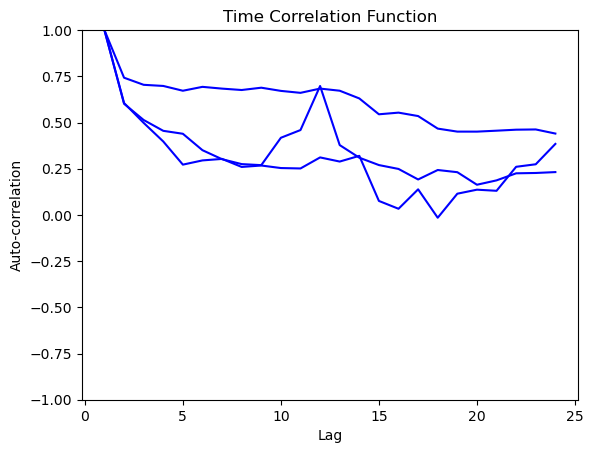

In [53]:
# Normalized autocorrelation per model (squared mean subtracted, 1 at lag 0), colored by treatment. (avsq is not used.)
tcfSet = [None] * nmodels ##remove

for imodel in indgood_models:
    i_tm=inds_tmSet_models[imodel]
    sctm = modelSet[imodel]
    tcf = get_tcf(sctm, x=sctm.Xpca, minlength=2)
    if tcf.size > 0:
        av_sq = np.sum(np.power(np.nanmean(sctm.Xpca, axis=0), 2))
        avsq = np.nanmean(np.power(np.linalg.norm(sctm.Xpca, axis=1), 2))
        tcf = (tcf - av_sq) / (tcf[0]-av_sq)  # Auto-correlation
        tcfSet[imodel] = tcf

        # Get the color for the current model's treatment from color mapping
        current_treatment = tmSet[inds_tmSet_models[imodel]]
        color = colorSet[i_tm]  # Default to 'grey' if not found

        # Plot with the correct color
        plt.plot(np.arange(1, tcf.size + 1), tcf, color=color, label=current_treatment)

plt.xlabel('Lag')
plt.ylabel('Auto-correlation')
plt.title('Time Correlation Function')
plt.ylim(-1,1)
plt.show()

**Average autocorrelation per treatment.** Averages the TCFs of the good models in each treatment (first 60 lags) and draws a dashed line at 5 frames (`trajl=5` is set here only for that line; the next cell sets `trajl=1` for the embedding). Saves `tcf.svg`.

Mcl1i models [0 1 2]


/tmp/ipykernel_33583/3049618478.py:21: RuntimeWarning: Mean of empty slice
  tcf_tm[i_tm] = np.nanmean(tcfs, axis=1)


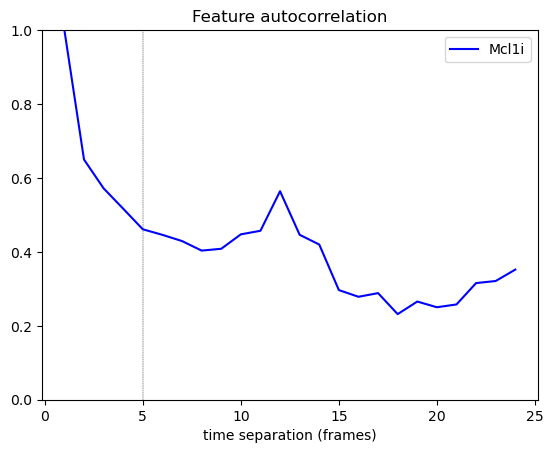

In [55]:
# Mean autocorrelation per treatment over the first 60 lags. trajl=5 here only places the dashed reference line;
# the embedding in the next cell uses trajl=1.
n_tm=len(tmSet) ##remove
nf = n_tm
tcf_tm = [None] * nf
tmax = 60

for i_tm in range(nf):
    ind_models = indgood_models[inds_tmSet_models[indgood_models] == i_tm]
    print(f'{tmSet[i_tm]} models {ind_models}')
    tcfs = np.ones((tmax, ind_models.size)) * np.nan

    for ii in range(ind_models.size):
        try:
            tmax_model = tcfSet[ind_models[ii]].size
            tmax_model = np.min(np.array([tmax, tmax_model]))
            tcfs[0:tmax_model, ii] = tcfSet[ind_models[ii]][0:tmax_model]
        except Exception as e:
            print(e)

    tcf_tm[i_tm] = np.nanmean(tcfs, axis=1)

    # Get color from the color mapping
    color = colorSet[i_tm]  # Default to 'grey' if not found

    # Plot with the correct color
    plt.plot(np.arange(1, tmax + 1), tcf_tm[i_tm], color=color, label=tmSet[i_tm])

trajl=5
plt.plot([trajl,trajl],[0,np.nanmax(np.array(tcf_tm))],'k--',linewidth=.3)
# Customize plot labels and title
plt.title('Feature autocorrelation')
plt.xlabel('time separation (frames)')
plt.ylim(0,1)
plt.legend(loc='upper right')
plt.savefig(f'{date}/tcf.svg')
plt.show()

**Trajectory embedding of the morphology features.** Builds trajectory segments of length `trajl` from the full feature matrix `Xpca`, with per-trajectory arrays for ERK/Fra-1, contact fractions, mean distances, motility and neighborhood-deaths features. Sets `x` (the embedding), `neigen` and `inds_conditions`. These names are the same as in Section 7, which used the small (Nd, ERK) embedding.

In [56]:
# Trajectory segments (length trajl=1) in the morphology feature space, with per-segment ERK, Fra-1, contact, distance,
# motility and neighborhood-deaths values (*_traj: value at the segment's last cell; *_full_traj: values at every cell of the segment).
# Sets x (the embedding), neigen and inds_conditions, replacing the Section 7 variables of the same name.
#trajectory embedding
trajl=1
ndim=modelSet[indgood_models[0]].Xpca.shape[1]
Xpcat=np.zeros((0,ndim*trajl))
indtreatment_traj=np.array([]).astype(int)
indstack_traj=np.array([]).astype(int)
indframes_traj=np.array([]).astype(int)
cellinds0_traj=np.array([]).astype(int)
cellinds1_traj=np.array([]).astype(int)
cancer_cf_traj=np.array([])
primary_cf_traj=np.array([])
matrix_cf_traj=np.array([])
cancer_dist_traj=np.array([])
primary_dist_traj=np.array([])
matrix_dist_traj=np.array([])
cratio_erk_traj=np.array([]).astype(float)
cratio_erk_full_traj=np.zeros((0,trajl))
cancer_cf_full_traj=np.zeros((0,trajl))
primary_cf_full_traj=np.zeros((0,trajl))
matrix_cf_full_traj=np.zeros((0,trajl))
cancer_dist_full_traj=np.zeros((0,trajl))
primary_dist_full_traj=np.zeros((0,trajl))
matrix_dist_full_traj=np.zeros((0,trajl))
dx_full_traj=np.zeros((0,trajl))
dx_traj=np.array([])
Nd_traj=np.array([])
Nd_full_traj=np.zeros((0,trajl))
Nd_death_traj=np.array([])
Nd_death_full_traj=np.zeros((0,trajl))
fra1_traj=np.array([])
fra1_full_traj=np.zeros((0,trajl))
for i in indgood_models:
    print('building trajectory data for model {}...'.format(i))
    modelSet[i].trajectories=all_trajSet[i].copy()
    modelSet[i].trajl=trajl
    modelSet[i].traj=modelSet[i].get_traj_segments(trajl)
    data=modelSet[i].Xpca[modelSet[i].traj,:]
    data=data.reshape(modelSet[i].traj.shape[0],modelSet[i].Xpca.shape[1]*trajl)
    indgood=np.where(np.sum(np.isnan(data),axis=1)==0)[0]
    data=data[indgood,:]
    modelSet[i].traj=modelSet[i].traj[indgood,:]
    Xpcat=np.append(Xpcat,data,axis=0)
    indtreatment_traj=np.append(indtreatment_traj,i*np.ones(data.shape[0]).astype(int))
    indstacks=modelSet[i].cells_imgfileSet[modelSet[i].traj[:,0]]
    indstack_traj=np.append(indstack_traj,indstacks)
    indframes=modelSet[i].cells_frameSet[modelSet[i].traj[:,-1]]
    indframes_traj=np.append(indframes_traj,indframes)
    cellinds0=modelSet[i].traj[:,0]
    cellinds0_traj=np.append(cellinds0_traj,cellinds0)
    cellinds1=modelSet[i].traj[:,-1]
    cellinds1_traj=np.append(cellinds1_traj,cellinds1)
    cratio_erk_traj=np.append(cratio_erk_traj,modelSet[i].x_signal[cellinds1])
    cratio_erk_full_traj=np.append(cratio_erk_full_traj,modelSet[i].x_signal[modelSet[i].traj],axis=0)
    cancer_cf_traj=np.append(cancer_cf_traj,modelSet[i].cancer_contact_fraction[cellinds1])
    primary_cf_traj=np.append(primary_cf_traj,modelSet[i].primary_contact_fraction[cellinds1])
    matrix_cf_traj=np.append(matrix_cf_traj,modelSet[i].matrix_contact_fraction[cellinds1])
    cancer_cf_full_traj=np.append(cancer_cf_full_traj,modelSet[i].cancer_contact_fraction[modelSet[i].traj],axis=0)
    primary_cf_full_traj=np.append(primary_cf_full_traj,modelSet[i].primary_contact_fraction[modelSet[i].traj],axis=0)
    matrix_cf_full_traj=np.append(matrix_cf_full_traj,modelSet[i].matrix_contact_fraction[modelSet[i].traj],axis=0)
    cancer_dist_traj=np.append(cancer_dist_traj,modelSet[i].cancer_mean_distance[cellinds1])
    primary_dist_traj=np.append(primary_dist_traj,modelSet[i].primary_mean_distance[cellinds1])
    matrix_dist_traj=np.append(matrix_dist_traj,modelSet[i].matrix_mean_distance[cellinds1])
    cancer_dist_full_traj=np.append(cancer_dist_full_traj,modelSet[i].cancer_mean_distance[modelSet[i].traj],axis=0)
    primary_dist_full_traj=np.append(primary_dist_full_traj,modelSet[i].primary_mean_distance[modelSet[i].traj],axis=0)
    matrix_dist_full_traj=np.append(matrix_dist_full_traj,modelSet[i].matrix_mean_distance[modelSet[i].traj],axis=0)
    dx_traj=np.append(dx_traj,modelSet[i].dx[cellinds1])
    dx_full_traj=np.append(dx_full_traj,modelSet[i].dx[modelSet[i].traj],axis=0)
    Nd_traj=np.append(Nd_traj,modelSet[i].Nd[cellinds1])
    Nd_full_traj=np.append(Nd_full_traj,modelSet[i].Nd[modelSet[i].traj],axis=0)
    Nd_death_traj=np.append(Nd_death_traj,modelSet[i].Nd_death[cellinds1])
    Nd_death_full_traj=np.append(Nd_death_full_traj,modelSet[i].Nd_death[modelSet[i].traj],axis=0)
    fra1_traj=np.append(fra1_traj,modelSet[i].x_signal_fra1[cellinds1])
    fra1_full_traj=np.append(fra1_full_traj,modelSet[i].x_signal_fra1[modelSet[i].traj],axis=0)

cellinds0_traj=cellinds0_traj.astype(int)
cellinds1_traj=cellinds1_traj.astype(int)

# embedding used for clustering and all Markov models below
x=Xpcat #x=np.matmul(Xpcat,np.real(M)) #x=np.concatenate((np.real(np.matmul(Xpcat,M)),np.imag(np.matmul(Xpcat,M))),axis=1) #x=np.concatenate((np.real(phi_X[:,indmodes_M1]),np.imag(phi_X[:,indmodes_M1])),axis=1)
for i in indgood_models:
    modelSet[i].trajectories=all_trajSet[i].copy()

# rows of x belonging to each treatment
neigen=x.shape[1]
inds_conditions=[None]*nf
for imf in range(nf):
    indmodels=np.intersect1d(indgood_models,np.where(inds_tmSet_models==imf)[0])
    indstm=np.array([])
    for imodel in indmodels:
        indtm=np.where(indtreatment_traj==imodel)
        indstm=np.append(indstm,indtm)
    inds_conditions[imf]=indstm.astype(int).copy()

building trajectory data for model 0...
building trajectory data for model 1...
building trajectory data for model 2...


**Transition pairs for the morphology embedding.** Collects `x0set`, `x1set`, `inds_trajsteps_models` and `inds_trajsteps` for the Markov model.

In [57]:
# Transition pairs (x0 -> x1) in the morphology embedding, used by all Markov models from Section 11 on
#get transitions in the trajectory embedding space
x0set=np.zeros((0,neigen))
x1set=np.zeros((0,neigen))
inds_trajsteps_models=np.array([]).astype(int)
inds_trajsteps=np.zeros((0,2)).astype(int)
for i in indgood_models:
    print('getting flows from model: '+str(i))
    indstm=np.where(indtreatment_traj==i)[0]
    if indstm.size>0:
        modelSet[i].Xtraj=x[indstm,0:neigen]
        indstm_model=indstm-np.min(indstm) #index in model
        modelSet[i].get_trajectory_steps(inds=None,get_trajectories=False,traj=modelSet[i].traj[indstm_model,:],Xtraj=modelSet[i].Xtraj[indstm_model,:])
        x0=modelSet[i].Xtraj0
        x1=modelSet[i].Xtraj1
        x0set=np.append(x0set,x0,axis=0)
        x1set=np.append(x1set,x1,axis=0)
        inds_trajsteps_models=np.append(inds_trajsteps_models,np.ones(x0.shape[0]).astype(int)*i)
        inds_trajsteps=np.append(inds_trajsteps,modelSet[i].inds_trajp1,axis=0)

getting flows from model: 0
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
getting flows from model: 1
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
matching up trajectory 900
getting flows from model: 2
matching up trajectory 0
matching up trajectory 100
matching up trajectory 200
matching up trajectory 300
matching up trajectory 400
matching up trajectory 500
matching up trajectory 600
matching up trajectory 700
matching up trajectory 800
matching up trajectory 900


## 11. Microstates, Markov state model and kinetic states

The embedding is clustered into microstates; a transition matrix between microstates defines a Markov state model whose slowest eigenvectors are used to group microstates into a few *kinetic states*. States are ordered by the mean distance of their cells to cancer cells and labeled A, B, C (A closest).

### 11.1 Microstates and Markov state model

**Analysis ID.** `figid` labels the output files of Sections 11-14; it encodes the feature set and `trajl`.

In [58]:
# Label for the output files of Sections 11-14 (feature set and trajectory length)
#Analysis identifiers
figid=f'SITE_mml1_trajl{trajl}_'
print(figid)

SITE_mml1_trajl1_


**Microstates.** K-means clustering of the embedding into `n_clusters=150` microstates (fixed seed). With `get_clusters=True` the clustering is computed and saved to `{date}/clusters_nc150_{figid}.npy`; with `False` the microstates are taken from the manuscript state file `manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj`.

In [59]:
# Microstates: k-means with n_clusters=150 on the embedding (get_clusters=True), or, with get_clusters=False,
# the microstates stored in the manuscript state file manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj.
#get microstate clusters
get_clusters=False
n_clusters=150 #int(np.sqrt(x.shape[0]))
if get_clusters:
    clusters=coor.cluster_kmeans([x],k=n_clusters,metric='euclidean',fixed_seed=2,max_iter=100) #0)
    np.save(f'{date}/clusters_nc{n_clusters}_{figid}.npy',clusters)
else:
    # the file holds [clusters, stateSet]; take the clusters
    objFile=f'manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj'
    objFileHandler=open(objFile,'rb')
    states_object=pickle.load(objFileHandler)
    clusters=states_object[0]

**Markov state model on the 150 microstates.** Builds the transition matrix, keeps the largest connected component (re-indexing the cluster centers), forms the Hermitian matrix `H = sym(P) + i*antisym(P)`, diagonalizes it, and plots the eigenvalue spectrum. Redefines `clusters_minima`, `n_clusters`, `stateCenters`.

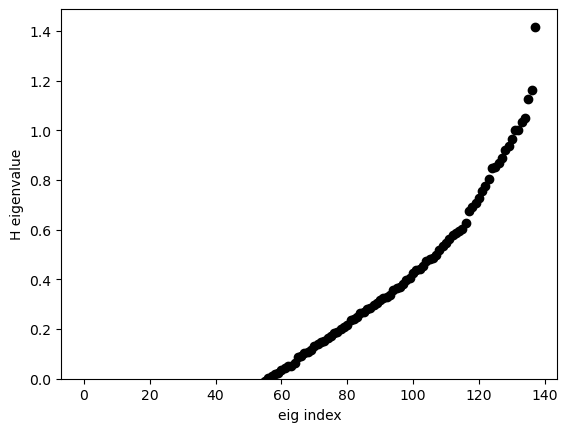

In [60]:
# Markov state model on the microstates: transition matrix restricted to the largest connected component,
# then eigen-decomposition of the Hermitian matrix H = sym(P) + i*antisym(P).
#Markov state model
centers_minima=clusters.clustercenters.copy()
clusters_minima=coor.clustering.AssignCenters(centers_minima, metric='euclidean')
P=model.get_transition_matrix(x0set,x1set,clusters=clusters_minima)
# keep only the largest connected set of microstates
graph = csr_matrix(P>0.)
n_components, labels = connected_components(csgraph=graph, directed=False, return_labels=True)
unique, counts = np.unique(labels, return_counts=True)
icc=unique[np.argmax(counts)]
indcc=np.where(labels==icc)[0]
centers_minima=centers_minima[indcc,:];stateCenters=centers_minima
clusters_minima=coor.clustering.AssignCenters(centers_minima, metric='euclidean')
P=model.get_transition_matrix(x0set,x1set,clusters=clusters_minima)
n_clusters=indcc.size

# real part = symmetric part of P, imaginary part = antisymmetric (flux) part
H=.5*(P+np.transpose(P))+.5j*(P-np.transpose(P))
w,v=np.linalg.eig(H)
w=np.real(w)
indsort=np.argsort(w)
w=w[indsort]
v=v[:,indsort]

plt.clf()
plt.plot(np.arange(n_clusters),w,'ko',label='eigenvalues')
plt.ylim(0.,np.max(w)+.05*np.max(w))
plt.xlabel('eig index')
plt.ylabel('H eigenvalue')
plt.pause(.1)

**Slow modes.** Keeps the top `ncomp=3` eigenvectors, weighted by eigenvalue: `vkin` (real+imaginary parts stacked, used to cluster microstates into kinetic states), `va` (magnitude) and `vth` (phase). Saves the eigenvalue plot.

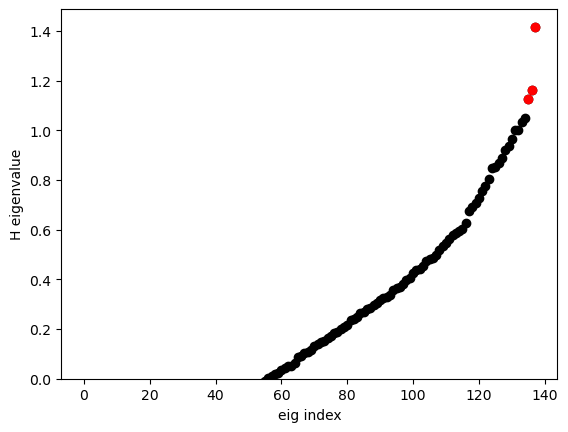

In [61]:
# Keep the ncomp=3 slowest modes (largest eigenvalues), weighted by eigenvalue: vkin (real and imaginary parts) is the input
# of the kinetic-state clustering; va / vth (magnitude / phase) are for plotting.
ncomp=3 #number of eigencomponents to keep
vr=np.multiply(w[-ncomp:],np.real(v[:,-ncomp:]))
vi=np.multiply(w[-ncomp:],np.imag(v[:,-ncomp:]))
vkin=np.append(vr,vi,axis=1)
va=np.abs(v[:,-ncomp:])
vkin=np.append(vr,vi,axis=1)
vth=np.arctan2(vr,vi)
plt.clf()
plt.plot(np.arange(n_clusters),w,'ko',label='eigenvalues')
plt.plot(np.arange(n_clusters)[-ncomp:],w[-ncomp:],'ro')
plt.ylim(0.,np.max(w)+.05*np.max(w))
plt.xlabel('eig index')
plt.ylabel('H eigenvalue')

plt.savefig(os.path.join(date, f'_eigenvalues_{figid}.png'))
plt.savefig(os.path.join(date, f'_eigenvalues_{figid}.svg'), format='svg')
plt.pause(.1)

**Map the microstates onto a contact-based plane.** Each trajectory point is placed at `(2*(1/d_cancer - 0.5), 2*(1/d_primary - 0.5))`, where `d` is the distance to the cancer-cell or primary-cell surface, and each microstate at the mean position of its points (`x_clusters`). All state maps below use this plane (x: closeness to cancer cells, y: closeness to primary cells).

In [62]:
# Contact plane: each trajectory point at (2*(1/d_cancer-0.5), 2*(1/d_primary-0.5)), d in units of border_resolution,
# and each microstate at the mean position of its points (x_clusters).
#to visualize in a different basis
# microstate of every trajectory point
ind_clusters=clusters_minima.assign(x)
x_clusters_all=np.array([2.*((1./sctm.boundary_library['border_resolution'])*(1./cancer_dist_traj)-.5),2.*((1./sctm.boundary_library['border_resolution'])*(1./primary_dist_traj)-.5)]).T
x_clusters=np.zeros((n_clusters,2))
for iclust in range(n_clusters):
    indclust=np.where(ind_clusters==iclust)[0]
    x_clusters[iclust,:]=np.nanmean(x_clusters_all[indclust,:],axis=0)

**Eigenvector maps.** For each of the 3 slow modes, colors the microstates in the contact plane by magnitude and phase. Saves `componentrth_*`.

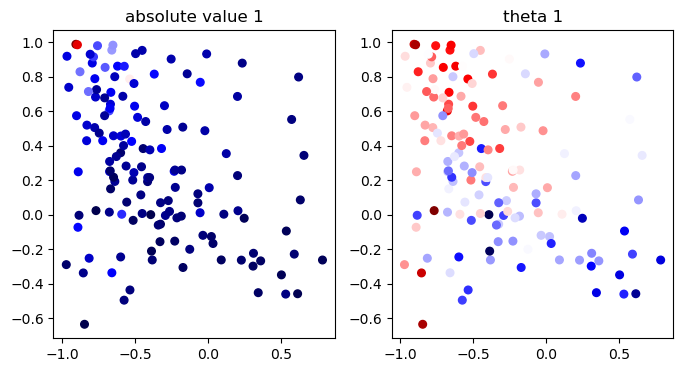

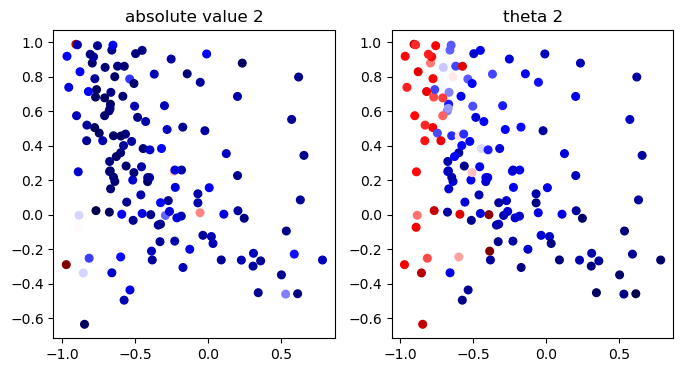

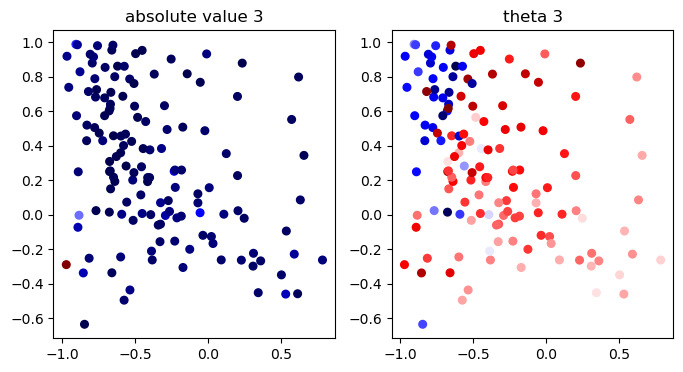

In [63]:
# For each slow mode (slowest first): microstates in the contact plane colored by magnitude (left) and phase (right)
plt.close('all')
for icomp in range(ncomp-1,0-1,-1): #range(ncomp):
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1);plt.scatter(x_clusters[:,0],x_clusters[:,1],s=30,c=va[:,icomp],cmap=plt.cm.seismic)
    plt.title('absolute value '+str(ncomp-icomp))
    plt.subplot(1,2,2);plt.scatter(x_clusters[:,0],x_clusters[:,1],s=30,c=vth[:,icomp],cmap=plt.cm.seismic)
    plt.title('theta '+str(ncomp-icomp))
    plt.savefig(os.path.join(date, f'componentrth_'+str(ncomp-icomp)+'_H_nc'+str(n_clusters)+'_ncomp'+str(ncomp)+'_'+figid+'.png'))
    plt.savefig(os.path.join(date, f'componentrth_'+str(ncomp-icomp)+'_H_nc'+str(n_clusters)+'_ncomp'+str(ncomp)+'_'+figid+'.svg'), format='svg')

### 11.2 Flow in the contact plane

**Flow field.** For each treatment, computes the mean displacement in the contact plane for each microstate from the transition matrix `Mt`, then smooths over the 20 nearest microstates (`dx_clusters_smooth`).

In [64]:
# Flow field per treatment: mean displacement of each microstate in the contact plane expected from its transition matrix Mt,
# then averaged over the knn=20 nearest microstates in the embedding.
dx_clusters=np.zeros((nf,n_clusters,x_clusters.shape[1]))
MtSet=[None]*nf
for i in range(nf):
    indmodels=np.where(inds_tmSet_models==i)[0]
    indstm=np.array([]).astype(int)
    for imodel in indmodels:
        indstm=np.append(indstm,np.where(inds_trajsteps_models==imodel)[0].astype(int))
    x0=x0set[indstm,:]
    x1=x1set[indstm,:]
    Mt=model.get_transition_matrix(x0,x1,clusters_minima)
    MtSet[i]=Mt.copy()
    dxmatrix=np.zeros((n_clusters,n_clusters,x_clusters.shape[1]))
    for ii in range(n_clusters):
        for jj in range(n_clusters):
            dxmatrix[ii,jj]=(x_clusters[jj,:]-x_clusters[ii,:])*Mt[ii,jj]
    dx_clusters[i,:,:]=np.sum(dxmatrix,axis=1)

dx_clusters_smooth=np.zeros_like(dx_clusters)
knn=20
for i in range(nf):
    for iclust in range(n_clusters):
        xc=np.array([clusters_minima.clustercenters[iclust,:]])
        dmatr=utilities.get_dmat(clusters_minima.clustercenters,xc) #get closest cells to cluster center
        indr=np.argsort(dmatr[:,0])
        indr=indr[0:knn]
        dx_clusters_smooth[i,iclust,:]=np.mean(dx_clusters[i,indr,:],axis=0)

**Flow arrows.** Draws the average flow (`dxsav`) as arrows on the contact plane. Saves `dx_clusters_*`.

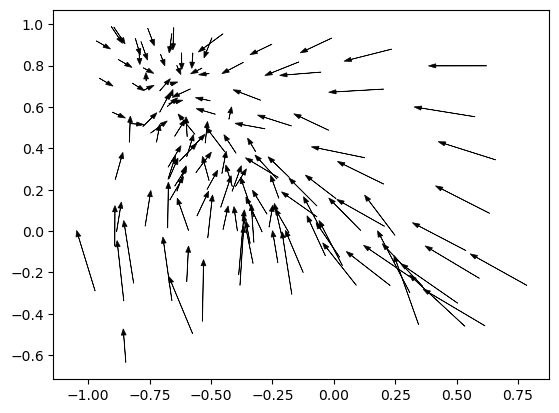

In [65]:
# Flow arrows averaged over treatments (length scaled by ascale)
dxsav=np.mean(dx_clusters_smooth,axis=0)
ascale=.8
ax=plt.gca()
for ic in range(n_clusters):
    ax.arrow(x_clusters[ic,0],x_clusters[ic,1],ascale*dxsav[ic,0],ascale*dxsav[ic,1],head_width=.02,linewidth=.5,color='black',alpha=1.0)

plt.savefig(os.path.join(date, f'dx_clusters'+figid+'.png'))
plt.savefig(os.path.join(date, f'dx_clusters'+figid+'.svg'), format='svg')

plt.pause(.1)
plt.show()

**Time per trajectory point.** Hours since each model's first analysis frame for every trajectory row: `times_traj`, `rep_traj`.

In [67]:
# Hours since each model's first analysis frame for every trajectory row (times_traj) and its imaging set (rep_traj)
times_traj=np.zeros(indframes_traj.size)
rep_traj=np.zeros(indframes_traj.size)
for imodel in indgood_models:
    start_frame=initial_frames_model[imodel]
    timestep=timestep_model[imodel]
    indmodel=np.where(indtreatment_traj==imodel)[0]
    times_traj_model=timestep*(indframes_traj[indmodel]-start_frame)
    times_traj[indmodel]=times_traj_model
    rep_traj[indmodel]=inds_imagingSet_models[imodel]
    sctm=modelSet[imodel]
    print(f'rep {inds_imagingSet_models[imodel]} model {imodel} nframes {np.max(sctm.cells_frameSet)} start {start_frame} {sctm.figid.decode()}')

rep 0 model 0 nframes 48 start 0 20240629_OS17lungInh_RM_xy8_roi0
rep 1 model 1 nframes 48 start 0 20240703_OS17lungInh_RM_xy8_roi0
rep 1 model 2 nframes 48 start 0 20240703_OS17lungInh_RM_xy9_roi0


### 11.3 Population maps: initial, sensitive and resistant cells

To see which regions of the contact plane are enriched among surviving cells, the density of cells is compared between the first and the last window of the experiment.

**Occupancy maps at late times.** For the window 12-16 h, draws a 2-D histogram of where cells are in the contact plane (as a cumulative distribution, `jet_r`): the combined panel with flow arrows, then one panel per treatment. Defines `xedges1`, `yedges1`, `xx`, `yy`, `prob1` used by later plots. Saves `prob_final*`.

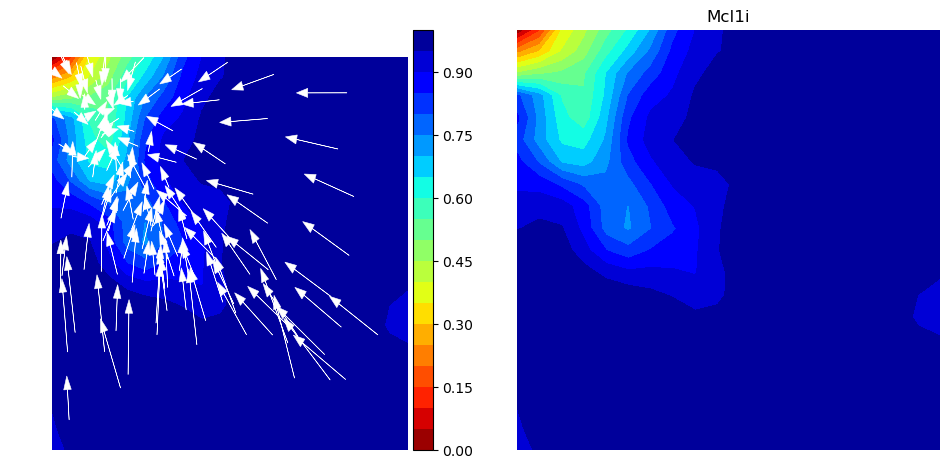

In [68]:
# Occupancy of the contact plane at 12-16 h: smoothed 2-D histogram drawn as a cumulative distribution.
# Panel 1: all cells with the flow arrows; then one panel per treatment. xedges1, yedges1, xx, yy and prob1 are reused later.
plt.close('all') #add legends to scale bar?
head_width=.04
nbins=20
tl=12
tu=16 #hours for time window from times_traj
indstw=np.where(np.logical_and(times_traj<tu,times_traj>tl))[0]
sml=1.
nplots=int(np.ceil(np.sqrt(nf+1)))
plt.figure(figsize=(12,12))
probSet=[None]*nf
plt.subplot(nplots,nplots,1)
prob1,xedges1,yedges1=np.histogram2d(x_clusters_all[indstw,0],x_clusters_all[indstw,1],bins=nbins,density=True)
prob1=scipy.ndimage.gaussian_filter(prob1,sigma=sml)
prob1c=utilities.get_cdist2d(prob1)
xx,yy=np.meshgrid(.5*xedges1[1:]+.5*xedges1[0:-1],.5*yedges1[1:]+.5*yedges1[0:-1])
levels=np.linspace(0,1,21)
cs=plt.contourf(xx,yy,prob1c.T,levels=levels,cmap=plt.cm.jet_r)
cbar=utilities.colorbar(cs)
plt.axis('off')
for ic in range(n_clusters):
    ax=plt.gca()
    ax.arrow(x_clusters[ic,0],x_clusters[ic,1],ascale*dxsav[ic,0],ascale*dxsav[ic,1],head_width=head_width,linewidth=.4,color='white',alpha=1.0)

for imf in range(nf):
    tm=tmSet[imf]
    indstm=inds_conditions[imf]
    indstwm=np.intersect1d(indstm,indstw)
    prob,xedges2,yedges2=np.histogram2d(x_clusters_all[indstwm,0],x_clusters_all[indstwm,1],bins=[xedges1,yedges1],density=True)
    prob=scipy.ndimage.gaussian_filter(prob,sigma=sml)
    probc=utilities.get_cdist2d(prob)
    probSet[imf]=prob.copy()
    plt.subplot(nplots,nplots,imf+2)
    cs=plt.contourf(xx,yy,probc.T,levels=levels,cmap=plt.cm.jet_r,extend='both')
    # (not used; `i` is left over from an earlier loop)
    dxf=dx_clusters_smooth[i,:,:]
    ax=plt.gca()
    plt.title(tmSet[imf])
    cs.cmap.set_over('darkred')
    plt.axis('off')

plt.savefig(os.path.join(date, f'prob_final'+figid+'.png'))
plt.savefig(os.path.join(date, f'prob_final'+figid+'.svg'), format='svg')

**Occupancy maps at early times.** Same as above for the first ~1.5 h. Saves `prob_init*`.

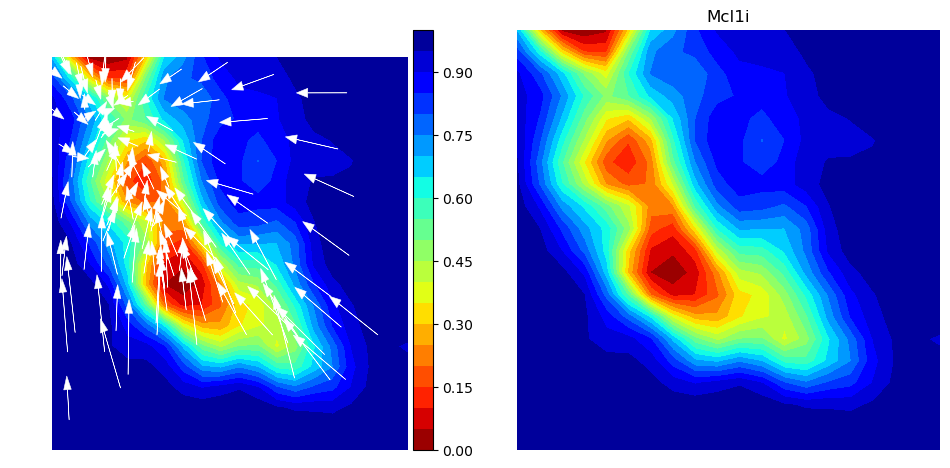

In [69]:
# Same maps for the first window (0 to 0.5*trajl+1 = 1.5 h), on the bins of the previous cell
plt.close('all') #add legends as well. what even is this?
head_width=.04
nbins=20
tl=0
tu=.5*trajl+1 #hours for time window from times_traj
indstw=np.where(np.logical_and(times_traj<tu,times_traj>tl))[0]
sml=1.
nplots=int(np.ceil(np.sqrt(nf+1)))
plt.figure(figsize=(12,12))
probSet=[None]*nf
plt.subplot(nplots,nplots,1)
prob1,xedges2,yedges2=np.histogram2d(x_clusters_all[indstw,0],x_clusters_all[indstw,1],bins=[xedges1,yedges1],density=True)
prob1=scipy.ndimage.gaussian_filter(prob1,sigma=sml)
prob1c=utilities.get_cdist2d(prob1)
xx,yy=np.meshgrid(.5*xedges1[1:]+.5*xedges1[0:-1],.5*yedges1[1:]+.5*yedges1[0:-1])
levels=np.linspace(0,1,21)
cs=plt.contourf(xx,yy,prob1c.T,levels=levels,cmap=plt.cm.jet_r)
cbar=utilities.colorbar(cs)
plt.axis('off')
for ic in range(n_clusters):
    ax=plt.gca()
    ax.arrow(x_clusters[ic,0],x_clusters[ic,1],ascale*dxsav[ic,0],ascale*dxsav[ic,1],head_width=head_width,linewidth=.4,color='white',alpha=1.0)

for imf in range(nf):
    tm=tmSet[imf]
    indstm=inds_conditions[imf]
    indstwm=np.intersect1d(indstm,indstw)
    prob,xedges2,yedges2=np.histogram2d(x_clusters_all[indstwm,0],x_clusters_all[indstwm,1],bins=[xedges1,yedges1],density=True)
    prob=scipy.ndimage.gaussian_filter(prob,sigma=sml)
    probc=utilities.get_cdist2d(prob)
    probSet[imf]=prob.copy()
    plt.subplot(nplots,nplots,imf+2)
    cs=plt.contourf(xx,yy,probc.T,levels=levels,cmap=plt.cm.jet_r,extend='both')
    # (not used)
    dxf=dx_clusters_smooth[i,:,:]
    ax=plt.gca()
    plt.title(tmSet[imf])
    cs.cmap.set_over('darkred')
    plt.axis('off')

plt.savefig(os.path.join(date, f'prob_init'+figid+'.png'))
plt.savefig(os.path.join(date, f'prob_init'+figid+'.svg'), format='svg')

**Initial, sensitive and resistant populations in the contact plane.** For each treatment, estimates the density of cells in the contact plane at the start of imaging, at the end of the analysis window minus 8 frames (resistant cells) and at death (sensitive cells; shown as crosses), and plots the initial density, the final density and their difference. The loop is run three times - restricted to ERK-on cells, to ERK-off cells, and for all cells - saving `distributions_{erkon_wpoints|erkoff_wpoints|erkall_wpoints}_*`. After the loop the `pinitialSet`, `psensitiveSet` and `presistantSet` variables hold the all-cell result, which the following cells use.

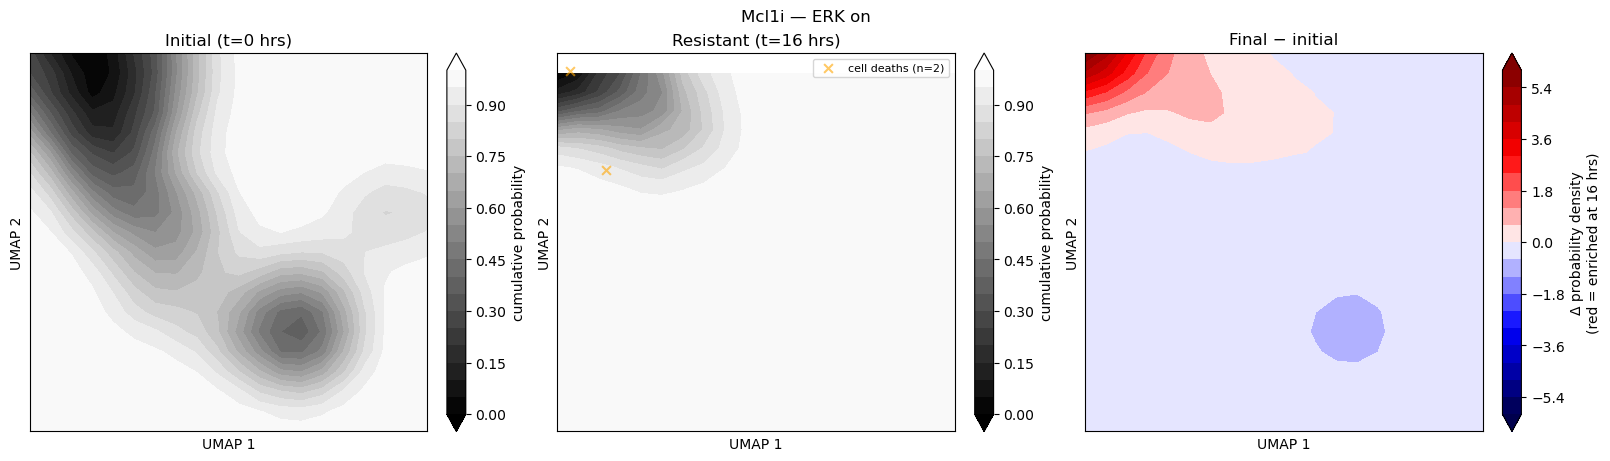

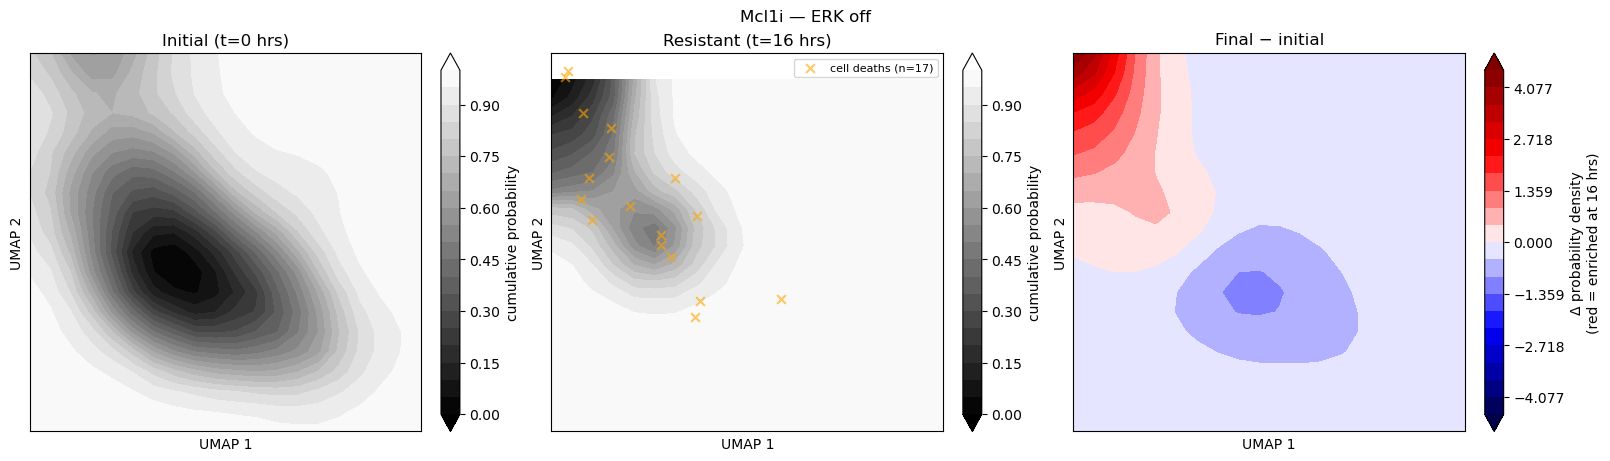

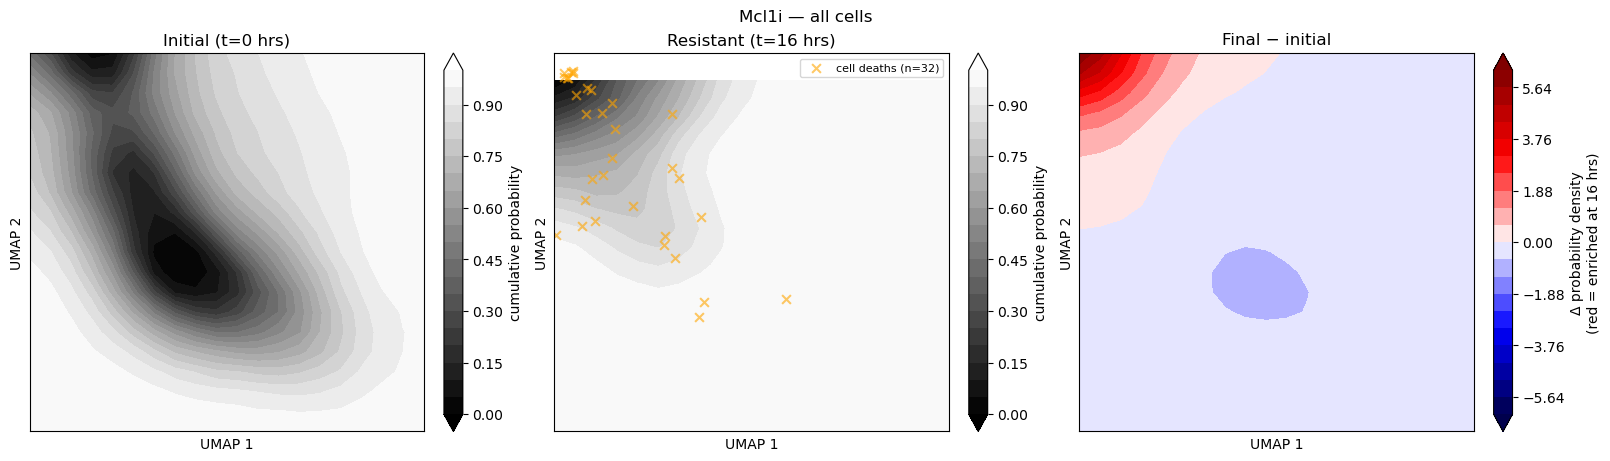

In [70]:
# Initial, resistant and sensitive (dying) populations in the contact plane per treatment, for ERK-on, ERK-off and all cells.
# initial = first fw frames of the window, resistant = last fw frames before (final frame - 8), sensitive = points at death.
#plot initial, persistor, sensitive populations
sml=2.
head_width=.04
indsetList=[]
captionset=['initial','sensitive','resistant']
nf=len(tmSet)
nbins=20
fw=trajl+2
levels=np.linspace(0,1,21)

# bin centers / grid for contour plots
xedges1c=.5*(xedges1[1:]+xedges1[0:-1])
yedges1c=.5*(yedges1[1:]+yedges1[0:-1])
xx,yy=np.meshgrid(xedges1c,yedges1c)

# title text for each ERK filter
erk_labels={'on':'ERK on','off':'ERK off',None:'all cells'}

for erk_filter,tag,show_deaths in [('on','erkon_wpoints',True),
                                   ('off','erkoff_wpoints',True),
                                   (None,'erkall_wpoints',True)]:
    pinitialSet=[None]*nf
    psensitiveSet=[None]*nf
    presistantSet=[None]*nf
    inds_death_traj_set=[None]*nf
    times_death_traj_set=[None]*nf

    for i_tm in range(nf):
        indmodels=np.where(inds_tmSet_models==i_tm)[0]
        inds_death_traj=[]
        inds_initial_traj=[]
        inds_resistant_traj=[]
        times_death_traj=[]
        for imodel in indmodels:
            fl=initial_frames_model[imodel]
            fu=final_frames_model[imodel]-8 #frames for time window
            indstw=np.where(np.logical_and(indframes_traj>fl,indframes_traj<fu))[0]
            indcells_traj_model=np.where(indtreatment_traj==imodel)[0]
            indcells_traj_model=np.intersect1d(indcells_traj_model,indstw)
            # optional ERK filter on the ERK ratio of the segment's last cell
            if erk_filter=='on':
                indcells_traj_model=np.intersect1d(indcells_traj_model,np.where(cratio_erk_traj>midcut)[0])
            elif erk_filter=='off':
                indcells_traj_model=np.intersect1d(indcells_traj_model,np.where(cratio_erk_traj<midcut)[0])
            cellinds1_traj_model=cellinds1_traj[indcells_traj_model]
            sctm=modelSet[imodel]
            if hasattr(sctm,'inds_death'):
                cellinds_death=sctm.inds_death.copy()
            else:
                cellinds_death=np.array([]).astype(int)
            # segments that end in a validated death
            death_mask=np.isin(cellinds1_traj_model,cellinds_death)
            inds_death_traj.append(indcells_traj_model[death_mask])
            times_death_traj.append(times_traj[indcells_traj_model[death_mask]])
            inds_initial_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fl+fw,indframes_traj>fl))[0],indcells_traj_model))
            inds_resistant_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fu,indframes_traj>fu-fw))[0],indcells_traj_model))

        inds_death_traj=np.concatenate(inds_death_traj)
        times_death_traj=np.concatenate(times_death_traj)
        inds_initial_traj=np.concatenate(inds_initial_traj)
        inds_resistant_traj=np.concatenate(inds_resistant_traj)
        inds_death_traj_set[i_tm]=inds_death_traj.copy()
        times_death_traj_set[i_tm]=times_death_traj.copy()

        # smoothed 2-D densities on the common bins
        prob_initial,_,_=np.histogram2d(x_clusters_all[inds_initial_traj,0],x_clusters_all[inds_initial_traj,1],bins=[xedges1,yedges1],density=True)
        prob_initial=scipy.ndimage.gaussian_filter(prob_initial,sigma=sml)
        prob_death,_,_=np.histogram2d(x_clusters_all[inds_death_traj,0],x_clusters_all[inds_death_traj,1],bins=[xedges1,yedges1],density=True)
        prob_death=scipy.ndimage.gaussian_filter(prob_death,sigma=sml)
        prob_resistant,_,_=np.histogram2d(x_clusters_all[inds_resistant_traj,0],x_clusters_all[inds_resistant_traj,1],bins=[xedges1,yedges1],density=True)
        prob_resistant=scipy.ndimage.gaussian_filter(prob_resistant,sigma=sml)

        pinitialSet[i_tm]=prob_initial.copy()
        psensitiveSet[i_tm]=prob_death.copy()
        presistantSet[i_tm]=prob_resistant.copy()

    for i_tmr in range(nf):
        fig,axs=plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)

        # panel 1: initial population
        cs0=axs[0].contourf(xx,yy,utilities.get_cdist2d(pinitialSet[i_tmr]).T,levels=levels,cmap=plt.cm.binary_r,extend='both')
        axs[0].set_title('Initial (t=0 hrs)')
        fig.colorbar(cs0,ax=axs[0],label='cumulative probability')

        # panel 2: resistant population + deaths
        cs1=axs[1].contourf(xx,yy,utilities.get_cdist2d(presistantSet[i_tmr]).T,levels=levels,cmap=plt.cm.binary_r,extend='both')
        axs[1].set_title('Resistant (t=16 hrs)')
        fig.colorbar(cs1,ax=axs[1],label='cumulative probability')
        if show_deaths:
            idx=inds_death_traj_set[i_tmr]
            axs[1].scatter(x_clusters_all[idx,0],x_clusters_all[idx,1],s=40,c='orange',marker='x',alpha=.6,
                           label=f'cell deaths (n={idx.size})')
            axs[1].legend(loc='upper right',fontsize=8,framealpha=.8)

        # panel 3: difference, symmetric levels scaled to the data
        diff=presistantSet[i_tmr].T-pinitialSet[i_tmr].T
        m=np.nanmax(np.abs(diff))
        if not np.isfinite(m) or m==0:
            m=1.
        cs2=axs[2].contourf(xx,yy,diff,levels=np.linspace(-m,m,21),cmap=plt.cm.seismic,extend='both')
        axs[2].set_title('Final − initial')
        fig.colorbar(cs2,ax=axs[2],label='Δ probability density\n(red = enriched at 16 hrs)')

        # the axes are the contact-plane coordinates, although they are labeled UMAP
        for ax in axs:
            ax.set_xlabel('UMAP 1')
            ax.set_ylabel('UMAP 2')
            ax.set_xticks([])
            ax.set_yticks([])

        fig.suptitle(f'{tmSet[i_tmr]} — {erk_labels[erk_filter]}')
        plt.savefig(os.path.join(date, f'distributions_{tag}_{tmSet[i_tmr]}_{figid}.png'))
        plt.savefig(os.path.join(date, f'distributions_{tag}_{tmSet[i_tmr]}_{figid}.svg'), format='svg')
        plt.show()

### 11.4 Kinetic states

The first cell scans the number of kinetic states (to justify choosing three), then the final states are computed, ordered and labeled. `get_kstates=False` loads the manuscript state definition (`manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj`) instead of recomputing it.

**Choosing the number of kinetic states.** For 2 to 30 states, clusters the microstates on `vkin`, builds the coarse-grained transition matrix per treatment, and records the kinetic score. Plots the state map for each setting and pauses 2 s per step, so it takes a while. Fills `scoreSet_states`. The scan stops with a ValueError once the number of initial clusters exceeds the number of microstates (as in the saved run); the scores computed up to then are kept.

[0.00724638 0.99275362]
2 states initial, 1 states final
[0.00724638 0.26086957 0.73188406]
3 states initial, 2 states final
building likelihood model for Mcl1i
2 states
[2.79999016]


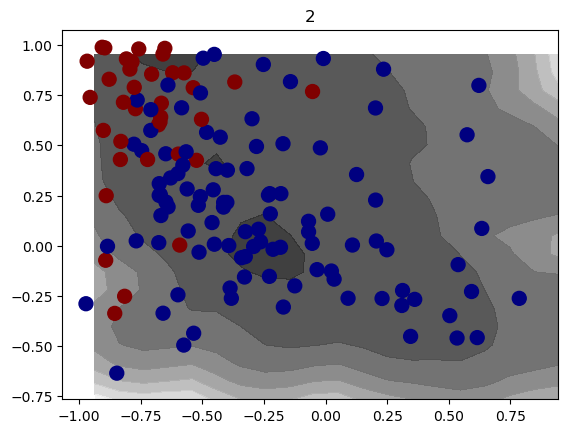

[0.00724638 0.01449275 0.31884058 0.65942029]
4 states initial, 2 states final
[0.00724638 0.01449275 0.15217391 0.20289855 0.62318841]
5 states initial, 3 states final
building likelihood model for Mcl1i
3 states
[5.05672418]


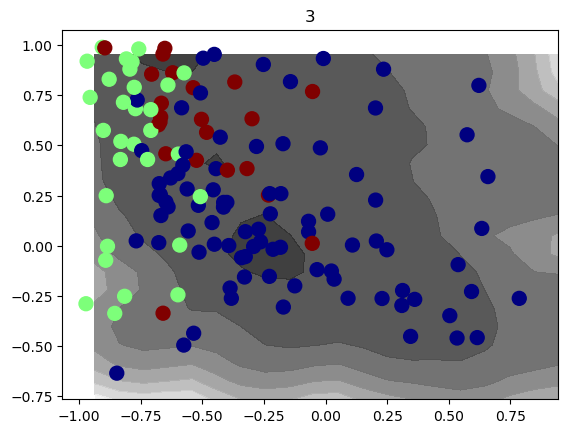

[0.00724638 0.01449275 0.01449275 0.15217391 0.20289855 0.60869565]
6 states initial, 3 states final
[0.00724638 0.01449275 0.01449275 0.02898551 0.15217391 0.15942029
 0.62318841]
7 states initial, 3 states final
[0.00724638 0.00724638 0.01449275 0.02898551 0.04347826 0.13043478
 0.34057971 0.42753623]
8 states initial, 3 states final
[0.00724638 0.00724638 0.00724638 0.01449275 0.02898551 0.0942029
 0.13043478 0.33333333 0.37681159]
9 states initial, 4 states final
building likelihood model for Mcl1i
4 states
[6.15501219]


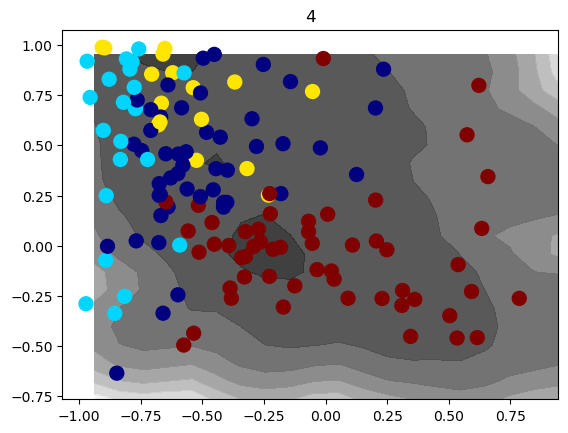

[0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.0942029  0.13043478 0.32608696 0.39130435]
10 states initial, 4 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.08695652 0.13043478 0.13043478 0.27536232 0.31884058]
11 states initial, 5 states final
building likelihood model for Mcl1i
5 states
[7.82386464]


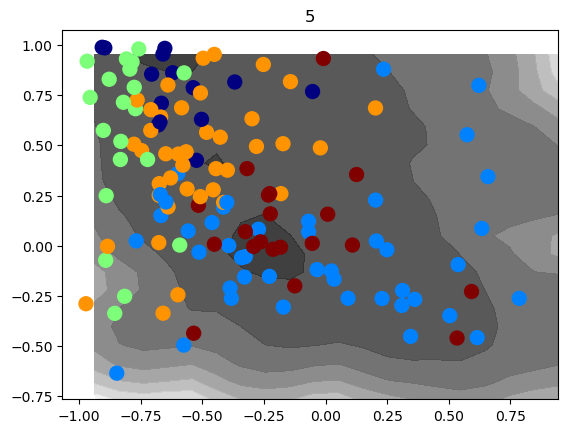

[0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.03623188 0.08695652 0.12318841 0.17391304 0.20289855 0.31884058]
12 states initial, 5 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.01449275 0.03623188 0.08695652 0.11594203 0.17391304 0.19565217
 0.31884058]
13 states initial, 5 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.01449275 0.03623188 0.03623188 0.10869565 0.11594203 0.15942029
 0.16666667 0.30434783]
14 states initial, 5 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.03623188 0.03623188 0.10869565 0.11594203
 0.15942029 0.16666667 0.30434783]
15 states initial, 5 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.02898551 0.04347826 0.07971014
 0.08695652 0.15942029 0.1884058  0.32608696]
16 states initial, 5 states final
[0.00724638 0.00724638 0.00724638 0.00724

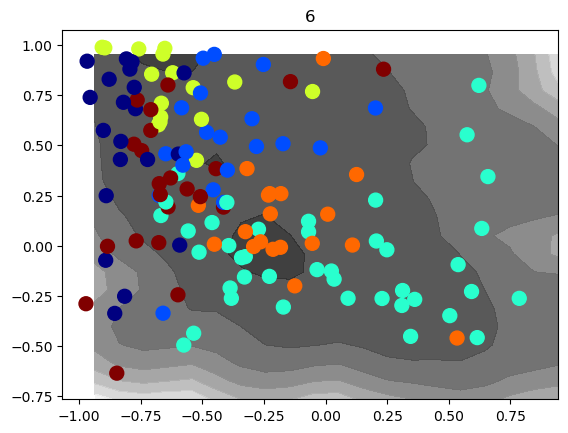

[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.03623188 0.03623188 0.07971014
 0.08695652 0.0942029  0.11594203 0.13043478 0.15217391 0.18115942]
18 states initial, 7 states final
building likelihood model for Mcl1i
7 states
[11.30370643]


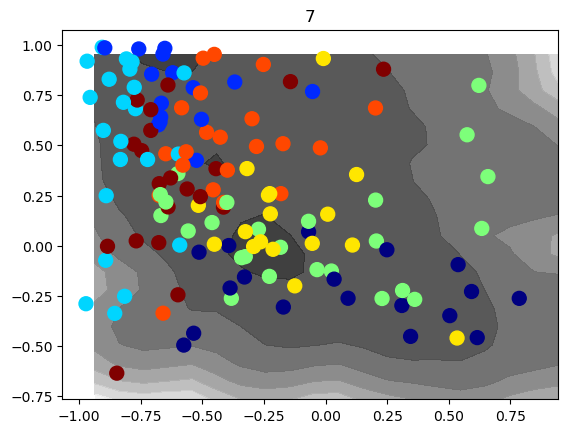

[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.02173913 0.02898551 0.03623188
 0.07971014 0.07971014 0.08695652 0.0942029  0.12318841 0.13043478
 0.23188406]
19 states initial, 7 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.02173913 0.02898551 0.03623188
 0.04347826 0.05797101 0.05797101 0.0942029  0.12318841 0.13043478
 0.13768116 0.18115942]
20 states initial, 7 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.02173913 0.02898551 0.03623188
 0.05072464 0.06521739 0.07246377 0.07246377 0.07971014 0.10869565
 0.10869565 0.11594203 0.15217391]
21 states initial, 9 states final
building likelihood model for Mcl1i
8 states
[11.52533361]


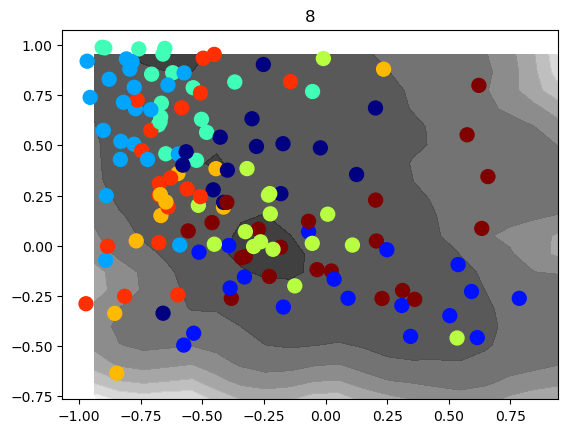

[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.01449275 0.01449275 0.02173913 0.02898551
 0.03623188 0.05072464 0.05072464 0.06521739 0.06521739 0.07246377
 0.0942029  0.11594203 0.12318841 0.17391304]
22 states initial, 9 states final
building likelihood model for Mcl1i
9 states
[14.17999341]


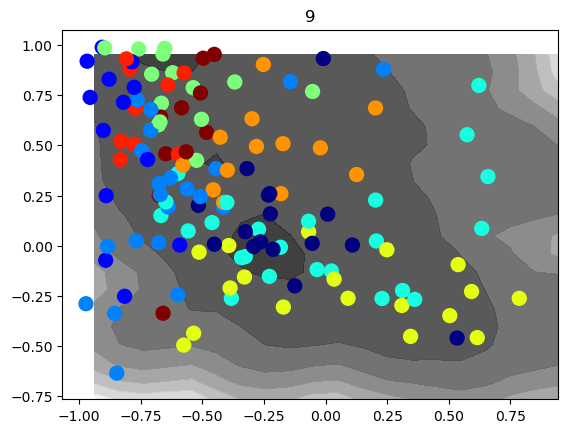

[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.01449275 0.01449275 0.02173913 0.02898551
 0.03623188 0.04347826 0.04347826 0.05072464 0.05797101 0.06521739
 0.08695652 0.10144928 0.10869565 0.11594203 0.15217391]
23 states initial, 8 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275 0.02173913
 0.02898551 0.03623188 0.04347826 0.04347826 0.05797101 0.05797101
 0.06521739 0.07246377 0.0942029  0.11594203 0.11594203 0.15217391]
24 states initial, 8 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.00724638 0.00724638 0.01449275 0.01449275
 0.02173913 0.02173913 0.03623188 0.04347826 0.05072464 0.05797101
 0.06521739 0.07246377 0.07246377 0.0942029  0.10869565 0.11594203
 0.13768116]
25 states initial, 9 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 

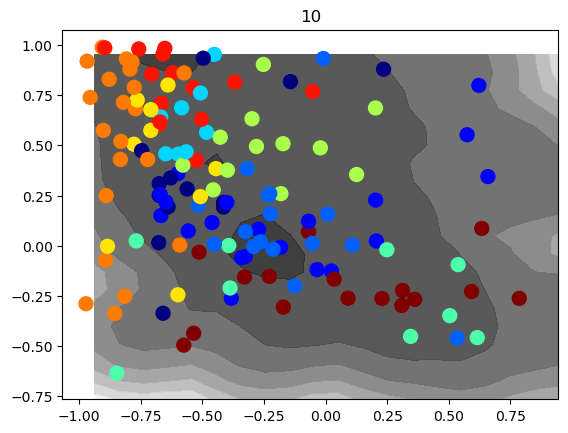

[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.01449275 0.01449275 0.02173913 0.02173913 0.03623188 0.03623188
 0.04347826 0.04347826 0.04347826 0.05072464 0.05072464 0.07246377
 0.08695652 0.10144928 0.11594203 0.15942029]
28 states initial, 7 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.01449275
 0.01449275 0.01449275 0.01449275 0.02173913 0.02173913 0.02173913
 0.03623188 0.04347826 0.04347826 0.05072464 0.05797101 0.06521739
 0.07246377 0.07246377 0.07971014 0.11594203 0.15942029]
29 states initial, 8 states final
[0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638 0.00724638
 0.00724638 0.00724638 0.01449275 0.01449275 0.02173913 0.02173913
 0.02898551 0.02898551 0.04347826 0.04347826 0.05072464 0.05072464
 0.05072464 0.07246377 0.

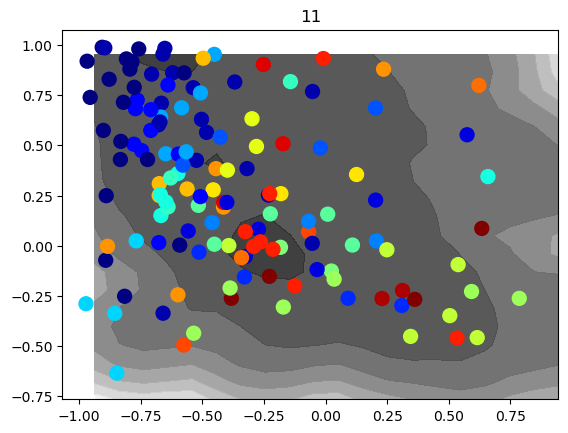

UnboundLocalError: local variable 'state_probs' referenced before assignment

In [71]:
# Scan of the number of kinetic states (2-30): cluster the microstates on vkin, build the coarse-grained transition matrix
# per treatment and record its kinetic score (sum of implied timescales); shows the state map at each step.
# Only needed to make new states. The scan raises a ValueError once the number of initial clusters exceeds the number of microstates.
plt.close('all') #only run to make fresh states
plt.clf()
nstateSet=[2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,18,20,22,24,28,30] #,30,40]
nS=len(nstateSet)
scoreSet_states=[None]*nS
nstates_initial=nstateSet[0]
pcut_final=.05
indc_x0set=clusters_minima.assign(x0set);indc_x1set=clusters_minima.assign(x1set)
for istate in range(len(nstateSet)):
    MtSet_test=[None]*nf
    nstates=nstateSet[istate]
    scoreSet=np.zeros(nf)
    states,nstates_initial=model.get_kineticstates(vkin,nstates,nstates_initial=nstates_initial,pcut_final=pcut_final,seed=0,return_nstates_initial=True,cluster_ninit=100)
    for imf in range(nf):
        print('building likelihood model for '+tmSet[imf])
        indmodels=np.where(inds_tmSet_models==imf)[0]
        indmodels=np.intersect1d(indmodels,indgood_models)
        indstm=np.array([]).astype(int)
        for i in indmodels: #[:-1]:
            indstm=np.append(indstm,np.where(inds_trajsteps_models==i)[0])
        MtSet_test[imf]=model.get_transition_matrix_CG(x0set[indstm,:],x1set[indstm,:],clusters=clusters_minima,states=states)
        scoreSet[imf]=model.get_kscore(MtSet_test[imf])
    print(str(nstates)+' states')
    print(scoreSet)
    nstates_initial=nstates_initial+1
    scoreSet_states[istate]=scoreSet
    plt.clf()
    plt.contourf(xx,yy,-np.log(prob1.T),cmap=plt.cm.gray,alpha=0.8)
    plt.scatter(x_clusters[:,0],x_clusters[:,1],s=100,c=states,cmap=plt.cm.jet)
    plt.title(str(nstates))
    plt.pause(2)

**Score vs number of states.** Plots the kinetic score per treatment plus the mean to pick the number of states (3 is used below). Saves `scoreset_{figid}`.

/tmp/ipykernel_33583/1007178872.py:22: RuntimeWarning: Mean of empty slice
  plt.plot(nstateSet, np.nanmean(scoreSet_statearray, axis=1), 'o--', color='black', linewidth=2)


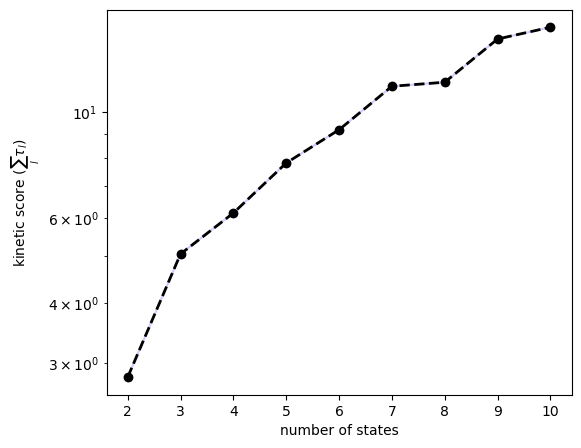

<Figure size 640x480 with 0 Axes>

In [72]:
# Kinetic score vs number of states per treatment (faint) and the mean (black dashed); used to choose nstates_final=3
scoreSet_statearray = np.zeros((nS, nf))

# Populate scoreSet_statearray with data from scoreSet_states
for istate in range(len(nstateSet)):
    try:
        scoreSet_statearray[istate, :] = scoreSet_states[istate]
    except:
        pass  # Skip if there is an issue

# Close any existing plots and create a new figure
plt.close('all')
plt.figure(figsize=(6, 5))
plt.clf()

# Plot data for each treatment with the appropriate color
for imf in range(nf):
    color = colorSet[imf]  # Use color mapping or default to 'grey'
    plt.plot(nstateSet, scoreSet_statearray[:, imf], 'o-', color=color, label=tmSet[imf], alpha=0.2)

# Plot the mean score across all treatments
plt.plot(nstateSet, np.nanmean(scoreSet_statearray, axis=1), 'o--', color='black', linewidth=2)

# Set y-axis to a logarithmic scale and add labels
plt.yscale('log')
plt.ylabel(r'kinetic score ($\sum_l \tau_l$)')
plt.xlabel('number of states')
plt.pause(0.1)

# Save the figure
plt.savefig(os.path.join(date, f'scoreset_{figid}.png'))
plt.savefig(os.path.join(date, f'scoreset_{figid}.svg'), format='svg')

# Display the plot
plt.show()

**Final kinetic states.** Clusters the microstates into `nstates_final=3` kinetic states (`stateSet`), pickles `[clusters_minima, stateSet]` to `{date}/stateSet_*_nS3.obj`, and computes each state's median center. The `else` branch loads the manuscript state file instead and keeps the entries of the microstates in the largest connected component (`indcc`).

In [73]:
# Final kinetic states: computed and pickled with get_kstates=True; otherwise loaded from the manuscript state file and restricted
# to the microstates of the largest connected component (indcc). Then the median center of each state in the contact plane.
get_kstates=False
nstates_final=3 #for production
pcut_final=.05 #for prediction
nstates_initial=nstates_final
stateCenters=x_clusters
if get_kstates:
    stateSet=model.get_kineticstates(vkin,nstates_final,nstates_initial=nstates_initial,pcut_final=pcut_final,seed=0,return_nstates_initial=False,cluster_ninit=100)
    nstates=np.unique(stateSet).size
    objFile=f'{date}/stateSet_{figid}_nS{nstates}.obj'
    objFileHandler=open(objFile,'wb')
    states_object=[clusters_minima,stateSet]
    pickle.dump(states_object,objFileHandler,protocol=4)
    objFileHandler.close()
else:
    objFile=f'manuscript_analysis_files/stateSet_SITE_mml1_trajl1__nS3.obj'
    objFileHandler=open(objFile,'rb')
    states_object=pickle.load(objFileHandler)
    clusters_minima_manuscript=states_object[0]
    stateSet=states_object[1]
    # keep the microstates of the largest connected component
    stateSet=stateSet[indcc]
    objFileHandler.close()

nstates=np.unique(stateSet).size; n_states=nstates
state_centers_minima=np.zeros((n_states,x_clusters.shape[1]))
for i in range(n_states):
    indstate=np.where(stateSet==i)[0]
    state_centers_minima[i,:]=np.median(stateCenters[indstate,:],axis=0)

**Order and label the kinetic states.** Orders the states by the mean distance of their cells to cancer cells, ascending (so the labels A, B, C are consistent) and builds `inds_states[i]`, the trajectory points belonging to state i, and the state centers.

In [74]:
# Order the kinetic states so the labels are reproducible: by the mean distance of their cells to cancer cells (ascending,
# treatments in tm_include), so A is closest to cancer cells. Then recompute the state centers and the points of each state.
inds_states=[None]*n_states
for i in range(n_states):
    indstate=np.where(stateSet[ind_clusters]==i)[0]
    inds_states[i]=indstate

# Step 1: mean distance to cancer cells per state (the variable is called `activity` for historical reasons)
activity = np.nanmean(cancer_dist_full_traj,axis=1)
mean_activity = []
tm_include=[0,1]
for i in range(n_states):
    inds_traj=inds_states[i]
    inds_traj=inds_traj[np.isin(inds_tmSet_models[indtreatment_traj[inds_traj]],tm_include)]
    setv = activity[inds_traj]
    indgood=np.where(np.isfinite(setv))[0]
    setv = setv[indgood]
    mean_activity.append(np.mean(setv))

# Step 2: order the states by that mean
state_order = np.argsort(mean_activity)
stateSet_ordered=np.ones_like(stateSet)*-1
for istate in range(nstates):
    stateSet_ordered[stateSet==state_order[istate]]=istate

stateSet=stateSet_ordered

nstates=np.unique(stateSet).size; n_states=nstates
state_centers_minima=np.zeros((n_states,x_clusters.shape[1]))
for i in range(n_states):
    indstate=np.where(stateSet==i)[0]
    state_centers_minima[i,:]=np.nanmedian(stateCenters[indstate,:],axis=0)

inds_states=[None]*n_states
for i in range(n_states):
    indstate=np.where(stateSet[ind_clusters]==i)[0]
    inds_states[i]=indstate

**State map.** Shows the microstates colored by kinetic state with letter labels (A, B, C). Defines `state_labels`. Saves `nstates_{figid}`.

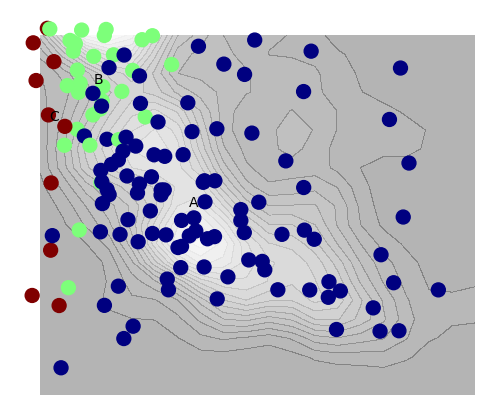

In [75]:
# Microstates in the contact plane colored by kinetic state, with the letter labels at the state centers
nbins=prob1.shape[0] #legend
state_labels=np.array(list(string.ascii_uppercase))[0:nstates]
plt.close('all');plt.figure(figsize=(6,5))
plt.clf()
pts=np.array([xx.flatten(),yy.flatten()]).T
plt.contourf(xx,yy,prob1.T,cmap=plt.cm.gray,levels=20,alpha=.3)
plt.scatter(x_clusters[:,0],x_clusters[:,1],s=100,c=stateSet,cmap=plt.cm.jet)

for istate in range(nstates):
    plt.text(state_centers_minima[istate,0],state_centers_minima[istate,1],str(state_labels[istate]))

plt.axis('off')
plt.savefig(os.path.join(date, f'nstates_{figid}.png'))
plt.savefig(os.path.join(date, f'nstates_{figid}.svg'), format='svg')
plt.pause(.1)

**All points colored by state.** Scatter of every trajectory point in the contact plane. Saves `states_all_{figid}`.

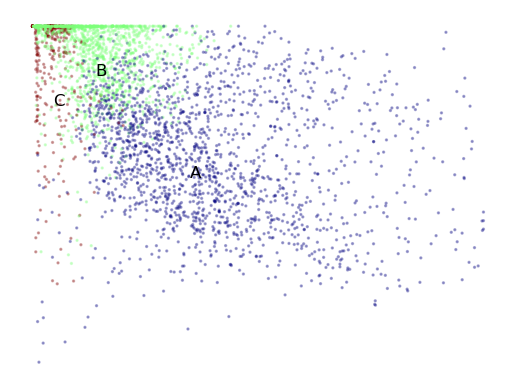

In [76]:
# Every trajectory point in the contact plane colored by its kinetic state
plt.scatter(x_clusters_all[:,0],x_clusters_all[:,1],s=2,c=stateSet[ind_clusters],cmap=plt.cm.jet,alpha=.3)
for istate in range(nstates):
    plt.text(state_centers_minima[istate,0],state_centers_minima[istate,1],str(state_labels[istate]),size='large')

plt.axis('off')
plt.savefig(os.path.join(date, f'states_all_{figid}.png'))
plt.savefig(os.path.join(date, f'states_all_{figid}.svg'), format='svg')
plt.pause(.1)

**Resistant-minus-initial density with the kinetic states overlaid.** One figure per treatment showing P_resistant - P_initial in the contact plane, with the kinetic states labeled. Saves `resistant_dist_*`.

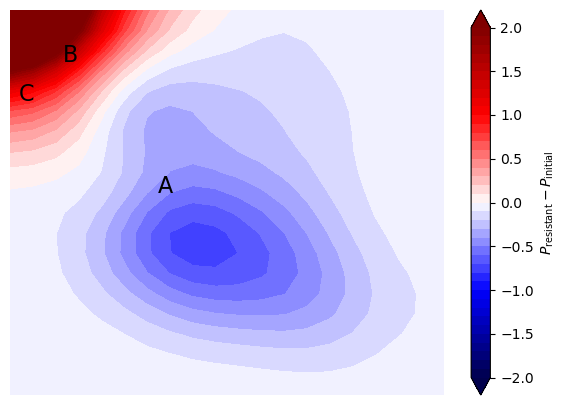

In [77]:
# Per treatment: resistant minus initial density (from the 'all cells' run above) with the kinetic-state labels
levels=np.linspace(0,1,41) #what is this legend
for i_tmr in range(len(tmSet)):
    plt.figure(figsize=(7,5))
    plt.gca()
    cs=plt.contourf(xx,yy,presistantSet[i_tmr].T-pinitialSet[i_tmr].T,levels=4.*(levels-.5),cmap=plt.cm.seismic,extend='both')
    plt.axis('off')
    cbar=plt.colorbar()
    cbar.set_label(r'$P_{\mathrm{resistant}}-P_{\mathrm{initial}}$')
    for istate in range(nstates):
        plt.text(state_centers_minima[istate,0],state_centers_minima[istate,1],str(state_labels[istate]),fontsize=16,fontstyle='normal')

    plt.savefig(os.path.join(date, f'resistant_dist_{tmSet[i_tmr]}_{figid}.png'))
    plt.savefig(os.path.join(date, f'resistant_dist_{tmSet[i_tmr]}_{figid}.svg'), format='svg')

## 12. Characterization of the kinetic states

What each kinetic state looks like: example cells, occupancy over time, time-resolved feature maps, state-resolved distributions of signaling, contact and shape features, and time of death by state.

**Function `show_cell_activation`.** Draws a single cell's cropped image (reporter, nucleus, brightfield) with its mask outline, either as the brightest z slice or a max projection.

In [78]:
# Plot one cell: brightfield (difference of Gaussians), reporter overlay inside the cell mask (inferno) and the mask outline.
# projection=True uses max projections, otherwise the z slice with the brightest nucleus. Returns 0 on success.
def show_cell_activation(self,icell,cyto_msk_channel=None,rep_img_channel=None,nuc_img_channel=None,bf_img_channel=None,viewsize=50,npix=100,sigma=3.,zoom=2,nuchigh=None,nuclow=None,rephigh=None,replow=None,bflow=None,bfhigh=None,projection=True,show_neighbor_signals=False):
    if cyto_msk_channel is None:
        cyto_msk_channel=self.mskchannel
        if rep_img_channel is None:
            rep_img_channel=self.rep_channel
        if nuc_img_channel is None:
            nuc_img_channel=self.nuc_channel
        if bf_img_channel is None:
            bf_img_channel=self.bf_channel
    if True: #try:
        imgc,mskc=self.get_cell_data(icell,relabel_mskchannels=[0],boundary_expansion=[1,viewsize,viewsize])
        imgc2,mskc2=self.get_cell_data(icell,relabel_mskchannels=[],boundary_expansion=[1,viewsize,viewsize])
        if not projection:
            mslices=np.where(np.sum(mskc[...,cyto_msk_channel],axis=(1,2))>0)[0]
            hslice=np.argmax(np.sum(imgc[mslices,:,:,nuc_img_channel],axis=(1,2)))
            islice=mslices[hslice]
            img_rep=imprep.znorm(imgc[islice,:,:,rep_img_channel]).astype(float)
            img_nuc=imprep.znorm(imgc[islice,:,:,nuc_img_channel]).astype(float)
            img_bf=skimage.filters.difference_of_gaussians(imgc[...,bf_img_channel],.5,1.5)
            img_bf=imprep.znorm(img_bf[islice,:,:]).astype(float)
            msk_cyto=mskc[islice,:,:,cyto_msk_channel]
            msk2_cyto=mskc2[islice,:,:,cyto_msk_channel]
        else:
            img_rep=np.max(imprep.znorm(imgc[:,:,:,rep_img_channel]).astype(float),axis=0)
            img_nuc=np.max(imprep.znorm(imgc[:,:,:,nuc_img_channel]).astype(float),axis=0)
            img_bf=skimage.filters.difference_of_gaussians(imgc[...,bf_img_channel],.5,1.5)
            img_bf=np.max(imprep.znorm(img_bf[:,:,:]).astype(float),axis=0)
            msk_cyto=np.max(mskc[:,:,:,cyto_msk_channel],axis=0)
            msk2_cyto=np.max(mskc2[:,:,:,cyto_msk_channel],axis=0)
        if nuchigh is None:
            nuclow=np.percentile(img_nuc,5);nuchigh=np.percentile(img_nuc,95)
        img_bf=np.abs(img_bf)
        img_rep=scipy.ndimage.zoom(img_rep,zoom,order=1)
        img_rep=scipy.ndimage.gaussian_filter(img_rep,sigma)
        img_nuc=scipy.ndimage.zoom(img_nuc,zoom,order=1)
        img_nuc=scipy.ndimage.gaussian_filter(img_nuc,sigma)
        img_bf=scipy.ndimage.zoom(img_bf,zoom,order=1)
        if rephigh is None:
            replow=np.percentile(img_rep,5);rephigh=np.percentile(img_rep,95)
        if bfhigh is None:
            bflow=np.percentile(img_bf,5);bfhigh=np.percentile(img_bf,95)
        msk_cyto=scipy.ndimage.zoom(msk_cyto,zoom,order=1)
        msk2_cyto=scipy.ndimage.zoom(msk2_cyto,zoom,order=1)
        plt.imshow(img_bf,cmap=plt.cm.binary,clim=(bflow,bfhigh),alpha=1.)
        if show_neighbor_signals:
            plt.imshow(np.ma.masked_where(msk2_cyto==0,img_rep),cmap=plt.cm.inferno,alpha=.3)
        plt.imshow(np.ma.masked_where(msk_cyto==0,img_rep),cmap=plt.cm.inferno,alpha=.7)
        csn=plt.contour(msk_cyto>0,levels=np.unique(msk_cyto>0),colors='darkorange',linewidths=2)
        csn.cmap.set_over('darkred')
        csn.cmap.set_under('white')
        plt.axis('off')
        return 0
    else: #except Exception as e:
        print(e)
    return 1

**Example cells per state.** For each treatment and for several rounds, picks a random cell from each kinetic state and plots it with `show_cell_activation`. Saves into `{date}/cellstatepics`.

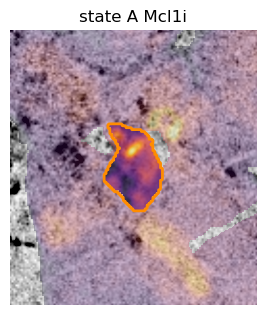

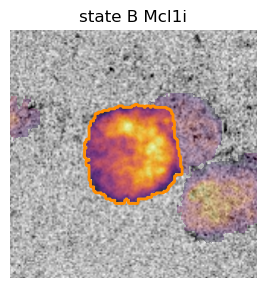

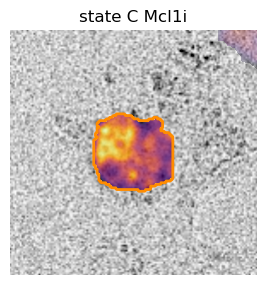

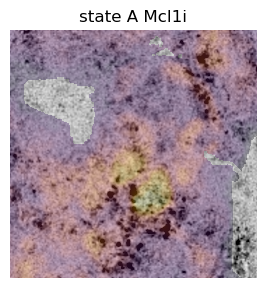

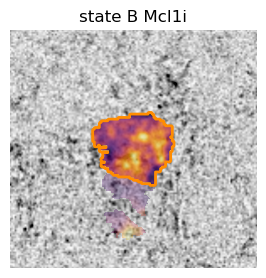

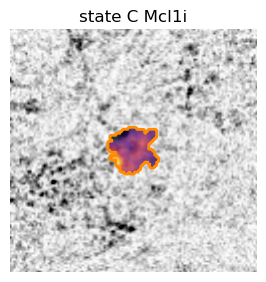

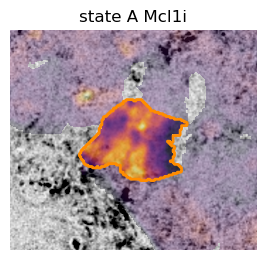

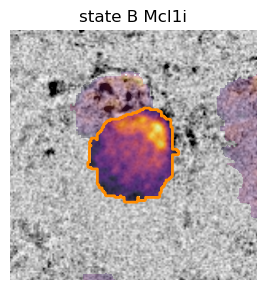

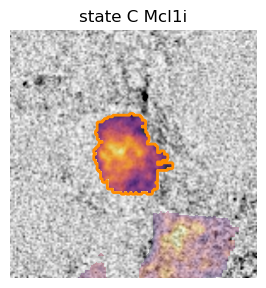

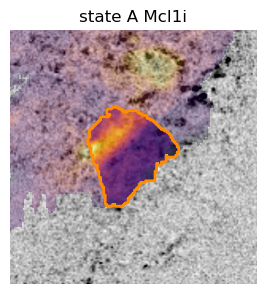

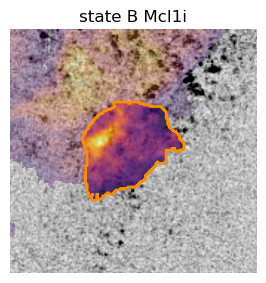

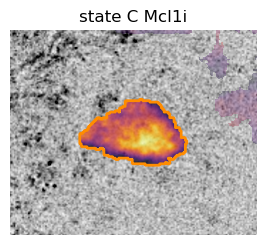

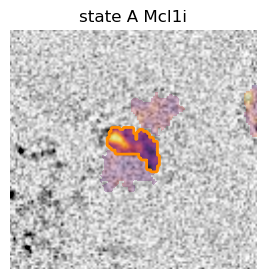

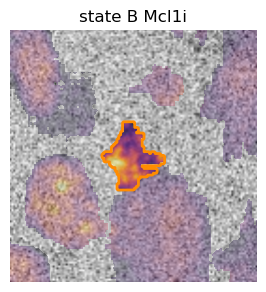

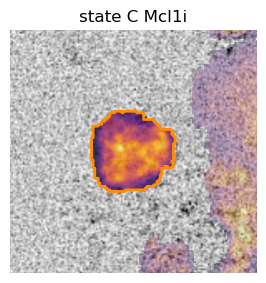

In [79]:
# Example cells: for every treatment and each of nrounds rounds, pick nr random points from each kinetic state and plot the cell.
# Images go to {date}/cellstatepics. (Reuses the name nr from Section 7.)
nrounds=5
nr=1
maxl=trajl
stordir='cellstatepics'
os.system(f'mkdir -p {date}/{stordir}')
nuclow=-1.;nuchigh=9.;replow=0.;rephigh=5.;bflow=0.;bfhigh=5.
npics=1
for i_tm in range(nf):
    indmodels_tm=np.where(inds_tmSet_models==i_tm)[0]
    for iround in range(nrounds):
        plt.close('all')
        for istate in range(nstates):
            indcells_traj=inds_states[istate]
            indmodels=indtreatment_traj[indcells_traj]
            indtm=np.where(np.isin(indmodels,indmodels_tm))[0]
            indcells_model=cellinds1_traj[indcells_traj[indtm]]
            indmodels=indmodels[indtm]
            indr=np.random.choice(indcells_model.size,nr,replace=False)
            for ic in indr: #range(indcells_traj.size):
                plt.figure(figsize=(7,6))
                model_sctm=modelSet[indmodels[ic]]
                # brightfield channel if present, otherwise YFP
                try:
                    bf_img_channel=np.where(model_sctm.channels==np.array(['BF']).astype('S32'))[0][0]
                except:
                    bf_img_channel=np.where(model_sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
                erk_img_channel=np.where(model_sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
                celltraj=model_sctm.get_cell_trajectory(indcells_model[ic])
                if celltraj.size>maxl:
                    celltraj=celltraj[-maxl:]
                iplot=0
                for icell in np.linspace(0,celltraj.size-1,npics).astype(int):
                    indcell=celltraj[icell]
                    plt.subplot(1,npics+1,iplot+1)
                    show_cell_activation(model_sctm,indcell,projection=True,bf_img_channel=bf_img_channel,nuc_img_channel=None,rep_img_channel=erk_img_channel,nuclow=nuclow,nuchigh=nuchigh,replow=replow,rephigh=rephigh,bflow=bflow,bfhigh=bfhigh,show_neighbor_signals=True)
                    iplot=iplot+1
                    plt.title(f'state {state_labels[istate]} {tmSet[i_tm]}')
                plt.savefig(f'{date}/{stordir}/state{state_labels[istate]}_cell{ic}_model{indmodels[ic]}_{model_sctm.figid.decode()}_{figid}.png')
                plt.pause(.1)

**State occupancy vs time.** In sliding 2 h windows from `trajl/2` to 16 h, assigns trajectory points to states and computes each state's share relative to the number of points in the first window, so the total is the surviving fraction. Fills `state_probs_times` and `state_probs`.

In [80]:
# State occupancy over time: in 2 h windows starting at 1, 2, ..., 15 h, count trajectory points per kinetic state,
# relative to the number of points in the first window (so the column sum is the surviving fraction).
nf=len(tmSet)
state_probs=np.zeros((nf,n_states))
twindow=2 #hours
tu=16
tstep=1
tstart=int(np.ceil(.5*(trajl))) #+twindow
time_inds=np.arange(tstart,tu,tstep).astype(int)
state_probs_times=np.zeros((nf,n_states,time_inds.size))
ntimes=time_inds.size
itimes=0
counts0=np.ones(nf)*np.inf
for itt in time_inds:
    fl=itt
    fu=itt+twindow
    indstw=np.where(np.logical_and(times_traj<fu,times_traj>fl))[0]
    for i in range(nf):
        indstm=inds_conditions[i]
        indstwm=np.intersect1d(indstm,indstw)
        x0=x[indstwm,:]
        indc0=stateSet[clusters_minima.assign(x0)]
        statesc,counts=np.unique(indc0,return_counts=True)
        if itt==time_inds[0]:
            counts0[i]=np.sum(counts)
        state_probs[i,statesc]=counts/counts0[i]
    state_probs_times[:,:,itimes]=state_probs
    itimes=itimes+1

**Heatmap of state occupancy vs time.** One panel per treatment (white for 0, `Reds` otherwise). Saves `stateprobs_times_*`.

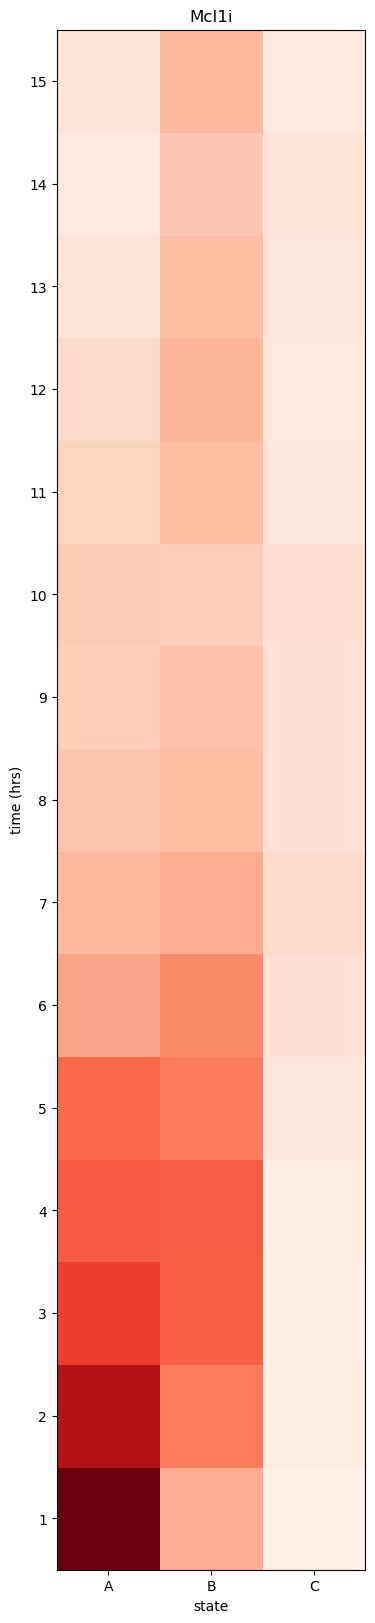

In [81]:
# Heatmaps of state occupancy vs time, one panel per treatment
nplots=int(np.ceil(np.sqrt(nf)))
plt.figure(figsize=(10,20))
colors = ['white'] + plt.cm.Reds(np.linspace(0, 1, 256)).tolist()  # 'white' for 0, 'Reds' for others
cmap = ListedColormap(colors)
for i_tm in range(nf):
    plt.subplot(nplots,nplots,i_tm+1)
    plt.imshow(state_probs_times[i_tm,:,:].T,origin='lower',cmap=cmap,clim=(0,.65))
    ax=plt.gca()
    ax.set_yticks(np.arange(time_inds.size))
    ax.set_xticks(np.arange(nstates))
    ax.set_xticklabels(np.array(state_labels))
    ax.set_yticklabels(time_inds)
    plt.xlabel('state');
    plt.ylabel('time (hrs)')

    plt.title(tmSet[i_tm])
    plt.ylim(0-.5,time_inds.size-.5)

plt.savefig(os.path.join(date, f'stateprobs_times_{figid}.png'))
plt.savefig(os.path.join(date, f'stateprobs_times_{figid}.svg'), format='svg')

**Feature by state and time.** In sliding windows of +/-2 h (centered on 1-15 h), assigns trajectory points to kinetic states and plots the mean of a feature for each state and time as a heatmap, one figure per treatment: motility (`motility_times_*`), ERK activity (`ERK_times_*`) and Fra-1 activity (`FRA1_times_*`, shown relative to its minimum).

/tmp/ipykernel_33583/3242989297.py:10: RuntimeWarning: Mean of empty slice
  feature_maps=[('motility',np.nanmean(dx_full_traj,axis=1),(1.,6.),'motility','motility',False),
/tmp/ipykernel_33583/3242989297.py:11: RuntimeWarning: Mean of empty slice
  ('ERK',np.nanmean(cratio_erk_full_traj,axis=1),(.8,1.15),'ERK activity','ERK',False),
/tmp/ipykernel_33583/3242989297.py:12: RuntimeWarning: Mean of empty slice
  ('FRA1',np.nanmean(fra1_full_traj,axis=1),(0.,3.5),'FRA1 activity','FRA1',True)]


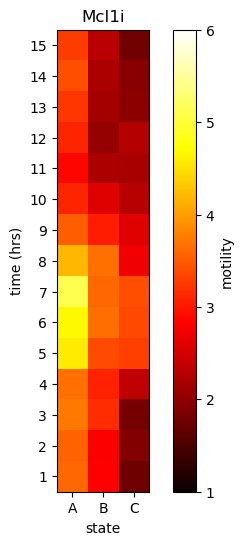

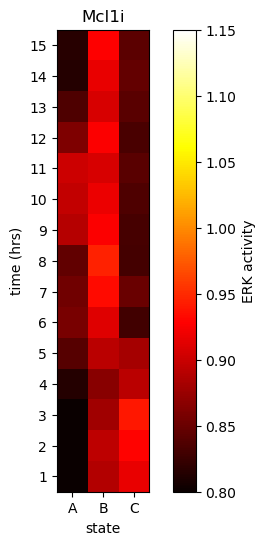

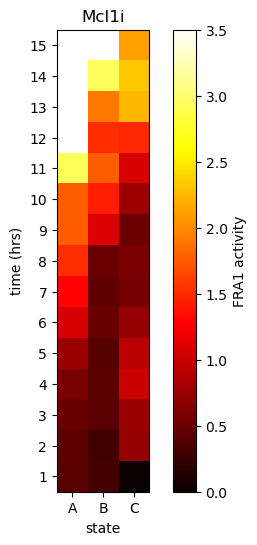

In [82]:
# Mean motility, ERK and Fra-1 per kinetic state in sliding windows (centers 1-15 h, +/-2 h), one heatmap per treatment and feature
nf=len(tmSet)
twindow=2 #hours; half-width of the sliding window
tu=16
tstep=1
time_inds=np.arange(1,tu,tstep).astype(int)
ntimes=time_inds.size

# (name, value of the feature at every trajectory point, color limits, colorbar label, file prefix, show relative to minimum)
feature_maps=[('motility',np.nanmean(dx_full_traj,axis=1),(1.,6.),'motility','motility',False),
              ('ERK',np.nanmean(cratio_erk_full_traj,axis=1),(.8,1.15),'ERK activity','ERK',False),
              ('FRA1',np.nanmean(fra1_full_traj,axis=1),(0.,3.5),'FRA1 activity','FRA1',True)]
for fname,fvals,clim,label,prefix,relative in feature_maps:
    fvals=fvals.copy()
    if relative:
        fvals[np.isinf(fvals)]=np.nan
    state_feat_times=np.zeros((nf,n_states,ntimes))
    for itimes,itt in enumerate(time_inds):
        indstw=np.where(np.logical_and(times_traj<itt+twindow,times_traj>itt-twindow))[0]
        for i in range(nf):
            indstwm=np.intersect1d(inds_conditions[i],indstw)
            indc0=stateSet[clusters_minima.assign(x[indstwm,:])]
            feat=fvals[indstwm]
            for istate in range(nstates):
                state_feat_times[i,istate,itimes]=np.nanmean(feat[np.where(indc0==istate)[0]])
    offset=np.nanmin(state_feat_times) if relative else 0.
    for i_tm in range(nf):
        plt.figure(figsize=(6,6))
        plt.imshow(state_feat_times[i_tm,:,:].T-offset,origin='lower',cmap=plt.cm.hot,clim=clim)
        ax=plt.gca()
        ax.set_yticks(np.arange(time_inds.size))
        ax.set_xticks(np.arange(nstates))
        ax.set_xticklabels(np.array(state_labels))
        ax.set_yticklabels(time_inds)
        plt.xlabel('state')
        plt.ylabel('time (hrs)')
        plt.title(tmSet[i_tm])
        plt.ylim(0-.5,time_inds.size-.5)
        cbar=plt.colorbar()
        cbar.set_label(label)
        plt.savefig(os.path.join(date, f'{prefix}_times_{figid}_{tmSet[i_tm]}.png'))
        plt.savefig(os.path.join(date, f'{prefix}_times_{figid}_{tmSet[i_tm]}.svg'), format='svg')

**Clustermap of state probabilities.** Seaborn clustermap of `state_probs` of the last time window, for treatment 0 (`tminds`). Saves `stateprobs_seaborn_*`.

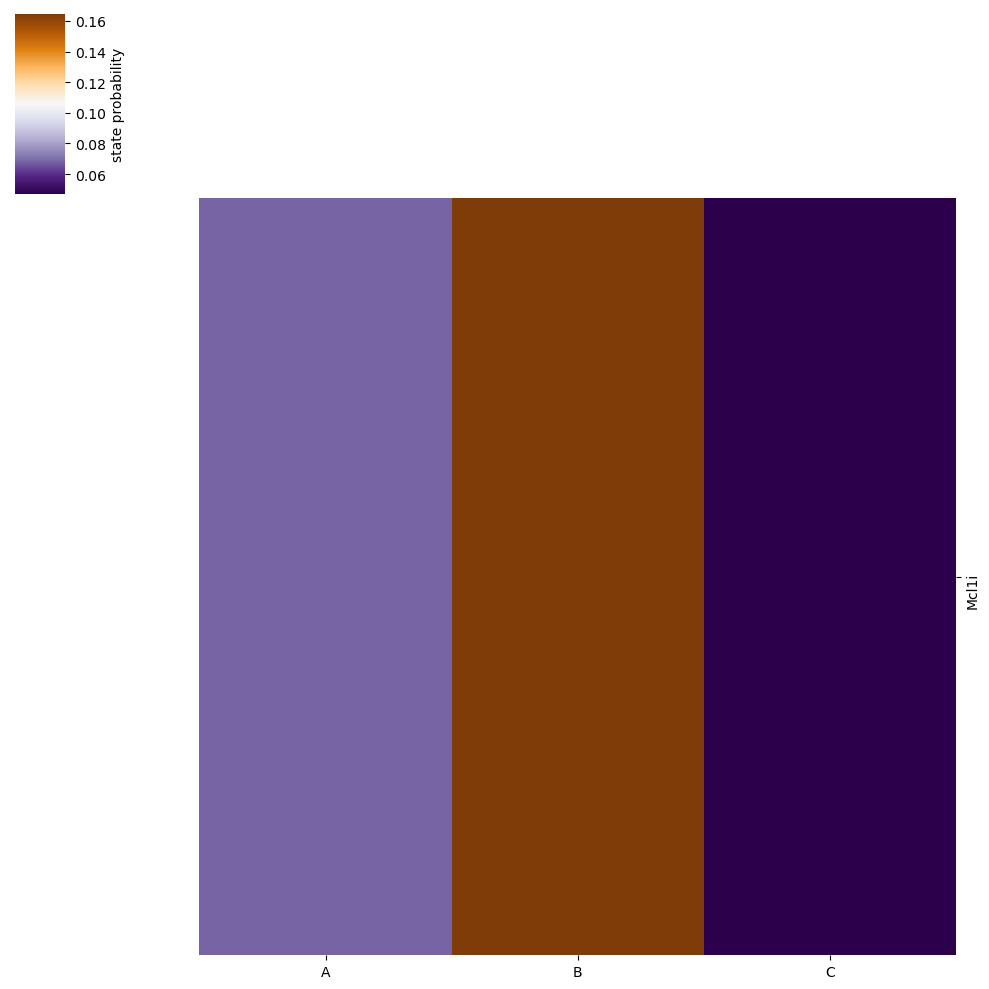

In [83]:
# Heatmap of the state probabilities in the last time window, treatment 0 only (tminds)
tminds=np.array([0]).astype(int)
stateprob_df = pd.DataFrame(data=state_probs[tminds,:], index=np.array(tmSet)[tminds], columns=state_labels)

# Plot the clustermap without row clustering to preserve the treatment order
hmap = sns.clustermap(stateprob_df, cmap="PuOr_r", cbar_kws={'label': 'state probability'}, row_cluster=False,col_cluster=False) #row_cluster=true if more than ne tx

# Show the plot
plt.savefig(os.path.join(date, f'stateprobs_seaborn_{figid}.png'))
plt.show()

**State-resolved feature distributions, 0-20 h.** For ERK (last and mean), Fra-1, neighborhood deaths, contact fractions, time, ERK variability and motility, draws violins per state for treatment 0 (`indstm_show`) with outlier removal (`outcut`). Saves `{feature}_tearplot_2tm_*`.

/tmp/ipykernel_33583/2797520826.py:15: RuntimeWarning: Mean of empty slice
  vsetList=[cratio_erk_traj,np.nanmean(cratio_erk_full_traj,axis=1),np.nanmean(fra1_full_traj,axis=1),np.nanmean(Nd_death_full_traj,axis=1),np.nanmean(cancer_cf_full_traj,axis=1),np.nanmean(primary_cf_full_traj,axis=1),np.nanmean(matrix_cf_full_traj,axis=1),times_traj,cratio_erk_var_traj,dx_traj] #np.nanmean(dx_full_traj,axis=1)]#,dx_traj,beta_traj,alpha_traj]


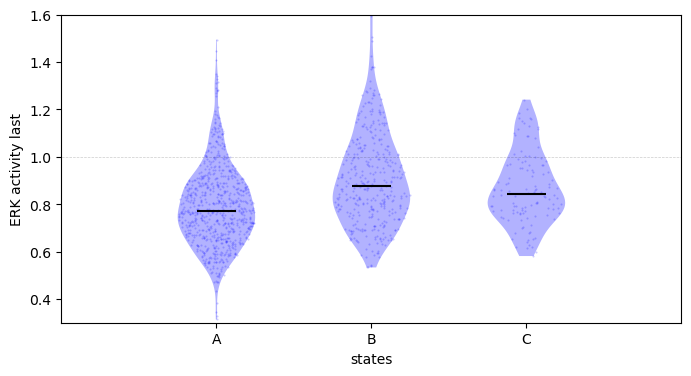

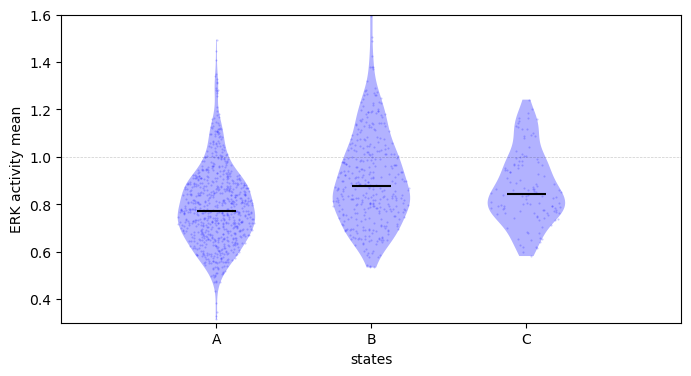

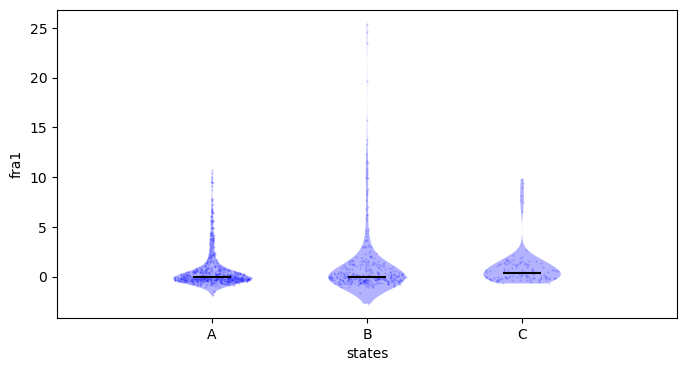

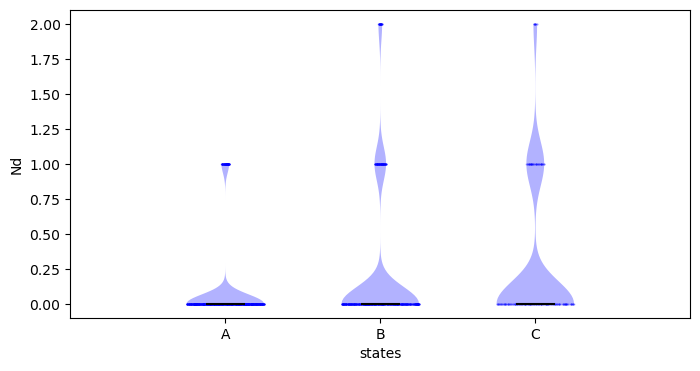

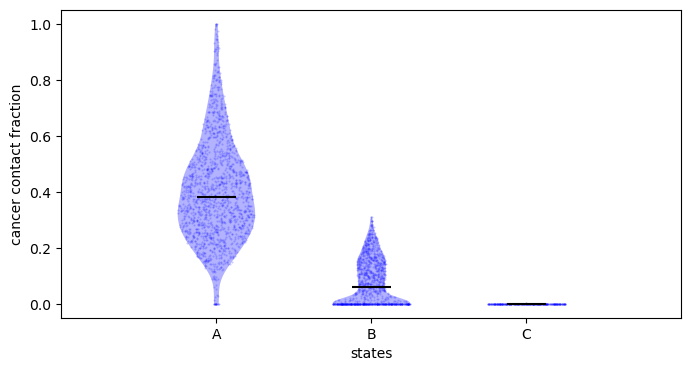

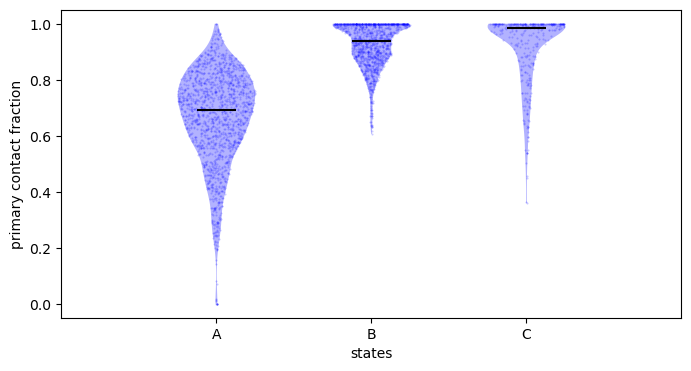

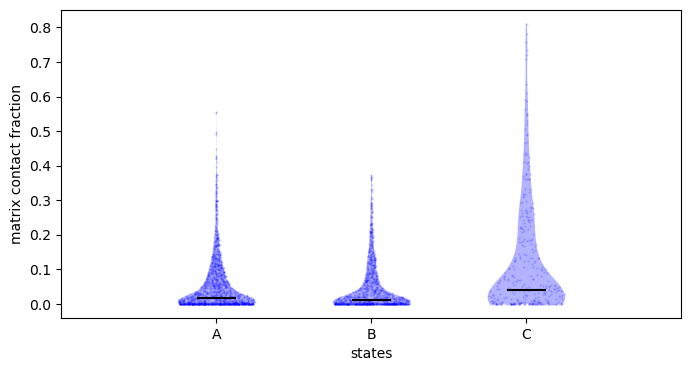

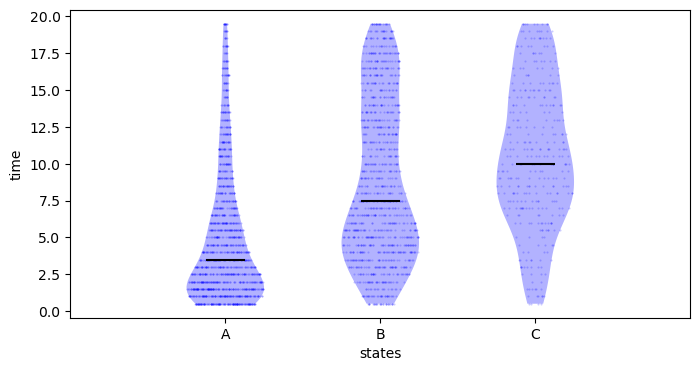

/home/wsltools/anaconda3/envs/celltraj_env/lib/python3.9/site-packages/imageprep.py:220: RuntimeWarning: invalid value encountered in divide
  img=(img-np.nanmean(img))/np.nanstd(img)


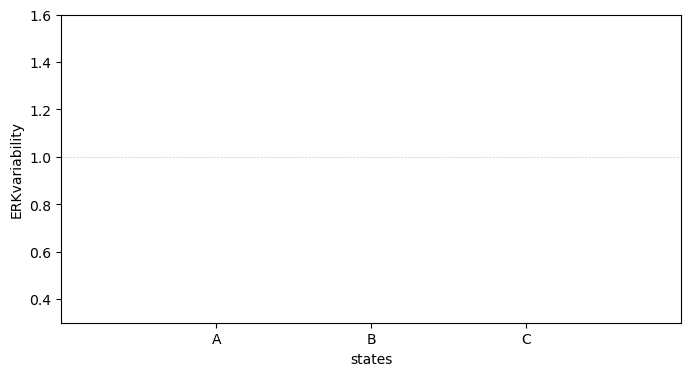

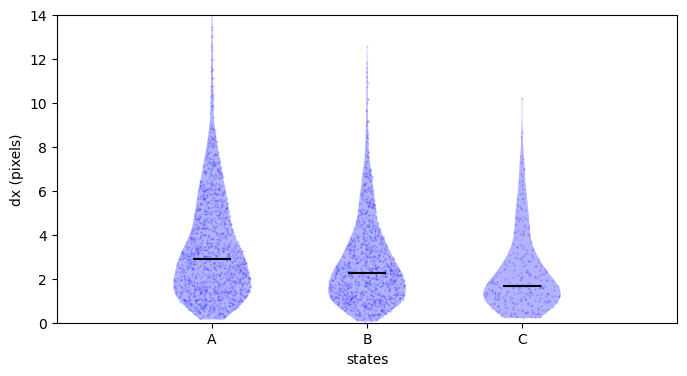

In [85]:
# Violins per kinetic state of ERK (last / mean), Fra-1, neighborhood deaths, contact fractions, time, ERK variability and motility,
# for treatment 0 (indstm_show) and 0-20 h; points with |z| > outcut are dropped. (dx is in microns despite the 'pixels' caption.)
cratio_erk_var_traj=np.std(cratio_erk_full_traj,axis=1)
outcut=4.
indstm_show=np.array([0]).astype(int) # treatments to show (only treatment 0 here)
nshow=indstm_show.size
plt.clf()
plt.close('all')
imm=0
tl=0
tu=20
indstw=np.where(np.logical_and(times_traj<tu,times_traj>tl))[0]
inds_rep=np.where(rep_traj<1000)[0]
indstw=np.intersect1d(inds_rep,indstw)
vsetList=[cratio_erk_traj,np.nanmean(cratio_erk_full_traj,axis=1),np.nanmean(fra1_full_traj,axis=1),np.nanmean(Nd_death_full_traj,axis=1),np.nanmean(cancer_cf_full_traj,axis=1),np.nanmean(primary_cf_full_traj,axis=1),np.nanmean(matrix_cf_full_traj,axis=1),times_traj,cratio_erk_var_traj,dx_traj] #np.nanmean(dx_full_traj,axis=1)]#,dx_traj,beta_traj,alpha_traj]
captionset=['ERK activity last','ERK activity mean','fra1','Nd','cancer contact fraction','primary contact fraction','matrix contact fraction','time','ERKvariability','dx (pixels)'] #,'motility alignment (beta)','contact avoidance (alpha)']

## States are shown in label order (A, B, C); they were ordered in Section 11.4

# identity order
sorted_indices = np.arange(n_states).astype(int) #np.argsort(mean_activity)
# one figure per variable in vsetList
for iv in range(len(vsetList)):
    if True: #try:
        vset = vsetList[iv]
        plt.figure(figsize=(8, 4))
        ax = plt.gca()

        # one violin per state and shown treatment
        for sorted_index in range(n_states):
            i = sorted_indices[sorted_index]  # Get the correct state index from the sorted order
            indstate=np.intersect1d(inds_states[i],indstw)
            setv = vset[indstate]
            setv[np.isinf(setv)]=np.nan
            indgood=np.where(np.isfinite(setv))[0]
            indin=np.where(np.abs(imprep.znorm(setv))<outcut)[0]
            indgood=np.intersect1d(indgood,indin)
            setv = setv[indgood]
            indstate=indstate[indgood]
            ind_tm=inds_tmSet_models[indtreatment_traj[indstate]]
            indin_tm=np.where(np.isin(ind_tm,indstm_show))[0]
            ind_tm=ind_tm[indin_tm]
            setv = setv[indin_tm]
            for ishow in range(indstm_show.size):
                i_tm=indstm_show[ishow]
                if setv[ind_tm==i_tm].size>1:
                    vplot = ax.violinplot(setv[ind_tm==i_tm], positions=[nshow*sorted_index + 1+.5*ishow], showmedians=True, showextrema=False)
                    vplot['cmedians'].set_color('black')
                    for pc in vplot['bodies']:
                        pc.set_facecolor(colorSet[i_tm])
                    xpoints=np.array(utilities.generate_xcoords_violin(vplot,[setv[ind_tm==i_tm]]))
                    plt.scatter(xpoints,setv[ind_tm==i_tm],s=1,c=colorSet[i_tm],marker='.',alpha=.2)

        # Reorder state labels based on the sorted order
        sorted_labels = [state_labels[i] for i in sorted_indices]

        ax.set_xticks(range(1, nshow*n_states + 1,nshow))
        ax.set_xticklabels(sorted_labels)

        plt.ylabel(captionset[iv])
        plt.xlabel('states')
        if captionset[iv][0:3]=='ERK':
            plt.ylim(.3,1.6)
            plt.plot([-100,100],[1,1],'k--',linewidth=.5,alpha=.2)
        if captionset[iv][0:2]=='dx':
            plt.ylim(0,14.)
        # Save or display the figure
        plt.xlim(0,nshow*n_states+1)
        plt.savefig(os.path.join(date + '/' + captionset[iv] + f'_tearplot_2tm_tl{tl}tu{tu}_' + figid + '.png'))
        plt.savefig(os.path.join(date + '/' + captionset[iv] + f'_tearplot_2tm_tl{tl}tu{tu}_' + figid + '.svg'), format='svg')
        plt.pause(0.5)
    #except Exception as e:

**Between-state comparison of mean ERK.** Welch t-tests on per-model mean ERK (4-12 h) between every pair of kinetic states, within treatment 0.

In [87]:
# Welch t-tests of per-model mean ERK between kinetic states, treatment 0, 4-12 h window
i_tm0=0
i_tm1=1
tl=4
tu=12
outcut=4.
indstw=np.where(np.logical_and(times_traj<tu,times_traj>tl))[0]
vset=np.nanmean(cratio_erk_full_traj,axis=1)
for i_tm0 in [0]:
    for i_tm1 in [0]:
        for istate0 in range(n_states):
            indstate=np.intersect1d(inds_states[istate0],indstw)
            setv = vset[indstate]
            setv[np.isinf(setv)]=np.nan
            indgood=np.where(np.isfinite(setv))[0]
            indin=np.where(np.abs(imprep.znorm(setv))<outcut)[0]
            indgood=np.intersect1d(indgood,indin)
            setv = setv[indgood]
            indstate=indstate[indgood]
            ind_tm=inds_tmSet_models[indtreatment_traj[indstate]]
            indstm=np.where(ind_tm==i_tm0)[0]
            setv0=setv[indstm]
            indmodels=indtreatment_traj[indstate[indstm]]
            means0=[]
            for imodel in np.unique(indmodels):
                means0.append(np.mean(setv0[indmodels==imodel]))

            states1=np.setdiff1d(np.arange(n_states).astype(int),[istate0])
            for istate1 in states1: #range(n_states):
                indstate=np.intersect1d(inds_states[istate1],indstw)
                setv = vset[indstate]
                setv[np.isinf(setv)]=np.nan
                indgood=np.where(np.isfinite(setv))[0]
                indin=np.where(np.abs(imprep.znorm(setv))<outcut)[0]
                indgood=np.intersect1d(indgood,indin)
                setv = setv[indgood]
                indstate=indstate[indgood]
                ind_tm=inds_tmSet_models[indtreatment_traj[indstate]]
                indstm=np.where(ind_tm==i_tm1)[0]
                setv=setv[indstm]
                indmodels=indtreatment_traj[indstate[indstm]]
                means=[]
                for imodel in np.unique(indmodels):
                    means.append(np.mean(setv[indmodels==imodel]))
                t_statistic, p_value = stats.ttest_ind(means0, means, equal_var=False)
                print(f'{tmSet[i_tm0]} {state_labels[istate0]} to {tmSet[i_tm1]} {state_labels[istate1]}: p-value: {p_value:.3e}')

Mcl1i A to Mcl1i B: p-value: 5.819e-01
Mcl1i A to Mcl1i C: p-value: 2.575e-01
Mcl1i B to Mcl1i A: p-value: 5.819e-01
Mcl1i B to Mcl1i C: p-value: 1.939e-01
Mcl1i C to Mcl1i A: p-value: 2.575e-01
Mcl1i C to Mcl1i B: p-value: 1.939e-01


/tmp/ipykernel_33583/1640887709.py:8: RuntimeWarning: Mean of empty slice
  vset=np.nanmean(cratio_erk_full_traj,axis=1)


**Morphology properties per trajectory point.** Collects `mm_properties` rows for each trajectory's last cell into `mm_properties_traj`.

In [88]:
# Raw multipole shape properties of each segment's last cell (all properties, not only the kept ones)
mm_properties_traj=[]
for imodel in indgood_models:
    sctm=modelSet[imodel]
    indmodel_traj=np.where(indtreatment_traj==imodel)[0]
    cellinds_indmodel_traj=cellinds1_traj[indmodel_traj]
    mm_properties_traj.append(sctm.mm_properties[cellinds_indmodel_traj,:])

mm_properties_traj=np.concatenate(mm_properties_traj,axis=0)

**State-resolved violins of each morphology property.** One figure per feature in `mm_property_names`. Saves `{property}_tearplot_2tm_*`.

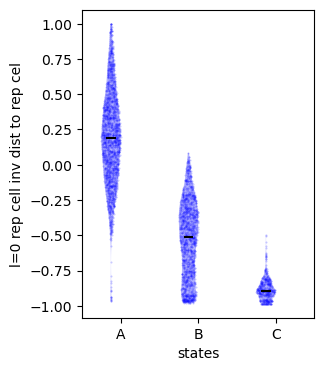

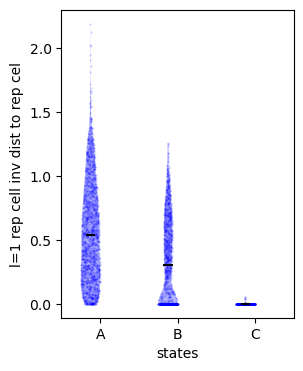

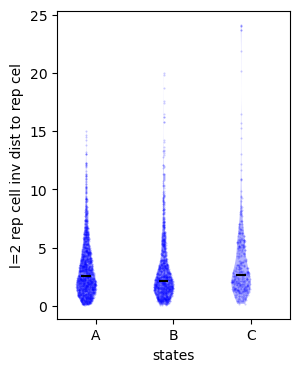

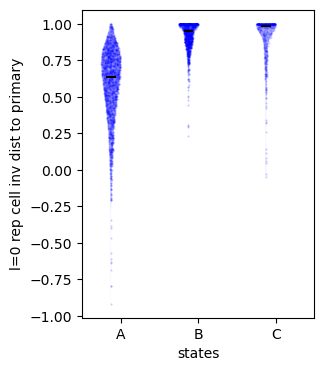

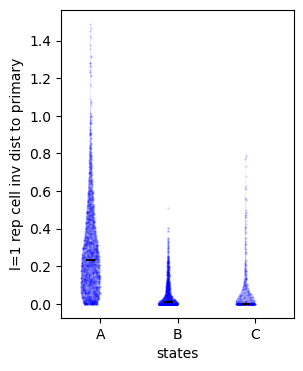

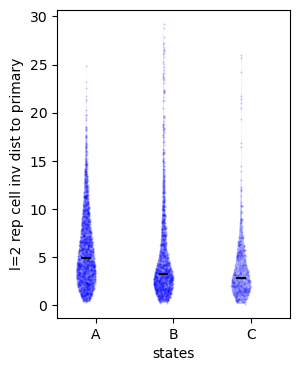

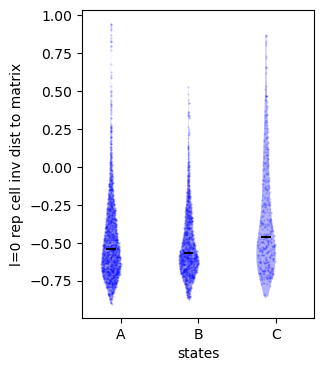

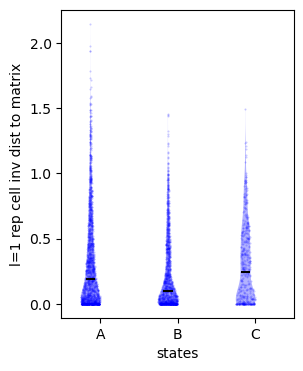

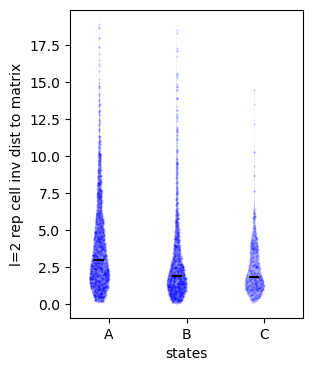

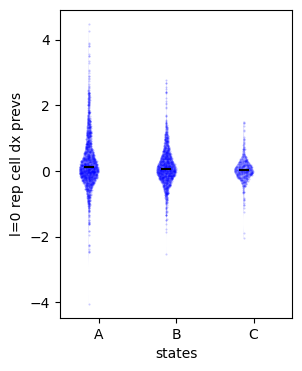

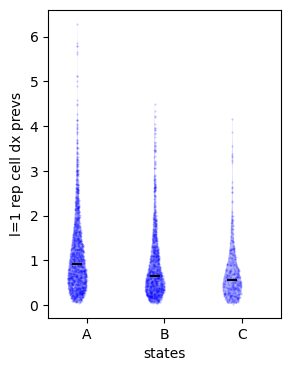

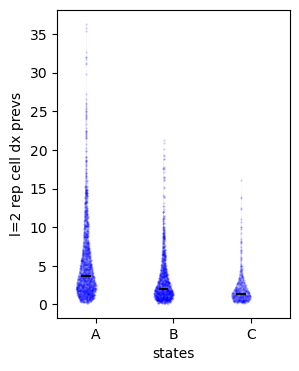

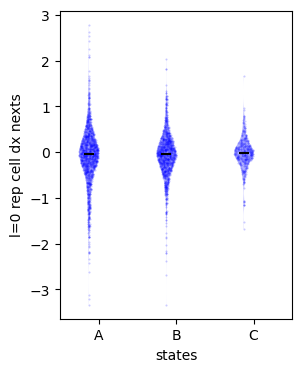

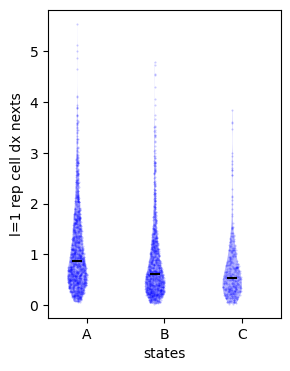

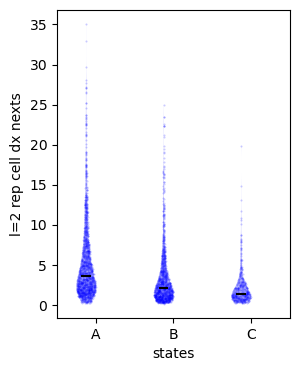

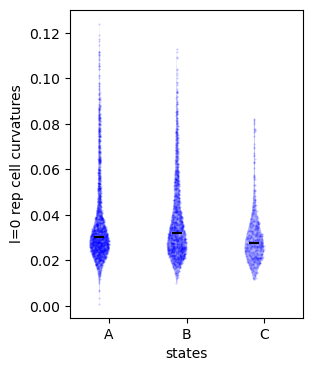

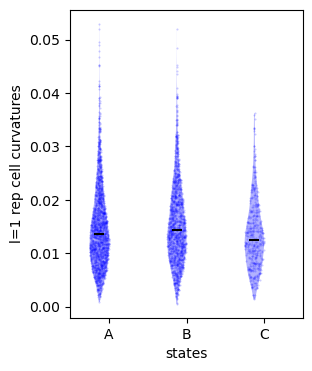

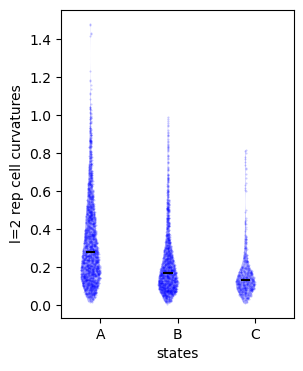

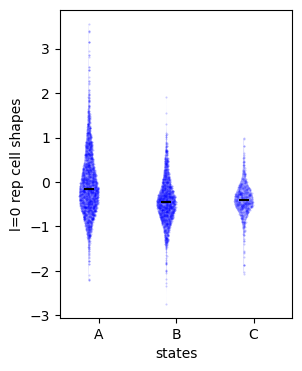

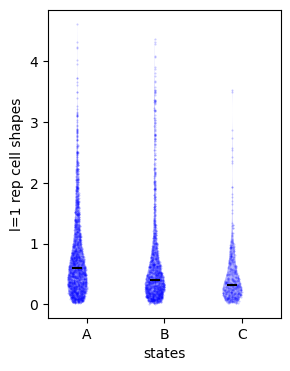

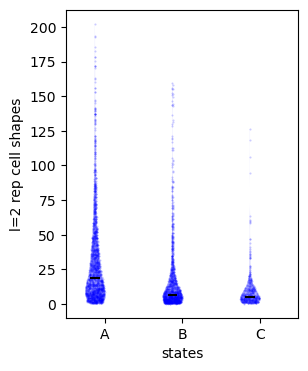

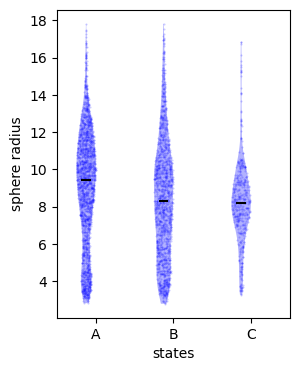

In [89]:
# Violins per kinetic state of every multipole shape property, treatment 0 (one-sided outlier cut: z < outcut).
# The `activity` block is not used; states are shown in label order.
outcut=5.
indstm_show=np.array([0]).astype(int) # treatments to show (only treatment 0 here)
plt.clf()
plt.close('all')
imm=0
vsetList=[mm_properties_traj[:,imm] for imm in range(mm_properties_traj.shape[1])]
captionset=[sctm.mm_property_names[imm].decode() for imm in range(len(sctm.mm_property_names))]

# (not used) mean cancer contact fraction per state
activity = np.nanmean(cancer_cf_full_traj,axis=1)
mean_activity = []
for i in range(n_states):
    setv = activity[inds_states[i]]
    indgood=np.where(np.isfinite(setv))[0]
    setv = setv[indgood]
    mean_activity.append(np.mean(setv))

# states shown in label order
sorted_indices = np.arange(n_states).astype(int) #np.argsort(mean_activity)

# one figure per property
for iv in range(len(vsetList)):
    try:
        vset = vsetList[iv]
        plt.figure(figsize=(3, 4))
        ax = plt.gca()

        # one violin per state
        for sorted_index in range(n_states):
            i = sorted_indices[sorted_index]  # Get the correct state index from the sorted order
            setv = vset[inds_states[i]]
            indgood=np.where(np.isfinite(setv))[0]
            indin=np.where(imprep.znorm(setv)<outcut)[0]
            indgood=np.intersect1d(indgood,indin)
            setv = setv[indgood]
            ind_tm=inds_tmSet_models[indtreatment_traj[inds_states[i][indgood]]]
            indin_tm=np.where(np.isin(ind_tm,indstm_show))[0]
            ind_tm=ind_tm[indin_tm]
            setv = setv[indin_tm]
            for ishow in range(indstm_show.size):
                i_tm=indstm_show[ishow]
                vplot = ax.violinplot(setv[ind_tm==i_tm], positions=[2*sorted_index + 1+.5*(ishow-.5)], showmedians=True, showextrema=False)
                vplot['cmedians'].set_color('black')
                for pc in vplot['bodies']:
                    pc.set_facecolor(colorSet[i_tm])
                xpoints=np.array(utilities.generate_xcoords_violin(vplot,[setv[ind_tm==i_tm]]))
                plt.scatter(xpoints,setv[ind_tm==i_tm],s=1,c=colorSet[i_tm],marker='.',alpha=.2)

        # Reorder state labels based on the sorted order
        sorted_labels = [state_labels[i] for i in sorted_indices]

        ax.set_xticks(range(1, 2*n_states + 1,2))
        ax.set_xticklabels(sorted_labels)

        plt.ylabel(captionset[iv])
        plt.xlabel('states')
        if captionset[iv][0:3]=='ERK':
            plt.ylim(.2,1.9)
            plt.plot([-100,100],[1,1],'k--',linewidth=.5,alpha=.2)
        if captionset[iv][0:2]=='dx':
            plt.ylim(0.,15.)
        # Save or display the figure
        plt.xlim(0,2*n_states)
        plt.savefig(os.path.join(date + '/' + captionset[iv] + '_tearplot_2tm_' + figid + '.png'))
        plt.savefig(os.path.join(date + '/' + captionset[iv] + '_tearplot_2tm_' + figid + '.svg'), format='svg')
        plt.pause(0.5)
    except Exception as e:
        print(e)

**Death, initial and resistant populations.** For treatment 0, builds `inds_death_traj`, `times_death_traj`, `inds_initial_traj` and `inds_resistant_traj` (windows of `fw=4` frames at the start and end of each model's analysis window). The *Time of death by ERK state* cell below recomputes these sets for each treatment with a different window (first frame to final frame - 8); its values for the last treatment are the ones used by the death model in Section 14.

In [91]:
# Death, initial and resistant trajectory points for treatment 0: initial = fw frames after the first trajl+1 frames,
# resistant = last fw frames of the analysis window. Prints the death frames of each model.
i_tm=0
indmodels=np.where(inds_tmSet_models==i_tm)[0]
indmodels=np.intersect1d(indmodels,indgood_models)
inds_death_traj=[]
times_death_traj=[]
inds_initial_traj=[]
inds_resistant_traj=[]
fw=4
for imodel in indmodels:
    indcells_traj_model=np.where(indtreatment_traj==imodel)[0]
    cellinds1_traj_model=cellinds1_traj[indcells_traj_model]
    sctm=modelSet[imodel]
    cellinds_death=sctm.inds_death.copy()
    print(sctm.cells_frameSet[sctm.inds_death])
    inds_death_traj.append(indcells_traj_model[np.isin(cellinds1_traj_model,cellinds_death)])
    times_death_traj.append(times_traj[indcells_traj_model[np.isin(cellinds1_traj_model,cellinds_death)]])#timestep_model[imodel]*(indframes_traj[indcells_traj_model[np.isin(cellinds1_traj_model,cellinds_death)]-initial_frames_model[imodel]]))
    fl=initial_frames_model[imodel]+trajl+1
    fu=final_frames_model[imodel] #frames for time window
    inds_initial_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fl+fw,indframes_traj>fl))[0],indcells_traj_model))
    inds_resistant_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fu,indframes_traj>fu-fw))[0],indcells_traj_model))

inds_death_traj=np.concatenate(inds_death_traj)
times_death_traj=np.concatenate(times_death_traj)
inds_initial_traj=np.concatenate(inds_initial_traj)
inds_resistant_traj=np.concatenate(inds_resistant_traj)

[27 21 18 18  7  6  6  6  2  2]
[39 33 33 27 26 22 10  9  8]
[36 28 25 21 17 16 16 15 12 10  7  6  6  6  6  3  3]


**Time of death by state.** For the deaths of treatment 0 (Mcl1i), violins of death time per state (the state at the cell's last frame), using `inds_death_traj` / `times_death_traj` from the previous cell. Saves `timeofdeath_tearplot_2tm_*`.

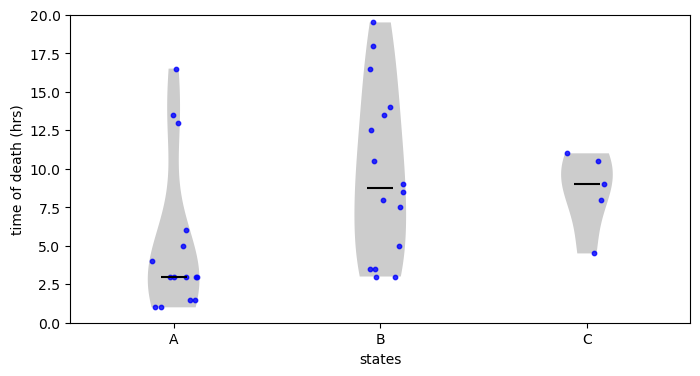

In [92]:
# Time of death per kinetic state (state of the point at death), treatment 0. Uses inds_death_traj / times_death_traj
# from the previous cell (they replace inds_death_mcl1i_traj / times_death_mcl1i_traj, which came from a removed cell).
plt.clf()
plt.close('all')
imm=0
i_tmr=0
vsetList=[times_death_traj]
captionset=['time of death (hrs)']

states_death=stateSet[ind_clusters[inds_death_traj]]
for iv in range(len(vsetList)):
        vset = vsetList[iv]
        plt.figure(figsize=(8, 4))
        ax = plt.gca()

        # one violin per state
        for sorted_index in range(n_states):
            i = sorted_index  # Get the correct state index from the sorted order
            inds_death=states_death==i
            setv=vset[inds_death]
            setv=setv[setv>0]
            i_tm=0
            if setv.size>1:
                vplot = ax.violinplot(setv, positions=[2*sorted_index + 1], showmedians=True, showextrema=False)
                vplot['cmedians'].set_color('black')
                for pc in vplot['bodies']:
                    pc.set_facecolor('gray')
                    pc.set_alpha(.4)
                xpoints=np.array(utilities.generate_xcoords_violin(vplot,[setv]))
                plt.scatter(xpoints,setv,s=10,c=colorSet[i_tmr],marker='o',alpha=.8)

        # state labels (sorted_indices is the identity order)
        sorted_labels = [state_labels[i] for i in sorted_indices]

        ax.set_xticks(range(1, 2*n_states + 1,2))
        ax.set_xticklabels(sorted_labels)

        plt.ylabel(captionset[iv])
        plt.xlabel('states')
        plt.xlim(0,2*n_states)
        plt.ylim(0,20)
        plt.savefig(os.path.join(date + '/timeofdeath_tearplot_2tm_' + figid + '.png'))
        plt.savefig(os.path.join(date + '/timeofdeath_tearplot_2tm_' + figid + '.svg'), format='svg')
        plt.pause(0.5)

**Time of death by ERK state, per treatment.** Violins of death time for ERK-on vs ERK-off cells. Saves `timeofdeath_tearplot_erk_*`.

/tmp/ipykernel_33583/2662010727.py:56: RuntimeWarning: Mean of empty slice
  erk_all=np.nanmean(cratio_erk_full_traj[inds_all_traj],axis=1)


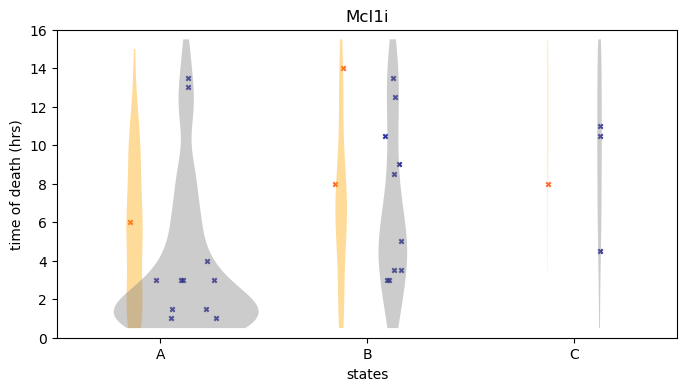

In [93]:
# Per treatment: time of death per kinetic state, split by ERK just before death (x: ERK-high orange-red, ERK-low dark blue),
# over violins of the times of all live ERK-on (orange) and ERK-off (gray) points of the state, widths scaled by state occupancy.
# Also redefines inds_death_traj / inds_initial_traj / inds_resistant_traj (window: first frame to final frame - 8);
# the values of the last treatment are the ones used in Section 14.
plt.clf()
plt.close('all')
imm=0
for i_tmr in range(nf):
    i_tm=i_tmr
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    inds_death_traj=[]
    times_death_traj=[]
    inds_initial_traj=[]
    inds_resistant_traj=[]
    fw=4
    times_all_traj=[]
    inds_all_traj=[]
    for imodel in indmodels:
        indcells_traj_model=np.where(indtreatment_traj==imodel)[0]
        cellinds1_traj_model=cellinds1_traj[indcells_traj_model]
        sctm=modelSet[imodel]
        fl=initial_frames_model[imodel] #+trajl+1
        fu=final_frames_model[imodel]-8 #frames for time window
        cellinds_death=sctm.inds_death.copy()
        inds_death=indcells_traj_model[np.isin(cellinds1_traj_model,cellinds_death)]
        inds_death=np.intersect1d(np.where(np.logical_and(indframes_traj<fu,indframes_traj>fl))[0],inds_death)
        inds_death_traj.append(inds_death)
        times_death_traj.append(times_traj[inds_death])#timestep_model[imodel]*(indframes_traj[indcells_traj_model[np.isin(cellinds1_traj_model,cellinds_death)]-initial_frames_model[imodel]]))
        inds_initial_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fl+fw,indframes_traj>fl))[0],indcells_traj_model))
        inds_resistant_traj.append(np.intersect1d(np.where(np.logical_and(indframes_traj<fu,indframes_traj>fu-fw))[0],indcells_traj_model))
        inds_traj=np.intersect1d(np.where(np.logical_and(indframes_traj<fu,indframes_traj>fl))[0],indcells_traj_model)
        inds_all_traj.append(inds_traj)
        times_all_traj.append(times_traj[inds_traj])
    inds_all_traj=np.concatenate(inds_all_traj)
    times_all_traj=np.concatenate(times_all_traj)
    inds_death_traj=np.concatenate(inds_death_traj)
    times_death_traj=np.concatenate(times_death_traj)
    inds_initial_traj=np.concatenate(inds_initial_traj)
    inds_resistant_traj=np.concatenate(inds_resistant_traj)
    vsetList=[times_death_traj]
    caption='time of death (hrs)'

    states_death=stateSet[ind_clusters[inds_death_traj]]
    states_all=stateSet[ind_clusters[inds_all_traj]]
    erk_death=np.ones(inds_death_traj.size)*np.nan
    for ideath in range(inds_death_traj.size):
        imodel=indtreatment_traj[inds_death_traj[ideath]]
        sctm=modelSet[imodel]
        ic=cellinds1_traj[inds_death_traj[ideath]]
        # last finite ERK value in the last 8 frames of the cell's track
        erktraj=sctm.x_signal[sctm.get_cell_trajectory(ic)][-8:]
        good1=np.isfinite(erktraj)
        if np.sum(good1)>0:
            erk_death[ideath]=erktraj[np.where(np.isfinite(erktraj))[0][-1]]
    erk_all=np.nanmean(cratio_erk_full_traj[inds_all_traj],axis=1)
    vset = times_death_traj
    plt.figure(figsize=(8, 4))
    ax = plt.gca()

    # one column per state
    for sorted_index in range(n_states):
        i = sorted_index  # Get the correct state index from the sorted order
        inds_death=np.where(states_death==i)[0]
        inds_all=np.where(states_all==i)[0]
        setv=vset[inds_death]
        setv_erk=erk_death[inds_death[setv>0]]
        erk_state=erk_all[inds_all]
        setv=setv[setv>0]
        i_tm=0
        if setv.size>1:
            vplot = ax.violinplot(setv, positions=[2*sorted_index + 1], showmedians=False, showextrema=False,widths=state_probs_times[i_tmr,i,0])
            for pc in vplot['bodies']:
                pc.set_facecolor('white')
                pc.set_alpha(0.)
            xpoints=np.array(utilities.generate_xcoords_violin(vplot,[setv]))
            ind_erkhigh=setv_erk>midcut
            ind_erklow=setv_erk<midcut
            ind_erknan=np.isnan(setv_erk)
            ax.scatter(xpoints[ind_erkhigh]-.25,setv[ind_erkhigh],s=10,c='orangered',marker='x',alpha=.8)
            ax.scatter(xpoints[ind_erklow]+.25,setv[ind_erklow],s=10,c='darkblue',marker='x',alpha=.8)
        widths_on=np.sum(erk_state>midcut)
        widths_off=np.sum(erk_state<midcut)
        widths_sum=widths_off+widths_on
        widths_on=widths_on/widths_sum
        widths_off=widths_off/widths_sum
        vplot = ax.violinplot(times_all_traj[inds_all[erk_state>midcut]], positions=[2*sorted_index + .75], showmedians=False, widths=2.*widths_on*state_probs_times[i_tmr,i,0],showextrema=False)
        for pc in vplot['bodies']:
            pc.set_facecolor('orange')
            pc.set_alpha(.4)
        vplot = ax.violinplot(times_all_traj[inds_all[erk_state<midcut]], positions=[2*sorted_index + 1.25], widths=2.*widths_off*state_probs_times[i_tmr,i,0],showmedians=False, showextrema=False)
        for pc in vplot['bodies']:
            pc.set_facecolor('gray')
            pc.set_alpha(.4)

    # state labels
    sorted_labels = [state_labels[i] for i in range(n_states)]

    ax.set_xticks(range(1, 2*n_states + 1,2))
    ax.set_xticklabels(sorted_labels)

    plt.ylabel(caption)

    plt.xlabel('states')
    plt.xlim(0,2*n_states)
    plt.ylim(0,16)
    plt.title(tmSet[i_tmr])
    plt.savefig(os.path.join(date + f'/timeofdeath_tearplot_erk_{tmSet[i_tmr]}_' + figid + '.png'))
    plt.savefig(os.path.join(date + f'/timeofdeath_tearplot_erk_{tmSet[i_tmr]}_' + figid + '.svg'))
    plt.pause(0.5)

## 13. Death and ERK dynamics over time

Time courses of the death rate, the mean ERK activity and the relative cell number, with credible bands from a bootstrap over models.

**Per-treatment death and ERK time series.** Collects death times, live-cell times and ERK values per treatment (`times_death_set`, `times_set`, `erk_activity_set`).

In [94]:
# Per treatment: death times, death frames, times of all cells and their ERK values
times_death_set=[None]*nf
inds_death_set=[None]*nf
erk_activity_set=[None]*nf
times_set=[None]*nf
for i_tm in range(nf):
        indmodels=np.where(inds_tmSet_models==i_tm)[0]
        indmodels=np.intersect1d(indmodels,indgood_models)
        inds_death=[]
        times_death=[]
        times_live=[]
        erk_activity=[]
        for imodel in indmodels:
            sctm=modelSet[imodel]
            cellinds_death=sctm.inds_death.copy()
            if np.isscalar(cellinds_death):
                cellinds_death=np.array([cellinds_death])
            fl=initial_frames_model[imodel]
            timestep=timestep_model[imodel]
            if cellinds_death.size>0:
                times_death.append(timestep*(sctm.cells_frameSet[cellinds_death]-fl))
                inds_death.append(sctm.cells_frameSet[cellinds_death])
            times_live.append(timestep*(sctm.cells_frameSet-fl))
            erk_activity.append(sctm.x_signal)
        if len(times_death)>0:
            times_death=np.concatenate(times_death)
            inds_death=np.concatenate(inds_death)
        times_live=np.concatenate(times_live)
        erk_activity=np.concatenate(erk_activity)
        times_death_set[i_tm]=times_death.copy()
        inds_death_set[i_tm]=inds_death.copy()
        times_set[i_tm]=times_live.copy()
        erk_activity_set[i_tm]=erk_activity.copy()

**Function `get_erk_death_number_info`.** Computes, for one treatment, the time courses of mean ERK activity, death rate and relative cell number, optionally on a bootstrap resample of the models.

In [95]:
# For one treatment (optionally on a bootstrap resample of its models): mean ERK, death rate (derivative of the cumulative death
# fraction) and mean relative cell number on a grid of width dt from tl to tf. Uses the global dt and midcut (fraction_on is not returned).
def get_erk_death_number_info(i_tm,random_shuffle=False,tl=0,tf=20,norm_death=True):
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    indmodels=np.intersect1d(indmodels,indgood_models)
    inds_death=[]
    times_death=[]
    times_live=[]
    times_number=[]
    erk_activity=[]
    cell_rel_number=[]
    if random_shuffle:
        indmodels = np.random.choice(indmodels, size=indmodels.size, replace=True)
    for imodel in indmodels:
        sctm=modelSet[imodel]
        cellinds_death=sctm.inds_death.copy()
        if np.isscalar(cellinds_death):
            cellinds_death=np.array([cellinds_death])
        fl=initial_frames_model[imodel]
        fu=final_frames_model[imodel]
        timestep=timestep_model[imodel]
        if cellinds_death.size>0:
            times_death.append(timestep*(sctm.cells_frameSet[cellinds_death]-fl))
            inds_death.append(sctm.cells_frameSet[cellinds_death])
        times_live.append(timestep*(sctm.cells_frameSet-fl))
        erk_activity.append(sctm.x_signal)
        for iframe in range(fl,fu):
            times_number.append(timestep*(iframe-fl))
            cell_rel_number.append(np.sum(sctm.cells_frameSet==iframe)/np.sum(sctm.cells_frameSet==fl))
    if len(times_death)>0:
        times_death=np.concatenate(times_death)
        inds_death=np.concatenate(inds_death)
    times_live=np.concatenate(times_live)
    erk_activity=np.concatenate(erk_activity)
    cell_rel_number=np.array(cell_rel_number)
    times_number=np.array(times_number)
    times_death=times_death[np.logical_and(times_death<tf,times_death>tl)]
    inds_live=np.where(np.logical_and(times_live<tf,times_live>=tl))[0]
    times_live=times_live[inds_live]
    erk_activity=erk_activity[inds_live]
    times_death=np.sort(times_death)
    time_set=np.arange(tl,tf,dt)
    times_death_fraction=np.zeros_like(time_set)
    erk_mean=np.zeros_like(time_set)
    fraction_on=np.zeros_like(time_set)
    number_mean=np.zeros_like(time_set)
    for itt in range(time_set.size):
        tu=time_set[itt]
        times_death_fraction[itt]=np.sum(times_death<=tu)
        indstw=np.where(np.logical_and(times_live>tu-dt,times_live<=tu))[0]
        indstw_number=np.where(np.logical_and(times_number>tu-dt,times_number<=tu))[0]
        erk_mean[itt]=np.nanmean(erk_activity[indstw])
        fraction_on[itt]=np.sum(erk_activity[indstw]>midcut)/np.sum(np.isfinite(erk_activity[indstw]))
        number_mean[itt]=np.nanmean(cell_rel_number[indstw_number])
    times_death_fraction=times_death_fraction/times_death_fraction[-1]
    death_rate=np.gradient(times_death_fraction,time_set)
    if norm_death:
        death_rate=(death_rate-np.nanmin(death_rate))/(np.nanmax(death_rate)-np.nanmin(death_rate))
    return erk_mean,death_rate,number_mean

**Bootstrap bands for cell number, ERK and death rate (treatment 0, Mcl1i).** Three stacked panels. Saves `OS17_number_erkmeans_deathrates.svg`.

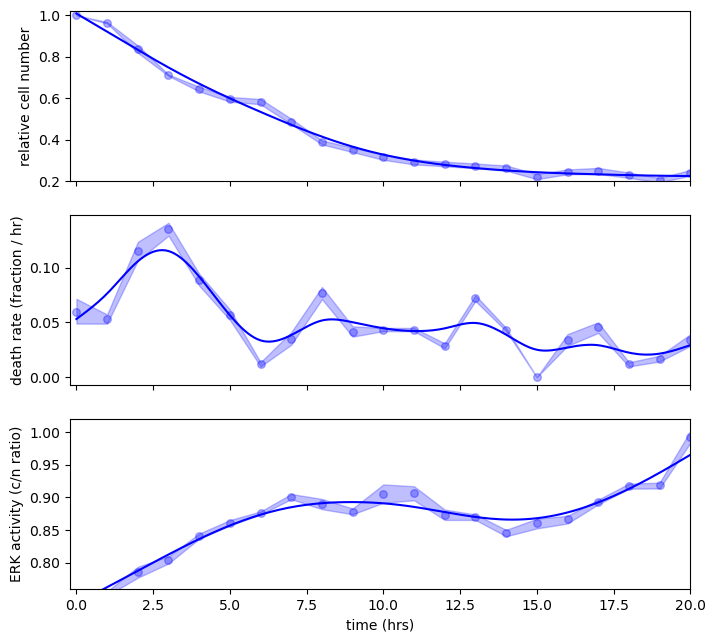

In [96]:
# Bootstrap bands (100 resamples of the models) for relative cell number, death rate and mean ERK vs time, for the treatments in tms
def ci95(v, nboot=1000):
    """95% credible interval of the mean via Bayesian bootstrap; NaN if too little data."""
    v = np.asarray(v, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 2:
        return np.array([np.nan, np.nan])
    return np.array(bayesian_bootstrap.central_credible_interval(
        bayesian_bootstrap.mean(v, n_replications=nboot), alpha=0.05))

# same value as in Section 7
midcut=1.0
tf=21.0
tl=0.
dt=1.0
time_set=np.arange(tl,tf,dt)
tms=[0]                      # treatment indices to plot (this platemap has one treatment, index 0)
fig,axs=plt.subplots(3,1,sharex=True,figsize=(8,7.5))

for i_tm in tms:
    label0=tmSet[i_tm]
    nsample=100
    erk_means=[]
    death_rates=[]
    number_means=[]
    for isample in range(nsample):
        erk_mean,death_rate,number_mean=get_erk_death_number_info(i_tm,tl=0.,tf=tf,random_shuffle=True,norm_death=False)
        erk_means.append(erk_mean)
        death_rates.append(death_rate)
        number_means.append(number_mean)
    erk_means=np.array(erk_means)
    death_rates=np.array(death_rates)
    number_means=np.array(number_means)
    nrd=death_rates.shape[1]
    erk_means_CR=np.zeros((nrd,3))
    number_means_CR=np.zeros((nrd,3))
    death_rates_CR=np.zeros((nrd,3))
    erk_means_CR[:,0]=np.nanmean(erk_means,axis=0)
    death_rates_CR[:,0]=np.nanmean(death_rates,axis=0)
    number_means_CR[:,0]=np.nanmean(number_means,axis=0)
    for ird in range(nrd):
        erk_means_CR[ird,1:]=ci95(erk_means[:,ird])
        death_rates_CR[ird,1:]=ci95(death_rates[:,ird])
        number_means_CR[ird,1:]=ci95(number_means[:,ird])

    death_rate_m=death_rates_CR[:,0]
    erk_mean_m=erk_means_CR[:,0]
    # relative cell number is 1 at t=0 by definition
    number_means_CR[0,:]=1.
    time_set_smth=np.linspace(time_set[0],time_set[-1],201)
    gd=np.isfinite(death_rate_m); ge=np.isfinite(erk_mean_m); gn=np.isfinite(number_means_CR[:,0])
    spl_death=csaps.CubicSmoothingSpline(time_set[gd], death_rate_m[gd], smooth=.7)
    death_rate_smth=spl_death(time_set_smth)
    spl_erk=csaps.CubicSmoothingSpline(time_set[ge], erk_mean_m[ge], smooth=.1)
    erk_mean_smth=spl_erk(time_set_smth)
    spl_number=csaps.CubicSmoothingSpline(time_set[gn], number_means_CR[gn,0], smooth=.1)  # mask now matches x
    number_mean_smth=spl_number(time_set_smth)

    col=colorSet[i_tm]
    axs[0].scatter(time_set,number_means_CR[:,0],s=30,c=col,alpha=.3,marker='o',label=label0)
    axs[0].fill_between(time_set,number_means_CR[:,1],number_means_CR[:,2],color=col,alpha=.25)
    axs[1].fill_between(time_set,death_rates_CR[:,1],death_rates_CR[:,2],color=col,alpha=.25)
    axs[1].scatter(time_set,death_rate_m,s=30,c=col,alpha=.3,marker='o',label=label0)
    axs[2].scatter(time_set,erk_mean_m,s=30,c=col,alpha=.3,marker='o',label=label0)
    axs[2].fill_between(time_set,erk_means_CR[:,1],erk_means_CR[:,2],color=col,alpha=.25)
    axs[1].plot(time_set_smth,death_rate_smth,'-',color=col,linewidth=1.5)
    axs[2].plot(time_set_smth,erk_mean_smth,'-',color=col,linewidth=1.5)
    axs[0].plot(time_set_smth,number_mean_smth,'-',color=col,linewidth=1.5)

axs[0].set_ylabel('relative cell number')
axs[0].set_xlim(-.2,tf-dt)
axs[0].set_ylim(.2,1.02)

axs[1].set_ylabel('death rate (fraction / hr)')
axs[1].set_xlim(-.2,tf-dt)

axs[2].set_ylabel('ERK activity (c/n ratio)')
axs[2].set_xlabel('time (hrs)')
axs[2].set_xlim(-.2,tf-dt)
axs[2].set_ylim(.76,1.02)
plt.savefig(f'{date}/OS17_number_erkmeans_deathrates.svg')

## 14. Markov model with death and in-silico ERK inhibition

The kinetic states are expanded into a 24-state model: kinetic state (A, B, C) x alive/dead x Nd low/high x ERK low/high. Transition probabilities come from the measured transition pairs; death probabilities are the empirical ERK-dependent rates scaled by `death_boost`. The model is propagated from the initial population to predict survival and state populations, compared with the observed populations, and used to simulate complete ERK inhibition by removing ERK-off to on transitions.

### 14.1 State space and transition matrix

**24-state space.** Expands each kinetic state (A, B, C) into 24 states: x {alive, dead} x {Nd low (`Nd_clusters[0]`), Nd high (`Nd_clusters[1]`)} x {ERK low, ERK high}. Defines `clusters_death`, `stateSet_death` and the index sets `states_death_alive/dead/ERKlow/ERKhigh/Ndlow/Ndhigh` used in the rest of this section.

In [97]:
# 24-state space: every microstate is copied for alive/dead (extra coordinate 0/1), Nd low/high (Ndlow/Ndhigh)
# and ERK low/high (lowcut/highcut). The states_death_* arrays list the 24-state indices with each property.
##do with Nd_death states
clusters_x=clusters_minima.clustercenters.copy()
n_feat=clusters_x.shape[1];n_clusters=clusters_x.shape[0]
clustercenters0=np.concatenate((clusters_x,np.zeros(n_clusters)[:,np.newaxis]),axis=1)
clustercenters1=np.concatenate((clusters_x,np.ones(n_clusters)[:,np.newaxis]),axis=1)
clustercenters_death=np.append(clustercenters0,clustercenters1,axis=0)
n_clusters_death=clustercenters_death.shape[0]
stateSet_death=np.append(stateSet,stateSet+n_states)
n_states_death=2*n_states

# Nd levels used here: 0 and 1 nearby deaths (the manuscript used Nd_clusters[1] and Nd_clusters[3])
#Ndlow=Nd_clusters[1]; Ndhigh=Nd_clusters[3] #manuscript version
Ndlow=Nd_clusters[0]; Ndhigh=Nd_clusters[1]
clustercenters0=np.concatenate((clustercenters_death,Ndlow*np.ones(n_clusters_death)[:,np.newaxis]),axis=1)
clustercenters2=np.concatenate((clustercenters_death,Ndhigh*np.ones(n_clusters_death)[:,np.newaxis]),axis=1)
clustercenters_death=np.concatenate((clustercenters0,clustercenters2),axis=0)
n_clusters_death=clustercenters_death.shape[0]
clusters_death=coor.clustering.AssignCenters(clustercenters_death, metric='euclidean')
stateSet_death=np.append(stateSet_death,stateSet_death+n_states_death)
n_states_death=2*n_states_death

Slow=lowcut #.37 #lowcut
Shigh=highcut #1.45 #highcut
clustercenters0=np.concatenate((clustercenters_death,Slow*np.ones(n_clusters_death)[:,np.newaxis]),axis=1)
clustercenters1=np.concatenate((clustercenters_death,Shigh*np.ones(n_clusters_death)[:,np.newaxis]),axis=1)
clustercenters_death=np.append(clustercenters0,clustercenters1,axis=0)
n_clusters_death=clustercenters_death.shape[0]
clusters_death=coor.clustering.AssignCenters(clustercenters_death, metric='euclidean')
stateSet_death=np.append(stateSet_death,stateSet_death+n_states_death)
n_states_death=2*n_states_death

# column of each extra coordinate in the augmented vectors
inds_death_feats=np.arange(clusters_minima.clustercenters.shape[0]).astype(int)
inds_death_life=clusters_minima.clustercenters.shape[1]
inds_death_Nd=clusters_minima.clustercenters.shape[1]+1
inds_death_ERK=clusters_minima.clustercenters.shape[1]+2

states_death_ERKlow=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_ERK]==Slow)[0]])
states_death_ERKhigh=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_ERK]==Shigh)[0]])
states_death_Ndlow=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_Nd]==Ndlow)[0]])
states_death_Ndhigh=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_Nd]==Ndhigh)[0]])
states_death_alive=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_life]==0.)[0]])
states_death_dead=np.unique(stateSet_death[np.where(clusters_death.clustercenters[:,inds_death_life]==1.)[0]])

**Transition pairs in the augmented space (Mcl1i, time-limited).** For each model in treatment `i_tmr` (left over from the loop in Section 12; 0 here), within `tl < t < tu`, appends to each pair: dead flag at step 1, Nd_death at both steps and the last valid ERK value; drops non-finite rows. Fills `x0set_death`, `x1set_death`.

In [98]:
# Transition pairs in the augmented space for treatment i_tmr (left over from the loop in Section 12; 0 here), 0-25.5 h:
# appends the dead flag (1 if the step ends in a death), Nd_death at both steps and the last finite ERK value; drops rows with NaN.
indmodels=np.where(inds_tmSet_models==i_tmr)[0]
indmodels=np.intersect1d(indmodels,indgood_models)
x0set_death=[]
x1set_death=[]
tl=0
tu=25.5
fw_erk=1
min_nerk=0
for imodel in indmodels:
    sctm=modelSet[imodel]
    indmodel=np.where(inds_trajsteps_models==imodel)[0]
    inds1=inds_trajsteps[indmodel,1]
    times1=sctm.cells_timeSet[inds1]
    indmodel=indmodel[np.logical_and(times1<tu,times1>tl)]
    inds1=inds1[np.logical_and(times1<tu,times1>tl)]
    x0=x0set[indmodel,:]
    x1=x1set[indmodel,:]
    x0=np.append(x0,np.zeros(x0.shape[0])[:,np.newaxis],axis=1)
    x1=np.append(x1,np.zeros(x1.shape[0])[:,np.newaxis],axis=1)
    inds_death_trajsteps_model=np.where(np.isin(inds1,sctm.inds_death))[0]
    x1[inds_death_trajsteps_model,-1]=1.
    Nd0=sctm.Nd_death[inds_trajsteps[indmodel,0]]
    Nd1=sctm.Nd_death[inds_trajsteps[indmodel,1]]
    x0=np.append(x0,Nd0[:,np.newaxis],axis=1)
    x1=np.append(x1,Nd1[:,np.newaxis],axis=1)
    # ERK at each step = last finite value of the track up to that cell (fw_erk=1: the cell's own value)
    erk_model0=np.ones(inds1.size)*np.nan
    erk_model1=np.ones(inds1.size)*np.nan
    for i in range(inds1.size):
        ic0=inds_trajsteps[indmodel[i],0]
        ic1=inds_trajsteps[indmodel[i],1]
        erktraj0=sctm.x_signal[sctm.get_cell_trajectory(ic0)][-fw_erk:]
        good0=np.isfinite(erktraj0)
        if np.sum(good0)>min_nerk:
            erk_model0[i]=erktraj0[np.where(np.isfinite(erktraj0))[0][-1]]
        erktraj1=sctm.x_signal[sctm.get_cell_trajectory(ic1)][-fw_erk:]
        good1=np.isfinite(erktraj1)
        if np.sum(good1)>min_nerk:
            erk_model1[i]=erktraj1[np.where(np.isfinite(erktraj1))[0][-1]]
        # print ERK before/after for the death transitions
        if x1[i,inds_death_life]==1.:
            print(f'm{imodel} {erk_model0[i]} to {erk_model1[i]}')
    x0=np.append(x0,erk_model0[:,np.newaxis],axis=1)
    x1=np.append(x1,erk_model1[:,np.newaxis],axis=1)
    indgood0=np.isfinite(np.sum(x0,axis=1))
    indgood1=np.isfinite(np.sum(x1,axis=1))
    indgood=np.logical_and(indgood0,indgood1)
    x0set_death.append(x0[indgood,:])
    x1set_death.append(x1[indgood,:])

x0set_death=np.concatenate(x0set_death)
x1set_death=np.concatenate(x1set_death)

m0 0.5341282191394648 to 0.6422966344461526
m0 0.8650872129147082 to 0.6726169542109433
m0 0.6726169542109433 to 0.6567343426748714
m0 nan to 0.7756558072384917
m0 nan to nan
m0 nan to 0.8794384235108991
m0 nan to 0.9750490074535165
m1 nan to 0.6855906288554772
m1 0.8973303941996373 to 0.8581182438026157
m1 nan to nan
m1 0.8915868564952159 to 0.851715252694747
m1 0.7455299495605817 to 0.8376895193178199
m1 1.1244935684173458 to nan
m2 0.6600090462724733 to 0.5546126029742163
m2 0.6856569244390336 to nan
m2 nan to nan
m2 nan to nan
m2 nan to 0.6699720502951539
m2 nan to 0.793628867007223
m2 nan to 1.0428266374540576
m2 nan to nan
m2 1.3204215650575069 to 1.0193940769552186
m2 nan to nan
m2 0.8212493532279027 to nan
m2 nan to 0.991048820907823


**Empirical per-step death probability.** Death probability for ERK-high and ERK-low cells from the transition pairs above.

In [99]:
# Empirical per-step death probability of ERK-high and ERK-low cells
pdeath_ERKhigh=np.sum(np.logical_and(x1set_death[:,inds_death_life]==1,x1set_death[:,inds_death_ERK]>midcut))/np.sum(x1set_death[:,inds_death_ERK]>midcut)
pdeath_ERKlow=np.sum(np.logical_and(x1set_death[:,inds_death_life]==1,x1set_death[:,inds_death_ERK]<midcut))/np.sum(x1set_death[:,inds_death_ERK]<midcut)
print(f'death rate ERK-low: {pdeath_ERKlow:.2e}')
print(f'death rate ERK-high: {pdeath_ERKhigh:.2e}')

death rate ERK-low: 1.47e-02
death rate ERK-high: 1.10e-02


**Coarse-grained transition matrix over the 24 states.** `get_transition_matrix_CG` with counts, shown on a log scale.

/tmp/ipykernel_33583/192821155.py:3: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(P_states),origin='lower')


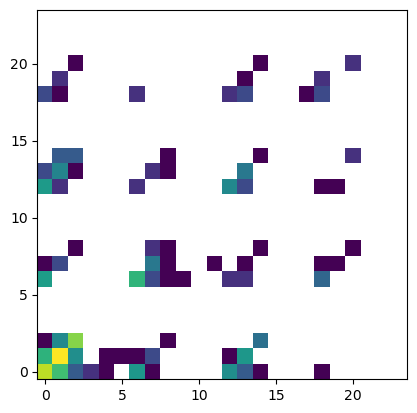

In [100]:
# Coarse-grained 24x24 transition matrix (return_counts=True), log scale
P_states=model.get_transition_matrix_CG(x0set_death,x1set_death,clusters=clusters_death,states=stateSet_death,return_counts=True)
plt.imshow(np.log(P_states),origin='lower')

**Function `clean_P`.** Post-processes the 24-state matrix: forbids direct alive-to-dead counts and makes dead states absorbing; moves transitions from Nd-high to Nd-low into Nd-high to Nd-high (Nd-high cells stay Nd-high); renormalizes; then re-inserts death probabilities from the empirical ERK-high/low rates times `death_boost`, and renormalizes again.

In [101]:
# Clean the 24-state matrix: absorbing dead states, Nd-high stays Nd-high, empirical death probabilities x death_boost
#manuscript version
def clean_P(P_states,pdeath_ERKhigh=0.,pdeath_ERKlow=0.,death_boost=1.,states_death_dead=None,states_death_alive=None,states_death_ERKlow=None,states_death_ERKhigh=None,states_death_Ndhigh=None,states_death_Ndlow=None):
    #zero out all death counts
    inds_from=states_death_alive
    inds_to=states_death_dead
    for i in inds_from:
        for j in inds_to:
            P_states[i,j]=0.

    for i in inds_to:
        P_states[i,:]=0.
        P_states[i,i]=1.

    #move Nd-high to Nd-low transitions to Nd-high to Nd-high
    inds_from=np.intersect1d(states_death_Ndhigh,states_death_alive)
    inds_to_old=np.intersect1d(states_death_Ndlow,states_death_alive)
    inds_to_new=np.intersect1d(states_death_Ndhigh,states_death_alive)
    for i in inds_from:
        for j in range(inds_to_old.size):
            j_old=inds_to_old[j]
            j_new=inds_to_new[j]
            P_states[i,j_new]=P_states[i,j_new]+P_states[i,j_old]
            P_states[i,j_old]=0.

    #re-normalize
    for irow in range(P_states.shape[0]):
        if np.sum(P_states[irow,:])==0.:
            P_states[irow,irow]=1.
        else:
            P_states[irow,:]=P_states[irow,:]/np.sum(P_states[irow,:])

    #add in death rates
    inds_from=np.intersect1d(states_death_ERKhigh,states_death_alive)
    inds_to=np.intersect1d(states_death_ERKhigh,states_death_dead)
    for i_state in range(inds_from.size):
        P_states[inds_from[i_state],inds_to[i_state]]=pdeath_ERKhigh*death_boost

    inds_from=np.intersect1d(states_death_ERKlow,states_death_alive)
    inds_to=np.intersect1d(states_death_ERKlow,states_death_dead)
    for i_state in range(inds_from.size):
        P_states[inds_from[i_state],inds_to[i_state]]=pdeath_ERKlow*death_boost

    #re-normalize
    for irow in range(P_states.shape[0]):
        if np.sum(P_states[irow,:])==0.:
            P_states[irow,irow]=1.
        else:
            P_states[irow,:]=P_states[irow,:]/np.sum(P_states[irow,:])

    return P_states

**Function `get_initial_state_distribution`.** Assigns the initial cells to the 24 states from their embedding coordinates, alive flag, neighborhood deaths and ERK value, and returns the normalized state occupancy `prob_initial`.

In [102]:
# Occupancy of the 24 states at the start: initial points (inds_initial_traj) with alive flag 0, their neighborhood deaths and ERK
def get_initial_state_distribution():
    x_initial=x[inds_initial_traj,:]
    x_initial=np.append(x_initial,np.zeros_like(cratio_erk_traj[inds_initial_traj,np.newaxis]),axis=1)  # alive flag
    x_initial=np.append(x_initial,Nd_death_traj[inds_initial_traj,np.newaxis],axis=1)                          # neighborhood deaths
    x_initial=np.append(x_initial,cratio_erk_traj[inds_initial_traj,np.newaxis],axis=1)                   # ERK activity
    indgood=np.where(np.isnan(np.sum(x_initial,axis=1))==0)[0]
    x_initial=x_initial[indgood,:]
    ind_states_death=stateSet_death[clusters_death.assign(x_initial)]
    states, counts = np.unique(ind_states_death,return_counts=True)
    prob_initial=np.zeros(P_states.shape[0])
    for istate in states:
        indstate=np.where(states==istate)[0]
        prob_initial[istate]=np.sum(counts[indstate])
    return prob_initial/np.sum(prob_initial)

**Simulate treatment with the model.** `death_boost=3.15` (hand-tuned for the regular Mcl1i case; other values are in comments). Builds `prob_initial` from the initial-time cells, iterates `prob = prob @ P` for 48 half-hour steps and compares model vs observed population per state.

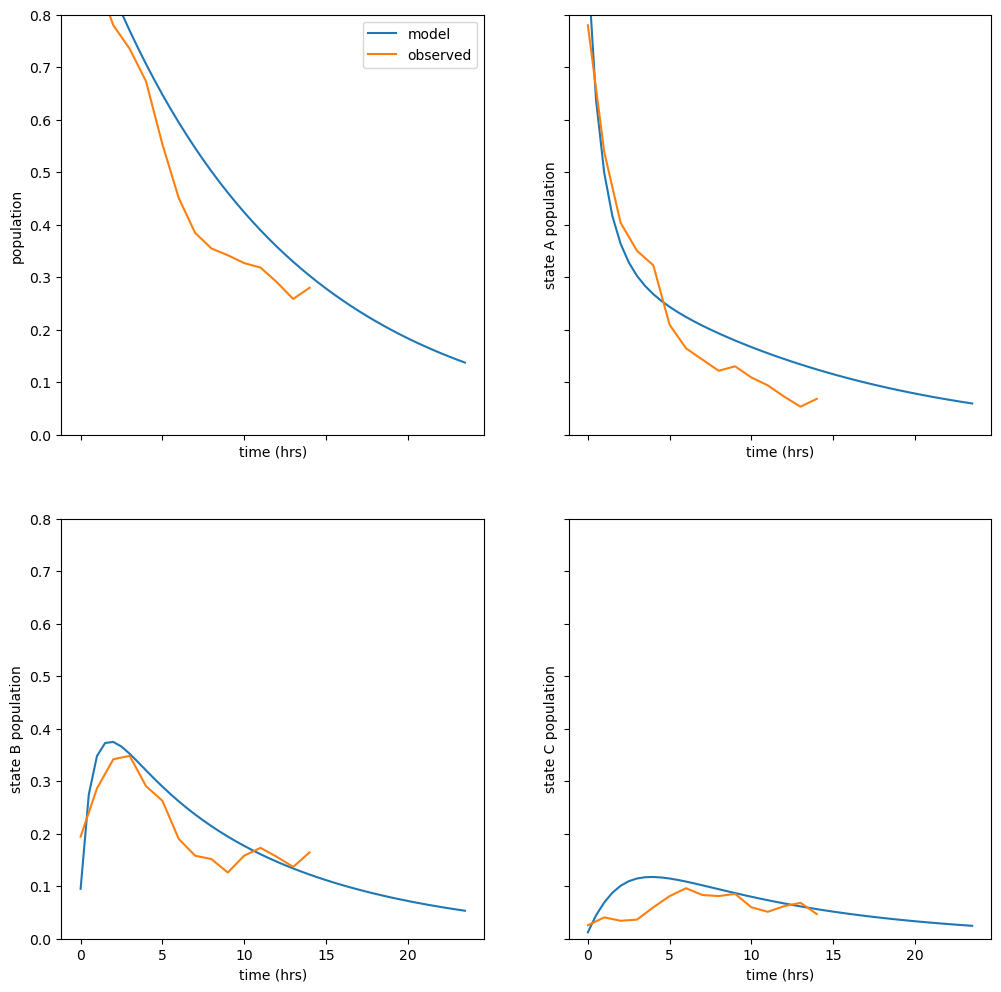

In [103]:
# Clean the matrix with death_boost, start from the initial occupancy and propagate prob = prob @ P for Nt=48 half-hour steps;
# compare the live population per kinetic state with the observed occupancy (state_probs_times, treatment 0).
# clean_P works in place, so re-running this cell cleans P_states again; re-run the matrix cell above first.
death_boost=3.15 # regular Mcl1i
# death_boost used for the other treatments: 2.0 (FGFRi combo), 2.25 (pazo combo)
P_states=clean_P(P_states,pdeath_ERKhigh=pdeath_ERKhigh,pdeath_ERKlow=pdeath_ERKlow,death_boost=death_boost,states_death_dead=states_death_dead,states_death_alive=states_death_alive,states_death_ERKlow=states_death_ERKlow,states_death_ERKhigh=states_death_ERKhigh,states_death_Ndhigh=states_death_Ndhigh,states_death_Ndlow=states_death_Ndlow)

prob_initial=get_initial_state_distribution()

Nt=48
times=np.arange(Nt)*.5
prob0=prob_initial.copy()
prob=prob0.copy()
mfpt=np.zeros(n_states)
prob_states=np.zeros((n_states,Nt))
# live population per kinetic state = sum over its four alive (ERK x Nd) copies
prob_states[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
for itt in range(1,Nt):
    prob=np.matmul(prob,P_states)
    prob_states[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]

nplots=int(np.ceil(np.sqrt(n_states+1)))
fig,axs=plt.subplots(nplots,nplots,sharex=True,sharey=True,figsize=(12,12))
axs=axs.flatten()

axs[0].plot(times,np.sum(prob_states,axis=0),label='model')
axs[0].plot(time_inds-time_inds[0],np.sum(state_probs_times[0,...],axis=0),label='observed')
axs[0].set_ylabel('population')
axs[0].set_xlabel('time (hrs)')
axs[0].legend(loc='upper right')

for istate in range(n_states):
    ax=axs[istate+1]
    ax.plot(times,prob_states[istate,:])
    ax.plot(time_inds-time_inds[0],state_probs_times[0,istate,:])
    ax.set_ylim(0,.8)
    ax.set_ylabel(f'state {state_labels[istate]} population')
    ax.set_xlabel('time (hrs)')

for iplot in range(n_states+1,nplots):
    ax=axs[iplot]
    ax.axis('off')

**Cleaned transition matrix.** Plots the cleaned 24-state matrix (log scale) and saves `transition_matrix_states.svg`.

/tmp/ipykernel_33583/2864270132.py:2: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(P_states),origin='lower')


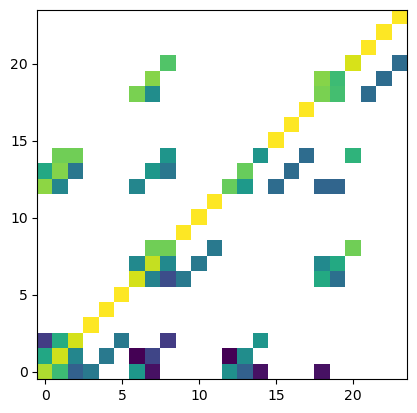

In [104]:
# Cleaned transition matrix (log scale)
plt.imshow(np.log(P_states),origin='lower')
plt.savefig(f'{date}/transition_matrix_states.svg')

**Death probability per state.** Bar plots of the one-step death probability by state in the four ERK x Nd combinations.

Text(0.5, 1.0, 'ERK-high and Nd-high')

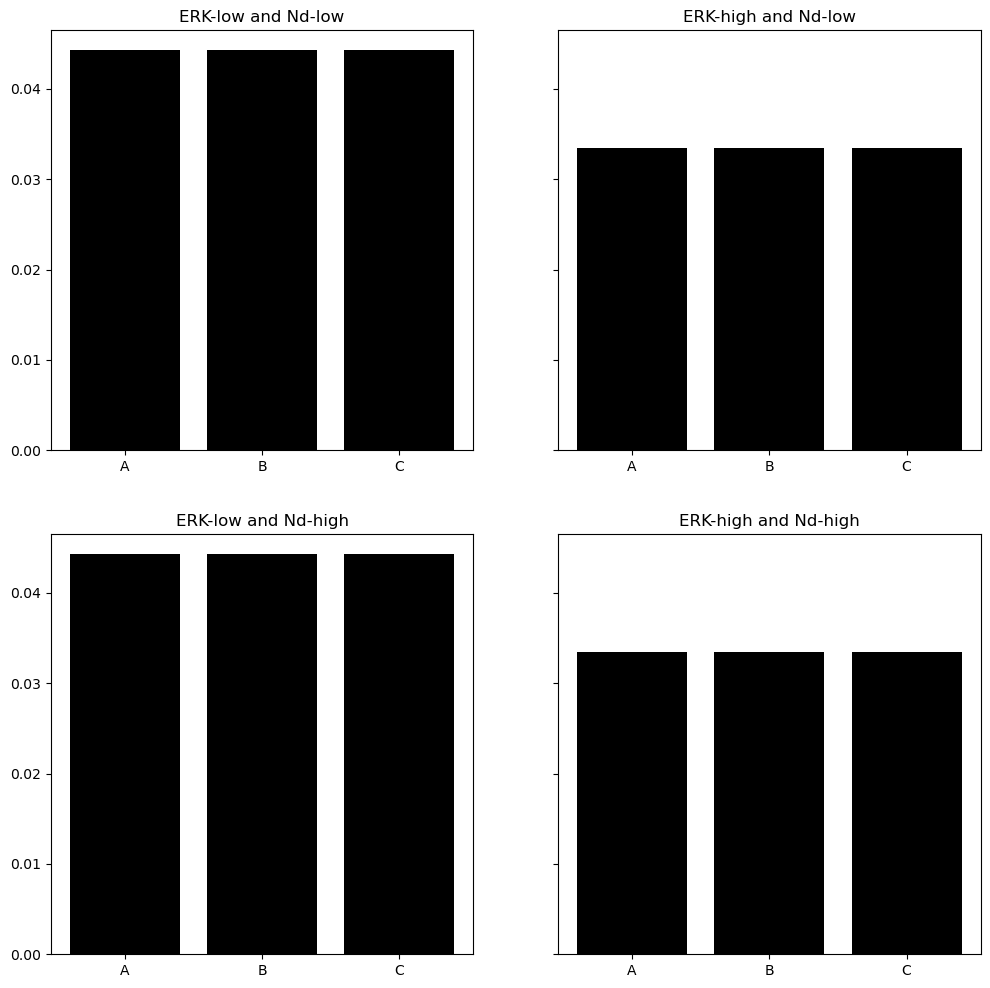

In [105]:
# One-step death probability of each kinetic state in the four ERK x Nd combinations
fig,axs=plt.subplots(2,2,sharey=True,figsize=(12,12))
axs=axs.flatten()
indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndlow)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_dead,states_death_dead)
indsto=np.intersect1d(indsto,states_death_dead)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[0].bar(np.arange(n_states),ptest,color='black')
axs[0].set_xticks(np.arange(n_states))
axs[0].set_xticklabels(state_labels)
axs[0].set_title('ERK-low and Nd-low')

indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndlow)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_dead,states_death_dead)
indsto=np.intersect1d(indsto,states_death_dead)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[1].bar(np.arange(n_states),ptest,color='black')
axs[1].set_xticks(np.arange(n_states))
axs[1].set_xticklabels(state_labels)
axs[1].set_title('ERK-high and Nd-low')

indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndhigh)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_dead,states_death_dead)
indsto=np.intersect1d(indsto,states_death_dead)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[2].bar(np.arange(n_states),ptest,color='black')
axs[2].set_xticks(np.arange(n_states))
axs[2].set_xticklabels(state_labels)
axs[2].set_title('ERK-low and Nd-high')

indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndhigh)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_dead,states_death_dead)
indsto=np.intersect1d(indsto,states_death_dead)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[3].bar(np.arange(n_states),ptest,color='black')
axs[3].set_xticks(np.arange(n_states))
axs[3].set_xticklabels(state_labels)
axs[3].set_title('ERK-high and Nd-high')

**ERK on/off rates per state.** Bar plots of switching probabilities in the same four combinations.

Text(0.5, 1.0, 'ERK-off rates and Nd-high')

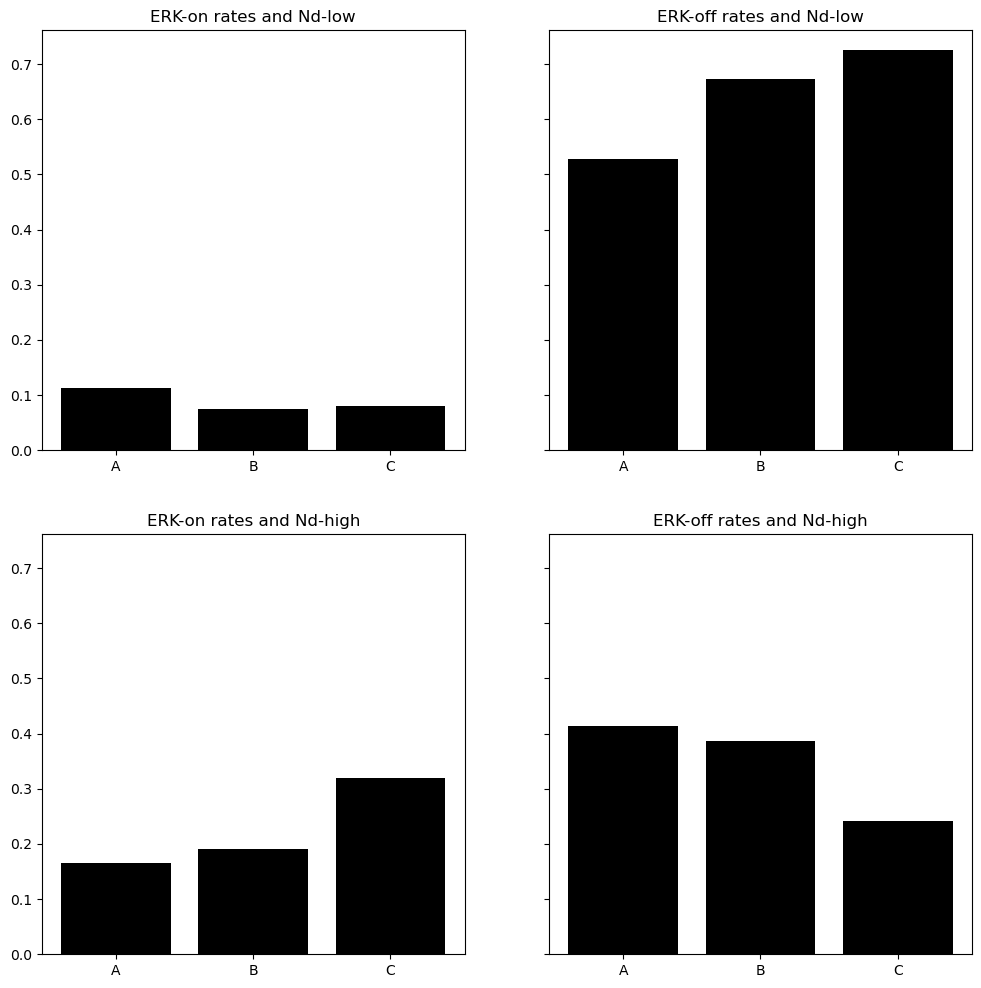

In [106]:
# ERK on (low->high) and off (high->low) probabilities of each kinetic state, for Nd low and high
fig,axs=plt.subplots(2,2,sharey=True,figsize=(12,12))
axs=axs.flatten()
indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndlow)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_ERKhigh,states_death_alive)
indsto=np.intersect1d(indsto,states_death_alive)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[0].bar(np.arange(n_states),ptest,color='black')
axs[0].set_xticks(np.arange(n_states))
axs[0].set_xticklabels(state_labels)
axs[0].set_title('ERK-on rates and Nd-low')

indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndlow)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_ERKlow,states_death_alive)
indsto=np.intersect1d(indsto,states_death_alive)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[1].bar(np.arange(n_states),ptest,color='black')
axs[1].set_xticks(np.arange(n_states))
axs[1].set_xticklabels(state_labels)
axs[1].set_title('ERK-off rates and Nd-low')

indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndhigh)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_ERKhigh,states_death_alive)
indsto=np.intersect1d(indsto,states_death_alive)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[2].bar(np.arange(n_states),ptest,color='black')
axs[2].set_xticks(np.arange(n_states))
axs[2].set_xticklabels(state_labels)
axs[2].set_title('ERK-on rates and Nd-high')

indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndhigh)
indsfrom=np.intersect1d(indsfrom,states_death_alive)
indsto=np.intersect1d(states_death_ERKlow,states_death_alive)
indsto=np.intersect1d(indsto,states_death_alive)
ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)

axs[3].bar(np.arange(n_states),ptest,color='black')
axs[3].set_xticks(np.arange(n_states))
axs[3].set_xticklabels(state_labels)
axs[3].set_title('ERK-off rates and Nd-high')

### 14.2 Visualization helpers

**Function `get_state_fluxplot`.** Draws a network diagram: node size = probability, arrow width = flux `p_j P_jk`, with cutoffs `fcut` and `pcut`.

In [107]:
# Network plot: node size ~ state probability, arrow width ~ net flux p_j P_jk - p_k P_kj (only fluxes > fcut from states with p > pcut)
def get_state_fluxplot(P_states,state_probs,state_centers,state_labels=None,ax=None,state_colors=None,fcut=.001,pcut=.02,lws=40.,rad=.3,sh=2,mscale=40.,point_mscale=1e7,arrowstyle='->,head_width=1.,head_length=1.'):
    n_states=state_probs.size
    if ax is None:
        fig,ax=plt.subplots(1,1)
    if state_labels is None:
        state_labels=[""]*n_states #np.array(list(string.ascii_uppercase))[0:nstates]
    if state_colors is None:
        state_colors=[]
        for istate in range(state_probs.size):
            state_colors.append(plt.cm.jet(istate/state_probs.size))
    for j in range(n_states):
        for k in range(n_states):
            fluxjk=state_probs[j]*P_states[j,k]
            fluxkj=state_probs[k]*P_states[k,j]
            flux=fluxjk-fluxkj
            if j<k and flux>fcut and state_probs[j]>pcut: #Mt[j,k]>pcut:
                arrow = matplotlib.patches.FancyArrowPatch((state_centers[j,0], state_centers[j,1]), (state_centers[k,0], state_centers[k,1]),shrinkA=sh,shrinkB=sh,mutation_scale=mscale*flux,color='black',arrowstyle=arrowstyle,connectionstyle='arc3,rad='+str(rad),lw=lws*flux,joinstyle='miter',capstyle='butt',alpha=.5) #note j and k flipped because drawing arrow at tail
                ax.add_patch(arrow)
            if j>k and flux>fcut and state_probs[j]>pcut: #Mt[j,k]>pcut:
                arrow = matplotlib.patches.FancyArrowPatch((state_centers[j,0], state_centers[j,1]), (state_centers[k,0], state_centers[k,1]),shrinkA=sh,shrinkB=sh,mutation_scale=mscale*flux,color='black',arrowstyle=arrowstyle,connectionstyle='arc3,rad='+str(rad),lw=lws*flux,joinstyle='miter',capstyle='butt',alpha=.5)
                ax.add_patch(arrow)
        ax.text(state_centers[j,0],state_centers[j,1],state_labels[j],color='black',ma='center')
        ax.scatter(state_centers[j,0],state_centers[j,1],s=point_mscale*state_probs[j],color=state_colors[j],alpha=.6)
    ax.set_xlim(np.min(state_centers[:,0])-.3,np.max(state_centers[:,0])+.3)
    ax.set_ylim(np.min(state_centers[:,1])-.3,np.max(state_centers[:,1])+.3)
    ax.axis('off')

**Colors for the 24 states.** `jet` colors repeated for the eight copies of the base states.

In [108]:
# One jet color per kinetic state, repeated for the 8 (alive/dead x Nd x ERK) copies
state_colors_all=[]
for istate in range(n_states):
    state_colors_all.append(plt.cm.jet(istate/n_states))
state_colors_all=state_colors_all*8
print(state_colors_all)

[(0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0), (0.0, 0.0, 0.5, 1.0), (0.0, 0.8333333333333334, 1.0, 1.0), (1.0, 0.9012345679012348, 0.0, 1.0)]


**Layout of the 24-node diagram.** Defines the state labels (`state_labels_all`, for example `A L+ Nd- ERK-`) and the node coordinates: base state on x, ERK +/- as a small x shift, Nd +/- and live/dead as y offsets.

In [109]:
# Base kinetic-state labels (must match nstates)
state_labels = np.array(["A","B","C"])

# --- labels in the same order as stateSet_death: alive/dead, then Nd, then ERK ---
L0 = [s + " L+" for s in state_labels.tolist()] + [s + " L-" for s in state_labels.tolist()]
L1 = [lab + " Nd-" for lab in L0] + [lab + " Nd+" for lab in L0]
state_labels_all = [lab + " ERK-" for lab in L1] + [lab + " ERK+" for lab in L1]

# --- Geometry parameters ---
x_base = {s:i for i, s in enumerate(state_labels.tolist())}  # A->0, B->1, C->2
# Offsets
dy_nd   = .2   # vertical separation for Nd +/-
dx_erk  = 0.25  # small x shift for ERK +/-
dy_dead = 0.25   # vertical shift for dead (above/below live)

# --- Compute coordinates in the SAME ORDER as state_labels_all ---
coords = []
for lab in state_labels_all:
    s, live_dead, nd_tag, erk_tag = lab.split()  # e.g., "A L+ Nd- ERK-"
    xtemp = x_base[s] + (-dx_erk if erk_tag == "ERK-" else +dx_erk)
    ytemp = (+dy_nd if nd_tag == "Nd+" else -dy_nd)
    if live_dead == "L-":
        ytemp += (+dy_dead if nd_tag == "Nd+" else -dy_dead)
    coords.append([xtemp, ytemp])

state_centers_all = np.array(coords)

# Quick sanity checks
print(len(state_labels_all), state_centers_all.shape)  # 24, (24,2)
# print(state_labels_all)  # uncomment to inspect order

24 (24, 2)


**Function `draw_headers`.** Adds row/column labels (live/dead, Nd, ERK) around the flux diagram.

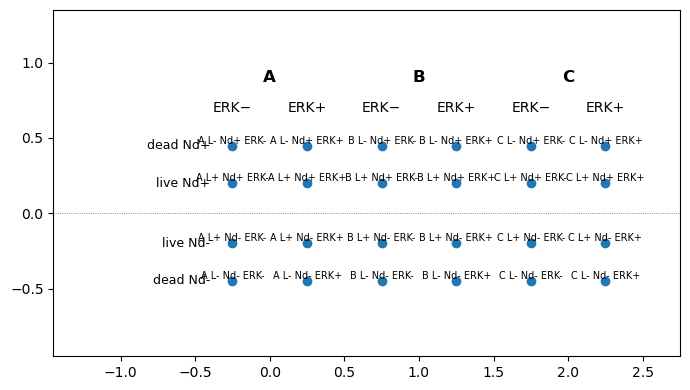

In [110]:
# Positions of the row/column headers around the 24-node diagram and draw_headers(ax) to add them; ends with a test plot of the layout
x_base = {s:i for i, s in enumerate(state_labels.tolist())}
# (no effect; shows the values when run on its own)
dy_nd, dx_erk, dy_dead
x_min = min(x_base.values()) - dx_erk
x_max = max(x_base.values()) + dx_erk
y_top =  dy_nd + dy_dead
y_bot = -dy_nd - dy_dead

# Left margins for row labels
x_margin_left_ld = 0.15   # live/dead row labels (closer to nodes)
x_margin_left_nd = 0.5   # Nd band labels (a bit further left)
y_margin=.4

x_left_ld = x_min - x_margin_left_ld
x_left_nd = x_min - x_margin_left_nd

# ---------------------------
# Row labels: live/dead moved to the LEFT
# ---------------------------
row_ld_labels = [
    "live Nd-", "dead Nd-",
    "live Nd+", "dead Nd+",
]
row_ld_xy = [
    [x_left_ld, -dy_nd],                 # live on Nd-
    [x_left_ld, -dy_nd - dy_dead],       # dead below live on Nd-
    [x_left_ld, +dy_nd],                 # live on Nd+
    [x_left_ld, +dy_nd + dy_dead],       # dead above live on Nd+
]
row_ld_pos = dict(zip(row_ld_labels, row_ld_xy))

# ---------------------------
# Nd band labels: centered in y between live/dead for each band, further left
# ---------------------------
row_nd_labels = ["Nd-", "Nd+"]
row_nd_xy = [
    [x_left_nd, -dy_nd - dy_dead/2.0],   # centered between live/dead on Nd-
    [x_left_nd, +dy_nd + dy_dead/2.0],   # centered between live/dead on Nd+
]
row_nd_pos = dict(zip(row_nd_labels, row_nd_xy))

# ---------------------------
# Column labels (same as before)
# ---------------------------
col_labels_major = state_labels.tolist()
col_label_major_xy = [[x_base[s], y_top + y_margin] for s in col_labels_major]
col_labels_major_pos = dict(zip(col_labels_major, col_label_major_xy))

col_labels_minor = []
col_label_minor_xy = []
for s in state_labels.tolist():
    col_labels_minor += [f"{s} ERK-", f"{s} ERK+"]
    col_label_minor_xy += [
        [x_base[s] - dx_erk, y_top + y_margin/2],   # ERK-
        [x_base[s] + dx_erk, y_top + y_margin/2],   # ERK+
    ]
col_labels_minor_pos = dict(zip(col_labels_minor, col_label_minor_xy))

# ---------------------------
# Helper to draw everything (matplotlib)
# ---------------------------
def draw_headers(ax):
    # Nd band labels are not drawn; row_nd_pos only places the time stamp in the movie frames

    # Live/dead row labels (left)
    for lab, (xt,yt) in row_ld_pos.items():
        ax.text(xt, yt, lab.replace("(Nd-", "").replace("(Nd+)", "").strip(),
                ha='right', va='center', fontsize=9)

    # Major column headers (A/B/C)
    for lab, (xt,yt) in col_labels_major_pos.items():
        ax.text(xt, yt, lab, ha='center', va='bottom', fontsize=12, fontweight='bold')

    # Minor column headers (ERK ± under each major)
    for lab, (xt,yt) in col_labels_minor_pos.items():
        ax.text(xt, yt, "ERK−" if lab.endswith("ERK-") else "ERK+",
                ha='center', va='bottom', fontsize=10)

# Test plot of the node layout with the headers
fig, ax = plt.subplots(figsize=(7,4))
ax.scatter(state_centers_all[:,0], state_centers_all[:,1])
for (xt,yt), lab in zip(state_centers_all, state_labels_all):
 ax.text(xt, yt, lab, fontsize=7, ha='center', va='bottom')
draw_headers(ax)
ax.set_xlim(x_min - 1.2, x_max + 0.5)
ax.set_ylim(y_bot - 0.5, y_top + 0.9)
ax.axhline(0, ls=':', lw=0.6)
plt.tight_layout(); plt.show()

**Function `get_state_barplot`.** Simple bar plot of a probability vector with state labels.

In [111]:
# Bar plot of a probability vector with state labels
def get_state_barplot(prob,ax=None,state_labels=None,color='black'):
    nstates=prob.size
    if ax is None:
        fig,ax=plt.subplots(1,1)
    if state_labels is None:
        state_labels=np.array(list(string.ascii_uppercase))[0:nstates]
    for istate in range(prob.size):
        ax.bar(istate,prob[istate],color=color)
    ax.set_xticks(np.arange(nstates))
    ax.set_xticklabels(state_labels)

**Nd labels.** `state_labels_Nd`: "A Nd-", "B Nd-", ..., used as bar labels.

In [112]:
# Bar labels for the alive copies by Nd: 'A Nd-', 'B Nd-', 'C Nd-', 'A Nd+', ...
state_labels_Nd=[state_label + ' Nd-' for state_label in state_labels.tolist()]+[state_label + ' Nd+' for state_label in state_labels.tolist()]

### 14.3 Simulation of treatment

**Initial distribution and flux plot.** Builds `prob_initial` from the initial cells (embedding + dead flag + Nd_death + ERK), assigns them to the 24 states and draws bar plots (live/dead x ERK) and the flux network. Saves `prob_initial_states.png` and `prob_initial_flux_states.svg`.

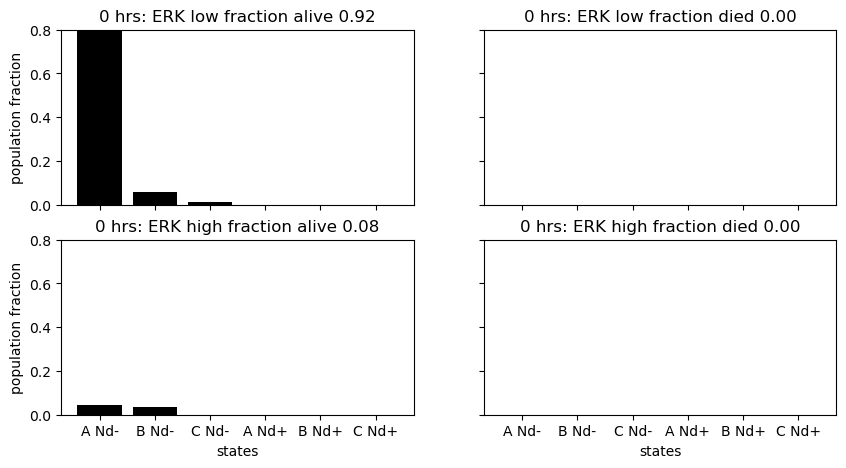

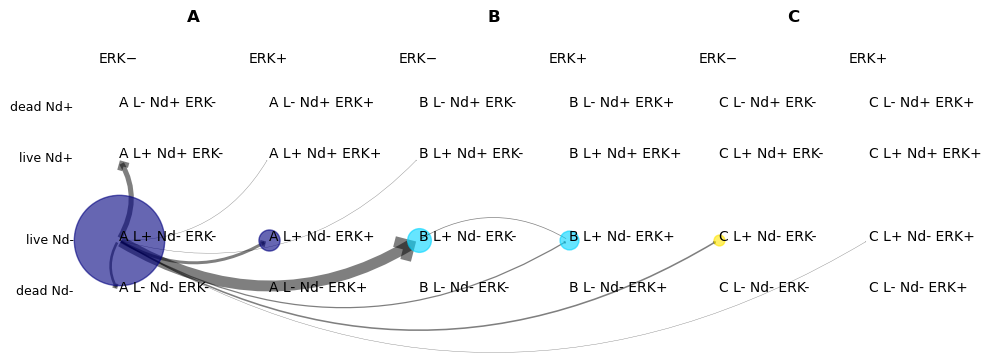

In [113]:
# Initial occupancy of the 24 states: bars for ERK low/high x alive/dead (each Nd- then Nd+), then the flux network
prob_initial=get_initial_state_distribution()

phigh=.8
prob=prob_initial.copy()
itt=0
fig,axs=plt.subplots(2,2,sharex=True,sharey=True,figsize=(10,5))
axs=axs.flatten()
#axs[0].scatter(state_centers_minima[:,0],state_centers_minima[:,1],s=30,c=prob[0:n_states],cmap=plt.cm.binary)#,clim=(0,1))
inds=np.intersect1d(states_death_ERKlow,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[0])
axs[0].set_ylim(0,phigh)
axs[0].set_title(f'{.5*itt:.0f} hrs: ERK low fraction alive {np.sum(prob[inds]):.2f}')
#axs[1].scatter(state_centers_minima[:,0],state_centers_minima[:,1],s=30,c=prob[n_states:2*n_states],cmap=plt.cm.binary)#,clim=(0,1))
inds=np.intersect1d(states_death_ERKlow,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[1])
axs[1].set_title(f'{.5*itt:.0f} hrs: ERK low fraction died {np.sum(prob[inds]):.2f}')
axs[1].set_ylim(0,phigh)
#axs[2].scatter(state_centers_minima[:,0],state_centers_minima[:,1],s=30,c=prob[2*n_states:3*n_states],cmap=plt.cm.binary)#,clim=(0,1))
inds=np.intersect1d(states_death_ERKhigh,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[2])
axs[2].set_title(f'{.5*itt:.0f} hrs: ERK high fraction alive {np.sum(prob[inds]):.2f}')
axs[2].set_ylim(0,phigh)
#axs[3].scatter(state_centers_minima[:,0],state_centers_minima[:,1],s=30,c=prob[3*n_states:],cmap=plt.cm.binary)#,clim=(0,1))
inds=np.intersect1d(states_death_ERKhigh,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[3])
axs[3].set_title(f'{.5*itt:.0f} hrs: ERK high fraction died {np.sum(prob[inds]):.2f}')
axs[3].set_ylim(0,phigh)
axs[0].set_ylabel('population fraction')
axs[2].set_xlabel('states')
axs[2].set_ylabel('population fraction')
axs[3].set_xlabel('states')
plt.savefig(f'{date}/prob_initial_states.png')
plt.show()

fig=plt.figure(figsize=(12,4))
ax=plt.gca()
get_state_fluxplot(P_states,prob_initial,state_centers_all,ax=ax,state_labels=state_labels_all,state_colors=state_colors_all,lws=50,mscale=50,sh=2,point_mscale=5000,fcut=.005)
draw_headers(ax)
plt.savefig(f'{date}/prob_initial_flux_states.svg')

**Flux plot of the initial distribution.** Repeats the flux plot of the previous cell on its own (overwrites `prob_initial_flux_states.svg`).

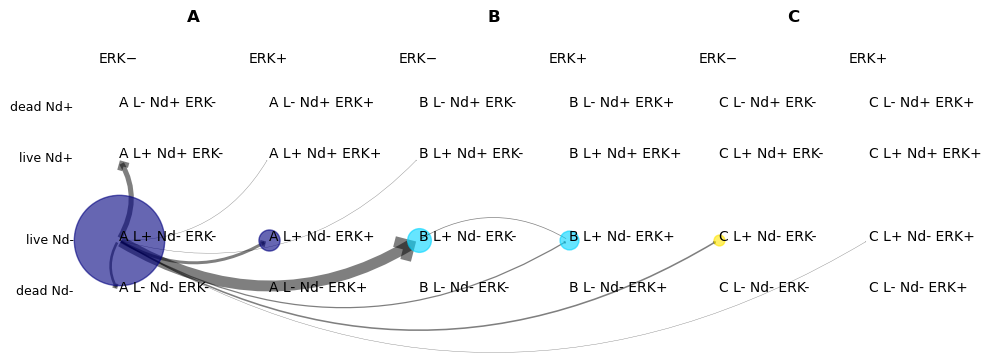

In [114]:
# Same flux plot as at the end of the previous cell (re-draws and overwrites prob_initial_flux_states.svg)
fig=plt.figure(figsize=(12,4))
ax=plt.gca()
get_state_fluxplot(P_states,prob_initial,state_centers_all,ax=ax,state_labels=state_labels_all,state_colors=state_colors_all,lws=50,mscale=50,sh=2,point_mscale=5000,fcut=.005)
draw_headers(ax)
plt.savefig(f'{date}/prob_initial_flux_states.svg')

**Propagate the model (regular Mcl1i).** Starts from `prob_initial` and iterates the cleaned matrix for `Nt=48` steps, collecting populations per state (`prob_states_erk`) and ERK-split populations. Saves one figure per time step (`probdeath_f####`) into `vizpath`.

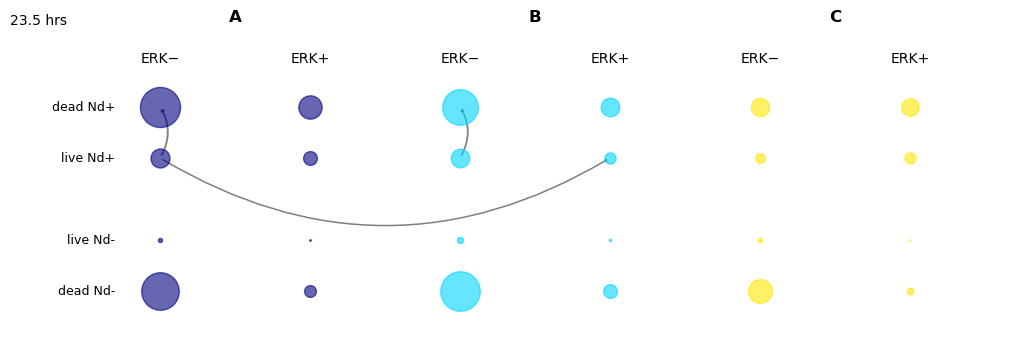

In [115]:
# Propagate the regular model (no ERK inhibition) for Nt=48 half-hour steps from prob_initial: live population per state,
# split by ERK, and one flux-network frame per step in {date}/movie_prob_death_states (for a movie).
# Kept as prob_states_erk*, prob_all (final distribution). mfpt is accumulated but not used.
Nt=48
x_states=state_centers_minima.copy()
prob0=prob_initial.copy()
prob=prob0.copy()
mfpt=np.zeros(n_states)
prob_states=np.zeros((n_states,Nt))
prob_states_ERKlow=np.zeros((n_states,Nt))
prob_states_ERKhigh=np.zeros((n_states,Nt))
prob_states[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
prob_states_ERKlow[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]
prob_states_ERKhigh[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
visual=True;vizpath=f'{date}/movie_prob_death_states'
os.system(f'mkdir {vizpath}')
for itt in range(1,Nt):
    prob=np.matmul(prob,P_states)
    prob_states[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
    prob_states_ERKlow[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]
    prob_states_ERKhigh[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
    mfpt=mfpt+.5*itt*prob[0:n_states]
    if visual and itt%1==0:
        clear_output(wait=True)
        fig=plt.figure(figsize=(12,4))
        ax=plt.gca()
        get_state_fluxplot(P_states,prob,state_centers_all,ax=ax,state_labels=None,state_colors=state_colors_all,lws=800,mscale=800,sh=2,point_mscale=5000,fcut=.001)
        draw_headers(ax)
        ax.text(row_nd_pos['Nd-'][0],col_labels_major_pos['A'][1],f'{.5*itt} hrs')
        plt.savefig(f'{vizpath}/probdeath_f{itt:04d}.png')
        plt.savefig(f'{vizpath}/probdeath_f{itt:04d}.svg')
        plt.show()
        plt.pause(.1)

prob_states_erk=prob_states.copy()
prob_states_erk_ERKhigh=prob_states_ERKhigh.copy()
prob_states_erk_ERKlow=prob_states_ERKlow.copy()
prob_all=prob.copy()

### 14.4 In-silico ERK inhibition

**In-silico ERK inhibition.** Zeroes alive ERK-low to ERK-high transitions, renormalizes, and shows the new matrix. Saves `transition_matrix_states_erki.svg`.

/tmp/ipykernel_33583/2431889050.py:14: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(P_states),origin='lower')


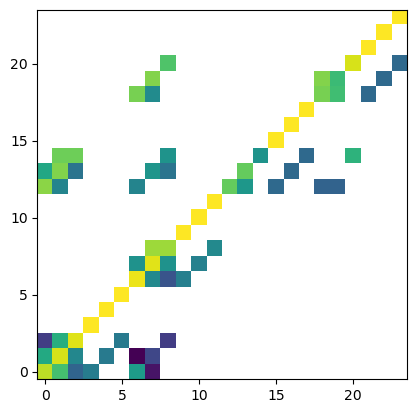

In [116]:
# In-silico ERK inhibition: remove all alive ERK-low -> ERK-high transitions and renormalize.
# Changes P_states in place; re-run the 14.1 cells before simulating the regular case again.
#ERKi
#erk inhibition
indsfrom=np.intersect1d(states_death_ERKlow,states_death_alive)
indsto=np.intersect1d(states_death_ERKhigh,states_death_alive)
for i in indsfrom:
    for j in indsto:
        P_states[i,j]=0.

for istate in range(P_states.shape[0]):
    P_states[istate,:]=P_states[istate,:]/np.sum(P_states[istate,:])

plt.imshow(np.log(P_states),origin='lower')
plt.savefig(f'{date}/transition_matrix_states_erki.svg')

**Initial distribution for the ERK-inhibition simulation.** The same construction, applied together with the modified matrix.

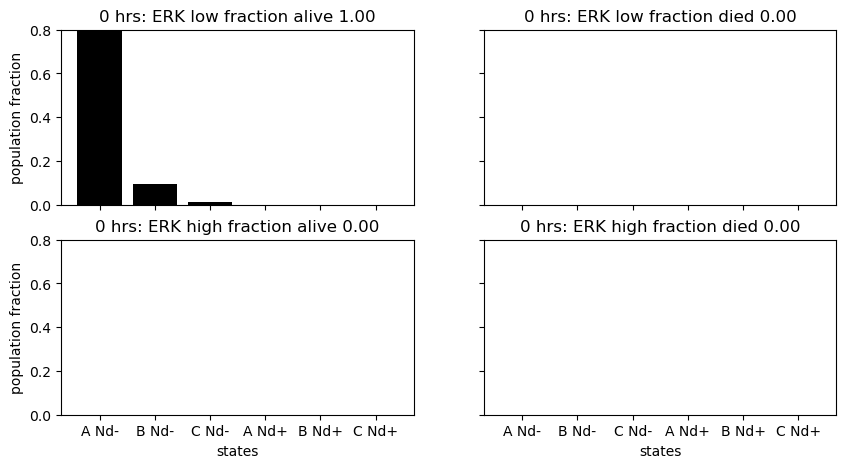

In [117]:
# Initial occupancy for the ERK-inhibition run: ERK-high cells are moved into the matching ERK-low states
prob_initial=get_initial_state_distribution()
prob_initial[states_death_ERKlow]=prob_initial[states_death_ERKlow]+prob_initial[states_death_ERKhigh]
prob_initial[states_death_ERKhigh]=0.

phigh=.8
prob=prob_initial.copy()
itt=0
fig,axs=plt.subplots(2,2,sharex=True,sharey=True,figsize=(10,5))
axs=axs.flatten()
inds=np.intersect1d(states_death_ERKlow,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[0])
axs[0].set_ylim(0,phigh)
axs[0].set_title(f'{.5*itt:.0f} hrs: ERK low fraction alive {np.sum(prob[inds]):.2f}')
inds=np.intersect1d(states_death_ERKlow,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[1])
axs[1].set_title(f'{.5*itt:.0f} hrs: ERK low fraction died {np.sum(prob[inds]):.2f}')
axs[1].set_ylim(0,phigh)
inds=np.intersect1d(states_death_ERKhigh,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[2])
axs[2].set_title(f'{.5*itt:.0f} hrs: ERK high fraction alive {np.sum(prob[inds]):.2f}')
axs[2].set_ylim(0,phigh)
inds=np.intersect1d(states_death_ERKhigh,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[3])
axs[3].set_title(f'{.5*itt:.0f} hrs: ERK high fraction died {np.sum(prob[inds]):.2f}')
axs[3].set_ylim(0,phigh)
axs[0].set_ylabel('population fraction')
axs[2].set_xlabel('states')
axs[2].set_ylabel('population fraction')
axs[3].set_xlabel('states')
plt.savefig(f'{date}/prob_initial_states_erki.png')
plt.show()

**Propagate the ERK-inhibition model.** Same as the regular simulation, with the inhibited matrix. Fills `prob_states_erki`.

In [ ]:
# Propagate the ERK-inhibited model (same steps as the regular run); frames go to {date}/movie_prob_death_states_erki
Nt=48
x_states=state_centers_minima.copy()
prob0=prob_initial.copy()
prob=prob0.copy()
mfpt=np.zeros(n_states)
prob_states=np.zeros((n_states,Nt))
prob_states_ERKlow=np.zeros((n_states,Nt))
prob_states_ERKhigh=np.zeros((n_states,Nt))
prob_states[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
prob_states_ERKlow[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]
prob_states_ERKhigh[:,0]=prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                   prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
visual=True;vizpath=f'{date}/movie_prob_death_states_erki'
os.system(f'mkdir {vizpath}')
for itt in range(1,Nt):
    prob=np.matmul(prob,P_states)
    prob_states[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
    prob_states_ERKlow[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKlow,states_death_Ndhigh),states_death_alive)]
    prob_states_ERKhigh[:,itt]=prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndlow),states_death_alive)]+\
                       prob[np.intersect1d(np.intersect1d(states_death_ERKhigh,states_death_Ndhigh),states_death_alive)]
    mfpt=mfpt+.5*itt*prob[0:n_states]
    if visual and itt%1==0:
        clear_output(wait=True)
        fig=plt.figure(figsize=(12,4))
        ax=plt.gca()
        get_state_fluxplot(P_states,prob,state_centers_all,ax=ax,state_labels=None,state_colors=state_colors_all,lws=800,mscale=800,sh=2,point_mscale=5000,fcut=.001)
        draw_headers(ax)
        ax.text(row_nd_pos['Nd-'][0],col_labels_major_pos['A'][1],f'{.5*itt} hrs')
        plt.savefig(f'{vizpath}/probdeath_f{itt:04d}.png')
        plt.savefig(f'{vizpath}/probdeath_f{itt:04d}.svg')
        plt.show()

prob_states_erki=prob_states.copy()
prob_states_erki_ERKlow=prob_states_ERKlow.copy()
prob_states_erki_ERKhigh=prob_states_ERKhigh.copy()

**Regular vs ERKi simulation summary.** 2x2 panels: population by state (regular and ERKi), the ERK-high/low split and the combined prediction. Saves `mcl1i_ERKi_sim.svg`.

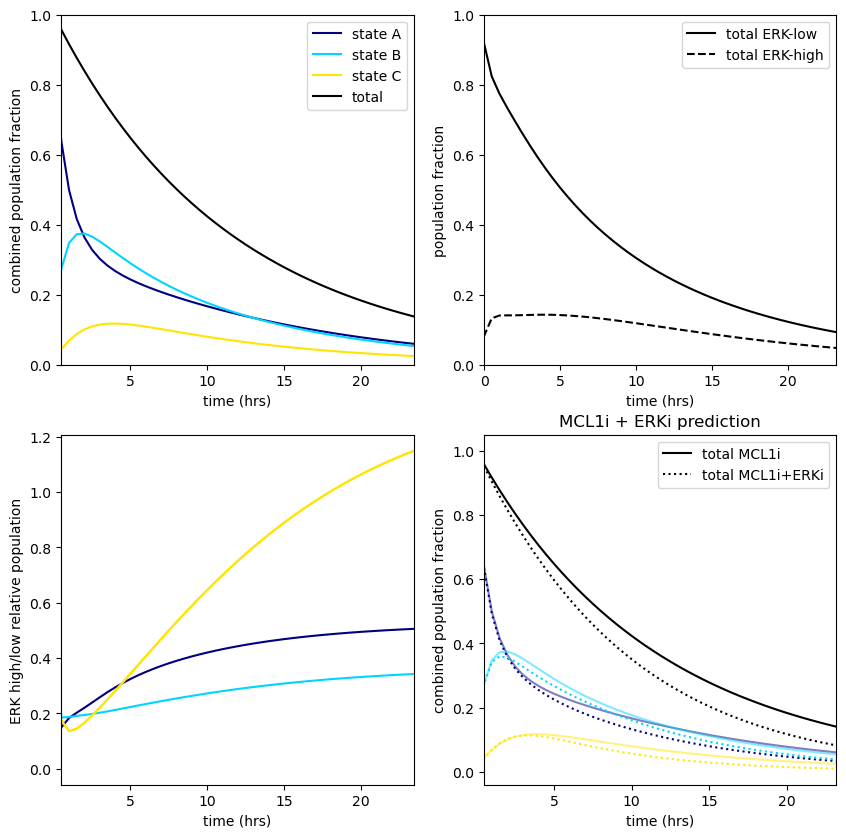

In [119]:
# Simulation summary: (0) live population per state and total, regular; (1) total ERK-low / ERK-high, regular;
# (2) ERK-high/ERK-low ratio per state, regular; (3) regular (solid) vs ERK-inhibited (dotted) populations and totals.
fig,axs=plt.subplots(2,2,figsize=(10,10)) 
axs=axs.flatten()
Nt=48
times=np.arange(Nt)*.5
xlim=Nt-1
ylim=.8
for istate in range(n_states):
    axs[0].plot(times,prob_states_erk[istate,:],color=plt.cm.jet(istate/n_states),label=f'state {state_labels[istate]}')
axs[0].set_xlim(0.5,times[xlim]-.05)
axs[0].set_ylim(0,ylim)
axs[0].set_ylabel('combined population fraction')
axs[0].set_xlabel('time (hrs)')

for istate in range(n_states):
    axs[3].plot(times,prob_states_erki[istate,:],':',color=plt.cm.jet(istate/n_states))#,label=f'state {state_labels[istate]}')
    axs[3].plot(times,prob_states_erk[istate,:],'-',color=plt.cm.jet(istate/n_states),alpha=.5)#,label=f'state {state_labels[istate]}')
axs[3].set_xlim(0.5,times[xlim]-.3)
axs[3].set_xlabel('time (hrs)')

axs[0].plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erk,axis=0),0,1.),color='black',label='total')
axs[0].set_xlim(0.5,times[xlim]-.05)
axs[0].set_ylim(0.,1)
axs[0].set_xlabel('time (hrs)')
axs[0].legend(loc='upper right')

axs[3].plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erk,axis=0),0,1.),'-',color='black',label='total MCL1i')
axs[3].plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erki,axis=0),0,1.),':',color='black',label='total MCL1i+ERKi')
axs[3].set_xlim(0.5,times[xlim]-.3)
axs[3].set_xlabel('time (hrs)')
axs[3].set_ylabel('combined population fraction')
axs[3].set_title('MCL1i + ERKi prediction')
axs[3].legend(loc='upper right')

for istate in range(n_states):
    axs[2].plot(times,np.divide(prob_states_erk_ERKhigh[istate,:],prob_states_erk_ERKlow[istate,:]),color=plt.cm.jet(istate/n_states),label=f'state {state_labels[istate]}')
axs[2].plot(times,np.divide(prob_states_erk_ERKhigh[istate,:],prob_states_erk_ERKlow[istate,:]),color=plt.cm.jet(istate/n_states),label=f'state {state_labels[istate]}')
# (the line above repeats the last state's curve)
axs[2].set_xlim(0.5,times[xlim]-.05)
axs[2].set_ylabel('ERK high/low relative population')
axs[2].set_xlabel('time (hrs)')

#    #plt.plot(times,np.divide(prob_states[istate,:],np.sum(prob_states,axis=0)),color=plt.cm.Reds(istate/n_states))

axs[1].plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erk_ERKlow,axis=0),0,1.),'-',color='black',label='total ERK-low')
axs[1].plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erk_ERKhigh,axis=0),0,1.),'--',color='black',label='total ERK-high')
axs[1].set_xlim(0,times[xlim]-.3)
axs[1].set_ylim(0,1)
axs[1].legend(loc='upper right')
axs[1].set_xlabel('time (hrs)')
axs[1].set_ylabel('population fraction')

plt.savefig(f'{date}/mcl1i_ERKi_sim.svg')

**Population snapshots.** Bar plots of live/dead x ERK populations at the final step (23.5 h) of the regular simulation (`prob_all`).

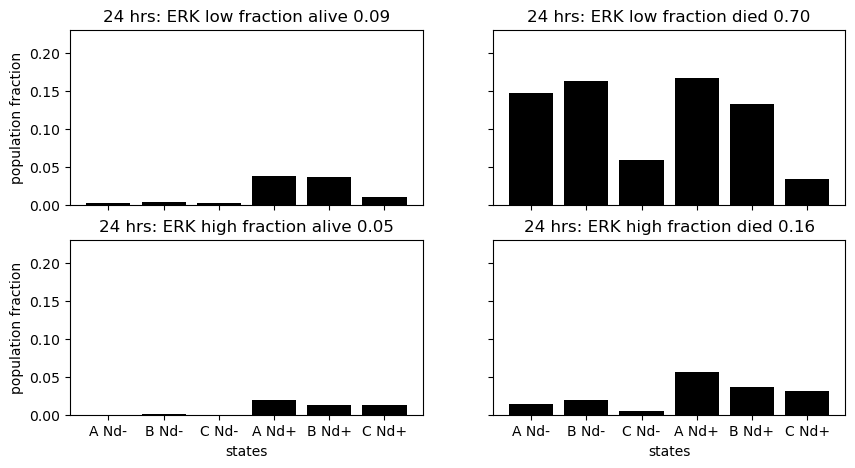

In [120]:
# Final (t = 23.5 h) occupancy of the regular simulation (prob_all) as live/dead x ERK bars; `itt` in the titles is the last step
prob=prob_all.copy()
phigh=.23
fig,axs=plt.subplots(2,2,sharex=True,sharey=True,figsize=(10,5))
axs=axs.flatten()
inds=np.intersect1d(states_death_ERKlow,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[0])
axs[0].set_ylim(0,phigh)
axs[0].set_title(f'{.5*itt:.0f} hrs: ERK low fraction alive {np.sum(prob[inds]):.2f}')
inds=np.intersect1d(states_death_ERKlow,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[1])
axs[1].set_title(f'{.5*itt:.0f} hrs: ERK low fraction died {np.sum(prob[inds]):.2f}')
axs[1].set_ylim(0,phigh)
inds=np.intersect1d(states_death_ERKhigh,states_death_alive)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[2])
axs[2].set_title(f'{.5*itt:.0f} hrs: ERK high fraction alive {np.sum(prob[inds]):.2f}')
axs[2].set_ylim(0,phigh)
inds=np.intersect1d(states_death_ERKhigh,states_death_dead)
get_state_barplot(prob[inds],state_labels=state_labels_Nd,ax=axs[3])
axs[3].set_title(f'{.5*itt:.0f} hrs: ERK high fraction died {np.sum(prob[inds]):.2f}')
axs[3].set_ylim(0,phigh)
axs[0].set_ylabel('population fraction')
axs[2].set_xlabel('states')
axs[2].set_ylabel('population fraction')
axs[3].set_xlabel('states')
plt.savefig(f'{date}/probfinal_mcl1i_sim.svg')

**Survival curves.** Total surviving fraction for the regular (black) and ERKi (purple) simulations.

Text(0.5, 1.0, 'MCL1i + complete ERK inhibition in silico')

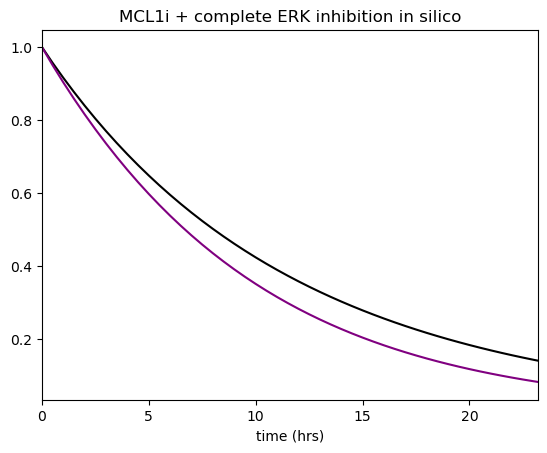

In [121]:
# Surviving fraction over time: regular (black) vs complete ERK inhibition (purple)
plt.plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erk,axis=0),0,1.),color='black')
plt.plot(np.insert(times,0,-1),np.insert(np.sum(prob_states_erki,axis=0),0,1.),color='purple')
plt.xlim(times[0],times[xlim]-.3)
plt.xlabel('time (hrs)')
plt.title('MCL1i + complete ERK inhibition in silico')

### 14.5 Bootstrap estimates, observed populations and comparison with the model

**Transition pairs for all models.** Like the earlier pair construction but for every good model, without the time restriction and without dropping rows, so that rows line up one-to-one with `x0set`. Stored as `x0set_death_all` / `x1set_death_all` so the treatment-specific pairs above are not overwritten.

In [122]:
# Augmented transition pairs (dead flag, Nd_death, ERK) for all good models, without a time limit and without dropping rows,
# so row k matches x0set[k] / inds_trajsteps[k]; the filtering happens in the bootstrap below.
x0set_death_all=[]
x1set_death_all=[]
fw_erk=1
min_nerk=0
for imodel in indgood_models:
    sctm=modelSet[imodel]
    indmodel=np.where(inds_trajsteps_models==imodel)[0]
    inds1=inds_trajsteps[indmodel,1]
    x0=x0set[indmodel,:]
    x1=x1set[indmodel,:]
    x0=np.append(x0,np.zeros(x0.shape[0])[:,np.newaxis],axis=1)
    x1=np.append(x1,np.zeros(x1.shape[0])[:,np.newaxis],axis=1)
    inds_death_trajsteps_model=np.where(np.isin(inds1,sctm.inds_death))[0]
    x1[inds_death_trajsteps_model,-1]=1.
    Nd0=sctm.Nd_death[inds_trajsteps[indmodel,0]]
    Nd1=sctm.Nd_death[inds_trajsteps[indmodel,1]]
    x0=np.append(x0,Nd0[:,np.newaxis],axis=1)
    x1=np.append(x1,Nd1[:,np.newaxis],axis=1)
    erk_model0=np.ones(inds1.size)*np.nan
    erk_model1=np.ones(inds1.size)*np.nan
    for i in range(inds1.size):
        ic0=inds_trajsteps[indmodel[i],0]
        ic1=inds_trajsteps[indmodel[i],1]
        erktraj0=sctm.x_signal[sctm.get_cell_trajectory(ic0)][-fw_erk:]
        good0=np.isfinite(erktraj0)
        if np.sum(good0)>min_nerk:
            erk_model0[i]=erktraj0[np.where(np.isfinite(erktraj0))[0][-1]]
        erktraj1=sctm.x_signal[sctm.get_cell_trajectory(ic1)][-fw_erk:]
        good1=np.isfinite(erktraj1)
        if np.sum(good1)>min_nerk:
            erk_model1[i]=erktraj1[np.where(np.isfinite(erktraj1))[0][-1]]
        if x1[i,inds_death_life]==1.:
            print(f'm{imodel} {erk_model0[i]} to {erk_model1[i]}')
    x0=np.append(x0,erk_model0[:,np.newaxis],axis=1)
    x1=np.append(x1,erk_model1[:,np.newaxis],axis=1)
    x0set_death_all.append(x0) #[indgood,:])
    x1set_death_all.append(x1) #[indgood,:])

x0set_death_all=np.concatenate(x0set_death_all)
x1set_death_all=np.concatenate(x1set_death_all)

m0 0.5341282191394648 to 0.6422966344461526
m0 0.8650872129147082 to 0.6726169542109433
m0 0.6726169542109433 to 0.6567343426748714
m0 nan to 0.7756558072384917
m0 nan to nan
m0 nan to 0.8794384235108991
m0 nan to 0.9750490074535165
m1 nan to 0.6855906288554772
m1 0.8973303941996373 to 0.8581182438026157
m1 nan to nan
m1 0.8915868564952159 to 0.851715252694747
m1 0.7455299495605817 to 0.8376895193178199
m1 1.1244935684173458 to nan
m2 0.6600090462724733 to 0.5546126029742163
m2 0.6856569244390336 to nan
m2 nan to nan
m2 nan to nan
m2 nan to 0.6699720502951539
m2 nan to 0.793628867007223
m2 nan to 1.0428266374540576
m2 nan to nan
m2 1.3204215650575069 to 1.0193940769552186
m2 nan to nan
m2 0.8212493532279027 to nan
m2 nan to 0.991048820907823


**Bootstrap estimates of switching and death rates.** Leave-one-imaging-set-out and bootstrap over models: for each resample builds and cleans the 24-state matrix and extracts, per state, ERK on/off probabilities for Nd-low and Nd-high and death probabilities for ERK low/high. Stores 95% credible intervals (`P_ons_Ndlow_CR`, ..., `P_deaths_ERKhigh_CR`).

In [123]:
# Bootstrap of the 24-state model for treatment 0, 0-25.5 h: leave one imaging set out, resample the rest nboots times,
# rebuild and clean the matrix (same death_boost) and read per kinetic state the ERK on/off probabilities (Nd low / high)
# and the death probabilities (ERK low / high, Nd low). *_CR arrays = [mean, 95% low, 95% high] per state.
# Overwrites P_states, pdeath_ERKhigh and pdeath_ERKlow with the values of the last resample.
tms=[0] #for mcl1i
tl=0
tu=25.5
nboots=100
for iplot in range(len(tms)):
    i_tm=tms[iplot]
    indmodels=np.where(inds_tmSet_models==i_tm)[0]
    P_ons_Ndlow_set=[]
    P_ons_Ndhigh_set=[]
    P_offs_Ndlow_set=[]
    P_offs_Ndhigh_set=[]
    P_deaths_ERKlow_set=[]
    P_deaths_ERKhigh_set=[]
    P_ons_Ndlow_CR=np.zeros((n_states,3))
    P_ons_Ndhigh_CR=np.zeros((n_states,3))
    P_offs_Ndlow_CR=np.zeros((n_states,3))
    P_offs_Ndhigh_CR=np.zeros((n_states,3))
    P_deaths_ERKlow_CR=np.zeros((n_states,3))
    P_deaths_ERKhigh_CR=np.zeros((n_states,3))
    imagingSets=np.unique(inds_imagingSet_models[indmodels])
    for iSet in imagingSets:
        x0=[]
        x1=[]
        indmodels_imagingSets=np.where(inds_imagingSet_models==iSet)[0]
        indmodels_Set=np.setdiff1d(indmodels,indmodels_imagingSets)
        indmodels_Set=np.intersect1d(indmodels_Set,indgood_models)
        for iboot in range(nboots):
            x0=[]
            x1=[]
            indmodels_boots= np.random.choice(indmodels_Set, size=indmodels_Set.size, replace=True)
            for imodel in indmodels_boots:
                sctm=modelSet[imodel]
                inds_model=np.where(inds_trajsteps_models==imodel)[0]
                inds1=inds_trajsteps[inds_model,1]
                times1=sctm.cells_timeSet[inds1]
                inds_model=inds_model[np.logical_and(times1<tu,times1>tl)]
                inds1=inds1[np.logical_and(times1<tu,times1>tl)]
                x0m=x0set_death_all[inds_model,:]
                x1m=x1set_death_all[inds_model,:]
                indgood0=np.isfinite(np.sum(x0m,axis=1))
                indgood1=np.isfinite(np.sum(x1m,axis=1))
                indgood=np.logical_and(indgood0,indgood1)
                x0.append(x0set_death_all[inds_model[indgood],:])
                x1.append(x1set_death_all[inds_model[indgood],:])
            x0=np.concatenate(x0)
            x1=np.concatenate(x1)
            pdeath_ERKhigh=np.sum(np.logical_and(x1[:,inds_death_life]==1,x1[:,inds_death_ERK]>midcut))/np.sum(x1[:,inds_death_ERK]>midcut)
            pdeath_ERKlow=np.sum(np.logical_and(x1[:,inds_death_life]==1,x1[:,inds_death_ERK]<midcut))/np.sum(x1[:,inds_death_ERK]<midcut)
            P_states=model.get_transition_matrix_CG(x0,x1,clusters=clusters_death,states=stateSet_death,return_counts=True)
            P_states=clean_P(P_states,pdeath_ERKhigh=pdeath_ERKhigh,pdeath_ERKlow=pdeath_ERKlow,death_boost=death_boost,states_death_dead=states_death_dead,states_death_alive=states_death_alive,states_death_ERKlow=states_death_ERKlow,states_death_ERKhigh=states_death_ERKhigh,states_death_Ndhigh=states_death_Ndhigh,states_death_Ndlow=states_death_Ndlow)
            P_ons_Ndlow=np.zeros(n_states)
            P_ons_Ndhigh=np.zeros(n_states)
            P_offs_Ndlow=np.zeros(n_states)
            P_offs_Ndhigh=np.zeros(n_states)
            P_deaths_ERKlow=np.zeros(n_states)
            P_deaths_ERKhigh=np.zeros(n_states)
            indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndlow)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_ERKhigh,states_death_alive)
            indsto=np.intersect1d(indsto,states_death_alive)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_ons_Ndlow=ptest.copy()
            indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndlow)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_ERKlow,states_death_alive)
            indsto=np.intersect1d(indsto,states_death_alive)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_offs_Ndlow=ptest.copy()
            indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndhigh)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_ERKhigh,states_death_alive)
            indsto=np.intersect1d(indsto,states_death_alive)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_ons_Ndhigh=ptest.copy()
            indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndhigh)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_ERKlow,states_death_alive)
            indsto=np.intersect1d(indsto,states_death_alive)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_offs_Ndhigh=ptest.copy()
            indsfrom=np.intersect1d(states_death_ERKlow,states_death_Ndlow)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_dead,states_death_dead)
            indsto=np.intersect1d(indsto,states_death_dead)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_deaths_ERKlow=ptest.copy()
            indsfrom=np.intersect1d(states_death_ERKhigh,states_death_Ndlow)
            indsfrom=np.intersect1d(indsfrom,states_death_alive)
            indsto=np.intersect1d(states_death_dead,states_death_dead)
            indsto=np.intersect1d(indsto,states_death_dead)
            ptest=P_states[np.ix_(indsfrom,indsto)].sum(axis=1)
            P_deaths_ERKhigh=ptest.copy()
            # keep resamples in which the probability could be estimated
            if np.sum(P_ons_Ndlow>0.):
                P_ons_Ndlow_set.append(P_ons_Ndlow)
            if np.sum(P_ons_Ndhigh>0.):
                P_ons_Ndhigh_set.append(P_ons_Ndhigh)
            if np.sum(P_offs_Ndlow>0.):
                P_offs_Ndlow_set.append(P_offs_Ndlow)
            if np.sum(P_offs_Ndhigh>0.):
                P_offs_Ndhigh_set.append(P_offs_Ndhigh)
            if np.sum(P_deaths_ERKlow>0.):
                P_deaths_ERKlow_set.append(P_deaths_ERKlow)
            if np.sum(P_deaths_ERKhigh>-1): #include even if no counts for control# 0.):
                P_deaths_ERKhigh_set.append(P_deaths_ERKhigh)
    # helpers: list -> 2-D array (NaN row if empty), and the 95% credible interval of one column
    def as2d(lst):
        return np.array(lst) if len(lst)>0 else np.full((1,n_states),np.nan)

    def ci_col(col):
        col=col[np.isfinite(col)]
        if col.size<2:
            return np.array([np.nan,np.nan])
        return np.array(bayesian_bootstrap.central_credible_interval(
            bayesian_bootstrap.mean(col,n_replications=1000),alpha=.05))

    P_ons_Ndlow_set=as2d(P_ons_Ndlow_set)
    P_ons_Ndhigh_set=as2d(P_ons_Ndhigh_set)
    P_offs_Ndlow_set=as2d(P_offs_Ndlow_set)
    P_offs_Ndhigh_set=as2d(P_offs_Ndhigh_set)
    P_deaths_ERKhigh_set=as2d(P_deaths_ERKhigh_set)
    P_deaths_ERKlow_set=as2d(P_deaths_ERKlow_set)

    for arr,CR in [(P_ons_Ndlow_set,P_ons_Ndlow_CR),(P_ons_Ndhigh_set,P_ons_Ndhigh_CR),
                   (P_offs_Ndlow_set,P_offs_Ndlow_CR),(P_offs_Ndhigh_set,P_offs_Ndhigh_CR),
                   (P_deaths_ERKlow_set,P_deaths_ERKlow_CR),(P_deaths_ERKhigh_set,P_deaths_ERKhigh_CR)]:
        for i in range(n_states):
            col=arr[:,i]
            CR[i,0]=np.nanmean(col) if np.isfinite(col).any() else np.nan
            CR[i,1:]=ci_col(col)

**Index states by base state.** `states_death_bystate[i]` lists the 24-state indices that belong to base state i.

In [124]:
# 24-state indices that belong to each kinetic state (found by label substring)
states_death_bystate=[None]*n_states
for istate in range(n_states):
    states_death_bystate[istate]=np.where(np.char.find(state_labels_all,state_labels[istate])!=-1)[0]
    print(states_death_bystate[istate])

nstates_death=len(state_labels_all)

[ 0  3  6  9 12 15 18 21]
[ 1  4  7 10 13 16 19 22]
[ 2  5  8 11 14 17 20 23]


**Observed state populations vs time with bootstrap CIs.** For each half-hour step and imaging set, resamples models and computes the occupancy of each base state, overall and split by ERK state, relative to the initial count. Fills `prob_states_all`, `prob_states_erkon`, `prob_states_erkoff`.

In [125]:
# Observed state populations vs time, treatment 0: windows of tw=1 h every 0.5 h; for each imaging set and nboots model resamples,
# assign the trajectory points of the resampled models to the 24 states and scale by the relative number of cells with an ERK value.
# Result: prob_states_all / _erkon / _erkoff [time, state, (mean, 95% low, 95% high)].
# NOTE: x_traj uses all points of each model (not only the current window), so only the cell-number scaling changes with time;
# and cratio_erk is indexed with trajectory rows (indtraj), while cratio_erk_traj is the array aligned with those rows.
#get state probabilities
tms=[0]
tl=0
tu=25
tw=1 #frame window
timestep=.5
times_states=np.arange(tl,tu-tw,timestep)
nt=times_states.size
nboots=10
for iplot in range(len(tms)):
    i_tm=tms[iplot]
    prob_states_all=np.zeros((nt,n_states,3))
    prob_states_erkon=np.zeros((nt,n_states,3))
    prob_states_erkoff=np.zeros((nt,n_states,3))
    for itt in range(nt):
        tl=times_states[itt]
        tu=tl+tw
        indmodels=np.where(inds_tmSet_models==i_tm)[0]
        P_all_set=[]
        P_erkon_set=[]
        P_erkoff_set=[]
        P_all_CR=np.zeros((n_states,3))
        P_erkon_CR=np.zeros((n_states,3))
        P_erkoff_CR=np.zeros((n_states,3))
        imagingSets=np.unique(inds_imagingSet_models[indmodels])
        for iSet in imagingSets:
            x0=[]
            x1=[]
            indmodels_imagingSets=np.where(inds_imagingSet_models==iSet)[0]
            indmodels_Set=np.intersect1d(indmodels,indmodels_imagingSets)
            for iboot in range(nboots):
                x_traj=[]
                indmodels_boots= np.random.choice(indmodels_Set, size=indmodels_Set.size, replace=True)
                prob_all=np.zeros(nt)
                for itt_boot in range(nt):
                    tl_boot=times_states[itt_boot]
                    tu_boot=tl_boot+tw
                    indtm=np.where(np.isin(indcells_models,indmodels_boots))[0]
                    indstw=np.where(np.logical_and(times_models<tu_boot,times_models>=tl_boot))[0]
                    ind_erkgood=np.where(np.isfinite(cratio_erk))[0]
                    indstw=np.intersect1d(indstw,ind_erkgood)
                    indstw=np.intersect1d(indstw,indtm)
                    if itt_boot==0:
                        c0=indstw.size
                    prob_all[itt_boot]=indstw.size/c0
                for imodel in indmodels_boots:
                    sctm=modelSet[imodel]
                    inds_model=np.where(inds_trajsteps_models==imodel)[0]
                    indtraj=np.where(indtreatment_traj==imodel)[0]
                    xt=np.append(x[indtraj,:],np.zeros((indtraj.size,1)),axis=1)
                    xt=np.append(xt,Nd_death_traj[indtraj,np.newaxis],axis=1)
                    erkt=cratio_erk[indtraj,np.newaxis]
                    xt=np.append(xt,erkt,axis=1)
                    indgood=np.where(np.isfinite(np.sum(xt,axis=1)))[0]
                    x_traj.append(xt[indgood,:])
                x_traj=np.concatenate(x_traj)
                indc_traj=stateSet_death[clusters_death.assign(x_traj)]
                statesc,counts_c=np.unique(indc_traj,return_counts=True)
                counts_states=np.zeros(nstates_death)
                counts_states[statesc]=counts_c
                prob_states=counts_states/np.sum(counts_states)
                prob_states=prob_states*prob_all[itt]
                P_all=np.zeros(n_states)
                P_erkon=np.zeros(n_states)
                P_erkoff=np.zeros(n_states)
                for istate in range(n_states):
                    indsall=np.intersect1d(states_death_bystate[istate],states_death_alive)
                    P_all[istate]=np.sum(prob_states[indsall])
                    indson=np.intersect1d(indsall,states_death_ERKhigh)
                    P_erkon[istate]=np.sum(prob_states[indson])
                    indsoff=np.intersect1d(indsall,states_death_ERKlow)
                    P_erkoff[istate]=np.sum(prob_states[indsoff])
                P_all_set.append(P_all)
                P_erkon_set.append(P_erkon)
                P_erkoff_set.append(P_erkoff)
        P_all_set=np.array(P_all_set)
        P_erkon_set=np.array(P_erkon_set)
        P_erkoff_set=np.array(P_erkoff_set)
        for i in range(n_states):
            P_all_CR[i,0]=np.nanmean(P_all_set[:,i])
            P_erkon_CR[i,0]=np.nanmean(P_erkon_set[:,i])
            P_erkoff_CR[i,0]=np.nanmean(P_erkoff_set[:,i])
            P_all_CR[i,1:]=bayesian_bootstrap.central_credible_interval(bayesian_bootstrap.mean(P_all_set[:,i],n_replications=1000),alpha=.05)#bootstrap.get_CI(P_all_set[:,i],1000)
            P_erkon_CR[i,1:]=bayesian_bootstrap.central_credible_interval(bayesian_bootstrap.mean(P_erkon_set[:,i],n_replications=1000),alpha=.05)#bootstrap.get_CI(P_erkon_set[:,i],1000)
            P_erkoff_CR[i,1:]=bayesian_bootstrap.central_credible_interval(bayesian_bootstrap.mean(P_erkoff_set[:,i],n_replications=1000),alpha=.05)#bootstrap.get_CI(P_erkoff_set[:,i],1000)
        prob_states_all[itt,:,:]=P_all_CR
        prob_states_erkon[itt,:,:]=P_erkon_CR
        prob_states_erkoff[itt,:,:]=P_erkoff_CR
        print(f't{times_states[itt]} prob {prob_states_all[itt,:,0]}')

t0.0 prob [0.44126138 0.37574245 0.18299617]
t0.5 prob [0.40662682 0.3421005  0.17239866]
t1.0 prob [0.33221535 0.28729208 0.13498024]
t1.5 prob [0.27777456 0.23657664 0.11047574]
t2.0 prob [0.22854949 0.19343999 0.09167426]
t2.5 prob [0.16803733 0.14712453 0.06707396]
t3.0 prob [0.1665987  0.13357088 0.06872343]
t3.5 prob [0.15284528 0.12598791 0.06035167]
t4.0 prob [0.12845031 0.11217485 0.04753261]
t4.5 prob [0.13469877 0.10830451 0.05088362]
t5.0 prob [0.14155414 0.11052581 0.05257314]
t5.5 prob [0.13008229 0.10627958 0.04835524]
t6.0 prob [0.13907125 0.10803212 0.05269765]
t6.5 prob [0.11776812 0.0975527  0.04247758]
t7.0 prob [0.10830168 0.08608254 0.03972133]
t7.5 prob [0.068735   0.06289933 0.02100505]
t8.0 prob [0.09238973 0.06970829 0.03171326]
t8.5 prob [0.07762825 0.06749423 0.02902934]
t9.0 prob [0.0511849  0.04160044 0.02170865]
t9.5 prob [0.05105544 0.04268194 0.01995127]
t10.0 prob [0.08878707 0.07014433 0.03159935]
t10.5 prob [0.05452731 0.04388671 0.02012306]
t11.0 pr

**Smooth the observed populations over time.** Moving average over `fw=2` steps.

In [126]:
# Forward moving average of the observed populations over fw=2 time points
fw=2
prob_states_all_tsmth=np.zeros_like(prob_states_all)
prob_states_erkon_tsmth=np.zeros_like(prob_states_erkon)
prob_states_erkoff_tsmth=np.zeros_like(prob_states_erkoff)
prob_states_all_tsmth[0,:,:]=prob_states_all[0,:,:]
prob_states_erkon_tsmth[0,:,:]=prob_states_erkon[0,:,:]
prob_states_erkoff_tsmth[0,:,:]=prob_states_erkoff[0,:,:]
for itt in range(0,nt):
    fu=itt+fw
    if fu>nt:
        fu=nt
    indt=np.arange(itt,fu).astype(int)
    prob_states_all_tsmth[itt,:,:]=np.nanmean(prob_states_all[indt,:,:],axis=0)
    prob_states_erkon_tsmth[itt,:,:]=np.nanmean(prob_states_erkon[indt,:,:],axis=0)
    prob_states_erkoff_tsmth[itt,:,:]=np.nanmean(prob_states_erkoff[indt,:,:],axis=0)

**Observed vs. predicted state populations.** Rows: ERK-low and ERK-high cells; columns: kinetic states A, B, C. Solid lines and shaded bands show the observed (smoothed) population fraction with its 95% interval; dashed lines show the model prediction.

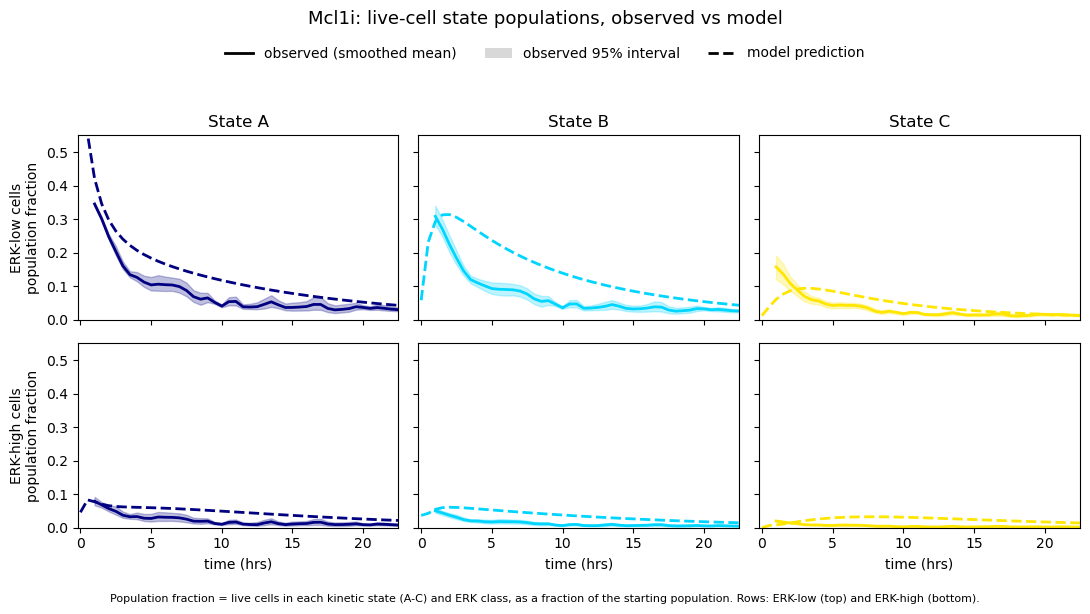

In [127]:
# Observed (smoothed, 95% band) vs predicted (dashed, regular simulation) live population per kinetic state, split by ERK
tm_name = tmSet[tms[0]]
fig,axs=plt.subplots(2,3,figsize=(11,6),sharex=True,sharey=True)

row_info=[('ERK-low cells',  prob_states_erkoff_tsmth, prob_states_erk_ERKlow),
          ('ERK-high cells', prob_states_erkon_tsmth,  prob_states_erk_ERKhigh)]

for irow,(row_label,obs,mod) in enumerate(row_info):
    for istate in range(n_states):
        ax=axs[irow,istate]
        c=plt.cm.jet(istate/n_states)
        ax.fill_between(times_states+tw,obs[:,istate,1],obs[:,istate,2],color=c,alpha=.25)
        ax.plot(times_states+tw,obs[:,istate,0],'-',color=c,lw=2)
        ax.plot(times,mod[istate,:].T,'--',color=c,lw=2)
        ax.set_xlim(-.2,22.5)
        ax.set_ylim(0,.55)
        if irow==0:
            ax.set_title(f'State {state_labels[istate]}',fontsize=12)
        if istate==0:
            ax.set_ylabel(f'{row_label}\npopulation fraction')
        if irow==1:
            ax.set_xlabel('time (hrs)')

legend_handles=[Line2D([0],[0],color='k',lw=2,label='observed (smoothed mean)'),
                Patch(facecolor='gray',alpha=.3,label='observed 95% interval'),
                Line2D([0],[0],color='k',lw=2,ls='--',label='model prediction')]
fig.legend(handles=legend_handles,loc='upper center',ncol=3,frameon=False,
           bbox_to_anchor=(0.5,0.955))
fig.suptitle(f'{tm_name}: live-cell state populations, observed vs model',y=0.995,fontsize=13)
fig.text(0.5,0.005,
         'Population fraction = live cells in each kinetic state (A-C) and ERK class, as a fraction of the starting population. '
         'Rows: ERK-low (top) and ERK-high (bottom).',
         ha='center',va='bottom',fontsize=8)

fig.tight_layout(rect=[0,0.035,1,0.90])
plt.savefig(f'{date}/state_probabilities_modelcomp_mcl1i.svg')
plt.savefig(f'{date}/state_probabilities_modelcomp_mcl1i.png',dpi=200)

**Initial distribution from the observed populations (regular case).** Defines `prob_initial` from the observed state populations at the first time point (ERK low and ERK high, Nd low). The next cell overwrites `prob_initial`, so re-run the propagation in 14.3 right after this cell to simulate from the observed initial population.

In [128]:
# prob_initial from the observed populations at the first time point (ERK low and high, Nd low).
# The next cell overwrites it, so run the 14.3 propagation in between if you want this version.
# regular case
prob_initial=np.zeros(n_states_death)
inds=np.intersect1d(states_death_Ndlow,states_death_alive)
inds=np.intersect1d(inds,states_death_ERKlow)
prob_initial[inds]=prob_states_erkoff_tsmth[0,:,0]
inds=np.intersect1d(states_death_Ndlow,states_death_alive)
inds=np.intersect1d(inds,states_death_ERKhigh)
prob_initial[inds]=prob_states_erkon_tsmth[0,:,0]

**Initial distribution from the observed populations (ERK-inhibition case).** The same, using only the ERK-low contribution.

In [129]:
# ERK-inhibition version: only the ERK-low populations, renormalized to 1
# ERK-inhibition case
prob_initial=np.zeros(n_states_death)
inds=np.intersect1d(states_death_Ndlow,states_death_alive)
inds=np.intersect1d(inds,states_death_ERKlow)
prob_initial[inds]=prob_states_erkoff_tsmth[0,:,0]
prob_initial=prob_initial/np.sum(prob_initial)

### 14.6 Summary plots of the estimated rates

**Bar plot of ERK switching rates.** Defines `plot_erk_switching` and plots the ERK ON/OFF rates for Nd-low vs. Nd-high across states A-C from the bootstrap estimates. Saves `erk_switching_model.svg`.

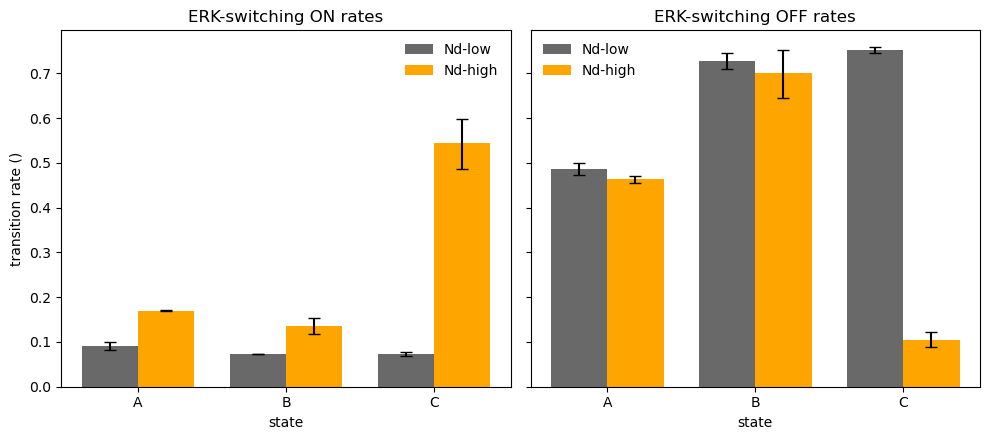

In [130]:
# Bar plots (95% CI error bars) of the bootstrap ERK ON and OFF probabilities per kinetic state, Nd-low vs Nd-high
def plot_erk_switching(
    P_offs_Ndlow_CR,   # shape (3,3): [mean, CI_low, CI_high] per state
    p_offs_Ndhigh_CR,  # shape (3,3)
    p_ons_Ndlow_CR,    # shape (3,3)
    p_ons_Ndhigh_CR,   # shape (3,3)
    state_labels=("A", "B", "C"),
    rate_units="",
    figsize=(10, 4.5)
):
    """
    Plots ERK-switching kinetic ON/OFF rates with 95% CI error bars
    for Nd-low and Nd-high across three states.

    Each input array is (3,3): rows = states A,B,C; cols = [mean, lowCI, highCI].
    """
    def ci_to_yerr(arr):
        """Return means and asymmetric yerr=[[lower...],[upper...]] for plt.bar."""
        arr = np.asarray(arr, dtype=float)
        means = arr[:, 0]
        lower = means - arr[:, 1]
        upper = arr[:, 2] - means
        # Ensure non-negative error magnitudes
        lower = np.clip(lower, 0, None)
        upper = np.clip(upper, 0, None)
        yerr = np.vstack([lower, upper])
        return means, yerr

    # Prepare data
    on_low_mean,  on_low_yerr  = ci_to_yerr(p_ons_Ndlow_CR)
    on_high_mean, on_high_yerr = ci_to_yerr(p_ons_Ndhigh_CR)
    off_low_mean, off_low_yerr  = ci_to_yerr(P_offs_Ndlow_CR)
    off_high_mean, off_high_yerr = ci_to_yerr(p_offs_Ndhigh_CR)

    x = np.arange(len(state_labels))
    width = 0.38

    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)

    # ON rates subplot
    ax = axes[0]
    ax.bar(x - width/2, on_low_mean,  width, yerr=on_low_yerr,  capsize=4, label='Nd-low',color='dimgray')
    ax.bar(x + width/2, on_high_mean, width, yerr=on_high_yerr, capsize=4, label='Nd-high',color='orange')
    ax.set_xticks(x, state_labels)
    ax.set_xlabel("state")
    ax.set_ylabel(f"transition rate ({rate_units})")
    ax.set_title("ERK-switching ON rates")
    ax.legend(frameon=False)

    # OFF rates subplot
    ax = axes[1]
    ax.bar(x - width/2, off_low_mean,  width, yerr=off_low_yerr,  capsize=4, label='Nd-low',color='dimgray')
    ax.bar(x + width/2, off_high_mean, width, yerr=off_high_yerr, capsize=4, label='Nd-high',color='orange')
    ax.set_xticks(x, state_labels)
    ax.set_xlabel("state")
    ax.set_title("ERK-switching OFF rates")
    ax.legend(frameon=False)

    fig.tight_layout()
    return fig, axes

plot_erk_switching(P_offs_Ndlow_CR, P_offs_Ndhigh_CR, P_ons_Ndlow_CR, P_ons_Ndhigh_CR)
plt.savefig(f'{date}/erk_switching_model.svg')

**Bar plot of death rates by ERK state.** Function `plot_erk_deaths_state_avg` (averages over states) and a call. Saves `death_rates_model.svg`.

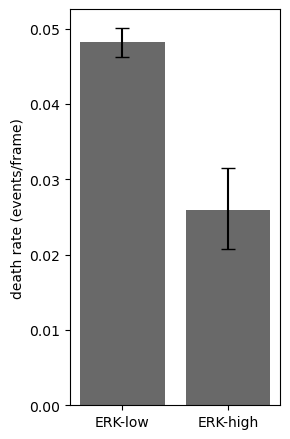

In [132]:
# Death probability of ERK-low vs ERK-high cells averaged over the kinetic states (mean and CI bounds averaged)
def plot_erk_deaths_state_avg(
    P_deaths_ERKhigh_CR,  # shape (3,3): rows=states A,B,C; cols=[mean, lowCI, highCI]
    P_deaths_ERKlow_CR,   # shape (3,3): rows=states A,B,C; cols=[mean, lowCI, highCI]
    ylabel="death rate (events/frame)",
    title="",
    figsize=(3, 4.5)
):
    """
    Make a single-panel bar plot of death probabilities for ERK-low vs ERK-high,
    where each is the average across states A/B/C. Error bars are asymmetric 95% CIs,
    formed by averaging the per-state CI bounds.

    Inputs:
      P_deaths_ERKhigh_CR: (3,3) array for ERK-high; cols = [mean, lowCI, highCI]
      P_deaths_ERKlow_CR : (3,3) array for ERK-low;  cols = [mean, lowCI, highCI]
    """

    def avg_across_states(arr):
        """Return aggregated [mean_of_means, mean_lowCI, mean_highCI] across states."""
        arr = np.asarray(arr, dtype=float)
        return np.nanmean(arr, axis=0)  # robust to NaNs if any

    def ci_to_yerr_from_triplet(triplet):
        """
        Convert [mean, lowCI, highCI] to asymmetric yerr for matplotlib.
        """
        mean, low, high = triplet
        lower = max(mean - low, 0.0)
        upper = max(high - mean, 0.0)
        return mean, np.array([[lower], [upper]])  # shape (2,1)

    # Aggregate across states
    high_triplet = avg_across_states(P_deaths_ERKhigh_CR)  # [mean, low, high]
    low_triplet  = avg_across_states(P_deaths_ERKlow_CR)

    # Convert to bar heights and error bars
    high_mean, high_yerr = ci_to_yerr_from_triplet(high_triplet)
    low_mean,  low_yerr  = ci_to_yerr_from_triplet(low_triplet)

    # Prepare plotting
    x = np.array([0, 1])
    heights = np.array([low_mean, high_mean])
    # Stack yerrs to match bars order: [ERK-low, ERK-high]
    yerr = np.hstack([low_yerr, high_yerr])  # shape (2,2)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(x, heights, yerr=yerr, capsize=5,color='dimgray')
    ax.set_xticks(x, ["ERK-low", "ERK-high"])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax

plot_erk_deaths_state_avg(P_deaths_ERKhigh_CR, P_deaths_ERKlow_CR)
plt.savefig(f'{date}/death_rates_model.svg')

## Appendix

Optional material that is not needed to reproduce the main analysis: rendering of 3-D tissue maps colored by ERK or state (A.1), export of 3-D segmentations (A.2), track curation with the optimal-transport cost (A.3) and the interactive manual validation of death calls (A.4).

### A.1 3-D tissue maps colored by ERK or kinetic state

**Projection helpers.** Rotation/flip functions (`transforms`) used to draw the three orthogonal projections in the rendering cells below.

In [133]:
# Projection helpers for the three orthogonal views (z, y, x): image transforms, axis order and coordinate flips for text labels
def notrans(arr):
    return arr

def rot_cw(arr):
    return np.fliplr(arr.T)

def rot2(arr):
    return np.flipud(arr)

def pcoord(x,n):
    return x

def ncoord(x,n):
    return n-x

transforms=[notrans,rot2,rot_cw]
coord_orders=[[0,1],[0,1],[1,0]]
htrans=[[pcoord,pcoord],[ncoord,pcoord],[pcoord,ncoord]]

**Boundary map colored by ERK.** For a chosen model (`imodel`, here 1) and frames (here 1 and 40), renders three orthogonal projections of the image with the lung and cancer surfaces, coloring each cell by its ERK c/n ratio (`hot`, 0.75-1.5). A colorbar is added on the last panel. Saves `boundarymap_ERK_*.svg`.

getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 4
getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 5


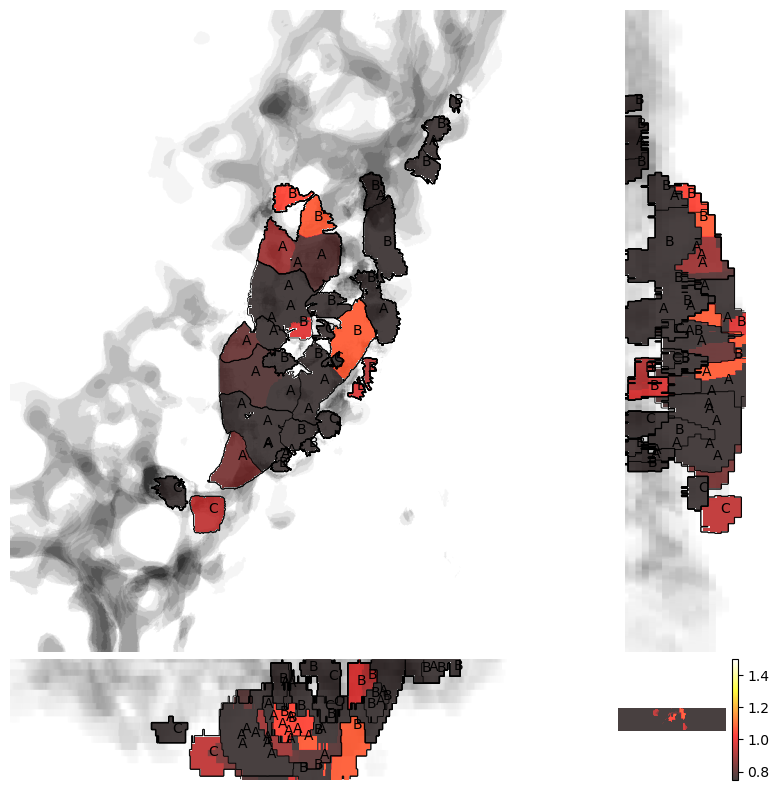

getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 4
getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 5


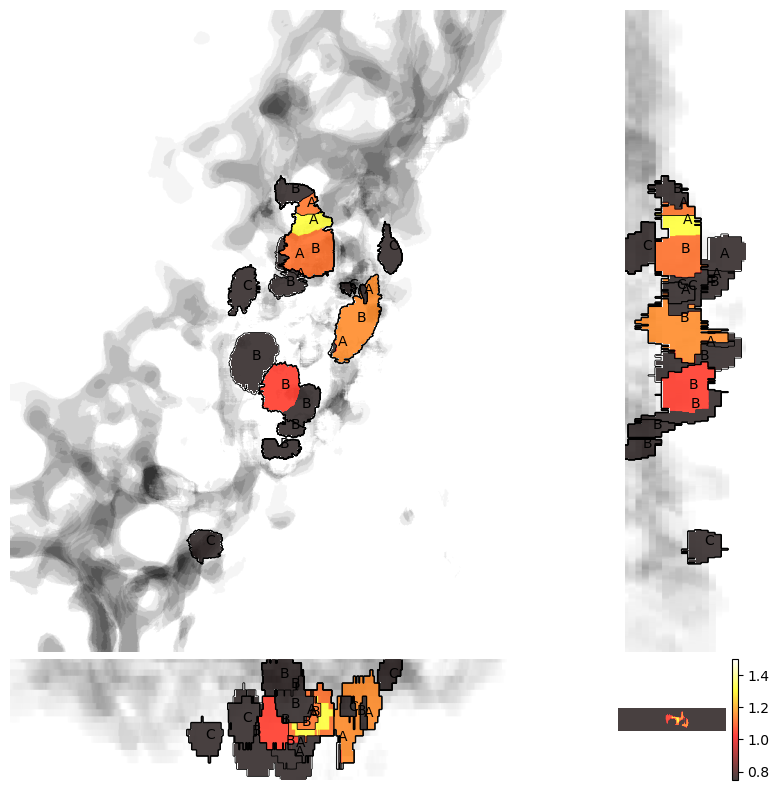

In [134]:
# Model 1, frames 1 and 40 after the first trajl frames: three orthogonal projections of the lung surface (gray) and cell outlines,
# cells filled by ERK c/n ratio (hot, 0.75-1.5) and labeled with their kinetic state. The colorbar is drawn on the last panel.
#new version rendered as image
vizpath=f'{date}/boundarystate_pics'
os.system(f'mkdir {vizpath}')
state_labels=np.array(list(string.ascii_uppercase))[0:nstates]
minc=2.
maxc=10.
berlin=Colormap('berlin').to_mpl()
berlinlow=berlin(.5);berlinhigh=berlin(1.)
dxcmap=berlin=Colormap([berlinlow,berlinhigh]).to_mpl()
for imodel in [1]: #indgood_models: #[89,78,83,62,51,32,33,34,36]: #indgood_models:
    sctm=modelSet[imodel]
    for iS in [1,40]: #range(trajl+1,sctm.nt):
        iframe=initial_frames_model[imodel]+trajl+iS
        boundary_library=sctm.boundary_library.copy()
        cyto_msk_channel=np.where(sctm.mask_channels==np.array(['cyto']).astype('S32'))[0][0]
        nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]
        rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        foreground_fmskchannel=np.where(sctm.fmask_channels==np.array(['foreground']).astype('S32'))[0][0]
        nuc_fmskchannel=np.where(sctm.fmask_channels==np.array(['nuc']).astype('S32'))[0][0]
        mskchannel=cyto_msk_channel; sctm.mskchannel=mskchannel
        cellinds=np.where(sctm.cells_frameSet==iframe)[0]
        img=sctm.get_image_data(iframe)
        msk=sctm.get_mask_data(iframe)
        # fmask channel 4 = lung surface, 5 = cancer surface
        fmsk_lung=sctm.get_fmask_data(iframe,channel=4)
        fmsk_cancer=sctm.get_fmask_data(iframe,channel=5)
        surfaces=[fmsk_lung,fmsk_cancer];np.array(surfaces).shape
        surface_label0=np.all(np.logical_not(np.array(surfaces)).astype(bool),axis=0)
        fmsk_airway=surface_label0.copy()
        border_scale=(sctm.micron_per_pixel/sctm.boundary_library['border_resolution'])*np.array([sctm.zscale,1,1])
        img_rep=img[...,erk_img_channel]
        msk_cyto=msk[...,cyto_msk_channel]
        msk_cyto=scipy.ndimage.zoom(msk[...,cyto_msk_channel],zoom=[sctm.zscale,1,1],order=0)
        fmsk_lung=scipy.ndimage.zoom(fmsk_lung,zoom=[sctm.zscale,1,1],order=0)
        fig = plt.figure(figsize=(10, 10))
        gs = gridspec.GridSpec(2, 2,width_ratios=[1,msk_cyto.shape[0]/msk_cyto.shape[1]],height_ratios=[1,msk_cyto.shape[0]/msk_cyto.shape[2]],
                               wspace=0.02, hspace=0.02)
        ax_z = fig.add_subplot(gs[0, 0])
        ax_y = fig.add_subplot(gs[0, 1]) #, sharey=ax_z)
        ax_x = fig.add_subplot(gs[1, 0]) #, sharex=ax_z)
        ax_blank = fig.add_subplot(gs[1, 1])  # unused
        ax_blank.axis('off')
        axs=[ax_z,ax_y,ax_x]
        for i_ax in range(3):
            ax=axs[i_ax]
            h_axs=np.setdiff1d(np.arange(3),[i_ax]).astype(int)
            nz=fmsk_lung.shape[i_ax]
            ax.imshow(transforms[i_ax](np.sum(fmsk_lung,axis=i_ax)).T,cmap=plt.cm.gray_r,alpha=.8,clim=(0,nz*.6))
            ax.contour(transforms[i_ax](np.max(msk_cyto,axis=i_ax)).T,colors='black',linewidths=.6,alpha=1.)
            cf=sctm.cancer_contact_fraction[cellinds]
            pf=sctm.primary_contact_fraction[cellinds]
            erkcn=sctm.x_signal[cellinds]
            indgood_erk=np.where(np.isfinite(erkcn))[0]
            erkcn[np.isnan(erkcn)]=0.
            dxcn=sctm.dx[cellinds]
            indgood_dx=np.where(np.isfinite(dxcn))[0]
            dxcn[np.isnan(dxcn)]=0.
            Nd=sctm.Nd_death[cellinds]
            msk_cyto_proj=np.max(msk_cyto,axis=i_ax)
            msk_cyto_proj_blank=np.ones_like(msk_cyto_proj)==0
            img=np.zeros_like(msk_cyto_proj).astype('float')
            for icell in range(cellinds.size):
                ic=cellinds[icell]
                indc=np.where(msk_cyto_proj==sctm.cells_labelidSet[ic])
                img[indc]=erkcn[icell]
                msk_cyto_proj_blank[indc]=True
            ax.imshow(transforms[i_ax](np.ma.masked_where(msk_cyto_proj_blank==0,img)).T,cmap=plt.cm.hot,alpha=.75,vmin=.75,vmax=1.5)
            testimg=transforms[i_ax](np.ma.masked_where(msk_cyto_proj_blank==0,img)).T
            nx=testimg.shape[0];ny=testimg.shape[1]
            # write each cell's kinetic-state letter at its center
            for istate in range(nstates):
                indcells_traj=inds_states[istate]
                indcells_model=np.where(indtreatment_traj==imodel)[0]
                indcells_state_traj=np.intersect1d(indcells_traj,indcells_model)
                indcells_state_model=cellinds1_traj[indcells_state_traj]
                cellinds_state=np.intersect1d(cellinds,indcells_state_model)
                indboundary=np.where(np.isin(sctm.boundary_library['global_index'],cellinds_state))[0]
                pts=sctm.boundary_library['pts'][indboundary,:]
                pts[...,0]=(pts[...,0]/border_scale[0])*sctm.zscale
                pts[...,1]=pts[...,1]/border_scale[1]
                pts[...,2]=pts[...,2]/border_scale[2]
                for ic in cellinds_state:
                    indc=np.where(sctm.boundary_library['global_index'][indboundary]==ic)[0]
                    cpt=np.nanmean(pts[indc,:],axis=0)
                    ax.text(htrans[i_ax][0](cpt[h_axs[coord_orders[i_ax][0]]],ny),htrans[i_ax][1](cpt[h_axs[coord_orders[i_ax][1]]],nx),state_labels[istate],color='black')
            ax.axis('off')
        plt.imshow(img,cmap=plt.cm.hot,alpha=.75,vmin=.75,vmax=1.5);plt.colorbar(); ##combine with top
        plt.savefig(f'{vizpath}/boundarymap_ERK_m{imodel}_frame{iS:04d}.svg')
        plt.show()

**Boundary map colored by kinetic state.** The same rendering for model 0 with each cell colored by its kinetic state; one image per frame is saved to `boundarystate_movies/` for making a movie.

mkdir: cannot create directory ‘30oct26/boundarystate_movies’: File exists


getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 4
getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 5


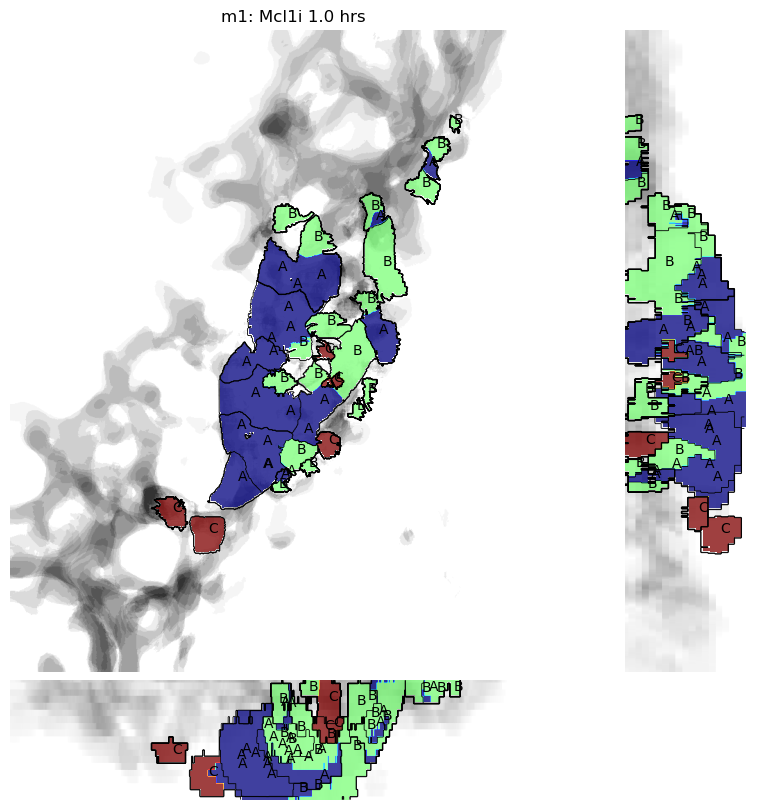

getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 4
getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 5


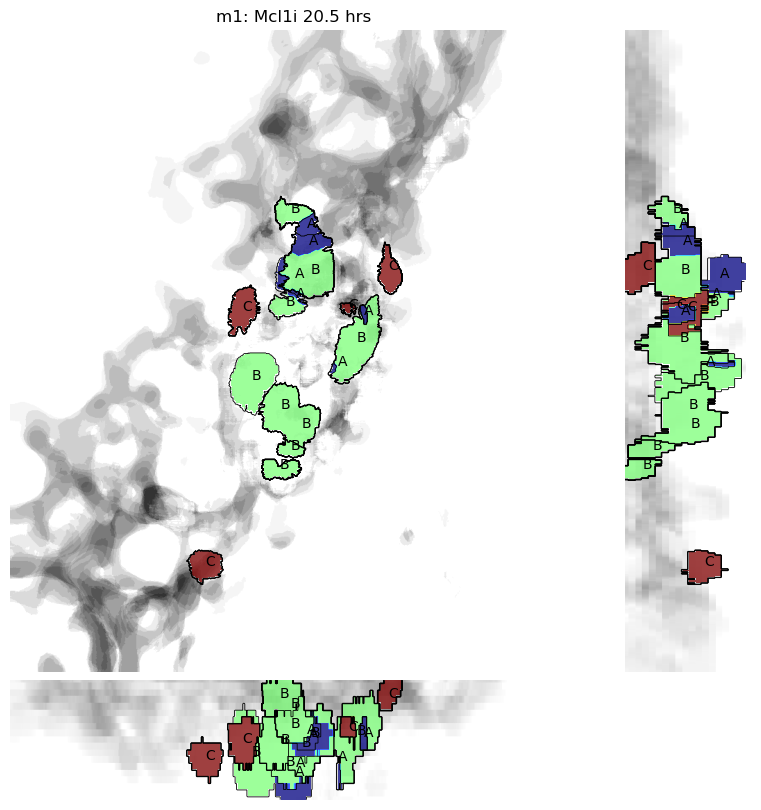

In [136]:
# Same rendering for model 0 with cells colored by kinetic state (jet); one image per frame in {date}/boundarystate_movies.
# The title uses `timestep` from an earlier cell (0.5 h).
#new version rendered as image
vizpath=f'{date}/boundarystate_movies'
os.system(f'mkdir {vizpath}')
state_labels=np.array(list(string.ascii_uppercase))[0:nstates]
minc=2.
maxc=10.
berlin=Colormap('berlin').to_mpl()
berlinlow=berlin(.5);berlinhigh=berlin(1.)
dxcmap=berlin=Colormap([berlinlow,berlinhigh]).to_mpl()
for imodel in [1]: 
    sctm=modelSet[imodel]
    for iS in [1,40]: #range(trajl+1,sctm.nt):
        iframe=initial_frames_model[imodel]+trajl+iS
        iframe=initial_frames_model[imodel]+trajl+iS
        boundary_library=sctm.boundary_library.copy()
        cyto_msk_channel=np.where(sctm.mask_channels==np.array(['cyto']).astype('S32'))[0][0]
        nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]
        rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
        foreground_fmskchannel=np.where(sctm.fmask_channels==np.array(['foreground']).astype('S32'))[0][0]
        nuc_fmskchannel=np.where(sctm.fmask_channels==np.array(['nuc']).astype('S32'))[0][0]
        mskchannel=cyto_msk_channel; sctm.mskchannel=mskchannel
        cellinds=np.where(sctm.cells_frameSet==iframe)[0]
        img=sctm.get_image_data(iframe)
        msk=sctm.get_mask_data(iframe)
        fmsk_lung=sctm.get_fmask_data(iframe,channel=4)
        fmsk_cancer=sctm.get_fmask_data(iframe,channel=5)
        surfaces=[fmsk_lung,fmsk_cancer];np.array(surfaces).shape
        surface_label0=np.all(np.logical_not(np.array(surfaces)).astype(bool),axis=0)
        fmsk_airway=surface_label0.copy()
        border_scale=(sctm.micron_per_pixel/sctm.boundary_library['border_resolution'])*np.array([sctm.zscale,1,1])
        img_rep=img[...,erk_img_channel]
        msk_cyto=msk[...,cyto_msk_channel]
        msk_cyto=scipy.ndimage.zoom(msk[...,cyto_msk_channel],zoom=[sctm.zscale,1,1],order=0)
        fmsk_lung=scipy.ndimage.zoom(fmsk_lung,zoom=[sctm.zscale,1,1],order=0)
        fig = plt.figure(figsize=(10, 10))
        gs = gridspec.GridSpec(2, 2,width_ratios=[1,msk_cyto.shape[0]/msk_cyto.shape[1]],height_ratios=[1,msk_cyto.shape[0]/msk_cyto.shape[2]],
                               wspace=0.02, hspace=0.02)
        ax_z = fig.add_subplot(gs[0, 0])
        ax_y = fig.add_subplot(gs[0, 1]) #, sharey=ax_z)
        ax_x = fig.add_subplot(gs[1, 0]) #, sharex=ax_z)
        ax_blank = fig.add_subplot(gs[1, 1])  # unused
        ax_blank.axis('off')
        axs=[ax_z,ax_y,ax_x]
        for i_ax in range(3):
            ax=axs[i_ax]
            h_axs=np.setdiff1d(np.arange(3),[i_ax]).astype(int)
            nz=fmsk_lung.shape[i_ax]
            ax.imshow(transforms[i_ax](np.sum(fmsk_lung,axis=i_ax)).T,cmap=plt.cm.gray_r,alpha=.8,clim=(0,nz*.6))
            ax.contour(transforms[i_ax](np.max(msk_cyto,axis=i_ax)).T,colors='black',linewidths=.6,alpha=1.)
            cf=sctm.cancer_contact_fraction[cellinds]
            pf=sctm.primary_contact_fraction[cellinds]
            erkcn=sctm.x_signal[cellinds]
            indgood_erk=np.where(np.isfinite(erkcn))[0]
            erkcn[np.isnan(erkcn)]=0.
            dxcn=sctm.dx[cellinds]
            indgood_dx=np.where(np.isfinite(dxcn))[0]
            dxcn[np.isnan(dxcn)]=0.
            msk_cyto_proj=np.max(msk_cyto,axis=i_ax)
            msk_cyto_proj_blank=np.ones_like(msk_cyto_proj)==0
            img=np.zeros_like(msk_cyto_proj).astype('float')
            for istate in range(nstates):
                indcells_traj=inds_states[istate]
                indcells_model=np.where(indtreatment_traj==imodel)[0]
                indcells_state_traj=np.intersect1d(indcells_traj,indcells_model)
                indcells_state_model=cellinds1_traj[indcells_state_traj]
                cellinds_state=np.intersect1d(cellinds,indcells_state_model)
                for icell in range(cellinds_state.size):
                    ic=cellinds_state[icell]
                    indc=np.where(msk_cyto_proj==sctm.cells_labelidSet[ic])
                    img[indc]=istate #pf[icell]
                    msk_cyto_proj_blank[indc]=True
            ax.imshow(transforms[i_ax](np.ma.masked_where(msk_cyto_proj_blank==0,img)).T,cmap=plt.cm.jet,alpha=.75,vmin=0,vmax=nstates-1)
            testimg=transforms[i_ax](np.ma.masked_where(msk_cyto_proj_blank==0,img)).T
            nx=testimg.shape[0];ny=testimg.shape[1]
            for istate in range(nstates):
                indcells_traj=inds_states[istate]
                indcells_model=np.where(indtreatment_traj==imodel)[0]
                indcells_state_traj=np.intersect1d(indcells_traj,indcells_model)
                indcells_state_model=cellinds1_traj[indcells_state_traj]
                cellinds_state=np.intersect1d(cellinds,indcells_state_model)
                indboundary=np.where(np.isin(sctm.boundary_library['global_index'],cellinds_state))[0]
                pts=sctm.boundary_library['pts'][indboundary,:]
                pts[...,0]=(pts[...,0]/border_scale[0])*sctm.zscale
                pts[...,1]=pts[...,1]/border_scale[1]
                pts[...,2]=pts[...,2]/border_scale[2]
                for ic in cellinds_state:
                    indc=np.where(sctm.boundary_library['global_index'][indboundary]==ic)[0]
                    cpt=np.nanmean(pts[indc,:],axis=0)
                    ax.text(htrans[i_ax][0](cpt[h_axs[coord_orders[i_ax][0]]],ny),htrans[i_ax][1](cpt[h_axs[coord_orders[i_ax][1]]],nx),state_labels[istate],color='black')
            ax.axis('off')
        ax_z.set_title(f'm{imodel}: {tmSet[inds_tmSet_models[imodel]]} {iframe*timestep:.1f} hrs')
        plt.savefig(f'{vizpath}/boundarymap_states_m{imodel}_{figid}_f{iframe:04d}.png')
        plt.savefig(f'{vizpath}/boundarymap_states_m{imodel}_{figid}_f{iframe:04d}.svg')
        plt.show()

### A.2 Export of 3-D segmentations

**Output folder for 3-D images.** Sets `vizpath` to `{date}/3Dsegmentations` and imports the `cmapfile` writer.

In [137]:
# Output folder for the 3-D exports; cmapfile writes volumes for an external 3-D viewer
import cmapfile
import pathlib
vizpath=f'{date}/3Dsegmentations'
os.system(f'mkdir {vizpath}')

0

**Function `show_3dseg_proj`.** Draws projections of a 3-D image with label masks and surfaces, rescaling z.

In [138]:
# Sum/max projections (z, x, y) of a 3-D image with label contours and optional surface overlays; z rescaled by zscale
def show_3dseg_proj(fig,im3d,labels,surfaces=None,surf_cmaps=None,labels2=None,fmsk=None,zscale=None,label_color='black',label2_color='red',img_cmap=plt.cm.gray_r):
    if zscale is not None:
        im3d=skimage.transform.rescale(im3d,(zscale,1,1),anti_aliasing=False)
        labels=skimage.transform.rescale(labels,(zscale,1,1),order=0)
        for isurf in range(len(surfaces)):
            surfaces[isurf]=skimage.transform.rescale(surfaces[isurf],(zscale,1,1),order=0)
        if labels2 is not None:
            labels2=skimage.transform.rescale(labels2,(zscale,1,1),order=0)
    if surf_cmaps is None and surfaces is not None:
        print(len(surfaces))
        surf_cmaps=[plt.cm.Blues,plt.cm.Greens,plt.cm.Reds,plt.cm.Purples,plt.cm.Oranges,plt.cm.Blues,plt.cm.Greens]
    if label_color is None:
        label_color='black'
    if label2_color is None:
        label2_color='red'
    if img_cmap is None:
        img_cmap=plt.cm.gray_r
    zproj=np.sum(im3d,axis=0)
    xproj=np.sum(im3d,axis=1)
    yproj=np.sum(im3d,axis=2)
    labels_zproj=np.max(labels,axis=0)
    labels_xproj=np.max(labels,axis=1)
    labels_yproj=np.max(labels,axis=2)
    plt.subplot(1,3,1)
    plt.imshow(zproj,cmap=img_cmap)
    plt.contour(labels_zproj,levels=np.arange(np.max(labels_zproj)),colors=label_color,linewidths=1)
    if surfaces is not None:
        for isurf in range(len(surfaces)):
            surf_viz=np.sum(surfaces[isurf],axis=0)
            plt.imshow(np.ma.masked_where(np.logical_not(surf_viz>0),surf_viz),alpha=.5,cmap=surf_cmaps[isurf])#,clim=(0,1))
    if labels2 is not None:
        labels2_zproj=np.max(labels2,axis=0)
        plt.contour(labels2_zproj,levels=np.arange(np.max(labels2_zproj)),colors=label2_color,linewidths=1)
    plt.axis('equal');plt.axis('off')
    plt.subplot(1,3,2)
    plt.imshow(xproj,cmap=img_cmap)
    plt.contour(labels_xproj,levels=np.arange(np.max(labels_xproj)),colors=label_color,linewidths=1)
    if surfaces is not None:
        for isurf in range(len(surfaces)):
            surf_viz=np.sum(surfaces[isurf],axis=1)
            plt.imshow(np.ma.masked_where(np.logical_not(surf_viz>0),surf_viz),alpha=.5,cmap=surf_cmaps[isurf])#,clim=(0,1))
    if labels2 is not None:
        labels2_xproj=np.max(labels2,axis=1)
        plt.contour(labels2_xproj,levels=np.arange(np.max(labels2_xproj)),colors=label2_color,linewidths=1)
    plt.axis('equal');plt.axis('off')
    plt.subplot(1,3,3)
    plt.imshow(yproj,cmap=img_cmap)
    plt.contour(labels_yproj,levels=np.arange(np.max(labels_yproj)),colors=label_color,linewidths=1)
    if labels2 is not None:
        labels2_yproj=np.max(labels2,axis=2)
        plt.contour(labels2_yproj,levels=np.arange(np.max(labels2_yproj)),colors=label2_color,linewidths=1)
    if surfaces is not None:
        for isurf in range(len(surfaces)):
            surf_viz=np.sum(surfaces[isurf],axis=2)
            plt.imshow(np.ma.masked_where(np.logical_not(surf_viz>0),surf_viz),alpha=.5,cmap=surf_cmaps[isurf])#,clim=(0,1))
    plt.axis('equal');plt.axis('off')

**Load a model and one frame for 3-D visualization.** Selects a model (`imodel`) and frame (`iS`), resolves the channel indices and loads the image, cell masks and lung foreground mask.

getting foreground mask from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5 fmask channel 5


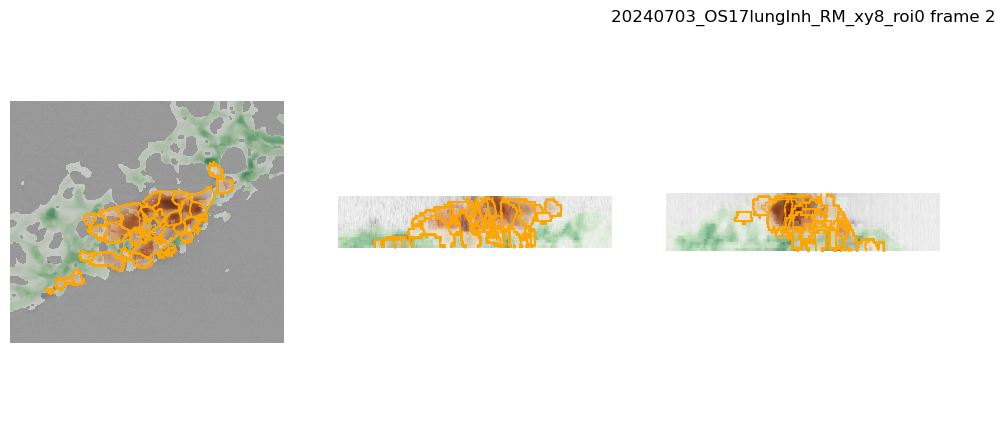

In [139]:
# Load model 1, frame iS=2: channel indices, image, masks and lung foreground mask, and show the projections
imodel=1
sctm=modelSet[imodel] #81]
fmsks_lung=sctm.fmsk_lung.copy()
iS=2
cons_fmsk_lung=fmsks_lung #[...,iS] #np.median(fmsks_lung,axis=3)
cyto_msk_channel=np.where(sctm.mask_channels==np.array(['cyto']).astype('S32'))[0][0]
nuc_fmsk_channel=np.where(sctm.fmask_channels==np.array(['nuc']).astype('S32'))[0][0]
rep_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
bf_img_channel=np.where(sctm.channels==np.array(['BF']).astype('S32'))[0][0]
erk_img_channel=np.where(sctm.channels==np.array(['YFP']).astype('S32'))[0][0]
nuc_img_channel=np.where(sctm.channels==np.array(['DAPI']).astype('S32'))[0][0]#Cy5']).astype('S32'))[0][0]
img=sctm.get_image_data(iS)
msk=sctm.get_mask_data(iS)
fmsks=sctm.get_fmask_data(iS,channel=5)
show_3dseg_proj(plt.figure(figsize=(12,5)),img[...,erk_img_channel],msk[...,0],surfaces=[cons_fmsk_lung,msk[...,0]>0],zscale=sctm.zscale,label_color='orange',surf_cmaps=[plt.cm.Greens,plt.cm.Oranges])
plt.title(f'{sctm.figid.decode()} frame {iS}')
plt.savefig(f'{vizpath}/ilastik_3dseg_{sctm.figid.decode()}_f{iS:04d}.svg')

**Export raw 3-D data.** Writes image channels and labels for the chosen frame with `cmapfile.array2cmap` for viewing in an external 3-D viewer.

In [ ]:
# Write the ERK and nuclear channels (img3d) and the cell + lung labels (label3d) of this frame with cmapfile
im3d=np.zeros((2,1,img.shape[0],img.shape[1],img.shape[2]))
im3d[0,0,:,:,:]=img[:,:,:,erk_img_channel]
im3d[1,0,:,:,:]=img[:,:,:,nuc_img_channel]
cmapfile.array2cmap(im3d, 'CTZXY', pathlib.Path(f'{vizpath}/frame{iS}_{sctm.figid.decode()}_img3d'), subsample=1, step=[1,1,sctm.zscale])
label3d=np.zeros((2,1,msk.shape[0],msk.shape[1],msk.shape[2])).astype(int)
label3d[0,0,:,:,:]=msk[:,:,:,cyto_msk_channel].astype(int)
label3d[1,0,:,:,:]=cons_fmsk_lung.astype(int)
cmapfile.array2cmap(label3d.astype('int32'), 'CTZXY', pathlib.Path(f'{vizpath}/frame{iS}_{sctm.figid.decode()}_label3d'), subsample=1, step=[1,1,sctm.zscale])
print(f'wrote {vizpath}/frame{iS}_{sctm.figid.decode()}')

**Export label volumes (transposed).** Same as the previous cell for the labels, with x/y transposed to match the viewer's convention.

In [ ]:
# Same label export with x and y transposed (label3dT) to match the viewer's axis convention
msk_T=np.zeros((msk.shape[0],msk.shape[2],msk.shape[1])).astype(int)
cons_fmsk_lung_T=np.zeros((msk.shape[0],msk.shape[2],msk.shape[1])).astype(int)
for iz in range(msk.shape[0]):
    cons_fmsk_lung_T[iz,...]=cons_fmsk_lung[iz,...].T
    msk_T[iz,...]=msk[iz,...,0].T

label3d=np.zeros((2,1,msk_T.shape[0],msk_T.shape[1],msk_T.shape[2])).astype(int)
label3d[0,0,:,:,:]=msk_T.astype(int)
label3d[1,0,:,:,:]=cons_fmsk_lung_T.astype(int)
cmapfile.array2cmap(label3d.astype('int32'), 'CTZXY', pathlib.Path(f'{vizpath}/frame{iS}_{sctm.figid.decode()}_label3dT'), subsample=1, step=[1,1,sctm.zscale])
print(f'wrote {vizpath}/frame{iS}_{sctm.figid.decode()}')

**Export state label volumes.** One label volume per kinetic state for the selected frame, using the state membership in `inds_states`.

In [ ]:
# One label volume per kinetic state for this frame (cells of model imodel in that state), plus a contour preview
msk_T=np.zeros((msk.shape[0],msk.shape[2],msk.shape[1])).astype(int)
cons_fmsk_lung_T=np.zeros((msk.shape[0],msk.shape[2],msk.shape[1])).astype(int)
for iz in range(msk.shape[0]):
    cons_fmsk_lung_T[iz,...]=cons_fmsk_lung[iz,...].T
    msk_T[iz,...]=msk[iz,...,0].T

label3d=np.zeros((n_states,1,msk_T.shape[0],msk_T.shape[1],msk_T.shape[2])).astype(int)
for istate in range(n_states):
    msk_state=msk_T.copy()
    indstate_traj=inds_states[istate]
    indmodel_traj=np.where(indtreatment_traj==imodel)[0]
    indstate_traj_model=np.intersect1d(indmodel_traj,indstate_traj)
    cellinds_model=cellinds0_traj[indstate_traj_model]
    cellinds_model_frame=cellinds_model[sctm.cells_frameSet[cellinds_model]==iS]
    labelids=sctm.cells_labelidSet[cellinds_model_frame]
    msk_state[np.logical_not(np.isin(msk_state,labelids))]=0
    label3d[istate,0,:,:,:]=msk_state.astype(int)
    plt.contour(np.isin(np.max(msk_T,axis=0),labelids),colors=[plt.cm.jet(istate/n_states)])

cmapfile.array2cmap(label3d.astype('int32'), 'CTZXY', pathlib.Path(f'{vizpath}/frame{iS}_{sctm.figid.decode()}_states_label3dT'), subsample=1, step=[1,1,sctm.zscale])#print(f'wrote {vizpath}/frame{iS}_states_{sctm.figid.decode()}')

**Export all frames.** Writes the cytoplasm labels of every frame as a 4-D volume. The loop overwrites `msk` and `iS`, so re-run the load cell before the brightfield overlays.

In [ ]:
# Cytoplasm labels of all frames as one 4-D volume (slow).
# This loop overwrites msk and iS, so re-run the load cell above before the brightfield overlays.
label3d=np.zeros((1,sctm.nt,msk.shape[0],msk.shape[1],msk.shape[2])).astype(int)
for iS in range(sctm.nt):
    msk=sctm.get_mask_data(iS)
    label3d[0,iS,:,:,:]=msk[:,:,:,cyto_msk_channel].astype(int) 

cmapfile.array2cmap(label3d.astype('int32'), 'CTZXY', pathlib.Path(f'{vizpath}/allframes_{sctm.figid.decode()}_label3d'), subsample=1, step=[1,1,sctm.zscale])

**Brightfield slice overlays.** For each z slice, draws the brightfield with lung and cancer masks and contours.

In [ ]:
# For each z slice of the selected frame: brightfield with lung (green) and cancer-cell (orange) masks and contours
im3d_bf=img[...,bf_img_channel]
for islice in range(im3d_bf.shape[0]):
    plt.figure(figsize=(12,12))
    msk_cyto=msk[...,0]
    plt.imshow(im3d_bf[islice,...],cmap=plt.cm.binary)
    fmsk_cancer=msk_cyto[islice,...]>0
    cons_fmsk_lung[islice,fmsk_cancer]=False
    plt.imshow(np.ma.masked_where(cons_fmsk_lung[islice,...]==0,np.ones_like(fmsks[islice,...]==0)),cmap=plt.cm.Greens,alpha=.2,clim=(0,1))
    plt.imshow(np.ma.masked_where(fmsk_cancer==0,np.ones_like(fmsks[islice,...]==0)),cmap=plt.cm.Oranges,alpha=.2,clim=(0,1))
    plt.contour(cons_fmsk_lung[islice,...],levels=[0,1],colors='green',linewidths=1.5,alpha=.8)
    plt.contour(msk_cyto[islice,...],levels=np.unique(msk_cyto[islice,...]),colors='orange',linewidths=2,alpha=.8)
    plt.axis('off')
    plt.savefig(f'{vizpath}/segmentation2d_{sctm.figid.decode()}_z{islice}.svg')
    plt.show()

### A.3 Track curation (optimal-transport cost)

Tracks are re-evaluated with an optimal-transport (OT) cost; links whose cost exceeds `ot_cut` are broken and the unique cell trajectories are rebuilt. The first cell recomputes the costs (and caches them in each `.h5` file) and shows their distribution, which was used to choose the cutoff.

**Re-tracking with the optimal-transport (OT) cost.** Recomputes each model's lineage with `get_lineage_min_otcost`, which stores the OT (earth mover's distance) cost of every cell-to-cell link, and plots the histogram of costs used to choose the cutoff. The results are saved to each `.h5` file (`save_h5=True, overwrite=True`), and the step is slow, so it is only needed once per dataset.

re-tracking dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
re-tracking dataset/20240703_OS17lungInh_RM_xy8_roi0.h5
re-tracking dataset/20240703_OS17lungInh_RM_xy9_roi0.h5


Text(0.5, 0, 'OT EMD')

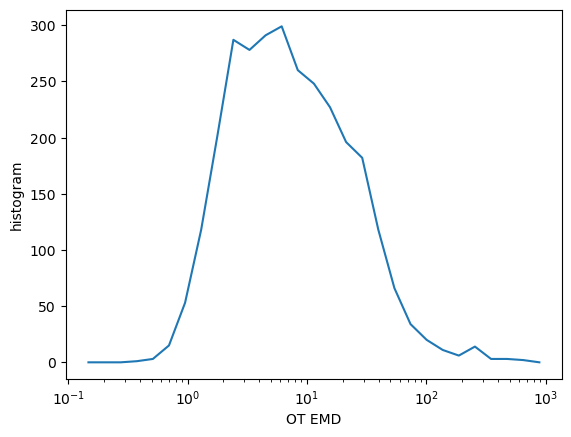

In [141]:
# Re-track every good model with the optimal-transport (OT) linking cost and plot the histogram of costs.
# Slow. Writes the new lineage and costs into each .h5 file (save_h5=True, overwrite=True), so it only needs to run once per dataset.
#review histogram of OT EMD costs to choose cutoff  #only run this for death validation
ot_costs=[[np.inf]]*(np.max(indgood_models)+1)
linSets=[None]*(np.max(indgood_models)+1)
for i in indgood_models[0:]:
    print(f're-tracking {modelSet[i].h5filename}')
    sctm=modelSet[i]
    # distcut = maximum linking distance (half a cell diameter); ot_cost_cut=inf keeps every link so the full cost distribution can be inspected
    #ot_costs[i],linSets[i]=sctm.get_lineage_min_otcost(distcut=0.5*sctm.cellpose_diam,return_cost=True,ot_cost_cut=np.inf,border_resolution=1.33,visual=False,save_h5=True,overwrite=True)
    ot_costs[i]=sctm.ot_tracking_costs.copy()
    linSets[i]=sctm.linSet.copy()

# histogram of all finite link costs on log-spaced bins
ot_costs_all=np.concatenate(ot_costs)
ot_hist,bins=np.histogram(ot_costs_all[np.isfinite(ot_costs_all)],bins=np.logspace(-3,10,num=30,base=2))
plt.plot(.5*bins[0:-1]+.5*bins[1:],ot_hist)
plt.xscale('log')
plt.ylabel('histogram')
plt.xlabel('OT EMD')

**Break tracks above the OT cutoff.** Any link with cost above `ot_cut` is removed, so that the two cells it connected become separate tracks.

In [142]:
# Break every track link whose OT cost is above ot_cut (chosen from the histogram above)
#break tracks based upon optimal transport EMD metric
ot_cut=4.0
for i in indgood_models:
    sctm=modelSet[i]
    inds_break=np.where(sctm.ot_tracking_costs>ot_cut)[0]
    print(f'breaking {inds_break.size} tracks from {modelSet[i].h5filename}')
    for ic in inds_break:
        iS=sctm.cells_frameSet[ic]
        # -1 = no parent, so this cell starts a new track
        sctm.linSet[iS][sctm.cells_indSet[ic]]=-1

breaking 833 tracks from dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
breaking 819 tracks from dataset/20240703_OS17lungInh_RM_xy8_roi0.h5
breaking 921 tracks from dataset/20240703_OS17lungInh_RM_xy9_roi0.h5


**Cell trajectories.** Rebuilds the unique trajectories from the curated tracks (`all_trajSet`). The later embedding sections reset each model's `trajectories` from this list.

In [143]:
# Rebuild the unique cell trajectories from the curated links. all_trajSet keeps a copy per model
# (the embedding sections reset modelSet[i].trajectories from it).
#Map all trajectories
all_trajSet=[None]*nmodels
for i in indgood_models:
    print(f'tracing trajectories for {modelSet[i].h5filename}')
    modelSet[i].get_unique_trajectories()
    all_trajSet[i]=modelSet[i].trajectories.copy()

tracing trajectories for dataset/20240629_OS17lungInh_RM_xy8_roi0.h5
tracked cell 920, 1 tracks, 900 left
tracked cell 805, 1 tracks, 800 left
tracked cell 617, 1 tracks, 600 left
tracked cell 504, 1 tracks, 500 left
tracked cell 404, 1 tracks, 400 left
tracked cell 325, 3 tracks, 300 left
tracked cell 200, 1 tracks, 200 left
tracked cell 102, 1 tracks, 100 left
tracked cell 0, 1 tracks, 0 left
tracing trajectories for dataset/20240703_OS17lungInh_RM_xy8_roi0.h5
tracked cell 1115, 1 tracks, 1100 left
tracked cell 1002, 1 tracks, 1000 left
tracked cell 945, 1 tracks, 900 left
tracked cell 613, 1 tracks, 600 left
tracked cell 501, 1 tracks, 500 left
tracked cell 341, 3 tracks, 300 left
tracked cell 240, 1 tracks, 200 left
tracked cell 121, 1 tracks, 100 left
tracked cell 0, 1 tracks, 0 left
tracing trajectories for dataset/20240703_OS17lungInh_RM_xy9_roi0.h5
tracked cell 1213, 1 tracks, 1200 left
tracked cell 917, 1 tracks, 900 left
tracked cell 813, 1 tracks, 800 left
tracked cell 644, 

### A.4 Manual validation of death calls

**Manual validation of death calls.** For the cells that last appear before the end of imaging, shows image montages around the last frames and records, for each, whether the cell died, using `manual_fate_validation`. The validated calls are saved to the `.h5` file. This step needs only the `.h5` files, but it is interactive, so it is disabled unless `RUN_MANUAL_DEATH_VALIDATION=True`. The model to validate is hard-coded (`for iimodel in [2]`).

In [144]:
# Interactive death-call validation (only with RUN_MANUAL_DEATH_VALIDATION=True). Candidates are the last cells of tracks longer than
# min_traj_len that end before the final frame and are larger than one cell diameter squared; for each, image montages around the
# end of the track are shown and the user records whether the cell died. Results are saved to the .h5 file.
if RUN_MANUAL_DEATH_VALIDATION:
    trajl_future=4
    trajl_past=1
    # frame window for candidates (uses `sctm` from the last cell that set it)
    fu=np.max(sctm.cells_frameSet-trajl_future)
    fl=trajl_past
    min_traj_len=2
    stride=2
    min_size=sctm.cellpose_diam*sctm.cellpose_diam
    indmodels=indgood_models.copy()
    indmodels=np.intersect1d(indmodels,indgood_models)
    vals_death_set=[None]*indmodels.size
    inds_death_set=[None]*indmodels.size
    # model to validate (index into indmodels); use range(indmodels.size) for all models
    for iimodel in [2]: #range(indmodels.size):
        imodel=indmodels[iimodel]
        sctm_fate=modelSet[imodel]
        inds_last=np.array([]).astype(int)
        for itraj in range(len(sctm_fate.trajectories)):
            ic_last=sctm_fate.trajectories[itraj][-1]
            if sctm_fate.cells_frameSet[ic_last] != np.max(sctm_fate.cells_frameSet) and sctm_fate.trajectories[itraj].size>min_traj_len:
                imgc_test,mskc_relabeled=sctm_fate.get_cell_data(ic_last,relabel_mskchannels=[cyto_msk_channel])
                size=np.sum(mskc_relabeled[...,cyto_msk_channel]==ic_last)
                print(f'cell {ic_last} size {size}, {itraj}/{len(sctm_fate.trajectories)}')
                if size>min_size:
                    inds_last=np.append(inds_last,ic_last)
        indstw=np.where(np.logical_and(sctm_fate.cells_frameSet[inds_last]<fu,sctm_fate.cells_frameSet[inds_last]>fl))[0]
        inds_last=inds_last[indstw]
        print(inds_last)
        print(sctm_fate.cells_frameSet[inds_last])
        deathval_dir=f'./{date}/death_val_m{imodel}/'
        os.system(f'mkdir {deathval_dir}')
        # bf_channel is set to the ERK channel here
        vals_death_set[iimodel],inds_death_set[iimodel]=sctm_fate.manual_fate_validation(inds_last,'death',restart=False,val_tracks=False,trajl_past=trajl_past,trajl_future=trajl_future,stride=stride,rep_channel=erk_img_channel,bf_channel=erk_img_channel,nuc_channel=nuc_img_channel,projection=True,msk_channel=cyto_msk_channel,pathto=deathval_dir,save_pic=True,boundary_expansion=[3,70,70],nuclow=90,save_h5=True,overwrite=True)